# Historical Rainfall across Singapore, 2017–2024: weather patterns and 30-minute rainfall prediction with Apache Spark

**DSA5208 Scalable Distributed Computing, Project 2**

| Name | Student ID |
|---|---|
| Aditya Vijindra Pandhari | A0328872R |
| Apurwa Kumari | A0333260R |
| Vanshika Dhamija | A0333989H |

This single notebook is the complete project, from reading the raw CSV files to saving the trained model.
The cells retain their outputs and run in the order below.

| Part | Section | What happens | Spark output |
|---|---|---|---|
| **A. Data engineering** | 0. Setup | configuration, Spark session, plotting style | |
| | 1. Ingestion | 8 annual CSVs (7.5 GB) read with an explicit schema | `data_parquet/bronze/` (typed raw copy) |
| | 2. Data-quality audit | profile of the raw records: nulls, ranges, duplicates, timestamps | `t00_raw_profile` |
| | 3. Cleaning | timestamp alignment, de-duplication, range check, faulty gauges | `data_parquet/silver/` (clean readings) |
| | 4. Pre-processing | station-days, completeness rules, island-wide daily series, window features | analysis tables |
| **B. Task 1** | 5. Weather patterns | within-year and across-year patterns, 10 figures, robustness and trend tests | `t02`–`t24`, `t39`, `fig01`–`fig10` |
| **C. Task 2** | 6. Problem definition | target, inputs, timestamp convention, chronological split | |
| | 7. Feature engineering | trailing rain, neighbouring gauges, calendar; leakage check | `data_parquet/gold/task2_features/` |
| | 8. Training and evaluation sets | threshold as an input, label-independent hash sampling | `data_parquet/gold/task2_sets/` |
| | 9. Baseline models | climatology and base rate, scored on 2023 | |
| | 10. Stage 1 models | interpretable logistic regressions (and GBTs), selected on 2023 | `models/task2_baseline_lr/` |
| | 11. Stage 1 evaluation | Stage 1 model vs baselines on the 2024 test year | `t25`–`t38`, `fig11`–`fig15` |
| | 12. Stage 2 features | richer features (time since rain, storm trend, neighbour rings, island-wide rain); leakage check | `data_parquet/gold/task2_final/` |
| | 13. Feature selection | correlation, MLlib ANOVA ranking, selector size tuned in cross-validation | `fig16` |
| | 14. Cross-validation | year-blocked 4-fold CV and tuning of LR, random forest and GBT; the final model | `t2_cv_results`, `fig17` |
| | 15. Ablation, calibration | feature-group ablation; calibrator kept only if it helps on held-out data | `fig18` |
| | 16. Final evaluation | final model vs baselines on every 2024 row | `t2_test_metrics`, `fig19`–`fig21` |
| | 17. Head-to-head | final model vs the Stage 1 model on identical 2024 rows | `t41`, `fig22` |
| | 18. Using the model | saved final `PipelineModel` and a `predict(station, time, threshold)` function | `models/task2_final_rf/` |
| | 19. Summary | results, timings, computing environment | `t00_environment`, `t40_stage_timings` |
| | 20. Scalability | strong and weak scaling of the same Spark job on 2–16 cores with an Amdahl's-law fit; laptop vs Dataproc | `t42`, `t45`, `t47`, `t44`, `fig23`, `fig24` |

To run the notebook, put the eight annual files from <https://data.gov.sg/collections/2279/view> in `data/` and
create the conda environment in `environment.yml`. Open the notebook with that environment's kernel and run all
cells. This takes about 80 minutes on the 16-core machine in Section 19 with `CV_PARALLELISM=4`;
cross-validation in Section 14 accounts for about 37 minutes. On a 16 GB laptop with `CV_PARALLELISM=2`,
cross-validation alone takes a few hours. Keep the machine awake and plugged in, for example with
`caffeinate -is` on macOS.

For a headless run, use
`jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.timeout=-1 DSA5208_Project2.ipynb`.
Tables are saved to `outputs/tables/` and figures to `outputs/figures/` as 300 dpi PNGs, with one PDF per task
for use in the report.

---
# Part A: Data engineering

## 0. Setup

We define the paths, start the Spark session and set the plotting and logging conventions. The logging helpers report each
step's purpose and outputs (`section`), timestamped progress (`step`), computed results (`checkpoint`), model
scores (`result_box`) and elapsed time (`timed`).

Spark runs in local mode on one machine. Changing the master lets the same code run on a cluster.

In [1]:
import itertools
import json
import math
import os
import platform
import shutil
import subprocess
import sys
import time
import warnings
from contextlib import contextmanager
from datetime import datetime
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle

# ---- paths ---------------------------------------------------------------
ROOT = Path.cwd()
DATA_RAW = ROOT / "data"                    # the eight annual CSVs (not in git)
DATA_PARQUET = ROOT / "data_parquet"        # Spark data layers (not in git)
BRONZE = DATA_PARQUET / "bronze"            # typed, unmodified copy of the CSVs
SILVER = DATA_PARQUET / "silver"            # cleaned readings + station table
GOLD = DATA_PARQUET / "gold"                # Task 2 feature table and model sets
OUT = ROOT / "outputs"
TABLES = OUT / "tables"
FIGURES = OUT / "figures"
MODEL_DIR = ROOT / "models" / "task2_baseline_lr"           # Stage 1 logistic model (baseline)
FINAL_MODEL_DIR = ROOT / "models" / "task2_final_rf"       # Stage 2 final model (chosen by cross-validation)
for p in (TABLES, FIGURES, MODEL_DIR.parent):
    p.mkdir(parents=True, exist_ok=True)

YEARS = list(range(2017, 2025))
EXPECTED_INTERVALS_PER_DAY = 288            # 5-minute slots per day
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
warnings.filterwarnings("ignore", message=".*Arrow optimization.*")   # harmless pandas-3 fallback notice

In [2]:
# PySpark 3.5 needs Java 17: use the JDK bundled with the conda environment if JAVA_HOME is unset
if "JAVA_HOME" not in os.environ:
    for cand in (Path(sys.prefix) / "lib" / "jvm", Path("/opt/homebrew/opt/openjdk@17")):
        if (cand / "bin" / "java").exists():
            os.environ["JAVA_HOME"] = str(cand)
            break
os.environ.setdefault("PYSPARK_PYTHON", sys.executable)   # workers use the notebook's interpreter

import pyspark.sql.functions as F
from pyspark import StorageLevel
from pyspark.ml.functions import vector_to_array
from pyspark.sql import SparkSession
from pyspark.sql.types import DoubleType, StringType, StructField, StructType
from pyspark.sql.window import Window

SPARK_MASTER = f"local[{os.environ.get('SPARK_LOCAL_CORES', '*')}]"
# keep Spark's own console log to errors so cell outputs show results, not JVM start-up warnings
LOG4J = Path(os.environ.get("TMPDIR", "/tmp")) / "dsa5208_log4j2.properties"
LOG4J.write_text("rootLogger.level = error\nrootLogger.appenderRef.console.ref = console\n"
                 "appender.console.type = Console\nappender.console.name = console\n"
                 "appender.console.target = SYSTEM_ERR\nappender.console.layout.type = PatternLayout\n"
                 "appender.console.layout.pattern = %d{yy/MM/dd HH:mm:ss} %p %c{1}: %m%n%ex\n")
spark = (
    SparkSession.builder.appName("dsa5208-rainfall")
    .master(SPARK_MASTER)
    .config("spark.driver.memory", os.environ.get("SPARK_DRIVER_MEMORY", "12g"))
    .config("spark.driver.bindAddress", "127.0.0.1")   # a Wi-Fi change or sleep/wake cannot break block transfers
    .config("spark.driver.host", "127.0.0.1")
    .config("spark.driver.extraJavaOptions", f"-Dlog4j2.configurationFile={LOG4J.as_uri()}")
    .config("spark.sql.session.timeZone", "Asia/Singapore")       # every timestamp is SGT
    .config("spark.sql.shuffle.partitions", "96")
    .config("spark.sql.parquet.compression.codec", "snappy")
    .config("spark.sql.execution.arrow.pyspark.enabled", "true")
    .config("spark.ui.showConsoleProgress", "false")
    .config("spark.local.dir", os.environ.get("SPARK_LOCAL_DIR", "/tmp/spark-tmp"))
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
print(f"Spark {spark.version}  master={SPARK_MASTER}  default parallelism={spark.sparkContext.defaultParallelism}")

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


Spark 3.5.5  master=local[14]  default parallelism=14


In [3]:
TIMINGS = []


def now():
    return datetime.now().strftime("%H:%M:%S")


def section(title, purpose=None, writes=None):
    """Printed banner at the top of a step: what it does, why, and what it produces."""
    print("=" * 96)
    print(f"{now()}  {title}")
    print("=" * 96)
    if purpose:
        print(f"Purpose : {purpose}")
    if writes:
        print(f"Writes  : {writes}")


def step(msg):
    """One timestamped progress line."""
    print(f"[{now()}]  {msg}")


def checkpoint(title, items):
    """The key numbers of a step, computed from the data (the markdown observations quote these)."""
    print(f"\n-- {title} " + "-" * max(2, 92 - len(title)))
    width = max(len(k) for k, _ in items)
    for k, v in items:
        print(f"   {k:<{width}} : {v}")
    print()


def result_box(name, items):
    """One model's scores in a fixed layout, so models can be compared at a glance."""
    print("-" * 72)
    print(f"  {name}")
    print("-" * 72)
    width = max(len(k) for k, _ in items)
    for k, v in items:
        print(f"  {k:<{width}} : {v}")
    print("-" * 72)


@contextmanager
def timed(stage):
    """Time one pipeline stage; the table of all stages is saved in Section 19."""
    t0 = time.time()
    yield
    TIMINGS.append({"stage": stage, "seconds": round(time.time() - t0, 1)})
    print(f"[{now()}]  done: {stage}  ({time.time() - t0:0.1f} s)")


def write_table(pdf, name):
    """Persist a small pandas frame as outputs/tables/<name>.csv."""
    path = TABLES / f"{name}.csv"
    pdf.to_csv(path, index=False)
    print(f"  [table] {path.relative_to(ROOT)}  ({len(pdf)} rows)")
    return pdf


def T(name):
    """Read a result table back; every figure is drawn from a saved table."""
    return pd.read_csv(TABLES / f"{name}.csv")


def du(path):
    """Size of a file or directory tree in MB."""
    p = Path(path)
    files = [p] if p.is_file() else [f for f in p.rglob("*") if f.is_file()]
    return sum(f.stat().st_size for f in files) / 1e6

In [4]:
# --- 0. Computing environment ----------------------------------------------------------------------
section('0. Computing environment', purpose='record the machine, Spark and library versions the results were produced with', writes='t00_environment')


def _sh(*cmd):
    try:
        r = subprocess.run(cmd, capture_output=True, text=True, timeout=10)
        return (r.stdout or r.stderr).strip().splitlines()[0]
    except Exception:
        return "n/a"


try:
    ram_gb = os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 2**30
except (ValueError, OSError):
    ram_gb = int(_sh("sysctl", "-n", "hw.memsize")) / 2**30
env = pd.DataFrame([
    ("OS", platform.platform()),
    ("CPU", _sh("sysctl", "-n", "machdep.cpu.brand_string") if sys.platform == "darwin" else platform.processor()),
    ("logical cores", os.cpu_count()),
    ("RAM (GB)", round(ram_gb)),
    ("Python", platform.python_version()),
    ("Java", _sh(str(Path(os.environ.get("JAVA_HOME", "")) / "bin" / "java"), "-version")),
    ("Spark", spark.version),
    ("Spark master", SPARK_MASTER),
    ("default parallelism", spark.sparkContext.defaultParallelism),
    ("driver memory", spark.conf.get("spark.driver.memory")),
    ("shuffle partitions", spark.conf.get("spark.sql.shuffle.partitions")),
    ("session time zone", spark.conf.get("spark.sql.session.timeZone")),
    ("pandas / NumPy / Matplotlib", f"{pd.__version__} / {np.__version__} / {mpl.__version__}"),
], columns=["item", "value"])
write_table(env, "t00_environment")
env

07:58:59  0. Computing environment
Purpose : record the machine, Spark and library versions the results were produced with
Writes  : t00_environment


  [table] outputs/tables/t00_environment.csv  (13 rows)


,item,value
0,OS,macOS-26.6.2-arm64-arm-64bit
1,CPU,Apple M4 Max
2,logical cores,16
3,RAM (GB),128
4,Python,3.11.17
5,Java,"openjdk version ""17.0.18"" 2026-01-20 LTS"
6,Spark,3.5.5
7,Spark master,local[14]
8,default parallelism,14
9,driver memory,16g


### 0.1 Plotting style

All figures use the same conventions: a blue scale for magnitude, a red–grey–blue scale for anomalies and a fixed
categorical order for seasons. Titles state the finding; footnotes give the source and QC rule. `save_figure`
saves a 300 dpi PNG, adds the figure to the task's PDF and displays it in the notebook.

In [5]:
SURFACE = "#fcfcfb"


PLANE = "#f9f9f7"


INK = "#0b0b0b"


INK_2 = "#52514e"


MUTED = "#898781"


GRID = "#e1e0d9"


AXIS = "#c3c2b7"


CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN = CAT


RED = "#d03b3b"


BLUE_RAMP = [
    "#cde2fb", "#b7d3f6", "#9ec5f4", "#86b6ef", "#6da7ec", "#5598e7",
    "#3987e5", "#2a78d6", "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b",
]


CMAP_RAIN = LinearSegmentedColormap.from_list("rain_seq", ["#fcfcfb"] + BLUE_RAMP, N=256)


CMAP_ANOM = LinearSegmentedColormap.from_list(
    "anom_div",
    ["#7d1d1d", "#a82c2c", "#d03b3b", "#e28080", "#f0c5c5",
     "#f0efec",
     "#c2daf6", "#86b6ef", "#3987e5", "#256abf", "#104281"],
    N=256,
)


SEASON_ORDER = ["NE Monsoon (Dec-Mar)", "Inter-monsoon (Apr-May)",
                "SW Monsoon (Jun-Sep)", "Inter-monsoon (Oct-Nov)"]


SEASON_COLOR = {
    SEASON_ORDER[0]: BLUE,
    SEASON_ORDER[1]: ORANGE,
    SEASON_ORDER[2]: AQUA,
    SEASON_ORDER[3]: YELLOW,
}


def use_style() -> None:
    """Install the report-wide matplotlib defaults."""
    mpl.rcParams.update({
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "savefig.dpi": 300,
        "figure.dpi": 120,
        "savefig.bbox": "tight",
        "savefig.pad_inches": 0.28,

        "font.family": "sans-serif",
        "font.sans-serif": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"],
        "font.weight": "normal",
        "font.size": 9.5,
        "text.color": INK,

        # recessive chrome: only the axes we need, hairline grid
        "axes.edgecolor": AXIS,
        "axes.linewidth": 0.8,
        "axes.labelcolor": INK_2,
        "axes.labelsize": 9.5,
        "axes.labelpad": 7,
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "axes.titlecolor": INK,
        "axes.titlelocation": "left",
        "axes.titlepad": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,

        "grid.color": GRID,
        "grid.linewidth": 0.7,
        "grid.alpha": 1.0,

        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "xtick.labelcolor": INK_2,
        "ytick.labelcolor": INK_2,
        "xtick.labelsize": 8.5,
        "ytick.labelsize": 8.5,
        "xtick.major.size": 0,
        "ytick.major.size": 0,
        "xtick.major.pad": 5,
        "ytick.major.pad": 5,

        "legend.frameon": False,
        "legend.fontsize": 8.5,
        "legend.labelcolor": INK_2,
        "legend.handlelength": 1.5,
        "legend.handletextpad": 0.6,
        "legend.columnspacing": 1.4,

        "lines.linewidth": 2.0,
        "lines.solid_capstyle": "round",
        "lines.markersize": 4.5,

        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    })


def layout(fig, header: float = 1.55, footer: float = 0.60,
           left: float = 0.95, right: float = 0.32) -> None:
    """Reserve a header band and a footer band, measured in INCHES.

    Figure-fraction margins break as soon as the figure size changes; inches do
    not. Every figure calls this once, after its axes exist, so that the title
    block and the source note always have room that the axes cannot invade.
    """
    w, h = fig.get_figwidth(), fig.get_figheight()
    fig.subplots_adjust(top=1 - header / h, bottom=footer / h,
                        left=left / w, right=1 - right / w)


def titleblock(fig, title: str, subtitle: str = "", *,
               title_size: float = 15.0) -> None:
    """Left-aligned title + deck, positioned in the header band reserved by
    layout(). Offsets are in inches so they hold at any figure size."""
    w, h = fig.get_figwidth(), fig.get_figheight()
    x = 0.42 / w
    fig.text(x, 1 - 0.40 / h, title, ha="left", va="baseline",
             fontsize=title_size, fontweight="bold", color=INK)
    if subtitle:
        fig.text(x, 1 - 0.56 / h, subtitle, ha="left", va="top", fontsize=9.3,
                 color=INK_2, linespacing=1.5)


def sourcenote(fig, text: str) -> None:
    """Provenance line, muted, pinned to the foot of the figure."""
    w, h = fig.get_figwidth(), fig.get_figheight()
    fig.text(0.42 / w, 0.10 / h, text, ha="left", va="bottom", fontsize=7.6,
             color=MUTED, linespacing=1.55)


def despine(ax, left: bool = False, bottom: bool = False) -> None:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(not left)
    ax.spines["bottom"].set_visible(not bottom)


_PDF = None        # open PdfPages, set by open_pdf()


def open_pdf(path: Path, title: str = "", subject: str = "") -> None:
    """Start collecting every subsequent save() into one multi-page PDF.

    Individual PNGs are still written per figure; the vector copies are
    gathered into a single document rather than scattered across one file
    per figure.
    """
    global _PDF
    from matplotlib.backends.backend_pdf import PdfPages

    path.parent.mkdir(parents=True, exist_ok=True)
    _PDF = PdfPages(str(path))
    meta = _PDF.infodict()
    if title:
        meta["Title"] = title
    if subject:
        meta["Subject"] = subject


def close_pdf() -> Path | None:
    """Finalise the multi-page PDF and report where it landed."""
    global _PDF
    if _PDF is None:
        return None
    path = Path(_PDF._file.fh.name) if hasattr(_PDF, "_file") else None
    _PDF.close()
    _PDF = None
    return path


def save_figure(fig, path):
    """Write the figure as a 300 dpi PNG, add it to the open PDF, and show it in the notebook."""
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path)
    if _PDF is not None:
        _PDF.savefig(fig, bbox_inches="tight", pad_inches=0.28)
    display(fig)
    plt.close(fig)
    print(f"  [figure] {path.relative_to(ROOT)}")


use_style()
import logging
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)   # font-fallback notices
mpl.rcParams["figure.dpi"] = 90          # on-screen size only; saved PNGs use savefig.dpi = 300

## 1. Data ingestion: raw CSV → bronze Parquet

The data.gov.sg collection *Historical Rainfall across Singapore* contains one CSV per year, with one row per
station per 5-minute reading. The eight files for 2017–2024 total about 7.5 GB and 48.5 M rows.

We declare the 12 column types rather than making an inference pass over 7.5 GB. The bronze layer retains the
raw rows, with types assigned and timestamps parsed, in Parquet partitioned by year. Later steps read this
columnar copy instead of parsing the CSVs again; the bronze data remain available for the audit.

data.gov.sg has distributed the files under two names. The ingestion code accepts either.

In [6]:
# --- 1. Ingestion: locate the eight raw CSV files --------------------------------------------------
section('1. Ingestion: locate the eight raw CSV files', purpose='one file per year 2017-2024; either data.gov.sg file name is accepted')
RAW_NAMES = ["Historical Rainfall across Singapore ({y}).csv",
             "HistoricalRainfallacrossSingapore{y}.csv"]


def raw_file(year):
    for pattern in RAW_NAMES:
        path = DATA_RAW / pattern.format(y=year)
        if path.exists():
            return path
    raise FileNotFoundError(f"no raw file for {year} in {DATA_RAW}; expected one of {RAW_NAMES}")


raw_files = {y: raw_file(y) for y in YEARS}
display(pd.DataFrame({"year": YEARS, "file": [p.name for p in raw_files.values()],
                      "size_MB": [round(p.stat().st_size / 1e6) for p in raw_files.values()]}))
print(f"total {sum(p.stat().st_size for p in raw_files.values()) / 1e9:.2f} GB")

07:58:59  1. Ingestion: locate the eight raw CSV files
Purpose : one file per year 2017-2024; either data.gov.sg file name is accepted


,year,file,size_MB
0,2017,HistoricalRainfallacrossSingapore2017.csv,881
1,2018,HistoricalRainfallacrossSingapore2018.csv,770
2,2019,HistoricalRainfallacrossSingapore2019.csv,843
3,2020,HistoricalRainfallacrossSingapore2020.csv,1049
4,2021,HistoricalRainfallacrossSingapore2021.csv,1159
5,2022,HistoricalRainfallacrossSingapore2022.csv,1173
6,2023,HistoricalRainfallacrossSingapore2023.csv,1107
7,2024,HistoricalRainfallacrossSingapore2024.csv,1066


total 8.05 GB


In [7]:
# --- 1. Ingestion: explicit 12-column schema (no inference pass over 7.5 GB) -----------------------
RAW_SCHEMA = StructType([
    StructField("date", StringType()),
    StructField("timestamp", StringType()),
    StructField("update_timestamp", StringType()),
    StructField("station_id", StringType()),
    StructField("station_name", StringType()),
    StructField("station_device_id", StringType()),
    StructField("location_longitude", DoubleType()),
    StructField("location_latitude", DoubleType()),
    StructField("reading_update_timestamp", StringType()),
    StructField("reading_value", DoubleType()),
    StructField("reading_type", StringType()),
    StructField("reading_unit", StringType()),
])

raw = (spark.read.option("header", True).option("mode", "PERMISSIVE")
       .schema(RAW_SCHEMA).csv([str(p) for p in raw_files.values()]))
raw.limit(5).toPandas()

,date,timestamp,update_timestamp,station_id,station_name,station_device_id,location_longitude,location_latitude,reading_update_timestamp,reading_value,reading_type,reading_unit
0,2017-01-01,2017-01-01T08:04:59+08:00,2017-01-01T08:13:31+08:00,S77,Alexandra Road,S77,103.8125,1.2937,2017-01-01T08:13:31+08:00,0.0,TB1 Rainfall 5 Minute Total F,mm
1,2017-01-01,2017-01-01T08:04:59+08:00,2017-01-01T08:13:31+08:00,S109,Ang Mo Kio Avenue 5,S109,103.8492,1.3764,2017-01-01T08:13:31+08:00,0.0,TB1 Rainfall 5 Minute Total F,mm
2,2017-01-01,2017-01-01T08:04:59+08:00,2017-01-01T08:13:31+08:00,S117,Banyan Road,S117,103.6790,1.2560,2017-01-01T08:13:31+08:00,0.0,TB1 Rainfall 5 Minute Total F,mm
3,2017-01-01,2017-01-01T08:04:59+08:00,2017-01-01T08:13:31+08:00,S55,Buangkok Green,S55,103.8860,1.3837,2017-01-01T08:13:31+08:00,0.0,TB1 Rainfall 5 Minute Total F,mm
4,2017-01-01,2017-01-01T08:04:59+08:00,2017-01-01T08:13:31+08:00,S64,Bukit Panjang Road,S64,103.7603,1.3824,2017-01-01T08:13:31+08:00,0.0,TB1 Rainfall 5 Minute Total F,mm


In [8]:
# --- 1. Ingestion: CSV -> bronze Parquet -----------------------------------------------------------
section('1. Ingestion: CSV -> bronze Parquet', purpose='parse the CSVs once; keep a typed, unmodified copy partitioned by year', writes='data_parquet/bronze/')
bronze_df = raw.select(
    "station_id", "station_name", "station_device_id",
    F.col("location_longitude").alias("lon"),
    F.col("location_latitude").alias("lat"),
    F.to_timestamp("timestamp").alias("ts_raw"),                 # ISO 8601 with +08:00 offset
    F.to_timestamp("update_timestamp").alias("update_ts"),
    F.to_timestamp("reading_update_timestamp").alias("upd"),
    F.col("reading_value").alias("rain_mm"),
    "reading_type", "reading_unit",
    F.col("date").alias("date_str"),
).withColumn("year", F.year("ts_raw"))

with timed("1. ingest: CSV -> bronze Parquet"):
    bronze_df.write.mode("overwrite").partitionBy("year").parquet(str(BRONZE))
bronze = spark.read.parquet(str(BRONZE))
csv_mb = sum(p.stat().st_size for p in raw_files.values()) / 1e6
n_bronze = bronze.count()
checkpoint("1. Bronze layer", [("rows", f"{n_bronze:,}"), ("years", f"{YEARS[0]}-{YEARS[-1]} ({len(YEARS)} partitions)"),
                               ("CSV size", f"{csv_mb:,.0f} MB"), ("Parquet size", f"{du(BRONZE):,.0f} MB"),
                               ("compression", f"{csv_mb / du(BRONZE):.0f}x (columnar + snappy; the CSVs are never parsed again)")])
bronze.printSchema()

07:59:01  1. Ingestion: CSV -> bronze Parquet
Purpose : parse the CSVs once; keep a typed, unmodified copy partitioned by year
Writes  : data_parquet/bronze/


[07:59:18]  done: 1. ingest: CSV -> bronze Parquet  (17.0 s)



-- 1. Bronze layer -----------------------------------------------------------------------------
   rows         : 48,538,713
   years        : 2017-2024 (8 partitions)
   CSV size     : 8,047 MB
   Parquet size : 51 MB
   compression  : 157x (columnar + snappy; the CSVs are never parsed again)

root
 |-- station_id: string (nullable = true)
 |-- station_name: string (nullable = true)
 |-- station_device_id: string (nullable = true)
 |-- lon: double (nullable = true)
 |-- lat: double (nullable = true)
 |-- ts_raw: timestamp (nullable = true)
 |-- update_ts: timestamp (nullable = true)
 |-- upd: timestamp (nullable = true)
 |-- rain_mm: double (nullable = true)
 |-- reading_type: string (nullable = true)
 |-- reading_unit: string (nullable = true)
 |-- date_str: string (nullable = true)
 |-- year: integer (nullable = true)



## 2. Data-quality audit (bronze)

We check the raw records for missing or impossible values, duplicate station-slots and timestamps off the
5-minute grid. We also compare reading timestamps with publication times to inform the timestamp convention
used in Task 2.

In [9]:
# --- 2. Data-quality audit of the bronze layer -----------------------------------------------------
section('2. Data-quality audit of the bronze layer', purpose='nulls, impossible values, duplicate station-slots, the timestamp grid, stations', writes='t00_raw_profile')
on_grid = (F.second("ts_raw") == 0) & (F.minute("ts_raw") % 5 == 0)
slot = (F.round(F.unix_timestamp("ts_raw") / 300) * 300).cast("long")
with timed("2. data-quality audit"):
    prof = bronze.agg(
        F.count(F.lit(1)).alias("rows"),
        F.sum(F.col("ts_raw").isNull().cast("long")).alias("unparseable_timestamp"),
        F.sum(F.col("station_id").isNull().cast("long")).alias("null_station_id"),
        F.sum(F.col("rain_mm").isNull().cast("long")).alias("null_reading"),
        F.sum((F.col("rain_mm") < 0).cast("long")).alias("negative_reading"),
        F.sum((F.col("rain_mm") > 30).cast("long")).alias("reading_gt_30mm_per_5min"),
        F.max("rain_mm").alias("max_reading_mm"),
        F.countDistinct("reading_type").alias("distinct_reading_type"),
        F.countDistinct("reading_unit").alias("distinct_reading_unit"),
        F.sum((F.col("station_id") != F.col("station_device_id")).cast("long")).alias("station_id_ne_device_id"),
        F.sum((~on_grid).cast("long")).alias("off_5min_grid_timestamp"),
        F.countDistinct("station_id").alias("distinct_stations"),
    ).toPandas().T.rename(columns={0: "value"})
    dup = (bronze.groupBy("station_id", slot.alias("slot")).count()
           .agg(F.sum(F.when(F.col("count") > 1, F.col("count") - 1)).alias("n")).first()["n"])
    prof.loc["duplicate_station_slot_after_rounding"] = dup or 0
write_table(prof.reset_index().rename(columns={"index": "check"}), "t00_raw_profile")
pv = prof["value"]
checkpoint("2. Raw profile", [
    ("rows", f"{pv['rows']:,.0f}"),
    ("unparseable timestamp / null station / null reading", f"{pv['unparseable_timestamp']:.0f} / {pv['null_station_id']:.0f} / {pv['null_reading']:.0f}"),
    ("negative readings", f"{pv['negative_reading']:.0f}"),
    ("readings > 30 mm per 5 min", f"{pv['reading_gt_30mm_per_5min']:.0f} (maximum {pv['max_reading_mm']} mm)"),
    ("reading types / units", f"{pv['distinct_reading_type']:.0f} / {pv['distinct_reading_unit']:.0f}"),
    ("timestamps off the 5-min grid", f"{pv['off_5min_grid_timestamp']:,.0f}"),
    ("duplicate station-slots after rounding", f"{pv['duplicate_station_slot_after_rounding']:,.0f}"),
    ("distinct stations", f"{pv['distinct_stations']:.0f}")])
prof

07:59:18  2. Data-quality audit of the bronze layer
Purpose : nulls, impossible values, duplicate station-slots, the timestamp grid, stations
Writes  : t00_raw_profile


[07:59:24]  done: 2. data-quality audit  (6.2 s)
  [table] outputs/tables/t00_raw_profile.csv  (13 rows)

-- 2. Raw profile ------------------------------------------------------------------------------
   rows                                                : 48,538,713
   unparseable timestamp / null station / null reading : 0 / 0 / 0
   negative readings                                   : 0
   readings > 30 mm per 5 min                          : 1 (maximum 37.2 mm)
   reading types / units                               : 1 / 1
   timestamps off the 5-min grid                       : 1,775,327
   duplicate station-slots after rounding              : 86
   distinct stations                                   : 91



,value
rows,48538713.0
unparseable_timestamp,0.0
null_station_id,0.0
null_reading,0.0
negative_reading,0.0
reading_gt_30mm_per_5min,1.0
max_reading_mm,37.2
distinct_reading_type,1.0
distinct_reading_unit,1.0
station_id_ne_device_id,0.0


In [10]:
# --- 2. Audit per year: rows, stations, timestamp grid, publication delay --------------------------
section('2. Audit per year: rows, stations, timestamp grid, publication delay', purpose='the publication delay decides what a timestamp means (Section 4.3)')
lag = (F.unix_timestamp("upd") - F.unix_timestamp("ts_raw"))
per_year = (bronze.groupBy("year").agg(
    F.count(F.lit(1)).alias("rows"),
    F.countDistinct("station_id").alias("stations"),
    F.sum((~on_grid).cast("long")).alias("off_grid_timestamps"),
    F.min(lag).alias("publish_lag_min_s"),
    F.expr("percentile_approx(unix_timestamp(upd) - unix_timestamp(ts_raw), 0.5)").alias("publish_lag_median_s"),
).orderBy("year").toPandas())
checkpoint("2. Per-year audit", [
    ("stations reporting per year", f"{per_year.stations.min()}-{per_year.stations.max()}"),
    ("off-grid timestamps", f"{per_year.off_grid_timestamps.sum():,} (years: {', '.join(str(y) for y in per_year[per_year.off_grid_timestamps > 0].year)})"),
    ("publication delay, minimum per year", f"{per_year.publish_lag_min_s.min() / 60:.0f}-{per_year.publish_lag_min_s.max() / 60:.0f} min"),
    ("publication delay, median per year", f"{per_year.publish_lag_median_s.min() / 60:.1f}-{per_year.publish_lag_median_s.max() / 60:.1f} min")])
per_year

07:59:24  2. Audit per year: rows, stations, timestamp grid, publication delay
Purpose : the publication delay decides what a timestamp means (Section 4.3)



-- 2. Per-year audit ---------------------------------------------------------------------------
   stations reporting per year         : 54-80
   off-grid timestamps                 : 1,775,327 (years: 2017)
   publication delay, minimum per year : 2-5 min
   publication delay, median per year  : 5.5-10.0 min



,year,rows,stations,off_grid_timestamps,publish_lag_min_s,publish_lag_median_s
0,2017,5256106,62,1775327,204,478
1,2018,4594246,56,0,122,439
2,2019,5026862,54,0,139,457
3,2020,6334473,80,0,262,601
4,2021,7044646,76,0,316,577
5,2022,7133230,72,0,266,575
6,2023,6742890,74,0,263,565
7,2024,6406260,70,0,320,333


The audit found no nulls or negative readings, and only one reading type (`TB1 Rainfall 5 Minute Total F`) in
one unit (mm). Of 48.5 M readings, just one exceeds 30 mm in 5 minutes: a 37.2 mm reading, which we treat as an
instrument fault.

The timestamp grid needs correction. All 1.78 M readings stamped `hh:m4:59` rather than `hh:m5:00` come from
2017, accounting for about a third of that year. Rounding to the nearest 5 minutes aligns them with the other
stations and years and reveals 86 duplicate station-slots. The reporting network also changes, with 54–80
stations per year.

The documentation does not define what a timestamp marks. Median publication delays range from 5.5–10 minutes
across years, with the fastest readings arriving after 2–5 minutes. These delays suggest that the stamp marks the
start of the 5-minute interval. Task 2 adopts this conservative convention and discusses its limits in Section 4.3.

## 3. Cleaning: bronze → silver

| Rule | What | Why |
|---|---|---|
| 1 | keep only the `TB1 Rainfall 5 Minute Total F` reading type | one measurement, one unit |
| 2 | **snap timestamps** to the nearest 5-minute grid point | the 2017 export is offset by a second and drifts |
| 3 | **de-duplicate** each station-slot, keeping the most recently updated reading | re-published records |
| 4 | **range check**: keep 0 ≤ reading ≤ 30 mm per 5 minutes | the one 37.2 mm fault |
| 5 | **station table**: the most frequent (modal) coordinate per station | coordinates vary slightly across years |
| 6 | **dead gauges**: drop a station-month whose rain rate is below 10 % of the network median in a month where that median is ≥ 50 mm | a broken gauge reports 0.0, e.g. S24B through January 2017 |
| 7 | **spike days**: drop a station-day of ≥ 100 mm that exceeds 4× the wettest gauge within 5 km (≥ 2 reporting) | faults that report too much rain, e.g. S107 with ~750 mm on 2022-08-21 |

We leave missing slots as unknown rather than filling them with zeros. Section 4 defines the completeness rules
used in later analyses.

For de-duplication, `max()` over an `(update time, value)` struct selects the latest reading in one shuffle,
instead of sorting a window over 48 M rows. We cache this table because the later cleaning rules, station table,
fact table and audit all use it.

In [11]:
# --- 3a. Cleaning rules 1-5: reading type, timestamp snap, de-duplication, range check, station table ---
section('3a. Cleaning rules 1-5: reading type, timestamp snap, de-duplication, range check, station table', purpose='one shuffle picks the latest reading per station-slot; the de-duplicated table is cached for every later rule')
READING_TYPE = "TB1 Rainfall 5 Minute Total F"
PLAUSIBLE_MAX_5MIN = 30.0      # mm per 5 minutes; only one of 48.5 M readings exceeds it (Section 2)
DEAD_FRAC, DEAD_MIN_NET_MM = 0.10, 50.0
SPIKE_MIN_DAY_MM, SPIKE_RATIO, SPIKE_NEIGHBOUR_KM = 100.0, 4.0, 5.0
SPIKE_MIN_NEIGHBOURS, SPIKE_MIN_SLOTS = 2, 260     # 260 = 90 % of a day's 288 slots

parsed = (
    bronze.filter(F.col("reading_type") == READING_TYPE)
    .select("station_id", "station_name", "lon", "lat",
            F.timestamp_seconds((F.round(F.unix_timestamp("ts_raw") / F.lit(300)) * F.lit(300)).cast("long")).alias("ts"),
            "rain_mm", "upd")
    .withColumn("year", F.year("ts"))
)
audit = parsed.groupBy("year").agg(
    F.count(F.lit(1)).alias("raw_records"),
    F.sum(F.col("ts").isNull().cast("int")).alias("null_timestamp"),
    F.sum(F.col("rain_mm").isNull().cast("int")).alias("null_value"),
    F.sum((F.col("rain_mm") < 0).cast("int")).alias("negative_value"),
    F.sum((F.col("rain_mm") > PLAUSIBLE_MAX_5MIN).cast("int")).alias("implausible_value"),
)
valid = parsed.filter(F.col("ts").isNotNull() & F.col("station_id").isNotNull() & F.col("rain_mm").isNotNull()
                      & (F.col("rain_mm") >= 0) & (F.col("rain_mm") <= PLAUSIBLE_MAX_5MIN))

dedup = (
    valid.groupBy("station_id", "ts")
    .agg(F.max(F.struct(F.col("upd"), F.col("rain_mm"))).alias("pick"),
         F.count(F.lit(1)).alias("n_dupes"),
         F.first("station_name", ignorenulls=True).alias("station_name"),
         F.first("lon", ignorenulls=True).alias("lon"),
         F.first("lat", ignorenulls=True).alias("lat"))
    .select("station_id", "ts", F.col("pick.rain_mm").alias("rain_mm"), "n_dupes", "station_name", "lon", "lat")
    .withColumn("ym", F.date_format("ts", "yyyyMM"))
    .withColumn("date", F.to_date("ts"))
)
dedup.persist(StorageLevel.MEMORY_AND_DISK)
step("physical plan of the de-duplication: one shuffle (Exchange) by (station, slot); max over a struct cannot be hash-aggregated, "
     "so Spark sorts within each partition and uses SortAggregate, but there is no global sort")
dedup.explain(mode="simple")

# station table: modal coordinate per station
coord_counts = dedup.groupBy("station_id", "station_name", "lon", "lat").agg(F.count(F.lit(1)).alias("n"))
w = Window.partitionBy("station_id").orderBy(F.col("n").desc(), F.col("station_name"))
with timed("3a. clean: snap + de-duplicate + station table"):
    stations = (coord_counts.withColumn("rk", F.row_number().over(w)).filter(F.col("rk") == 1)
                .select("station_id", "station_name", "lon", "lat").toPandas())
step(f"station table: {len(stations)} stations, each with its modal coordinate")

07:59:31  3a. Cleaning rules 1-5: reading type, timestamp snap, de-duplication, range check, station table
Purpose : one shuffle picks the latest reading per station-slot; the de-duplicated table is cached for every later rule
[07:59:31]  physical plan of the de-duplication: one shuffle (Exchange) by (station, slot); max over a struct cannot be hash-aggregated, so Spark sorts within each partition and uses SortAggregate, but there is no global sort
== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- InMemoryTableScan [station_id#95, ts#689, rain_mm#755, n_dupes#741L, station_name#743, lon#745, lat#747, ym#764, date#773]
      +- InMemoryRelation [station_id#95, ts#689, rain_mm#755, n_dupes#741L, station_name#743, lon#745, lat#747, ym#764, date#773], StorageLevel(disk, memory, 1 replicas)
            +- AdaptiveSparkPlan isFinalPlan=false
               +- SortAggregate(key=[station_id#95, ts#689], functions=[max(struct(upd, upd#102, rain_mm, rain_mm#103)), count(1), first(statio

[07:59:43]  done: 3a. clean: snap + de-duplicate + station table  (11.3 s)
[07:59:43]  station table: 91 stations, each with its modal coordinate


In [12]:
# --- 3b. Rule 6: dead-gauge station-months ---------------------------------------------------------
section('3b. Rule 6: dead-gauge station-months', purpose='a gauge reporting < 10 % of the network median in a wet month (median >= 50 mm) is broken, not dry', writes='t01a_qc_dead_gauge_months')
# rule 6: dead-gauge station-months
st_m = dedup.groupBy("station_id", "ym").agg(F.avg("rain_mm").alias("st_rate"), F.count(F.lit(1)).alias("slots"),
                                             F.sum("rain_mm").alias("reported_mm"))
net_m = (st_m.filter(F.col("slots") >= 7 * EXPECTED_INTERVALS_PER_DAY)          # stations with >= 1 week of data
         .groupBy("ym").agg(F.percentile_approx("st_rate", 0.5, 100000).alias("net_rate")))
with timed("3b. clean: dead-gauge station-months"):
    dead_pdf = (
        st_m.join(net_m, "ym")
        .filter((F.col("net_rate") * EXPECTED_INTERVALS_PER_DAY * 30 >= DEAD_MIN_NET_MM)
                & (F.col("st_rate") < DEAD_FRAC * F.col("net_rate")))
        .withColumn("network_median_month_mm", F.col("net_rate") * EXPECTED_INTERVALS_PER_DAY * 30)
        .select("station_id", "ym", "slots", "reported_mm", "network_median_month_mm")
        .toPandas().sort_values(["ym", "station_id"])
    )
write_table(dead_pdf, "t01a_qc_dead_gauge_months")
ex0 = dead_pdf.iloc[0] if len(dead_pdf) else None
checkpoint("3b. Dead gauges (rule 6)", [("station-months flagged", len(dead_pdf)),
    ("readings affected", f"{int(dead_pdf.slots.sum()):,}"), ("stations affected", dead_pdf.station_id.nunique()),
    ("example", "none" if ex0 is None else f"{ex0.station_id} in {ex0.ym}: reported {ex0.reported_mm:.1f} mm while the network median was {ex0.network_median_month_mm:.0f} mm")])
dead = spark.createDataFrame(dead_pdf[["station_id", "ym"]].assign(dead=True), "station_id string, ym string, dead boolean")
dead_pdf.head(8)

07:59:43  3b. Rule 6: dead-gauge station-months
Purpose : a gauge reporting < 10 % of the network median in a wet month (median >= 50 mm) is broken, not dry
Writes  : t01a_qc_dead_gauge_months


[07:59:45]  done: 3b. clean: dead-gauge station-months  (2.6 s)
  [table] outputs/tables/t01a_qc_dead_gauge_months.csv  (67 rows)

-- 3b. Dead gauges (rule 6) --------------------------------------------------------------------
   station-months flagged : 67
   readings affected      : 198,544
   stations affected      : 25
   example                : S24B in 201701: reported 0.0 mm while the network median was 236 mm



,station_id,ym,slots,reported_mm,network_median_month_mm
10,S24B,201701,8756,0.0,235.663077
11,S97,201701,6,0.0,235.663077
8,S24B,201702,8003,0.0,164.786274
9,S72,201702,17,0.0,164.786274
7,S89,201702,4990,3.0,164.786274
49,S103,201703,45,0.0,169.954520
50,S24B,201703,8864,0.0,169.954520
48,S72,201703,16,0.0,169.954520


In [13]:
# --- 3c. Rule 7: spike station-days ----------------------------------------------------------------
section('3c. Rule 7: spike station-days', purpose='a day of >= 100 mm that no gauge within 5 km comes within a factor of 4 of is an instrument fault', writes='t01b_qc_spike_days')


def spike_pairs(stations_pdf, max_km: float):
    """(station_id, nb_id) pairs closer than max_km, from static coordinates."""
    ids = stations_pdf["station_id"].tolist()
    lat = stations_pdf["lat"].to_numpy(float)
    lon = stations_pdf["lon"].to_numpy(float)
    rows = []
    for i, s in enumerate(ids):
        dy = (lat - lat[i]) * 110.574
        dx = (lon - lon[i]) * 111.320 * np.cos(np.radians(lat[i]))
        d = np.hypot(dx, dy)
        rows += [(s, ids[j]) for j in np.where((d > 0) & (d <= max_km))[0]]
    return rows


# rule 7: spike station-days that no gauge within 5 km confirms
after_dead = dedup.join(F.broadcast(dead), ["station_id", "ym"], "left").filter(F.col("dead").isNull())
day = (after_dead.groupBy("station_id", "date")
       .agg(F.sum("rain_mm").alias("day_mm"), F.count(F.lit(1)).alias("slots"))
       .filter(F.col("slots") >= SPIKE_MIN_SLOTS).drop("slots"))
pairs5 = spark.createDataFrame(spike_pairs(stations, SPIKE_NEIGHBOUR_KM), "station_id string, nb_id string")
nb_day = day.select(F.col("station_id").alias("nb_id"), "date", F.col("day_mm").alias("nb_mm"))
with timed("3c. clean: spike station-days"):
    spike_pdf = (
        day.join(F.broadcast(pairs5), "station_id").join(nb_day, ["nb_id", "date"])
        .groupBy("station_id", "date")
        .agg(F.max("day_mm").alias("day_mm"), F.max("nb_mm").alias("max_neighbour_mm"),
             F.count(F.lit(1)).alias("neighbours"))
        .filter((F.col("day_mm") >= SPIKE_MIN_DAY_MM) & (F.col("neighbours") >= SPIKE_MIN_NEIGHBOURS)
                & (F.col("day_mm") > SPIKE_RATIO * F.col("max_neighbour_mm")))
        .toPandas().sort_values(["date", "station_id"])
    )
write_table(spike_pdf, "t01b_qc_spike_days")
checkpoint("3c. Spike days (rule 7)", [("station-days flagged", len(spike_pdf))] +
           [(f"{r.station_id} {r.date}", f"{r.day_mm:.0f} mm vs {r.max_neighbour_mm:.0f} mm at the wettest of {r.neighbours} gauges within 5 km")
            for r in spike_pdf.itertuples()])
spike = spark.createDataFrame(spike_pdf[["station_id", "date"]].assign(spike=True),
                              "station_id string, date date, spike boolean")
spike_pdf

07:59:45  3c. Rule 7: spike station-days
Purpose : a day of >= 100 mm that no gauge within 5 km comes within a factor of 4 of is an instrument fault
Writes  : t01b_qc_spike_days


[07:59:54]  done: 3c. clean: spike station-days  (8.2 s)
  [table] outputs/tables/t01b_qc_spike_days.csv  (4 rows)

-- 3c. Spike days (rule 7) ---------------------------------------------------------------------
   station-days flagged : 4
   S36 2021-01-20       : 138 mm vs 0 mm at the wettest of 14 gauges within 5 km
   S36 2021-04-01       : 320 mm vs 14 mm at the wettest of 14 gauges within 5 km
   S107 2022-08-20      : 262 mm vs 32 mm at the wettest of 5 gauges within 5 km
   S107 2022-08-21      : 749 mm vs 32 mm at the wettest of 5 gauges within 5 km



,station_id,date,day_mm,max_neighbour_mm,neighbours
0,S36,2021-01-20,137.80002,0.0,14
1,S36,2021-04-01,319.60001,13.8,14
2,S107,2022-08-20,262.00000,31.8,5
3,S107,2022-08-21,749.40000,31.8,5


In [14]:
# --- 3d. Apply rules 6-7 and write the silver layer ------------------------------------------------
section('3d. Apply rules 6-7 and write the silver layer', purpose='silver = one row per station x 5-minute slot that passed every rule, with calendar columns', writes='data_parquet/silver/readings (partitioned by year), silver/stations, t01_cleaning_audit')
qc = (dedup.join(F.broadcast(dead), ["station_id", "ym"], "left")
      .join(F.broadcast(spike), ["station_id", "date"], "left"))
keep = F.col("dead").isNull() & F.col("spike").isNull()
qc_audit = qc.groupBy(F.year("ts").alias("year")).agg(
    F.sum(F.col("n_dupes") - F.lit(1)).alias("duplicates_removed"),
    F.sum(F.col("dead").isNotNull().cast("int")).alias("dead_gauge_removed"),
    F.sum((F.col("dead").isNull() & F.col("spike").isNotNull()).cast("int")).alias("spike_day_removed"),
    F.sum(keep.cast("int")).alias("clean_records"),
    F.countDistinct(F.when(keep, F.col("station_id"))).alias("stations"),
)

# silver fact table: one row per station x 5-minute slot, with calendar columns
fact = (qc.filter(keep).select("station_id", "ts", "rain_mm")
        .withColumn("year", F.year("ts"))
        .withColumn("month", F.month("ts"))
        .withColumn("doy", F.dayofyear("ts"))
        .withColumn("date", F.to_date("ts"))
        .withColumn("hour", F.hour("ts"))
        .withColumn("minute_of_day", F.hour("ts") * F.lit(60) + F.minute("ts")))
with timed("3d. clean: write silver Parquet"):
    fact.repartition("year").write.mode("overwrite").partitionBy("year").parquet(str(SILVER / "readings"))
    spark.createDataFrame(stations).coalesce(1).write.mode("overwrite").parquet(str(SILVER / "stations"))
    audit_pdf = audit.join(qc_audit, "year", "outer").orderBy("year").toPandas()
audit_pdf["retention_pct"] = (100.0 * audit_pdf["clean_records"] / audit_pdf["raw_records"]).round(2)
write_table(audit_pdf, "t01_cleaning_audit")
dedup.unpersist()
tot = audit_pdf.drop(columns="year").sum()
checkpoint("3. Cleaning funnel, all years (bronze -> silver)", [
    ("bronze records", f"{tot.raw_records:,.0f}"),
    ("- null timestamp / null value / negative", f"{tot.null_timestamp:,.0f} / {tot.null_value:,.0f} / {tot.negative_value:,.0f}"),
    ("- above 30 mm per 5 min (rule 4)", f"{tot.implausible_value:,.0f}"),
    ("- duplicate station-slots (rules 2-3)", f"{tot.duplicates_removed:,.0f}"),
    ("- dead-gauge station-months (rule 6)", f"{tot.dead_gauge_removed:,.0f}"),
    ("- spike station-days (rule 7)", f"{tot.spike_day_removed:,.0f}"),
    ("= silver records", f"{tot.clean_records:,.0f}  ({100 * tot.clean_records / tot.raw_records:.2f} % kept)"),
    ("silver on disk", f"{du(SILVER):,.0f} MB"), ("stations", len(stations))])
audit_pdf

07:59:54  3d. Apply rules 6-7 and write the silver layer
Purpose : silver = one row per station x 5-minute slot that passed every rule, with calendar columns
Writes  : data_parquet/silver/readings (partitioned by year), silver/stations, t01_cleaning_audit


[08:00:05]  done: 3d. clean: write silver Parquet  (11.8 s)
  [table] outputs/tables/t01_cleaning_audit.csv  (8 rows)

-- 3. Cleaning funnel, all years (bronze -> silver) --------------------------------------------
   bronze records                           : 48,538,713
   - null timestamp / null value / negative : 0 / 0 / 0
   - above 30 mm per 5 min (rule 4)         : 1
   - duplicate station-slots (rules 2-3)    : 86
   - dead-gauge station-months (rule 6)     : 198,544
   - spike station-days (rule 7)            : 1,144
   = silver records                         : 48,338,938  (99.59 % kept)
   silver on disk                           : 433 MB
   stations                                 : 91



,year,raw_records,null_timestamp,null_value,negative_value,implausible_value,duplicates_removed,dead_gauge_removed,spike_day_removed,clean_records,stations,retention_pct
0,2017,5256106,0,0,0,0,86,58673,0,5197347,58,98.88
1,2018,4594246,0,0,0,0,0,9789,0,4584457,56,99.79
2,2019,5026862,0,0,0,0,0,55178,0,4971684,54,98.90
3,2020,6334473,0,0,0,0,0,21766,0,6312707,80,99.66
4,2021,7044646,0,0,0,0,0,24240,576,7019830,74,99.65
5,2022,7133230,0,0,0,1,0,12970,568,7119691,72,99.81
6,2023,6742890,0,0,0,0,0,12534,0,6730356,73,99.81
7,2024,6406260,0,0,0,0,0,3394,0,6402866,70,99.95


Cleaning retains 99.6 % of the 48.5 M raw records. It removes 86 duplicates, all from 2017, and the single
37.2 mm reading. The gauge-fault rules remove 67 dead-gauge station-months: 198,544 readings, or 0.4 %, that would
otherwise pull the island means downwards.

The four spike days also differ sharply from nearby gauges. S107 records 749 mm and 262 mm on 20–21 Aug 2022,
while its five neighbours record at most 32 mm. S36 records 320 mm and 138 mm on two 2021 days, against at most
14 mm at its neighbours. Without these exclusions, S107 would produce an apparent record 147 mm hour in 2022
in Section 5.

## 4. Pre-processing: analysis-ready tables

The network grows from about 55 gauges in 2017–19 to about 75 in 2020–23, and individual gauges can stop reporting
for days. To limit the effect of this changing coverage, we calculate island-wide quantities from station-days:

* A station-day is usable with ≥ 231 of 288 five-minute slots (≥ 80 %).
* An island-day requires ≥ 20 usable station-days.
* Island rainfall is the unweighted mean of the usable station-day totals.
* Annual and monthly totals are reported as observed sums and as gap-filled estimates. For an unusable day,
  the gap-filled series uses the (month, day) climatology from the other years.

In [15]:
# definitions
# --- 4. Pre-processing: completeness rules, wet-day and event thresholds, seasons ------------------
MIN_SLOT_FRAC = 0.80
MIN_STATIONS = 20
MIN_SLOTS = math.ceil(MIN_SLOT_FRAC * EXPECTED_INTERVALS_PER_DAY)    # 231
WET_5MIN_MM = 0.2      # a 5-minute slot is "wet" from one bucket tip
WET_DAY_MM = 1.0       # WMO wet-day threshold
EVENT_GAP_MIN = 30     # dry gap that separates two rain events

SEASONS = [
    ("NE Monsoon (Dec-Mar)", [12, 1, 2, 3]),
    ("Inter-monsoon (Apr-May)", [4, 5]),
    ("SW Monsoon (Jun-Sep)", [6, 7, 8, 9]),
    ("Inter-monsoon (Oct-Nov)", [10, 11]),
]


def season_col(month_col):
    expr = F.lit(None).cast("string")
    for name, months in reversed(SEASONS):
        expr = F.when(month_col.isin(months), F.lit(name)).otherwise(expr)
    return expr

In [16]:
# --- 4. Pre-processing: load the silver layer ------------------------------------------------------
section('4. Pre-processing: load the silver layer', purpose='silver readings (cached) and the station table', writes='t02_stations')
stations = spark.read.parquet(str(SILVER / "stations")).toPandas()
write_table(stations.sort_values("station_id"), "t02_stations")
df = spark.read.parquet(str(SILVER / "readings")).withColumn("season", season_col(F.col("month")))
df.cache()
step(f"silver readings cached: {df.count():,} rows")

08:00:05  4. Pre-processing: load the silver layer
Purpose : silver readings (cached) and the station table
Writes  : t02_stations
  [table] outputs/tables/t02_stations.csv  (91 rows)


[08:00:11]  silver readings cached: 48,338,938 rows


In [17]:
# --- 4a. Station-days and network coverage ---------------------------------------------------------
section('4a. Station-days and network coverage', purpose='a station-day is usable with >= 80 % of its slots; coverage per station-year; gauges reporting per day', writes='t03_station_year_coverage, t04_daily_network')
station_day = (
    df.groupBy("station_id", "date", "year", "month", "doy", "season")
    .agg(F.count(F.lit(1)).alias("slots"),
         F.sum("rain_mm").alias("day_mm"),
         F.max("rain_mm").alias("max_5min_mm"),
         F.sum((F.col("rain_mm") >= WET_5MIN_MM).cast("int")).alias("wet_slots"))
    .withColumn("usable", F.col("slots") >= F.lit(MIN_SLOTS))
)
station_day.cache()

with timed("4a. station-day + coverage tables"):
    cov = (df.groupBy("station_id", "year").agg(F.count(F.lit(1)).alias("slots"))
           .withColumn("expected", F.when(F.col("year") % 4 == 0, F.lit(366 * EXPECTED_INTERVALS_PER_DAY))
                       .otherwise(F.lit(365 * EXPECTED_INTERVALS_PER_DAY)))
           .withColumn("coverage", F.col("slots") / F.col("expected"))
           .toPandas())
    daily_net = (station_day.groupBy("date")
                 .agg(F.count(F.lit(1)).alias("stations_reporting"),
                      F.sum(F.col("usable").cast("int")).alias("stations_usable"))
                 .toPandas())
write_table(cov.sort_values(["station_id", "year"]), "t03_station_year_coverage")
daily_net["date"] = pd.to_datetime(daily_net["date"])
calendar = pd.DataFrame({"date": pd.date_range("2017-01-01", "2024-12-31", freq="D")})
daily_net = calendar.merge(daily_net, on="date", how="left").fillna(0)
daily_net[["stations_reporting", "stations_usable"]] = daily_net[["stations_reporting", "stations_usable"]].astype(int)
write_table(daily_net, "t04_daily_network")
sd_tot = station_day.agg(F.count(F.lit(1)).alias("n"), F.sum(F.col("usable").cast("int")).alias("ok")).first()
checkpoint("4a. Station-days", [("station-days", f"{sd_tot['n']:,}"),
    ("usable (>= 231 of 288 slots)", f"{sd_tot['ok']:,} ({100 * sd_tot['ok'] / sd_tot['n']:.1f} %)"),
    ("station-years with >= 80 % coverage", f"{int((cov.coverage >= MIN_SLOT_FRAC).sum())} of {len(cov)}"),
    ("calendar days with no data at all", int((daily_net['stations_reporting'] == 0).sum())),
    ("gauges reporting per day (median)", int(daily_net.loc[daily_net.stations_reporting > 0, 'stations_reporting'].median()))])

08:00:11  4a. Station-days and network coverage
Purpose : a station-day is usable with >= 80 % of its slots; coverage per station-year; gauges reporting per day
Writes  : t03_station_year_coverage, t04_daily_network


[08:00:13]  done: 4a. station-day + coverage tables  (2.6 s)
  [table] outputs/tables/t03_station_year_coverage.csv  (537 rows)
  [table] outputs/tables/t04_daily_network.csv  (2922 rows)

-- 4a. Station-days ----------------------------------------------------------------------------
   station-days                        : 173,155
   usable (>= 231 of 288 slots)        : 163,915 (94.7 %)
   station-years with >= 80 % coverage : 434 of 537
   calendar days with no data at all   : 63
   gauges reporting per day (median)   : 62



### Figure 1: the data foundation

Task 1 figures include the data source and QC rule in their footnotes. They are also saved together in
`outputs/figures/task1_all_figures.pdf`.

08:00:14  Figure 1: the data foundation
Writes  : fig01, task1_all_figures.pdf (opened here)


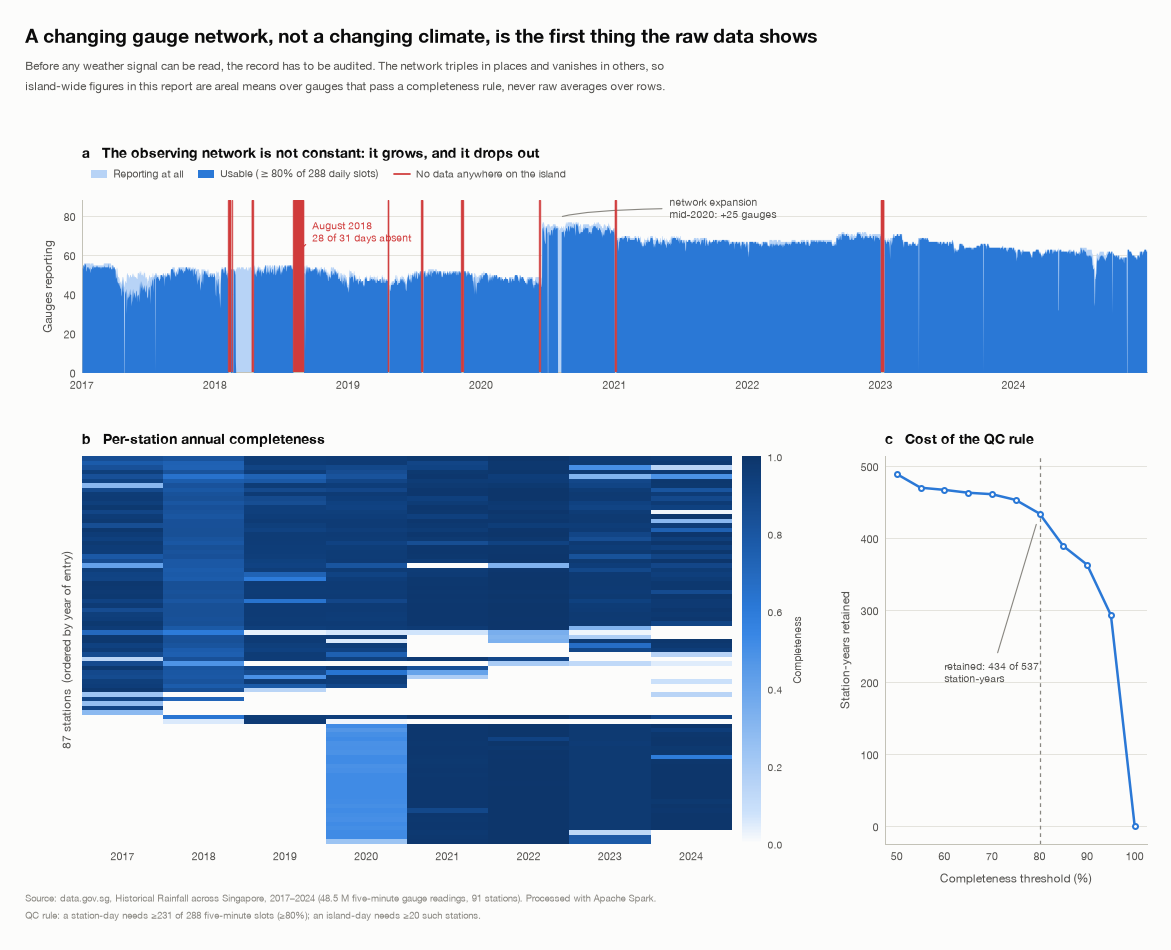

  [figure] outputs/figures/fig01_data_foundation.png


In [18]:
# --- Figure 1: the data foundation -----------------------------------------------------------------
section('Figure 1: the data foundation', writes='fig01, task1_all_figures.pdf (opened here)')
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
SRC = ("Source: data.gov.sg, Historical Rainfall across Singapore, 2017–2024 "
       "(48.5 M five-minute gauge readings, 91 stations). Processed with Apache Spark.")

def hhmm(minutes: int) -> str:
    return f"{int(minutes) // 60:02d}:{int(minutes) % 60:02d}"


def pad_ylim(ax, below: float = 0.13, above: float = 0.09) -> None:
    """Open up room under a trough and over a peak so that a value label sits
    inside the plot instead of running into the tick labels above or below."""
    lo, hi = ax.get_ylim()
    span = hi - lo
    ax.set_ylim(lo - below * span, hi + above * span)


def fig01_coverage() -> None:
    cov = T("t03_station_year_coverage")
    net = T("t04_daily_network")
    net["date"] = pd.to_datetime(net["date"])

    mat = cov.pivot(index="station_id", columns="year", values="coverage")
    # order stations by first year of service, then by how long they served
    first = mat.apply(lambda r: r.first_valid_index(), axis=1)
    mat = mat.loc[sorted(mat.index, key=lambda s: (first[s], -mat.loc[s].count()))]

    fig = plt.figure(figsize=(13.2, 10.3))
    gs = fig.add_gridspec(2, 2, height_ratios=[1.0, 2.25], width_ratios=[2.6, 1.0],
                          hspace=0.30, wspace=0.26)

    # -- (a) daily network size -------------------------------------------
    ax = fig.add_subplot(gs[0, :])
    ax.fill_between(net["date"], 0, net["stations_reporting"], color=BLUE_RAMP[1],
                    lw=0, zorder=2, label="Reporting at all")
    ax.fill_between(net["date"], 0, net["stations_usable"], color=BLUE,
                    lw=0, zorder=3, label="Usable ($\\geq$80% of 288 daily slots)")
    gaps = net[net["stations_reporting"] == 0]
    for d in gaps["date"]:
        ax.axvline(d, color=RED, lw=1.1, alpha=0.85, zorder=4)
    ax.set_ylim(0, 88)
    ax.set_ylabel("Gauges reporting")
    ax.set_title("a   The observing network is not constant: it grows, and it drops out",
                 pad=34)
    ax.set_xlim(net["date"].min(), net["date"].max())
    ax.grid(axis="x", visible=False)
    despine(ax)
    ax.annotate("August 2018\n28 of 31 days absent", xy=(pd.Timestamp("2018-08-15"), 58),
                xytext=(pd.Timestamp("2018-09-25"), 72), fontsize=8.2, color=RED,
                ha="left", va="center",
                arrowprops=dict(arrowstyle="-", shrinkA=4, shrinkB=9, color=RED, lw=0.9,
                                connectionstyle="angle3,angleA=0,angleB=80"))
    ax.annotate("network expansion\nmid-2020: +25 gauges",
                xy=(pd.Timestamp("2020-07-15"), 77), xytext=(pd.Timestamp("2021-06-01"), 84),
                fontsize=8.2, color=INK_2, ha="left", va="center",
                arrowprops=dict(arrowstyle="-", shrinkA=4, shrinkB=9, color=MUTED, lw=0.9,
                                connectionstyle="angle3,angleA=0,angleB=70"))
    handles = ax.get_legend_handles_labels()[0] + [
        Line2D([0], [0], color=RED, lw=1.4, label="No data anywhere on the island")]
    ax.legend(handles=handles, loc="lower left", ncol=3,
              bbox_to_anchor=(0, 1.06), fontsize=8.4)

    # -- (b) station x year coverage heatmap -------------------------------
    ax = fig.add_subplot(gs[1, 0])
    im = ax.imshow(mat.values, aspect="auto", cmap=CMAP_RAIN, vmin=0, vmax=1,
                   interpolation="nearest")
    ax.set_xticks(range(mat.shape[1]), mat.columns)
    ax.set_yticks([])
    ax.set_ylabel(f"{mat.shape[0]} stations  (ordered by year of entry)")
    ax.set_title("b   Per-station annual completeness")
    ax.grid(visible=False)
    for s in ax.spines.values():
        s.set_visible(False)
    cb = fig.colorbar(im, ax=ax, pad=0.015, fraction=0.03)
    cb.set_label("Completeness", fontsize=8.2)
    cb.outline.set_visible(False)
    cb.ax.tick_params(labelsize=8)

    # -- (c) how many station-years survive each threshold -----------------
    ax = fig.add_subplot(gs[1, 1])
    ths = np.arange(0.5, 1.001, 0.05)
    counts = [(cov["coverage"] >= t).sum() for t in ths]
    ax.plot(ths * 100, counts, color=BLUE, marker="o", markersize=4,
            markerfacecolor=SURFACE, markeredgewidth=1.6, zorder=3)
    ax.axvline(80, color=MUTED, lw=1, ls=(0, (3, 3)), zorder=1)
    ax.annotate(f"retained: {(cov['coverage'] >= 0.8).sum()} of {len(cov)}\nstation-years",
                xy=(80, (cov["coverage"] >= 0.8).sum()), xytext=(60, 200),
                fontsize=8.2, color=INK_2,
                arrowprops=dict(arrowstyle="-", shrinkA=4, shrinkB=9, color=MUTED, lw=0.9))
    ax.set_xlabel("Completeness threshold (%)")
    ax.set_ylabel("Station-years retained")
    ax.set_title("c   Cost of the QC rule")
    despine(ax)
    ax.grid(axis="x", visible=False)

    layout(fig, header=2.15, footer=1.00, left=1.05)
    titleblock(fig,
                 "A changing gauge network, not a changing climate, is the first thing the raw data shows",
                 "Before any weather signal can be read, the record has to be audited. The network triples in places and vanishes in others, so\n"
                 "island-wide figures in this report are areal means over gauges that pass a completeness rule, never raw averages over rows.")
    sourcenote(fig, SRC + "\nQC rule: a station-day needs ≥231 of 288 five-minute slots (≥80%); an island-day needs ≥20 such stations.")
    save_figure(fig, FIGURES / "fig01_data_foundation.png")


open_pdf(FIGURES / "task1_all_figures.pdf",
         title="DSA5208 Project 2, Task 1: rainfall patterns across Singapore 2017-2024",
         subject="Figures 1-10")
fig01_coverage()

### 4.1 Island-wide daily series and gap filling

In [19]:
# --- 4b. Island-wide daily series and gap filling --------------------------------------------------
section('4b. Island-wide daily series and gap filling', purpose='unweighted mean of usable station-day totals; unusable days take the (month, day) climatology of the other years', writes='t05_island_daily, t06_island_daily_gapfilled')


def island_series(station_day, min_stations, stations=None):
    """Unweighted mean of usable station-day totals -> one row per island-day."""
    sd = station_day.filter(F.col("usable"))
    if stations is not None:
        sd = sd.filter(F.col("station_id").isin(list(stations)))
    out = (
        sd.groupBy("date", "year", "month", "doy", "season")
        .agg(
            F.count(F.lit(1)).alias("n_stations"),
            F.avg("day_mm").alias("island_mm"),
            F.max("day_mm").alias("wettest_station_mm"),
            F.avg((F.col("day_mm") >= WET_DAY_MM).cast("double")).alias("frac_stations_wet"),
            F.max("max_5min_mm").alias("peak_5min_mm"),
        )
        .filter(F.col("n_stations") >= min_stations)
        .toPandas()
    )
    out["date"] = pd.to_datetime(out["date"])
    out = out.sort_values("date").reset_index(drop=True)
    out["is_wet_day"] = (out["island_mm"] >= WET_DAY_MM).astype(int)
    return out


def gapfill(island_day, calendar):
    """Calendar-complete series; missing days take the (month, day) climatology."""
    full = calendar.merge(island_day[["date", "island_mm"]], on="date", how="left")
    full["year"] = full["date"].dt.year
    full["doy"] = full["date"].dt.dayofyear
    full["md"] = full["date"].dt.month * 100 + full["date"].dt.day
    full["observed"] = full["island_mm"].notna().astype(int)
    clim = full.groupby("md")["island_mm"].mean()
    clim = clim.reindex(sorted(full["md"].unique())).ffill().bfill()   # 29 Feb with no donor
    full["filled_mm"] = full["island_mm"].fillna(full["md"].map(clim))
    return full


with timed("4b. island daily series + gap fill"):
    island_day = island_series(station_day, MIN_STATIONS)
write_table(island_day, "t05_island_daily")
full = gapfill(island_day, calendar)
write_table(full, "t06_island_daily_gapfilled")
checkpoint("4b. Island-wide daily series", [("calendar days", len(full)),
    ("usable island-days (>= 20 usable gauges)", f"{int(full.observed.astype(bool).sum())} ({100 * full.observed.astype(bool).mean():.1f} %)"),
    ("days gap-filled from climatology", int((~full.observed.astype(bool)).sum())),
    ("gauges per usable island-day (mean)", f"{island_day.n_stations.mean():.1f}")])
island_day.head()

08:00:14  4b. Island-wide daily series and gap filling
Purpose : unweighted mean of usable station-day totals; unusable days take the (month, day) climatology of the other years
Writes  : t05_island_daily, t06_island_daily_gapfilled


[08:00:16]  done: 4b. island daily series + gap fill  (1.1 s)
  [table] outputs/tables/t05_island_daily.csv  (2775 rows)
  [table] outputs/tables/t06_island_daily_gapfilled.csv  (2922 rows)

-- 4b. Island-wide daily series ----------------------------------------------------------------
   calendar days                            : 2922
   usable island-days (>= 20 usable gauges) : 2775 (95.0 %)
   days gap-filled from climatology         : 147
   gauges per usable island-day (mean)      : 59.1



,date,year,month,doy,season,n_stations,island_mm,wettest_station_mm,frac_stations_wet,peak_5min_mm,is_wet_day
0,2017-01-02,2017,1,2,NE Monsoon (Dec-Mar),54,12.359259,63.2,0.833333,8.2,1
1,2017-01-03,2017,1,3,NE Monsoon (Dec-Mar),53,2.358491,17.6,0.377358,3.6,1
2,2017-01-04,2017,1,4,NE Monsoon (Dec-Mar),55,2.407273,11.6,0.763636,3.8,1
3,2017-01-05,2017,1,5,NE Monsoon (Dec-Mar),55,1.821818,8.0,0.854545,5.6,1
4,2017-01-06,2017,1,6,NE Monsoon (Dec-Mar),54,0.133333,5.6,0.018519,2.6,0


### 4.2 Fixed gauge network (for robustness checks)

Section 5.3 repeats the main temporal analyses using only stations with ≥ 80 % coverage in each of the eight
years. This fixed network checks how much the changing gauge mix affects the results.

In [20]:
# --- 4c. Fixed gauge network for robustness checks -------------------------------------------------
section('4c. Fixed gauge network for robustness checks', purpose='stations with >= 80 % coverage in every one of the eight years')
ok_years = (cov.assign(ok=cov["coverage"] >= MIN_SLOT_FRAC)
            .groupby("station_id").agg(n=("year", "size"), ok=("ok", "sum")))
cohort = sorted(ok_years[(ok_years["n"] == len(YEARS)) & (ok_years["ok"] == len(YEARS))].index)
min_fixed = math.ceil(MIN_SLOT_FRAC * len(cohort))
checkpoint("4c. Fixed gauge network", [("stations with >= 80 % coverage in all 8 years", len(cohort)),
    ("island-day needs", f">= {min_fixed} of them"), ("stations", ", ".join(cohort))])

08:00:16  4c. Fixed gauge network for robustness checks
Purpose : stations with >= 80 % coverage in every one of the eight years

-- 4c. Fixed gauge network ---------------------------------------------------------------------
   stations with >= 80 % coverage in all 8 years : 21
   island-day needs                              : >= 17 of them
   stations                                      : S08, S107, S113, S114, S115, S116, S119, S121, S24, S33, S40, S43, S77, S78, S79, S81, S88, S89, S90, S900, S94



### 4.3 Time-window building blocks (shared by Task 1 and Task 2)

We compute rolling accumulations with Spark window functions over each station's time series. Windows use elapsed
time (`rangeBetween` on epoch seconds) and count the slots present. A gap therefore shortens or invalidates a
window instead of pulling older readings into it.

Under the timestamp convention suggested by Section 2, a reading stamped `ts` covers [`ts`, `ts`+5 min) and is
complete at clock time `t = ts + 5 min`. A prediction at `t` uses readings stamped no later than `ts = t − 5 min`;
the next 30 minutes contain the six slots stamped `ts`+5 … `ts`+30 min. If the stamp instead marks the end of
its interval, the features (stamps ≤ `ts`) still precede the target (stamps > `ts`). This prevents overlap between
measured feature and target intervals under either interpretation, though the prediction time may be labelled
5 minutes later than necessary.

This convention does not establish real-time availability. Readings arrive 2–10 minutes after their stamp
(Section 2), so the slot stamped `t − 5 min` may not have been published by `t`. The cleaning rules in Section 3
also use whole months or days to identify dead gauges and spikes, which is possible only in hindsight. A live
system would need a larger lag, such as an anchor at `t − 10` or `t − 15 min`, and causal quality rules based on
trailing windows. The feature definitions could stay the same, with the model retrained for the new lag.
The checks in Sections 7.1 and 12.2 test the time boundary of the window computations on cleaned data, rather
than real-time input availability.

* `add_trailing_features` computes rain through the anchor: the latest slot, totals over the last 15/30/60/180
  minutes, the 60-minute peak and the wet-slot count. A window is valid only when every slot is present.
* `add_future_target` sums rain in the next 30 minutes and requires all six future slots; missing slots are
  never treated as dry.
* `add_time_features` adds calendar terms at clock time `t`, with sine/cosine terms placing 23:55 next to 00:00.

In [21]:
# definitions
# --- 4.3 Time-window building blocks shared by Task 1 and Task 2 (time-based window functions) -----
SLOT_SEC = 300


PRED_LAG_SEC = 300


HORIZON_SLOTS = 6


def _w(back_sec: int, fwd_sec: int):
    """Per-station window over epoch seconds, [ts - back, ts + fwd]."""
    return (Window.partitionBy("station_id").orderBy(F.col("ts_s"))
            .rangeBetween(-back_sec, fwd_sec))


def add_future_target(df):
    """Add `future_30min_mm` and `n_future` (slots found in ts+5..ts+30 min).

    `future_30min_mm` is NULL unless all six future slots exist, so an
    incomplete window can never be mistaken for a dry one. Expects columns
    station_id, ts, rain_mm.
    """
    if "ts_s" not in df.columns:
        df = df.withColumn("ts_s", F.col("ts").cast("long"))
    w = (Window.partitionBy("station_id").orderBy("ts_s")
         .rangeBetween(SLOT_SEC, HORIZON_SLOTS * SLOT_SEC))
    return (df.withColumn("n_future", F.count("rain_mm").over(w))
              .withColumn("_fsum", F.sum("rain_mm").over(w))
              .withColumn("future_30min_mm",
                          F.when(F.col("n_future") == HORIZON_SLOTS, F.col("_fsum")))
              .drop("_fsum"))


def add_trailing_features(df):
    """Rainfall known at prediction time: windows END at the anchor slot.

    A window is valid only if every slot in it is present; otherwise the
    feature is NULL and the row is dropped by `complete_rows`.
    """
    if "ts_s" not in df.columns:
        df = df.withColumn("ts_s", F.col("ts").cast("long"))
    out = df.withColumn("r5", F.col("rain_mm"))
    for name, slots in [("acc15", 3), ("acc30", 6), ("acc60", 12), ("acc180", 36)]:
        w = _w((slots - 1) * SLOT_SEC, 0)
        out = (out.withColumn(f"_n{name}", F.count("rain_mm").over(w))
                  .withColumn(name, F.when(F.col(f"_n{name}") == slots,
                                           F.sum("rain_mm").over(w)))
                  .drop(f"_n{name}"))
    w60 = _w(11 * SLOT_SEC, 0)
    out = (out.withColumn("max5_60", F.max("rain_mm").over(w60))
              .withColumn("wet_slots_60",
                          F.sum((F.col("rain_mm") >= WET_5MIN_MM).cast("int")).over(w60))
              .withColumn("is_wet", (F.col("rain_mm") >= WET_5MIN_MM).cast("double")))
    return out


TRAILING_COLS = ["r5", "acc15", "acc30", "acc60", "acc180", "max5_60", "wet_slots_60", "is_wet"]


def add_time_features(df):
    """Calendar features at the CLOCK prediction time t = ts + 5 min (SGT)."""
    t = F.col("ts") + F.expr("INTERVAL 5 MINUTES")
    mod = F.hour(t) * 60 + F.minute(t)
    doy = F.dayofyear(t)
    return (df.withColumn("pred_time", t)
              .withColumn("hour", F.hour(t))
              .withColumn("minute_of_day", mod)
              .withColumn("tod_sin", F.sin(2 * math.pi * mod / 1440.0))
              .withColumn("tod_cos", F.cos(2 * math.pi * mod / 1440.0))
              .withColumn("month", F.month(t))
              .withColumn("doy_sin", F.sin(2 * math.pi * doy / 365.25))
              .withColumn("doy_cos", F.cos(2 * math.pi * doy / 365.25))
              .withColumn("season", season_col(F.month(t))))

---
# Part B. Task 1: weather patterns, within a year and across 2017–2024

We compute the analysis tables in Spark and save them to `outputs/tables/`. The plots and comments below summarise
the results.

### 5.1 Annual totals: how much, how often, how hard

08:00:16  5.1 Annual totals: how much, how often, how hard
Purpose : observed and gap-filled annual totals, wet days, intensity
Writes  : t07_annual_summary, fig02
  [table] outputs/tables/t07_annual_summary.csv  (8 rows)


,year,days_observed,observed_total_mm,mean_daily_mm,wet_days,p95_daily_mm,max_daily_mm,days_in_year,gapfilled_total_mm,days_missing,wet_days_scaled,stations_active
0,2017,361,2416.0,6.7,236,24.6,71.9,365,2454.3,4,238.6,58
1,2018,273,2051.6,7.5,183,25.9,50.9,365,2655.7,92,244.7,56
2,2019,349,1654.6,4.7,164,24.8,55.2,365,1787.0,16,171.5,54
3,2020,350,2574.5,7.4,220,31.1,68.4,366,2631.0,16,230.1,80
4,2021,360,2850.6,7.9,211,33.6,109.2,365,2899.7,5,213.9,74
5,2022,365,2892.8,7.9,241,29.2,66.0,365,2892.8,0,241.0,72
6,2023,353,2750.8,7.8,221,31.0,152.3,365,2879.2,12,228.5,73
7,2024,364,2681.1,7.4,232,28.9,71.6,366,2708.0,2,233.3,70



-- 5.1 Annual totals ---------------------------------------------------------------------------
   wettest year                               : 2021: 2,900 mm (gap-filled)
   driest year                                : 2019: 1,787 mm
   mean / spread                              : 2,613 mm / 43 % of the mean
   wet days per year: 2019 vs the other years : 172 vs 233
   mm per wet day: 2019 vs the other years    : 10.4 vs 11.8
   year with most missing days                : 2018 (92 days)



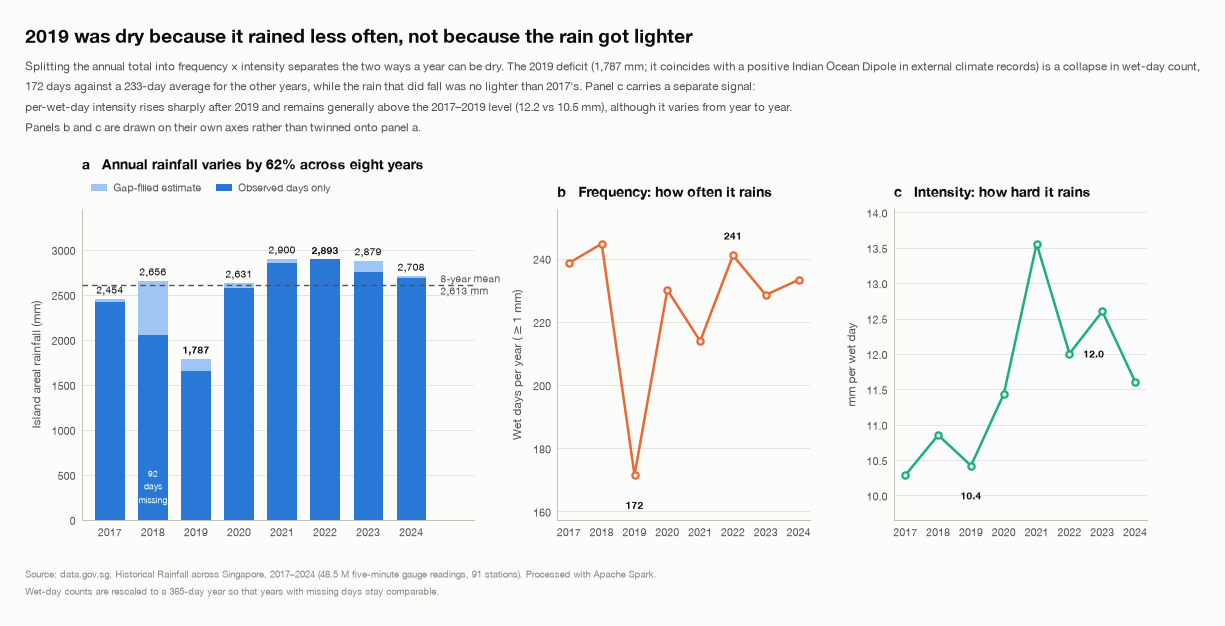

  [figure] outputs/figures/fig02_annual_totals.png


In [22]:
# --- 5.1 Annual totals: how much, how often, how hard ----------------------------------------------
section('5.1 Annual totals: how much, how often, how hard', purpose='observed and gap-filled annual totals, wet days, intensity', writes='t07_annual_summary, fig02')


def annual_table(full, cov):
    obs = full[full["observed"] == 1]
    annual = pd.DataFrame({"year": sorted(full["year"].unique())})
    annual = annual.merge(
        obs.groupby("year").agg(
            days_observed=("island_mm", "size"),
            observed_total_mm=("island_mm", "sum"),
            mean_daily_mm=("island_mm", "mean"),
            wet_days=("island_mm", lambda s: int((s >= WET_DAY_MM).sum())),
            p95_daily_mm=("island_mm", lambda s: float(np.percentile(s, 95))),
            max_daily_mm=("island_mm", "max"),
        ).reset_index(), on="year", how="left")
    annual = annual.merge(
        full.groupby("year").agg(
            days_in_year=("island_mm", "size"),
            gapfilled_total_mm=("filled_mm", "sum"),
        ).reset_index(), on="year", how="left")
    annual["days_missing"] = annual["days_in_year"] - annual["days_observed"]
    # scale wet-day count to a full year so the count is comparable across years
    annual["wet_days_scaled"] = (
        annual["wet_days"] * annual["days_in_year"] / annual["days_observed"]
    ).round(1)
    annual = annual.merge(
        cov.groupby("year").agg(stations_active=("station_id", "size")).reset_index(),
        on="year", how="left")
    return annual


annual = annual_table(full, cov)
write_table(annual, "t07_annual_summary")
display(annual.round(1))
wet_, dry_ = annual.loc[annual.gapfilled_total_mm.idxmax()], annual.loc[annual.gapfilled_total_mm.idxmin()]
others = annual[annual.year != dry_.year]
checkpoint("5.1 Annual totals", [
    ("wettest year", f"{int(wet_.year)}: {wet_.gapfilled_total_mm:,.0f} mm (gap-filled)"),
    ("driest year", f"{int(dry_.year)}: {dry_.gapfilled_total_mm:,.0f} mm"),
    ("mean / spread", f"{annual.gapfilled_total_mm.mean():,.0f} mm / {100 * (wet_.gapfilled_total_mm - dry_.gapfilled_total_mm) / annual.gapfilled_total_mm.mean():.0f} % of the mean"),
    (f"wet days per year: {int(dry_.year)} vs the other years", f"{dry_.wet_days_scaled:.0f} vs {others.wet_days_scaled.mean():.0f}"),
    (f"mm per wet day: {int(dry_.year)} vs the other years", f"{dry_.gapfilled_total_mm / dry_.wet_days_scaled:.1f} vs {(others.gapfilled_total_mm / others.wet_days_scaled).mean():.1f}"),
    ("year with most missing days", f"{int(annual.loc[annual.days_missing.idxmax()].year)} ({int(annual.days_missing.max())} days)")])

def fig02_annual() -> None:
    a = T("t07_annual_summary")
    fig, axes = plt.subplots(1, 3, figsize=(13.2, 6.7),
                             gridspec_kw=dict(width_ratios=[1.55, 1, 1], wspace=0.28))
    x = np.arange(len(a))

    ax = axes[0]
    ax.bar(x, a["gapfilled_total_mm"], color=BLUE_RAMP[2], width=0.68,
           zorder=2, label="Gap-filled estimate")
    ax.bar(x, a["observed_total_mm"], color=BLUE, width=0.68, zorder=3,
           label="Observed days only")
    mean = a["gapfilled_total_mm"].mean()
    ax.axhline(mean, color=INK_2, lw=1.1, ls=(0, (4, 3)), zorder=4)
    ax.text(len(a) - 0.32, mean, f"8-year mean\n{mean:,.0f} mm", ha="left",
            va="center", fontsize=8.2, color=INK_2)
    for i, r in a.iterrows():
        ax.text(i, r["gapfilled_total_mm"] + 60, f"{r['gapfilled_total_mm']:,.0f}",
                ha="center", fontsize=8.2, color=INK,
                fontweight="semibold" if r["year"] in (2019, 2022) else "normal")
        if r["days_missing"] > 20:
            ax.text(i, 130, f"{int(r['days_missing'])}\ndays\nmissing", ha="center",
                    va="bottom", fontsize=7.0, color="white", zorder=5,
                    linespacing=1.35)
    ax.set_xticks(x, a["year"])
    ax.set_ylim(0, 3450)
    ax.set_xlim(-0.65, len(a) + 0.45)
    ax.set_ylabel("Island areal rainfall (mm)")
    ax.set_title(f"a   Annual rainfall varies by {100 * (a['gapfilled_total_mm'].max() / a['gapfilled_total_mm'].min() - 1):.0f}% across eight years", pad=32)
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1.02), ncol=2, fontsize=8.4)
    despine(ax)
    ax.grid(axis="x", visible=False)

    ax = axes[1]
    ax.plot(x, a["wet_days_scaled"], color=ORANGE, marker="o", markersize=5,
            markerfacecolor=SURFACE, markeredgewidth=1.8, zorder=3)
    for i, v in enumerate(a["wet_days_scaled"]):
        if a["year"][i] in (2019, 2022):
            high = a["year"][i] == 2022          # 2022 is a peak, 2019 a trough
            ax.annotate(f"{v:.0f}", (i, v), textcoords="offset points",
                        xytext=(0, 11 if high else -19), ha="center",
                        va="bottom" if high else "top", fontsize=8.2,
                        color=INK, fontweight="semibold")
    ax.set_xticks(x, a["year"])
    ax.set_ylabel("Wet days per year ($\\geq$1 mm)")
    ax.set_title("b   Frequency: how often it rains")
    despine(ax)
    ax.grid(axis="x", visible=False)
    pad_ylim(ax)

    ax = axes[2]
    intensity = a["gapfilled_total_mm"] / a["wet_days_scaled"]
    ax.plot(x, intensity, color=AQUA, marker="o", markersize=5,
            markerfacecolor=SURFACE, markeredgewidth=1.8, zorder=3)
    for i, v in enumerate(intensity):
        if a["year"][i] in (2019, 2022):
            # 2019 is a trough; 2022 sits mid-slope, so its label goes out to
            # the right where the line has already passed
            below = a["year"][i] == 2019
            ax.annotate(f"{v:.1f}", (i, v), textcoords="offset points",
                        xytext=(0 if below else 11, -19 if below else 0),
                        ha="center" if below else "left",
                        va="top" if below else "center", fontsize=8.2,
                        color=INK, fontweight="semibold")
    ax.set_xticks(x, a["year"])
    ax.set_ylabel("mm per wet day")
    ax.set_title("c   Intensity: how hard it rains")
    despine(ax)
    ax.grid(axis="x", visible=False)
    pad_ylim(ax)

    y19, y17 = a[a["year"] == 2019].iloc[0], a[a["year"] == 2017].iloc[0]
    norm_wet = a.loc[a["year"] != 2019, "wet_days_scaled"].mean()
    post = intensity[a["year"] >= 2020]
    pre = intensity[a["year"] <= 2019]
    layout(fig, header=2.25, footer=1.00, left=1.05)
    titleblock(fig,
                 "2019 was dry because it rained less often, not because the rain got lighter",
                 f"Splitting the annual total into frequency \u00d7 intensity separates the two ways a year can be dry. The 2019 deficit "
                 f"({y19['gapfilled_total_mm']:,.0f} mm; it coincides with a positive Indian Ocean Dipole in external climate records) is a collapse in wet-day count,\n"
                 f"{y19['wet_days_scaled']:.0f} days against a {norm_wet:.0f}-day average for the other years, while the rain that did fall was no lighter than 2017's. "
                 f"Panel c carries a separate signal:\nper-wet-day intensity rises sharply after 2019 and remains generally above the 2017\u20132019 level "
                 f"({post.mean():.1f} vs {pre.mean():.1f} mm), although it varies from year to year.\n"
                 "Panels b and c are drawn on their own axes rather than twinned onto panel a.")
    sourcenote(fig, SRC + "\nWet-day counts are rescaled to a 365-day year so that years with missing days stay comparable.")
    save_figure(fig, FIGURES / "fig02_annual_totals.png")


fig02_annual()

Annual island rainfall ranges from 1,787 mm in 2019 to 2,900 mm in 2021, a 62 % spread around the 2,613 mm mean.
2022 is close to the maximum at 2,893 mm. The 2018 record has 92 unusable days, with August 2018 almost absent
from the source, so its observed total is too low; the gap-filled value is the comparable estimate.

The frequency × intensity decomposition shows that 2019 had fewer wet days: 172, against a 233-day average for
the other years. Rain on those days was similar in amount to 2017, at 10.4 mm per wet day versus 10.3 mm.

### 5.2 The seasonal cycle

08:00:16  5.2 The seasonal cycle
Purpose : monthly and seasonal totals for every year, and the 2017-2024 monthly climatology
Writes  : t08_monthly, t09_seasonal, fig03
  [table] outputs/tables/t08_monthly.csv  (96 rows)
  [table] outputs/tables/t09_seasonal.csv  (32 rows)

-- 5.2 Seasonal cycle (2017-2024 monthly climatology) ------------------------------------------
   wettest months                           : Nov 315 mm, Dec 261 mm, Apr 248 mm
   driest months                            : Jul 147 mm, Feb 145 mm
   largest year-to-year ratio for one month : Aug: 11x (36-409 mm)



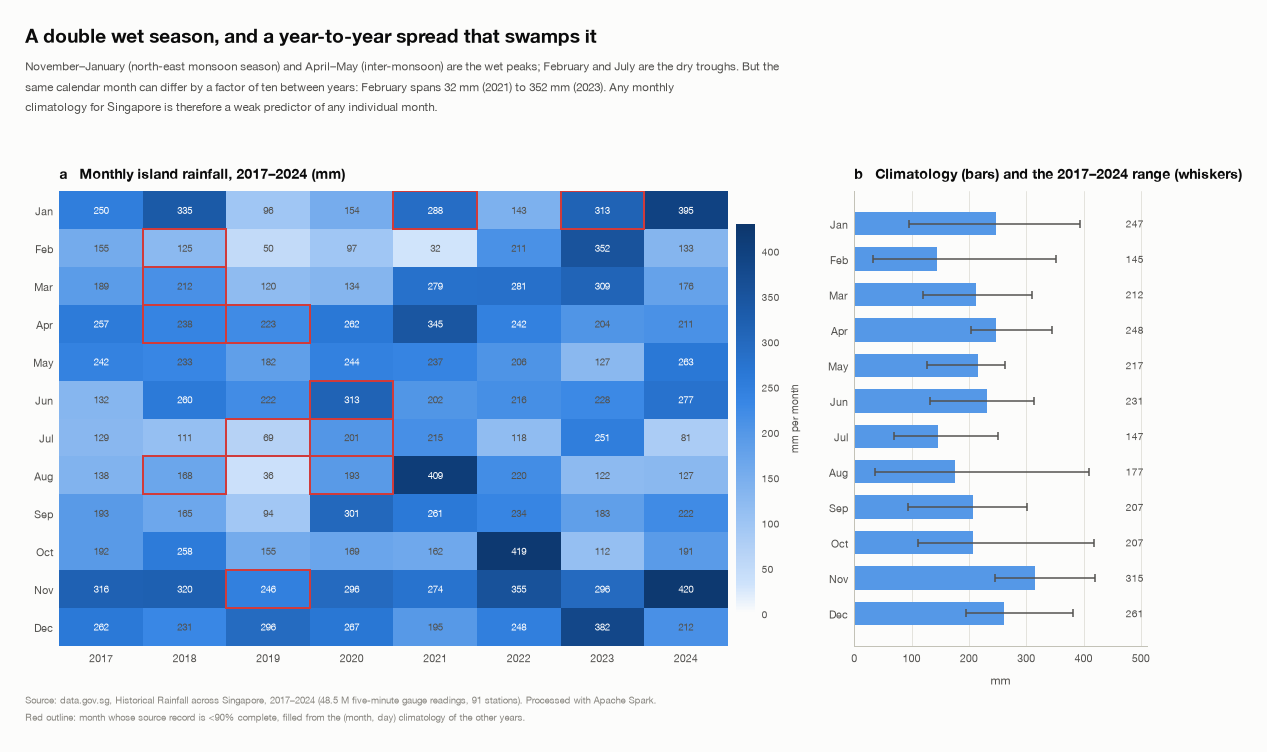

  [figure] outputs/figures/fig03_seasonal_cycle.png


In [23]:
# --- 5.2 The seasonal cycle ------------------------------------------------------------------------
section('5.2 The seasonal cycle', purpose='monthly and seasonal totals for every year, and the 2017-2024 monthly climatology', writes='t08_monthly, t09_seasonal, fig03')


def monthly_table(full):
    mon = full.copy()
    mon["month"] = mon["date"].dt.month
    monthly = mon.groupby(["year", "month"]).agg(
        total_mm=("filled_mm", "sum"),
        observed_total_mm=("island_mm", "sum"),
        days_observed=("observed", "sum"),
        days=("observed", "size"),
    ).reset_index()
    monthly["complete"] = (monthly["days_observed"] >= 0.9 * monthly["days"]).astype(int)
    clim_m = monthly.groupby("month")["total_mm"].mean().rename("clim_mm")
    monthly = monthly.merge(clim_m, on="month")
    monthly["anomaly_mm"] = monthly["total_mm"] - monthly["clim_mm"]
    monthly["anomaly_pct"] = 100 * monthly["anomaly_mm"] / monthly["clim_mm"]
    return monthly


monthly = monthly_table(full)
write_table(monthly.sort_values(["year", "month"]), "t08_monthly")
seasonal = (island_day.groupby(["year", "season"])
            .agg(observed_mm=("island_mm", "sum"), days=("island_mm", "size"), mean_daily_mm=("island_mm", "mean"))
            .reset_index())
write_table(seasonal, "t09_seasonal")
clim_m = monthly.groupby("month").total_mm.mean().sort_values(ascending=False)
m_min, m_max = monthly.groupby("month").total_mm.min(), monthly.groupby("month").total_mm.max()
ratio = m_max / m_min
checkpoint("5.2 Seasonal cycle (2017-2024 monthly climatology)", [
    ("wettest months", ", ".join(f"{MONTHS[m - 1]} {v:.0f} mm" for m, v in clim_m.head(3).items())),
    ("driest months", ", ".join(f"{MONTHS[m - 1]} {v:.0f} mm" for m, v in clim_m.tail(2).items())),
    ("largest year-to-year ratio for one month", f"{MONTHS[ratio.idxmax() - 1]}: {ratio.max():.0f}x ({m_min[ratio.idxmax()]:.0f}-{m_max[ratio.idxmax()]:.0f} mm)")])

def fig03_seasonal() -> None:
    m = T("t08_monthly")
    grid = m.pivot(index="month", columns="year", values="total_mm")
    clim = m.groupby("month")["total_mm"].mean()

    fig = plt.figure(figsize=(13.2, 8.1))
    gs = fig.add_gridspec(1, 2, width_ratios=[2.5, 1.05], wspace=0.2)

    ax = fig.add_subplot(gs[0, 0])
    im = ax.imshow(grid.values, aspect="auto", cmap=CMAP_RAIN, vmin=0, vmax=430,
                   interpolation="nearest")
    ax.set_xticks(range(grid.shape[1]), grid.columns)
    ax.set_yticks(range(12), MONTHS)
    ax.grid(visible=False)
    for s in ax.spines.values():
        s.set_visible(False)
    for i in range(12):
        for j in range(grid.shape[1]):
            v = grid.values[i, j]
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7.9,
                    color="white" if v > 240 else INK_2)
    # mark months whose source record is incomplete
    inc = m[m["complete"] == 0]
    for _, r in inc.iterrows():
        ax.add_patch(Rectangle((list(grid.columns).index(r["year"]) - 0.5,
                                r["month"] - 1.5), 1, 1, fill=False,
                               edgecolor=RED, lw=1.6, zorder=5))
    ax.set_title("a   Monthly island rainfall, 2017–2024 (mm)")
    cb = fig.colorbar(im, ax=ax, pad=0.012, fraction=0.028)
    cb.outline.set_visible(False)
    cb.ax.tick_params(labelsize=8)
    cb.set_label("mm per month", fontsize=8.2)

    ax = fig.add_subplot(gs[0, 1])
    y = np.arange(12)
    ax.barh(y, clim.values, color=BLUE_RAMP[5], height=0.66, zorder=2)
    lo = grid.min(axis=1).values
    hi = grid.max(axis=1).values
    ax.hlines(y, lo, hi, color=INK_2, lw=1.2, zorder=3)
    ax.plot(lo, y, "|", color=INK_2, markersize=7, markeredgewidth=1.2, zorder=3)
    ax.plot(hi, y, "|", color=INK_2, markersize=7, markeredgewidth=1.2, zorder=3)
    # values as a right-hand column so the range whiskers never cross them
    for i, v in enumerate(clim.values):
        ax.text(505, i, f"{v:.0f}", va="center", ha="right", fontsize=8.2,
                color=INK_2, zorder=4)
    ax.set_yticks(y, MONTHS)
    ax.invert_yaxis()
    ax.set_xlim(0, 510)
    ax.set_xlabel("mm")
    ax.set_title("b   Climatology (bars) and the 2017\u20132024 range (whiskers)")
    despine(ax)
    ax.grid(axis="y", visible=False)

    layout(fig, header=2.05, footer=1.00, left=0.8)
    titleblock(fig,
                 "A double wet season, and a year-to-year spread that swamps it",
                 "November–January (north-east monsoon season) and April–May (inter-monsoon) are the wet peaks; February and July are the dry "
                 "troughs. But the\nsame calendar month can differ by a factor of ten between years: "
                 f"February spans {grid.loc[2].min():.0f} mm ({grid.loc[2].idxmin()}) to {grid.loc[2].max():.0f} mm ({grid.loc[2].idxmax()}). "
                 "Any monthly\nclimatology for Singapore is therefore a weak predictor of any individual month.")
    sourcenote(fig, SRC + "\nRed outline: month whose source record is <90% complete, filled from the (month, day) climatology of the other years.")
    save_figure(fig, FIGURES / "fig03_seasonal_cycle.png")


fig03_seasonal()

Rainfall peaks in November–January during the north-east monsoon and in April–May during the inter-monsoon.
February and July are the driest months. Values for the same calendar month differ by up to a factor of ten
between years, limiting how much a monthly climatology can tell us about a particular month.

### 5.3 Robustness: does the changing network distort the results?

We recompute annual and monthly results for the fixed 21-gauge network from Section 4.2 and compare them with
the full-network results using pre-declared pass/fail checks. Figure 4 shows the monthly anomalies.

In [24]:
# --- 5.3 Robustness: the fixed 21-gauge network ----------------------------------------------------
section('5.3 Robustness: the fixed 21-gauge network', purpose='re-derive the annual and monthly products on the fixed network and run pre-declared checks', writes='t22-t24 sensitivity tables')


def spearman(a, b):
    """Rank correlation without a SciPy dependency."""
    return a.rank().corr(b.rank())


def mann_kendall(years, values):
    """Mann-Kendall trend test with Sen's slope, without a SciPy dependency.

    The two-sided p-value is exact: Kendall's S is recomputed for every
    ordering of the values (8! = 40,320 for 2017-2024). With eight points the
    test has little power, so p > 0.05 means "not shown", not "no change".
    """
    x = np.asarray(years, float)
    y = np.asarray(values, float)
    i, j = np.triu_indices(len(y), 1)
    s_obs = np.sign(y[j] - y[i]).sum()
    perms = np.array(list(itertools.permutations(y)))
    s_null = np.sign(perms[:, j] - perms[:, i]).sum(axis=1)
    return {"kendall_tau": s_obs / len(i),
            "p_value_exact": float(np.mean(np.abs(s_null) >= abs(s_obs) - 1e-9)),
            "sen_slope_per_year": float(np.median((y[j] - y[i]) / (x[j] - x[i])))}


def longest_below_run(monthly):
    """Longest unbroken run of below-average months (anomaly < 0)."""
    best = run = 0
    for v in monthly.sort_values(["year", "month"])["anomaly_mm"]:
        run = run + 1 if v < 0 else 0
        best = max(best, run)
    return best


def sensitivity_annual(full_a, fx_a, n_cohort):
    """Side-by-side annual results. Absolute levels differ between networks
    (different gauges), so shape is compared via an index to each network's own
    8-year mean."""
    out = pd.DataFrame({"year": full_a["year"]})
    for tag, a in [("full", full_a), ("fixed", fx_a)]:
        out[f"total_mm_{tag}"] = a["gapfilled_total_mm"].round(1)
        out[f"index_{tag}"] = (100 * a["gapfilled_total_mm"] / a["gapfilled_total_mm"].mean()).round(1)
        out[f"rank_{tag}"] = a["gapfilled_total_mm"].rank(ascending=False).astype(int)
        out[f"wet_days_{tag}"] = a["wet_days_scaled"]
        out[f"mm_per_wet_day_{tag}"] = (a["gapfilled_total_mm"] / a["wet_days_scaled"]).round(2)
        out[f"days_missing_{tag}"] = a["days_missing"]
    out["index_diff_pp"] = (out["index_fixed"] - out["index_full"]).round(1)
    out["n_stations_fixed"] = n_cohort
    return out


def sensitivity_monthly(full_m, fx_m):
    out = pd.DataFrame({"month": range(1, 13)})
    for tag, m in [("full", full_m), ("fixed", fx_m)]:
        c = m.groupby("month")["total_mm"].mean()
        out[f"clim_mm_{tag}"] = out["month"].map(c).round(1)
        out[f"share_pct_{tag}"] = (100 * out[f"clim_mm_{tag}"] / out[f"clim_mm_{tag}"].sum()).round(2)
        out[f"rank_{tag}"] = out[f"clim_mm_{tag}"].rank(ascending=False).astype(int)
    out["share_diff_pp"] = (out["share_pct_fixed"] - out["share_pct_full"]).round(2)
    return out


def sensitivity_summary(full_a, fx_a, full_m, fx_m, cohort, min_fixed):
    rows = []

    def add(metric, value, note=""):
        rows.append({"metric": metric, "value": value, "note": note})

    ta, tf = full_a["gapfilled_total_mm"], fx_a["gapfilled_total_mm"]
    ia, i_f = ta / ta.mean(), tf / tf.mean()
    add("fixed_network_stations", len(cohort), ",".join(cohort))
    add("fixed_island_day_min_stations", min_fixed, "80% of the cohort")
    add("annual_total_spearman", round(float(spearman(ta, tf)), 3), "rank agreement")
    add("annual_total_pearson", round(float(ta.corr(tf)), 3), "")
    add("wettest_year_full/fixed", f"{int(full_a.loc[ta.idxmax(), 'year'])}/{int(fx_a.loc[tf.idxmax(), 'year'])}", "")
    add("driest_year_full/fixed", f"{int(full_a.loc[ta.idxmin(), 'year'])}/{int(fx_a.loc[tf.idxmin(), 'year'])}", "")
    add("max_abs_annual_index_diff_pp", round(float((100 * (i_f - ia)).abs().max()), 1),
        "index to own 8-yr mean, percentage points")
    add("annual_range_pct_full/fixed",
        f"{100 * (ta.max() / ta.min() - 1):.0f}/{100 * (tf.max() / tf.min() - 1):.0f}", "(max/min - 1)")
    wa, wf = full_a["wet_days_scaled"], fx_a["wet_days_scaled"]
    add("wet_days_spearman", round(float(spearman(wa, wf)), 3), "")
    inta, intf = ta / wa, tf / wf
    pre = full_a["year"] <= 2019
    add("intensity_every_year_2020-24_above_2017-19_mean_full/fixed",
        f"{bool((inta[~pre] > inta[pre].mean()).all())}/{bool((intf[~pre] > intf[pre].mean()).all())}",
        "mm per wet day")
    add("intensity_2020-24_mean_vs_2017-19_mean_pct_full/fixed",
        f"{100 * (inta[~pre].mean() / inta[pre].mean() - 1):.0f}/{100 * (intf[~pre].mean() / intf[pre].mean() - 1):.0f}", "")
    ca = full_m.groupby("month")["total_mm"].mean()
    cf = fx_m.groupby("month")["total_mm"].mean()
    add("monthly_climatology_spearman", round(float(spearman(ca, cf)), 3), "")
    add("wettest_month_full/fixed", f"{int(ca.idxmax())}/{int(cf.idxmax())}", "")
    add("driest_month_full/fixed", f"{int(ca.idxmin())}/{int(cf.idxmin())}", "")
    fm = full_m.sort_values(["year", "month"]).reset_index(drop=True)
    xm = fx_m.sort_values(["year", "month"]).reset_index(drop=True)
    add("monthly_anomaly_pct_pearson", round(float(fm["anomaly_pct"].corr(xm["anomaly_pct"])), 3), "96 months")
    add("monthly_anomaly_sign_agreement_pct",
        round(float(100 * (np.sign(fm["anomaly_mm"]) == np.sign(xm["anomaly_mm"])).mean()), 1), "")
    add("longest_below_average_run_months_full/fixed",
        f"{longest_below_run(full_m)}/{longest_below_run(fx_m)}", "")
    # how many months of the full network's longest run are also below average
    # in the fixed network? (distinguishes a flipped marginal month from a
    # genuinely different drought)
    neg = (fm["anomaly_mm"] < 0).to_numpy()
    best = run = end = 0
    for i, flag in enumerate(neg):
        run = run + 1 if flag else 0
        if run > best:
            best, end = run, i
    win = slice(end - best + 1, end + 1)
    add("below_average_months_in_full_longest_run_full/fixed",
        f"{int(neg[win].sum())}/{int((xm['anomaly_mm'].to_numpy()[win] < 0).sum())}",
        f"{fm['year'][end - best + 1]}-{fm['month'][end - best + 1]:02d} to {fm['year'][end]}-{fm['month'][end]:02d}")
    changed = [f"{int(y)} (full #{rf_}, fixed #{rx_}, index {a_:.1f}/{b_:.1f})"
               for y, rf_, rx_, a_, b_ in zip(
                   full_a["year"], ta.rank(ascending=False), tf.rank(ascending=False),
                   100 * ia, 100 * i_f) if rf_ != rx_]
    add("years_whose_rank_changes", "; ".join(changed) or "none",
        "all swaps are between years whose index differs by only a few percentage points")
    # pre-declared headline checks (not tuned after seeing the result)
    checks = {
        "driest year identical": full_a.loc[ta.idxmin(), "year"] == fx_a.loc[tf.idxmin(), "year"],
        "annual totals Pearson >= 0.95": ta.corr(tf) >= 0.95,
        "max annual index difference <= 5 pp": float((100 * (i_f - ia)).abs().max()) <= 5.0,
        "annual range within 5 pp": abs(100 * ((ta.max() / ta.min()) - (tf.max() / tf.min()))) <= 5.0,
        "monthly climatology Spearman >= 0.9, wettest & driest month identical":
            spearman(ca, cf) >= 0.9 and ca.idxmax() == cf.idxmax() and ca.idxmin() == cf.idxmin(),
        "monthly anomaly r >= 0.9": fm["anomaly_pct"].corr(xm["anomaly_pct"]) >= 0.9,
        "post-2019 intensity above 2017-19 level in both":
            bool((inta[~pre] > inta[pre].mean()).all() and (intf[~pre] > intf[pre].mean()).all()),
    }
    for k, v in checks.items():
        add(f"check: {k}", "PASS" if v else "FAIL")
    add("verdict", "HEADLINE CONCLUSIONS ROBUST" if all(checks.values()) else "MATERIAL CHANGE - REVIEW",
        "see years_whose_rank_changes and longest_below_average_run for the fragile details")
    return pd.DataFrame(rows)


with timed("5.3 fixed-network sensitivity"):
    fx_day = island_series(station_day, min_fixed, cohort)
fx_full = gapfill(fx_day, calendar)
fx_annual = annual_table(fx_full, cov[cov["station_id"].isin(cohort)])
fx_monthly = monthly_table(fx_full)
write_table(sensitivity_annual(annual, fx_annual, len(cohort)), "t22_sensitivity_annual")
write_table(sensitivity_monthly(monthly, fx_monthly), "t23_sensitivity_monthly")
sens = write_table(sensitivity_summary(annual, fx_annual, monthly, fx_monthly, cohort, min_fixed),
                   "t24_sensitivity_summary")
sv = sens.set_index("metric")["value"]
checkpoint("5.3 Fixed-network sensitivity", [("fixed network", f"{len(cohort)} gauges (island-day needs >= {min_fixed})"),
    ("annual totals, Pearson r (full vs fixed network)", sv.get("annual_total_pearson", "n/a")),
    ("monthly anomalies, sign agreement", f"{sv.get('monthly_anomaly_sign_agreement_pct', 'n/a')} %"),
    ("checks reported", f"{len(sens)} rows in t24_sensitivity_summary (see the notes column)")])
sens[sens["metric"] != "fixed_network_stations"]

08:00:17  5.3 Robustness: the fixed 21-gauge network
Purpose : re-derive the annual and monthly products on the fixed network and run pre-declared checks
Writes  : t22-t24 sensitivity tables


[08:00:18]  done: 5.3 fixed-network sensitivity  (1.1 s)
  [table] outputs/tables/t22_sensitivity_annual.csv  (8 rows)
  [table] outputs/tables/t23_sensitivity_monthly.csv  (12 rows)
  [table] outputs/tables/t24_sensitivity_summary.csv  (27 rows)

-- 5.3 Fixed-network sensitivity ---------------------------------------------------------------
   fixed network                                    : 21 gauges (island-day needs >= 17)
   annual totals, Pearson r (full vs fixed network) : 0.986
   monthly anomalies, sign agreement                : 97.9 %
   checks reported                                  : 27 rows in t24_sensitivity_summary (see the notes column)



,metric,value,note
1,fixed_island_day_min_stations,17,80% of the cohort
2,annual_total_spearman,0.881,rank agreement
3,annual_total_pearson,0.986,
4,wettest_year_full/fixed,2021/2021,
5,driest_year_full/fixed,2019/2019,
6,max_abs_annual_index_diff_pp,3.2,"index to own 8-yr mean, percentage points"
7,annual_range_pct_full/fixed,62/61,(max/min - 1)
8,wet_days_spearman,0.952,
9,intensity_every_year_2020-24_above_2017-19_mea...,True/True,mm per wet day
10,intensity_2020-24_mean_vs_2017-19_mean_pct_ful...,16/14,


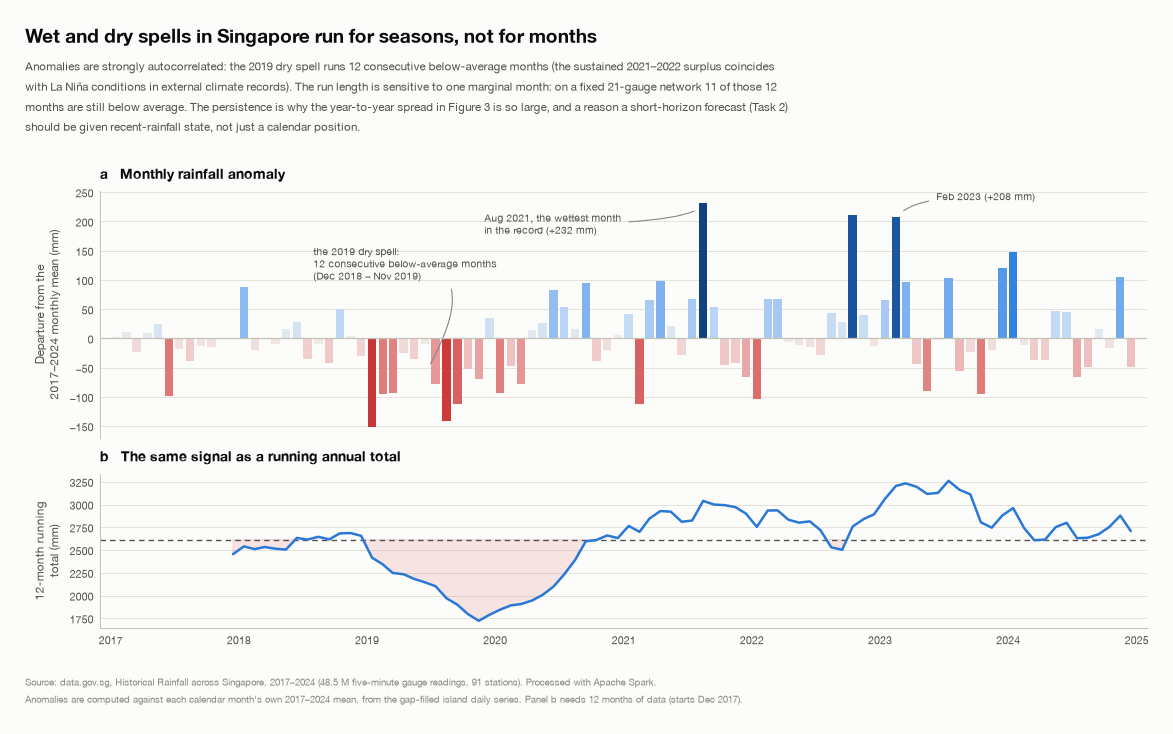

  [figure] outputs/figures/fig04_monthly_anomaly.png


In [25]:
# --- Figure 4: monthly anomalies and the 12-month running total ------------------------------------
def fig04_anomaly() -> None:
    m = T("t08_monthly").sort_values(["year", "month"]).reset_index(drop=True)
    m["t"] = pd.to_datetime(dict(year=m["year"], month=m["month"], day=15))
    v = m["anomaly_mm"].to_numpy()
    lim = np.abs(v).max()
    colors = CMAP_ANOM((v / (2 * lim)) + 0.5)

    fig, axes = plt.subplots(2, 1, figsize=(13.2, 7.9), sharex=True,
                             gridspec_kw=dict(height_ratios=[1.6, 1], hspace=0.18))

    ax = axes[0]
    ax.bar(m["t"], v, width=24, color=colors, zorder=3)
    ax.axhline(0, color=AXIS, lw=1, zorder=4)
    ax.set_ylabel("Departure from the\n2017–2024 monthly mean (mm)")
    ax.set_title("a   Monthly rainfall anomaly")
    despine(ax, bottom=True)
    ax.grid(axis="x", visible=False)
    ax.set_xlim(m["t"].min() - pd.Timedelta(days=45),
                m["t"].max() + pd.Timedelta(days=45))

    # measure the longest unbroken run of below-average months rather than
    # asserting a round number in the caption
    neg = (v < 0).astype(int)
    best = run = 0
    best_end = 0
    for i, flag in enumerate(neg):
        run = run + 1 if flag else 0
        if run > best:
            best, best_end = run, i
    run_start, run_end = m["t"].iloc[best_end - best + 1], m["t"].iloc[best_end]
    sens = T("t24_sensitivity_summary").set_index("metric")["value"]
    n_fixed = int(sens["fixed_network_stations"])
    fixed_neg = sens["below_average_months_in_full_longest_run_full/fixed"].split("/")[1]
    top = m.nlargest(3, "anomaly_mm")
    wet1, wet3 = top.iloc[0], m[(m["year"] == 2023) & (m["month"] == 2)].iloc[0]
    for lbl, xy, xytext in [
        (f"the 2019 dry spell:\n{best} consecutive below-average months\n"
         f"({run_start:%b %Y} \u2013 {run_end:%b %Y})",
         (pd.Timestamp("2019-06-15"), -60), (pd.Timestamp("2018-08-01"), 128)),
        (f"{wet1['t']:%b %Y}, the wettest month\nin the record (+{wet1['anomaly_mm']:.0f} mm)",
         (wet1["t"], wet1["anomaly_mm"] - 3), (pd.Timestamp("2019-12-01"), 196)),
        (f"{wet3['t']:%b %Y} (+{wet3['anomaly_mm']:.0f} mm)",
         (wet3["t"], wet3["anomaly_mm"] - 3), (pd.Timestamp("2023-06-10"), 243)),
    ]:
        ax.annotate(lbl, xy=xy, xytext=xytext, fontsize=8.2, color=INK_2,
                    ha="left", va="center",
                    arrowprops=dict(arrowstyle="-", shrinkA=4, shrinkB=9, color=MUTED, lw=0.9,
                                    connectionstyle="angle3,angleA=0,angleB=60"))

    ax = axes[1]
    roll = m.set_index("t")["total_mm"].rolling(12, min_periods=12).sum()   # genuine 12-month window
    ax.plot(roll.index, roll.values, color=BLUE, zorder=3)
    ax.axhline(T("t07_annual_summary")["gapfilled_total_mm"].mean(), color=INK_2,
               lw=1.1, ls=(0, (4, 3)), zorder=2)
    ax.fill_between(roll.index, roll.values,
                    T("t07_annual_summary")["gapfilled_total_mm"].mean(),
                    where=roll.values < T("t07_annual_summary")["gapfilled_total_mm"].mean(),
                    color=RED, alpha=0.13, zorder=1, interpolate=True)
    ax.set_ylabel("12-month running\ntotal (mm)")
    ax.set_title("b   The same signal as a running annual total")
    despine(ax)
    ax.grid(axis="x", visible=False)

    layout(fig, header=2.05, footer=1.00, left=1.25)
    titleblock(fig,
                 "Wet and dry spells in Singapore run for seasons, not for months",
                 f"Anomalies are strongly autocorrelated: the 2019 dry spell runs {best} consecutive below-average months (the sustained 2021–2022 "
                 "surplus coincides\nwith La Niña conditions in external climate records). The run length is sensitive to one marginal month: on a fixed "
                 f"{n_fixed}-gauge network {fixed_neg} of those {best}\nmonths are still below average. The persistence is why the year-to-year spread in Figure 3 is so large, and a reason "
                 "a short-horizon forecast (Task 2)\nshould be given recent-rainfall state, not just a calendar position.")
    sourcenote(fig, SRC + "\nAnomalies are computed against each calendar month's own 2017–2024 mean, from the gap-filled island daily series. Panel b needs 12 months of data (starts Dec 2017).")
    save_figure(fig, FIGURES / "fig04_monthly_anomaly.png")


fig04_anomaly()

All pre-declared checks pass. Annual totals from the two networks correlate at r = 0.99; the driest year (2019)
and the wettest and driest months are unchanged. Monthly anomalies agree in sign 98 % of the time.

The differences are among closely ranked years: 2022/2023 and 2020/2024 swap places, with each pair separated
by a few percentage points. The full network shows 12 consecutive below-average months in 2019; the fixed
network agrees for 11 of those 12. These spells last much of a season, supporting the use of recent rainfall
state alongside calendar features in Task 2.

### 5.4 The diurnal cycle: when during the day it rains

08:00:18  5.4 The diurnal cycle
Purpose : mean rain rate by half-hour x month x year, and by station x season
Writes  : t10_diurnal_month_year, t11_diurnal_station_season, fig05


[08:00:20]  done: 5.4 diurnal cycle  (1.5 s)
  [table] outputs/tables/t10_diurnal_month_year.csv  (4608 rows)
  [table] outputs/tables/t11_diurnal_station_season.csv  (16416 rows)

-- 5.4 Diurnal cycle: half-hour of maximum mean rain rate --------------------------------------
   Inter-monsoon (Apr-May) : 15:00  (0.82 mm/h)
   Inter-monsoon (Oct-Nov) : 15:00  (1.25 mm/h)
   NE Monsoon (Dec-Mar)    : 16:00  (1.09 mm/h)
   SW Monsoon (Jun-Sep)    : 10:00  (0.56 mm/h)



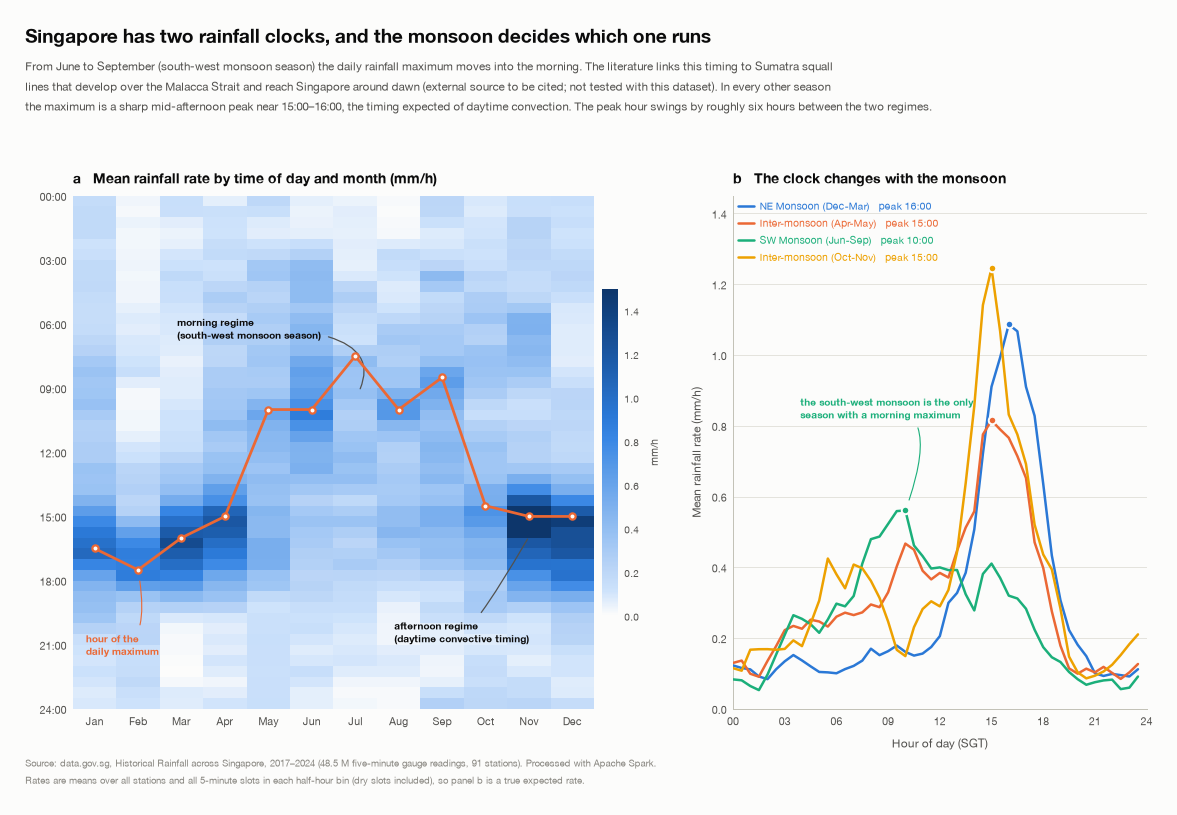

  [figure] outputs/figures/fig05_diurnal_cycle.png


In [26]:
# --- 5.4 The diurnal cycle -------------------------------------------------------------------------
section('5.4 The diurnal cycle', purpose='mean rain rate by half-hour x month x year, and by station x season', writes='t10_diurnal_month_year, t11_diurnal_station_season, fig05')
halfhour = (F.floor(F.col("minute_of_day") / F.lit(30)) * F.lit(30)).alias("hh_min")
with timed("5.4 diurnal cycle"):
    diurnal = (df.withColumn("hh_min", halfhour)
               .groupBy("year", "month", "season", "hh_min")
               .agg(F.avg("rain_mm").alias("mean_mm_per_5min"),
                    F.avg((F.col("rain_mm") >= WET_5MIN_MM).cast("double")).alias("wet_frac"),
                    F.count(F.lit(1)).alias("n"))
               .withColumn("mm_per_hour", F.col("mean_mm_per_5min") * F.lit(12))
               .toPandas())
    diurnal_station = (df.withColumn("hh_min", halfhour)
                       .groupBy("station_id", "season", "hh_min")
                       .agg(F.avg("rain_mm").alias("mean_mm_per_5min"))
                       .withColumn("mm_per_hour", F.col("mean_mm_per_5min") * F.lit(12))
                       .toPandas())
write_table(diurnal, "t10_diurnal_month_year")
write_table(diurnal_station, "t11_diurnal_station_season")
pk = diurnal.groupby(["season", "hh_min"]).mm_per_hour.mean().reset_index()
pk = pk.loc[pk.groupby("season").mm_per_hour.idxmax()]
checkpoint("5.4 Diurnal cycle: half-hour of maximum mean rain rate", [
    (s, f"{int(h) // 60:02d}:{int(h) % 60:02d}  ({v:.2f} mm/h)") for s, h, v in pk[["season", "hh_min", "mm_per_hour"]].itertuples(index=False)])

def fig05_diurnal() -> None:
    d = T("t10_diurnal_month_year")
    grid = (d.groupby(["hh_min", "month"])["mm_per_hour"].mean()
            .unstack("month").sort_index())

    fig = plt.figure(figsize=(13.2, 8.8))
    gs = fig.add_gridspec(1, 2, width_ratios=[1.45, 1.1], wspace=0.24)

    # -- (a) hour x month heatmap -----------------------------------------
    ax = fig.add_subplot(gs[0, 0])
    im = ax.pcolormesh(np.arange(13), np.arange(49) * 0.5, grid.values,
                       cmap=CMAP_RAIN, vmin=0, vmax=1.5, shading="flat")
    ax.set_xticks(np.arange(12) + 0.5, MONTHS)
    ax.set_yticks(np.arange(0, 25, 3), [f"{h:02d}:00" for h in range(0, 25, 3)])
    ax.set_ylim(0, 24)
    ax.invert_yaxis()
    ax.grid(visible=False)
    for s in ax.spines.values():
        s.set_visible(False)
    # trace the daily maximum
    peak = grid.idxmax(axis=0) / 60.0
    ax.plot(np.arange(12) + 0.5, peak.values, color=ORANGE, lw=2.2,
            marker="o", markersize=5, markerfacecolor=SURFACE,
            markeredgewidth=1.8, zorder=5)
    ax.annotate("hour of the\ndaily maximum", xy=(1.5, peak.values[1]),
                xytext=(0.30, 21.0), fontsize=8.2, color=ORANGE,
                ha="left", va="center", fontweight="semibold", zorder=6,
                arrowprops=dict(arrowstyle="-", shrinkA=4, shrinkB=9, color=ORANGE, lw=0.9,
                                connectionstyle="angle3,angleA=10,angleB=-80"))
    ax.set_title("a   Mean rainfall rate by time of day and month (mm/h)")
    ax.annotate("morning regime\n(south-west monsoon season)", xy=(6.5, 9.5), xytext=(2.4, 6.2),
                fontsize=8.4, color=INK, ha="left", va="center", fontweight="semibold",
                arrowprops=dict(arrowstyle="-", shrinkA=4, shrinkB=9, color=INK_2, lw=1.0,
                                connectionstyle="angle3,angleA=0,angleB=60"))
    ax.annotate("afternoon regime\n(daytime convective timing)", xy=(10.6, 15.6), xytext=(7.4, 20.4),
                fontsize=8.4, color=INK, ha="left", va="center", fontweight="semibold",
                arrowprops=dict(arrowstyle="-", shrinkA=4, shrinkB=9, color=INK_2, lw=1.0,
                                connectionstyle="angle3,angleA=0,angleB=60"))
    cb = fig.colorbar(im, ax=ax, pad=0.014, fraction=0.03)
    cb.outline.set_visible(False)
    cb.ax.tick_params(labelsize=8)
    cb.set_label("mm/h", fontsize=8.2)

    # -- (b) seasonal diurnal profiles ------------------------------------
    ax = fig.add_subplot(gs[0, 1])
    ds = d.groupby(["season", "hh_min"])["mm_per_hour"].mean().reset_index()
    for name in SEASON_ORDER:
        s = ds[ds["season"] == name].sort_values("hh_min")
        pk = s.loc[s["mm_per_hour"].idxmax()]
        ax.plot(s["hh_min"] / 60.0, s["mm_per_hour"], color=SEASON_COLOR[name],
                zorder=3, label=f"{name}   peak {hhmm(pk['hh_min'])}")
        ax.plot(pk["hh_min"] / 60, pk["mm_per_hour"], "o", color=SEASON_COLOR[name],
                markersize=6, markeredgecolor=SURFACE, markeredgewidth=1.6, zorder=4)
    ax.legend(loc="upper left", fontsize=8.2, bbox_to_anchor=(-0.01, 1.01),
              labelcolor="linecolor")
    ax.annotate("the south-west monsoon is the only\nseason with a morning maximum",
                xy=(10.0, 0.56), xytext=(3.9, 0.85), fontsize=8.3, color=AQUA,
                ha="left", va="center", fontweight="semibold", zorder=6,
                arrowprops=dict(arrowstyle="-", shrinkA=4, shrinkB=9, color=AQUA, lw=0.9,
                                connectionstyle="angle3,angleA=0,angleB=70"))
    ax.set_xlim(0, 24)
    ax.set_xticks(range(0, 25, 3), [f"{h:02d}" for h in range(0, 25, 3)])
    ax.set_xlabel("Hour of day (SGT)")
    ax.set_ylabel("Mean rainfall rate (mm/h)")
    ax.set_title("b   The clock changes with the monsoon")
    despine(ax)
    ax.grid(axis="x", visible=False)
    ax.set_ylim(0, 1.45)

    layout(fig, header=2.1, footer=1.00, left=0.95)
    titleblock(fig,
                 "Singapore has two rainfall clocks, and the monsoon decides which one runs",
                 "From June to September (south-west monsoon season) the daily rainfall maximum moves into the morning. The literature links this "
                 "timing to Sumatra squall\nlines that develop over the Malacca Strait and reach Singapore around dawn (external source to be cited; not tested with this dataset). "
                 "In every other season\nthe maximum is a sharp mid-afternoon peak near 15:00\u201316:00, the timing expected of daytime convection. The peak hour swings by "
                 "roughly six hours between the two regimes.")
    sourcenote(fig, SRC + "\nRates are means over all stations and all 5-minute slots in each half-hour bin (dry slots included), so panel b is a true expected rate.")
    save_figure(fig, FIGURES / "fig05_diurnal_cycle.png")


fig05_diurnal()

The daily rainfall maximum shifts with the season. From June to September, during the south-west monsoon,
it occurs around 10:00. The literature links this timing to Sumatra squall lines crossing the Malacca Strait
overnight; we do not test that explanation here. In the other seasons, rainfall peaks sharply at 15:00–16:00,
consistent with daytime convection. This shift of about six hours supports using both time of day and season
in Task 2.

### 5.5 Intensity: how heavy-tailed and how concentrated

08:00:20  5.5 Intensity and concentration
Purpose : exceedance probabilities of 5-minute depths and the share of annual rain delivered by the wettest slots
Writes  : t12_intensity_exceedance, t13_rain_concentration, fig06


  [table] outputs/tables/t12_intensity_exceedance.csv  (152 rows)


  [table] outputs/tables/t13_rain_concentration.csv  (1608 rows)
[08:00:22]  done: 5.5 intensity + concentration  (1.2 s)

-- 5.5 Intensity and concentration -------------------------------------------------------------
   share of annual rain from the wettest 10 % of wet slots : 49 % (mean over years)
   share from the wettest 1 % of wet slots                 : 10 %
   P(5-min reading >= 5 mm | wet slot)                     : 2.82 %



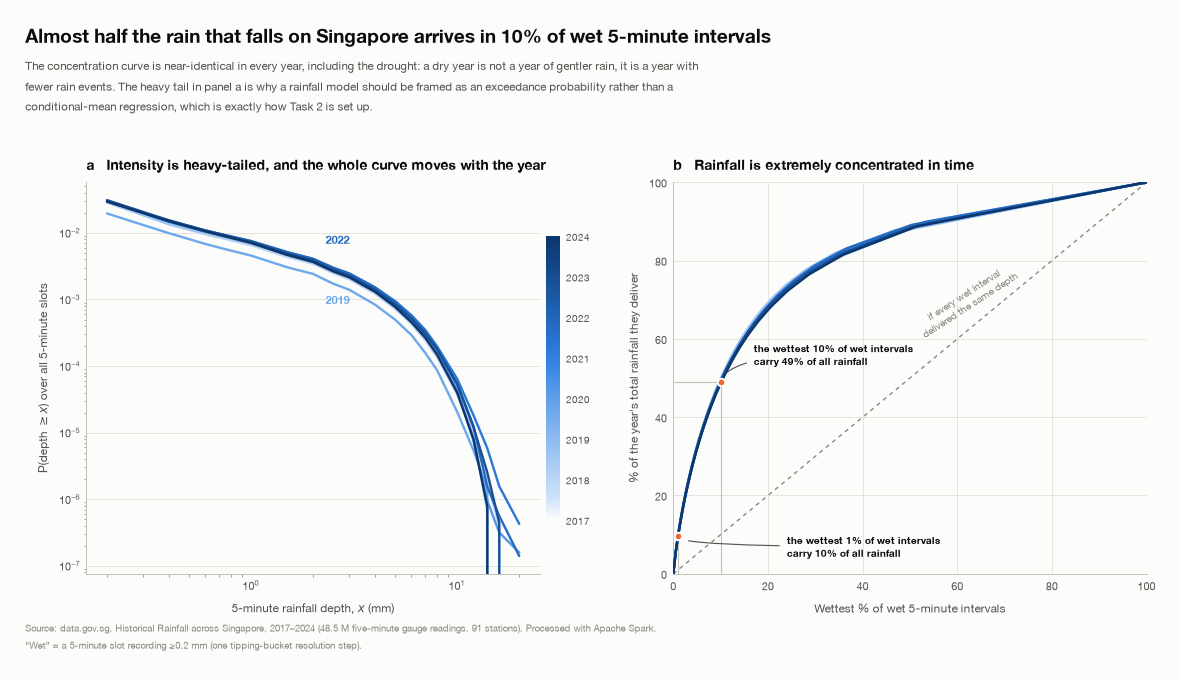

  [figure] outputs/figures/fig06_intensity.png


In [27]:
# --- 5.5 Intensity and concentration ---------------------------------------------------------------
section('5.5 Intensity and concentration', purpose='exceedance probabilities of 5-minute depths and the share of annual rain delivered by the wettest slots', writes='t12_intensity_exceedance, t13_rain_concentration, fig06')
wet = df.filter(F.col("rain_mm") >= WET_5MIN_MM)
grid = [0.2, 0.4, 0.6, 0.8, 1.0, 1.5, 2.0, 2.5, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 10.0, 12.0, 14.0, 16.0, 20.0]
with timed("5.5 intensity + concentration"):
    totals = {r["year"]: r["n"] for r in df.groupBy("year").agg(F.count(F.lit(1)).alias("n")).collect()}
    exc_raw = wet.groupBy("year").agg(*[F.sum((F.col("rain_mm") >= g).cast("long")).alias(f"ge_{i}")
                                        for i, g in enumerate(grid)]).toPandas()
    rows = []
    for _, r in exc_raw.iterrows():
        for i, g in enumerate(grid):
            rows.append({"year": int(r["year"]), "threshold_mm": g, "n_exceed": int(r[f"ge_{i}"]),
                         "n_slots": totals[int(r["year"])], "exceed_prob": r[f"ge_{i}"] / totals[int(r["year"])]})
    write_table(pd.DataFrame(rows), "t12_intensity_exceedance")

    # concentration (a Lorenz curve for rainfall): share of the year's rain in the wettest x % of wet slots
    qs = [i / 200 for i in range(201)]
    lorenz_rows = []
    for yr in sorted(totals):
        vals = np.sort(wet.filter(F.col("year") == yr).select("rain_mm").toPandas()["rain_mm"].to_numpy(float))
        cum = np.cumsum(vals)
        cum = cum / cum[-1]
        idx = (np.array(qs) * (len(vals) - 1)).astype(int)
        lorenz_rows += [{"year": yr, "frac_of_wet_intervals": q, "frac_of_rainfall": float(c)}
                        for q, c in zip(qs, cum[idx])]
    write_table(pd.DataFrame(lorenz_rows), "t13_rain_concentration")
lz = pd.DataFrame(lorenz_rows)
share = lambda q: 100 * (1 - lz[np.isclose(lz.frac_of_wet_intervals, q)].frac_of_rainfall.mean())
exc = T("t12_intensity_exceedance")
checkpoint("5.5 Intensity and concentration", [
    ("share of annual rain from the wettest 10 % of wet slots", f"{share(0.9):.0f} % (mean over years)"),
    ("share from the wettest 1 % of wet slots", f"{share(0.99):.0f} %"),
    ("P(5-min reading >= 5 mm | wet slot)", f"{100 * exc[exc.threshold_mm == 5.0].n_exceed.sum() / exc[exc.threshold_mm == 0.2].n_exceed.sum():.2f} %")])

def fig06_intensity() -> None:
    e = T("t12_intensity_exceedance")
    c = T("t13_rain_concentration")
    years = sorted(e["year"].unique())
    ramp = [BLUE_RAMP[i] for i in np.linspace(1, 12, len(years)).astype(int)]

    fig, axes = plt.subplots(1, 2, figsize=(13.2, 7.3),
                             gridspec_kw=dict(wspace=0.24))

    ax = axes[0]
    for yr, col in zip(years, ramp):
        s = e[e["year"] == yr].sort_values("threshold_mm")
        ax.plot(s["threshold_mm"], s["exceed_prob"], color=col, lw=1.9, zorder=3)
    for yr, dy in [(2019, -0.3), (2022, 0.4)]:
        s = e[e["year"] == yr].sort_values("threshold_mm")
        col = ramp[years.index(yr)]
        ax.annotate(str(yr), xy=(s["threshold_mm"].iloc[6], s["exceed_prob"].iloc[6]),
                    xytext=(10, 12 * (1 if dy > 0 else -2)), textcoords="offset points",
                    fontsize=8.6, color=col, fontweight="semibold")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("5-minute rainfall depth, $x$ (mm)")
    ax.set_ylabel("P(depth $\\geq x$) over all 5-minute slots")
    ax.set_title("a   Intensity is heavy-tailed, and the whole curve moves with the year")
    despine(ax)
    ax.grid(which="both", axis="x", visible=False)
    sm = plt.cm.ScalarMappable(cmap=CMAP_RAIN,
                               norm=plt.Normalize(years[0], years[-1]))
    cb = fig.colorbar(sm, ax=ax, pad=0.012, fraction=0.03, ticks=years)
    cb.outline.set_visible(False)
    cb.ax.tick_params(labelsize=8)

    ax = axes[1]
    for yr, col in zip(years, ramp):
        s = c[c["year"] == yr].sort_values("frac_of_wet_intervals")
        ax.plot(100 * (1 - s["frac_of_wet_intervals"]),
                100 * (1 - s["frac_of_rainfall"]), color=col, lw=1.9, zorder=3)
    ax.plot([0, 100], [0, 100], color=MUTED, lw=1.1, ls=(0, (3, 3)), zorder=2)
    ax.text(62, 70, "if every wet interval\ndelivered the same depth", fontsize=8,
            color=MUTED, rotation=33, ha="center", va="center", rotation_mode="anchor")
    s = c[c["year"] == 2022].set_index("frac_of_wet_intervals")["frac_of_rainfall"]
    # the two call-outs are placed by hand: the 1 % point sits on the diagonal
    # reference line, so its label goes into the empty region beneath it
    for q, lab, tx, ty in [(0.99, "1%", 24, 7), (0.90, "10%", 17, 56)]:
        xx, yy = 100 * (1 - q), 100 * (1 - s.loc[q])
        ax.plot([xx, xx], [0, yy], color=AXIS, lw=0.9, zorder=1)
        ax.plot([0, xx], [yy, yy], color=AXIS, lw=0.9, zorder=1)
        ax.plot(xx, yy, "o", color=ORANGE, markersize=6,
                markeredgecolor=SURFACE, markeredgewidth=1.6, zorder=5)
        ax.annotate(f"the wettest {lab} of wet intervals\ncarry {yy:.0f}% of all rainfall",
                    xy=(xx, yy), xytext=(tx, ty), fontsize=8.4, color=INK,
                    fontweight="semibold", ha="left", va="center", zorder=6,
                    arrowprops=dict(arrowstyle="-", shrinkA=4, shrinkB=9, color=INK_2, lw=0.9,
                                    connectionstyle="angle3,angleA=0,angleB=75"))
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 100)
    ax.set_xlabel("Wettest % of wet 5-minute intervals")
    ax.set_ylabel("% of the year's total rainfall they deliver")
    ax.set_title("b   Rainfall is extremely concentrated in time")
    despine(ax)

    layout(fig, header=1.95, footer=1.00, left=1.1)
    titleblock(fig,
                 "Almost half the rain that falls on Singapore arrives in 10% of wet 5-minute intervals",
                 "The concentration curve is near-identical in every year, including the drought: a dry year is not a year of gentler rain, it is "
                 "a year with\nfewer rain events. The heavy tail in panel a is why a rainfall model should be framed as an exceedance probability "
                 "rather than a\nconditional-mean regression, which is exactly how Task 2 is set up.")
    sourcenote(fig, SRC + "\n“Wet” = a 5-minute slot recording ≥0.2 mm (one tipping-bucket resolution step).")
    save_figure(fig, FIGURES / "fig06_intensity.png")


fig06_intensity()

Five-minute rainfall has a heavy tail. The wettest 10 % of wet 5-minute slots supply 49 % of a year's rain,
and the wettest 1 % supply 10 %. The concentration curve is similar across years, including the 2019 drought,
supporting the earlier finding that dry years have fewer events rather than consistently lighter rain.
For Task 2, we model the probability of exceeding a threshold to describe this uneven distribution.

### 5.6 Spatial pattern: where it rains more

08:00:22  5.6 Spatial pattern: station climatology and the Figure 7 map
Purpose : mean annual rainfall per gauge over a common window, interpolated on Singapore's land area
Writes  : t16_station_climatology, t17_station_year_totals, fig07


[08:00:23]  done: 5.6 station climatology  (1.1 s)
  [table] outputs/tables/t16_station_climatology.csv  (83 rows)
  [table] outputs/tables/t17_station_year_totals.csv  (390 rows)

-- 5.6 Spatial pattern (gauges with >= 300 usable days in each of 2021-2024) -------------------
   gauges             : 53
   wettest            : S228: 3,499 mm per year
   driest             : S208: 1,641 mm per year  (ratio 2.1x)
   west-east gradient : -247 mm per 10 km eastward (r = -0.63)



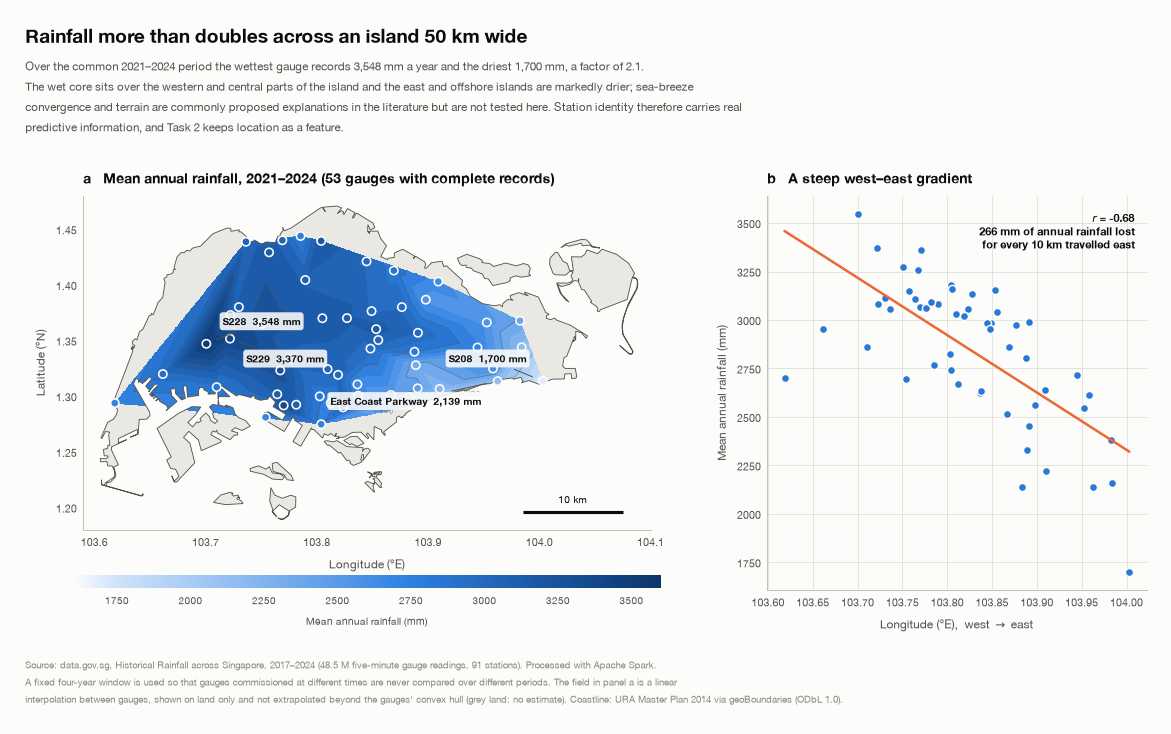

  [figure] outputs/figures/fig07_spatial_climatology.png


In [28]:
# --- 5.6 Spatial pattern: station climatology and the Figure 7 map ---------------------------------
section('5.6 Spatial pattern: station climatology and the Figure 7 map', purpose="mean annual rainfall per gauge over a common window, interpolated on Singapore's land area", writes='t16_station_climatology, t17_station_year_totals, fig07')
with timed("5.6 station climatology"):
    st_year = (station_day.filter(F.col("usable"))
               .groupBy("station_id", "year")
               .agg(F.count(F.lit(1)).alias("days"), F.sum("day_mm").alias("total_mm"),
                    F.avg("day_mm").alias("mean_daily_mm"))
               .filter(F.col("days") >= 300)
               .toPandas())
st_clim = st_year.groupby("station_id").agg(n_years=("year", "size"), mean_daily_mm=("mean_daily_mm", "mean")).reset_index()
st_clim["mean_annual_mm"] = st_clim["mean_daily_mm"] * 365.25
st_clim = st_clim.merge(stations, on="station_id", how="left")
write_table(st_clim.sort_values("mean_annual_mm", ascending=False), "t16_station_climatology")
write_table(st_year, "t17_station_year_totals")

COMMON = [2021, 2022, 2023, 2024]     # a fixed window, so gauges are compared over the same years
cp = st_year[st_year.year.isin(COMMON)].groupby("station_id").filter(lambda g: len(g) == len(COMMON))
cp = cp.groupby("station_id").total_mm.mean().rename("mm").reset_index().merge(stations, on="station_id")
x_km = (cp.lon - cp.lon.min()) * 111.320 * np.cos(np.radians(1.35))
slope_, r_ = np.polyfit(x_km, cp.mm, 1)[0], np.corrcoef(x_km, cp.mm)[0, 1]
checkpoint("5.6 Spatial pattern (gauges with >= 300 usable days in each of 2021-2024)", [
    ("gauges", len(cp)),
    ("wettest", f"{cp.loc[cp.mm.idxmax()].station_id}: {cp.mm.max():,.0f} mm per year"),
    ("driest", f"{cp.loc[cp.mm.idxmin()].station_id}: {cp.mm.min():,.0f} mm per year  (ratio {cp.mm.max() / cp.mm.min():.1f}x)"),
    ("west-east gradient", f"{10 * slope_:+.0f} mm per 10 km eastward (r = {r_:.2f})")])

# Singapore coastline for the map (reference/SOURCES.md); no analysis depends on it
from matplotlib.patches import PathPatch
from matplotlib.path import Path as MPath

BOUNDARY_FILE = ROOT / "reference" / "singapore_boundary.geojson"


def load_land(path):
    # Singapore's land polygons (main island and offshore islands) as one matplotlib Path
    verts, codes = [], []
    for f in json.loads(Path(path).read_text())["features"]:
        geom = f["geometry"]
        for poly in (geom["coordinates"] if geom["type"] == "MultiPolygon" else [geom["coordinates"]]):
            for ring in poly:
                r = np.asarray(ring)[:, :2]
                verts += list(r)
                codes += [MPath.MOVETO] + [MPath.LINETO] * (len(r) - 2) + [MPath.CLOSEPOLY]
    return MPath(verts, codes)


LAND = load_land(BOUNDARY_FILE)
LAND_GREY = "#e9e8e2"
MAP_X, MAP_Y = (103.59, 104.10), (1.18, 1.48)

def common_period_stations() -> pd.DataFrame:
    sy = T("t17_station_year_totals")
    st = T("t02_stations")
    sub = sy[sy["year"].isin(COMMON)]
    ok = sub.groupby("station_id").size()
    ok = ok[ok == len(COMMON)].index
    out = (sub[sub["station_id"].isin(ok)]
           .groupby("station_id")["mean_daily_mm"].mean()
           .mul(365.25).rename("mean_annual_mm").reset_index()
           .merge(st, on="station_id"))
    return out


def fig07_spatial() -> None:
    s = common_period_stations()
    fig = plt.figure(figsize=(13.2, 7.9))
    gs = fig.add_gridspec(1, 2, width_ratios=[1.55, 1], wspace=0.22)

    # -- (a) interpolated rainfall surface + gauges ------------------------
    ax = fig.add_subplot(gs[0, 0])
    lon, lat, val = (s["lon"].to_numpy(), s["lat"].to_numpy(),
                     s["mean_annual_mm"].to_numpy())
    tri = mtri.Triangulation(lon, lat)
    interp = mtri.LinearTriInterpolator(tri, val)
    gx, gy = np.meshgrid(np.linspace(*MAP_X, 700), np.linspace(*MAP_Y, 450))
    gz = interp(gx, gy)                       # masked outside the gauges' convex hull: no extrapolation
    ax.add_patch(PathPatch(LAND, fc=LAND_GREY, ec="none", zorder=0.6))
    land_clip = PathPatch(LAND, fc="none", ec="none")
    ax.add_patch(land_clip)
    cf = ax.contourf(gx, gy, gz, levels=np.arange(1600, 3700, 100), cmap=CMAP_RAIN,
                     extend="both", zorder=1)
    cf.set_clip_path(land_clip)               # the field is shown on land only
    cs = ax.contour(gx, gy, gz, levels=np.arange(2000, 3600, 400),
                    colors=[INK_2], linewidths=0.6, alpha=0.45, zorder=2)
    cs.set_clip_path(land_clip)
    ax.clabel(cs, fmt="%.0f", fontsize=7, colors=INK_2)
    ax.add_patch(PathPatch(LAND, fc="none", ec=INK_2, lw=0.7, zorder=3))      # coastline
    sc = ax.scatter(lon, lat, c=val, cmap=CMAP_RAIN, vmin=1600, vmax=3600,
                    s=44, edgecolor=SURFACE, linewidth=1.3, zorder=4)

    # label the extremes, pushing each label away from the plot edge it sits on
    marks = pd.concat([s.nlargest(2, "mean_annual_mm"), s.nsmallest(2, "mean_annual_mm")])
    for k, (_, r) in enumerate(marks.iterrows()):
        east = r["lon"] > np.median(lon)
        dy = 15 if k % 2 == 0 else -19          # stagger so adjacent gauges never overlap
        ax.annotate(f"{r['station_name']}  {r['mean_annual_mm']:,.0f} mm",
                    xy=(r["lon"], r["lat"]),
                    xytext=(-13 if east else 13, dy), textcoords="offset points",
                    ha="right" if east else "left", fontsize=8,
                    color=INK, fontweight="semibold", zorder=6,
                    bbox=dict(boxstyle="round,pad=0.3", fc=SURFACE, ec="none",
                              alpha=0.88),
                    arrowprops=dict(arrowstyle="-", shrinkA=4, shrinkB=9, color=INK_2, lw=0.8))
    ax.set_xlim(*MAP_X)
    ax.set_ylim(*MAP_Y)
    km_deg = 10 / (111.320 * np.cos(np.radians(1.35)))      # 10 km in degrees of longitude
    x0, y0 = MAP_X[1] - 0.025 - km_deg, MAP_Y[0] + 0.016       # bottom-right, open sea
    ax.plot([x0, x0 + km_deg], [y0, y0], color=INK, lw=2.5, solid_capstyle="butt", zorder=6)
    ax.text(x0 + km_deg / 2, y0 + 0.006, "10 km", ha="center", va="bottom", fontsize=8, color=INK, zorder=6)
    ax.set_aspect(1 / np.cos(np.radians(1.35)))
    ax.set_xlabel("Longitude (\u00b0E)")
    ax.set_ylabel("Latitude (\u00b0N)")
    ax.set_title(f"a   Mean annual rainfall, {COMMON[0]}\u2013{COMMON[-1]} "
                 f"({len(s)} gauges with complete records)")
    ax.grid(False)
    cb = fig.colorbar(sc, ax=ax, orientation="horizontal", pad=0.115,
                      fraction=0.038, aspect=44)
    cb.outline.set_visible(False)
    cb.ax.tick_params(labelsize=8)
    cb.set_label("Mean annual rainfall (mm)", fontsize=8.2)

    # -- (b) the west-east gradient ---------------------------------------
    ax = fig.add_subplot(gs[0, 1])
    ax.scatter(lon, val, s=42, color=BLUE, edgecolor=SURFACE, linewidth=1.2,
               zorder=3)
    slope, intercept = np.polyfit(lon, val, 1)
    xs = np.linspace(lon.min(), lon.max(), 50)
    ax.plot(xs, intercept + slope * xs, color=ORANGE, lw=2, zorder=4)
    r = np.corrcoef(lon, val)[0, 1]
    km_per_deg = 111.32 * np.cos(np.radians(float(np.mean(lat))))
    per_10km = slope * 10.0 / km_per_deg          # mm per 10 km of easting
    ax.annotate(f"$r$ = {r:.2f}\n{-per_10km:,.0f} mm of annual rainfall lost\n"
                f"for every 10 km travelled east",
                xy=(0.97, 0.96), xycoords="axes fraction", ha="right", va="top",
                fontsize=8.6, color=INK, fontweight="semibold")
    ax.set_xlabel("Longitude (\u00b0E),  west $\\rightarrow$ east")
    ax.set_ylabel("Mean annual rainfall (mm)")
    ax.set_title("b   A steep west\u2013east gradient")
    despine(ax)

    layout(fig, header=2.10, footer=1.42, left=0.95)
    titleblock(fig,
                 "Rainfall more than doubles across an island 50 km wide",
                 f"Over the common {COMMON[0]}\u2013{COMMON[-1]} period the wettest gauge records {val.max():,.0f} mm a year "
                 f"and the driest {val.min():,.0f} mm, a factor of {val.max() / val.min():.1f}.\n"
                 "The wet core sits over the western and central parts of the island and the east and offshore islands are markedly drier; sea-breeze\n"
                 "convergence and terrain are commonly proposed explanations in the literature but are not tested here. Station identity therefore carries "
                 "real\npredictive information, and Task 2 keeps location as a feature.")
    sourcenote(fig, SRC + "\nA fixed four-year window is used so that gauges commissioned at different times are never compared over different periods. "
                            "The field in panel a is a linear\ninterpolation between gauges, shown on land only and not extrapolated beyond the gauges' convex hull (grey land: no estimate). "
                            "Coastline: URA Master Plan 2014 via geoBoundaries (ODbL 1.0).")
    save_figure(fig, FIGURES / "fig07_spatial_climatology.png")


fig07_spatial()

Among the 53 gauges with complete records in the common 2021–24 window, average annual rainfall ranges from
1,700 mm to 3,548 mm. This is a factor of 2.1 across an island about 50 km wide. The west–east gradient is about
266 mm less rain per 10 km travelled east (r = −0.68), supporting the use of station coordinates in Task 2.

### 5.7 Spatial coherence: how far a storm reaches

We calculate Pearson correlations of concurrent 30-minute totals for every gauge pair with at least four
complete years, using a Spark pivot with one row per half-hour and one column per station.

08:00:24  5.7 Spatial coherence
Purpose : correlation of concurrent 30-minute totals for every gauge pair, against distance
Writes  : t18_pair_correlation, fig08


[08:00:28]  done: 5.7 spatial coherence  (3.7 s)
half-hour x station matrix: (135886, 66)


  [table] outputs/tables/t18_pair_correlation.csv  (2145 rows)

-- 5.7 Spatial coherence (30-min totals) -------------------------------------------------------
   gauge pairs                                                      : 2,145
   mean correlation, pairs < 2 km apart                             : 0.84
   mean correlation, pairs > 20 km apart                            : 0.15
   distance where the 2-km-binned correlation first drops below 1/e : about 9 km



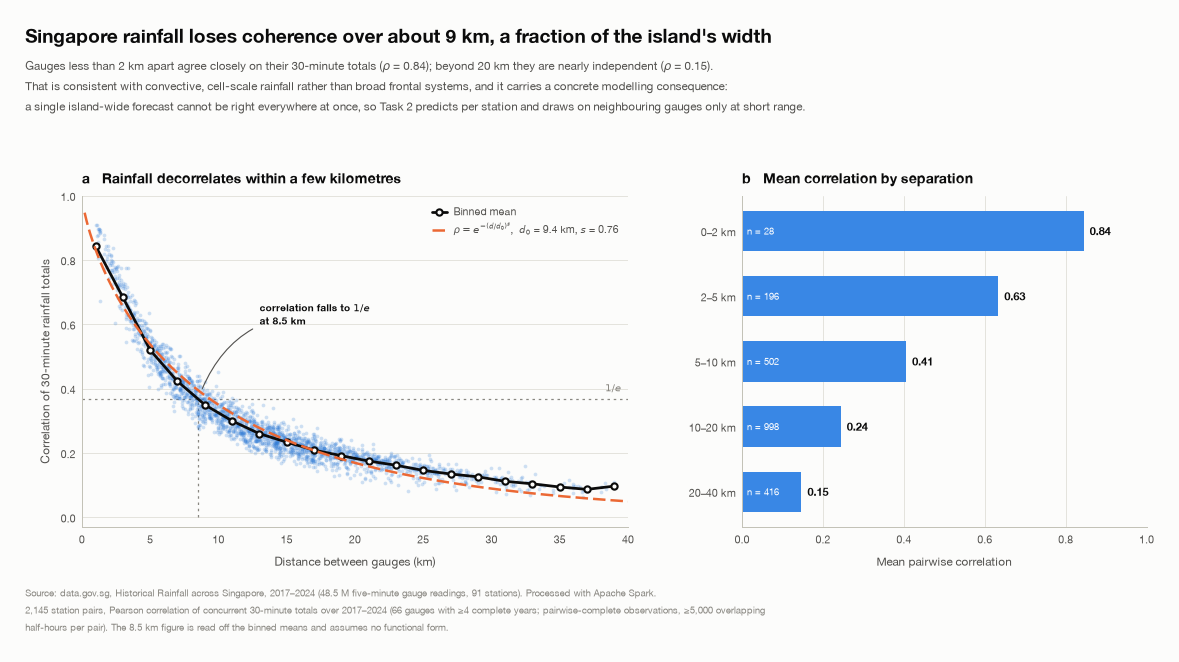

  [figure] outputs/figures/fig08_spatial_coherence.png


In [29]:
# --- 5.7 Spatial coherence -------------------------------------------------------------------------
section('5.7 Spatial coherence', purpose='correlation of concurrent 30-minute totals for every gauge pair, against distance', writes='t18_pair_correlation, fig08')
hh = (df.withColumn("slot", (F.unix_timestamp("ts") / F.lit(1800)).cast("long"))
      .groupBy("slot", "station_id").agg(F.sum("rain_mm").alias("mm30")))
keep_ids = st_clim[st_clim["n_years"] >= 4]["station_id"].tolist()
with timed("5.7 spatial coherence"):
    wide = (hh.filter(F.col("station_id").isin(keep_ids))
            .groupBy("slot").pivot("station_id", keep_ids).agg(F.first("mm30"))
            .toPandas().set_index("slot").sort_index())
print(f"half-hour x station matrix: {wide.shape}")
corr = wide.corr(min_periods=5000)
st_meta = st_clim.set_index("station_id")
pair_rows = []
ids = list(corr.columns)
for i in range(len(ids)):
    for j in range(i + 1, len(ids)):
        a, b = ids[i], ids[j]
        dlat = (st_meta.loc[b, "lat"] - st_meta.loc[a, "lat"]) * 110.574          # equirectangular is fine at this scale
        dlon = (st_meta.loc[b, "lon"] - st_meta.loc[a, "lon"]) * 111.320 * np.cos(np.radians(st_meta.loc[a, "lat"]))
        pair_rows.append({"a": a, "b": b, "distance_km": float(np.hypot(dlat, dlon)), "corr": float(corr.loc[a, b])})
write_table(pd.DataFrame(pair_rows).dropna(), "t18_pair_correlation")
pc = pd.DataFrame(pair_rows).dropna()
bins_ = pc.groupby(pd.cut(pc.distance_km, np.arange(0, 41, 2)), observed=True)["corr"].mean()
first_below = next((iv.mid for iv, v in bins_.items() if v < np.exp(-1)), float("nan"))
checkpoint("5.7 Spatial coherence (30-min totals)", [("gauge pairs", f"{len(pc):,}"),
    ("mean correlation, pairs < 2 km apart", f"{pc[pc.distance_km < 2]['corr'].mean():.2f}"),
    ("mean correlation, pairs > 20 km apart", f"{pc[pc.distance_km > 20]['corr'].mean():.2f}"),
    ("distance where the 2-km-binned correlation first drops below 1/e", f"about {first_below:.0f} km")])

def fig08_coherence() -> None:
    p = T("t18_pair_correlation").dropna()
    fig, axes = plt.subplots(1, 2, figsize=(13.2, 7.1),
                             gridspec_kw=dict(width_ratios=[1.35, 1], wspace=0.24))

    bins = np.arange(0, 42, 2)
    p["bin"] = pd.cut(p["distance_km"], bins)
    binned = p.groupby("bin", observed=True)["corr"].mean()
    centres = np.array([iv.mid for iv in binned.index])

    # A plain exponential fits this correlogram badly (it is dominated by the
    # many long-range pairs and sits above the data from 3 to 30 km). A
    # stretched exponential, the standard form for convective rainfall fields,
    # reduces the RMSE against the binned means by a factor of five.
    d, r = p["distance_km"].to_numpy(), p["corr"].to_numpy()
    m = (r > 0.01) & (r < 0.999) & (d > 0)
    shape, c = np.polyfit(np.log(d[m]), np.log(-np.log(r[m])), 1)
    d0 = np.exp(-c / shape)
    # model-free decorrelation distance: where the binned mean crosses 1/e
    d_emp = float(np.interp(np.exp(-1), binned.values[::-1], centres[::-1]))

    ax = axes[0]
    ax.scatter(d, r, s=9, color=BLUE, alpha=0.22, linewidth=0, zorder=2)
    ax.plot(centres, binned.values, color=INK, lw=2.2, marker="o", markersize=5,
            markerfacecolor=SURFACE, markeredgewidth=1.7, zorder=4,
            label="Binned mean")
    xs = np.linspace(0.2, 40, 300)
    ax.plot(xs, np.exp(-(xs / d0) ** shape), color=ORANGE, lw=2, ls=(0, (5, 2)),
            zorder=5,
            label=f"$\\rho = e^{{-(d/d_0)^s}}$,  $d_0$ = {d0:.1f} km, $s$ = {shape:.2f}")
    ax.axhline(np.exp(-1), color=MUTED, lw=1, ls=(0, (2, 3)), zorder=1)
    ax.text(39.5, np.exp(-1) + 0.022, "$1/e$", ha="right", fontsize=8, color=MUTED)
    ax.plot([d_emp, d_emp], [0, np.exp(-1)], color=MUTED, lw=1, ls=(0, (2, 3)),
            zorder=1)
    ax.annotate(f"correlation falls to $1/e$\nat {d_emp:.1f} km",
                xy=(d_emp, np.exp(-1)), xytext=(d_emp + 4.5, 0.60),
                fontsize=8.4, color=INK, fontweight="semibold", zorder=6,
                arrowprops=dict(arrowstyle="-", shrinkA=4, shrinkB=9, color=INK_2, lw=0.9,
                                connectionstyle="angle3,angleA=0,angleB=70"))
    ax.set_xlim(0, 40)
    ax.set_ylim(-0.03, 1.0)
    ax.set_xlabel("Distance between gauges (km)")
    ax.set_ylabel("Correlation of 30-minute rainfall totals")
    ax.set_title("a   Rainfall decorrelates within a few kilometres")
    ax.legend(loc="upper right", fontsize=8.4)
    despine(ax)
    ax.grid(axis="x", visible=False)

    ax = axes[1]
    rows = []
    for lo, hi in [(0, 2), (2, 5), (5, 10), (10, 20), (20, 40)]:
        sel = p[(p["distance_km"] >= lo) & (p["distance_km"] < hi)]
        rows.append((f"{lo}\u2013{hi} km", sel["corr"].mean(), len(sel)))
    ypos = np.arange(len(rows))
    val = [x[1] for x in rows]
    ax.barh(ypos, val, color=BLUE_RAMP[6], height=0.62, zorder=2)
    for i, (v, n) in enumerate(zip(val, [x[2] for x in rows])):
        ax.text(v + 0.015, i, f"{v:.2f}", va="center", fontsize=8.6,
                color=INK, fontweight="semibold")
        ax.text(0.012, i, f"n = {n:,}", va="center", fontsize=7.6, color="white")
    ax.set_yticks(ypos, [x[0] for x in rows])
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set_xlabel("Mean pairwise correlation")
    ax.set_title("b   Mean correlation by separation")
    despine(ax)
    ax.grid(axis="y", visible=False)

    layout(fig, header=2.10, footer=1.32, left=1.05)
    titleblock(fig,
                 f"Singapore rainfall loses coherence over about {d_emp:.0f} km, a fraction of the island's width",
                 "Gauges less than 2 km apart agree closely on their 30-minute totals ($\\rho$ = 0.84); beyond 20 km they are nearly independent "
                 "($\\rho$ = 0.15).\nThat is consistent with convective, cell-scale rainfall rather than broad frontal systems, and it carries a "
                 "concrete modelling consequence:\na single island-wide forecast cannot be right everywhere at once, so Task 2 predicts per station "
                 "and draws on neighbouring gauges only at short range.")
    sourcenote(fig, SRC + f"\n{len(p):,} station pairs, Pearson correlation of concurrent 30-minute totals over 2017\u20132024 "
                            f"(66 gauges with \u22654 complete years; pairwise-complete observations, \u22655,000 overlapping\nhalf-hours per pair). "
                            f"The {d_emp:.1f} km figure is read off the binned means and assumes no functional form.")
    save_figure(fig, FIGURES / "fig08_spatial_coherence.png")


fig08_coherence()

Gauges less than 2 km apart have a correlation of ρ = 0.84 in their 30-minute totals. Beyond 20 km, this falls
to ρ = 0.15. The correlation reaches 1/e at about 8.5 km, consistent with rainfall from small convective cells
rather than systems covering the whole island. Task 2 therefore predicts for each station and uses neighbours
within 10 km instead of assigning one forecast to the island.

### 5.8 Rain events: duration, depth and start time

We define an event as a maximal run of wet slots at one gauge, allowing dry gaps of no more than 30 minutes.
A `lag` window identifies the breaks, and a running sum assigns event ids.

08:00:29  5.8 Rain events
Purpose : a lag window and a running sum assign event ids; events summarised per year, hour and season
Writes  : t19_event_summary_annual, t20_event_sample, t21_event_by_hour_season, fig09


[08:00:30]  done: 5.8 rain events  (1.7 s)
  [table] outputs/tables/t19_event_summary_annual.csv  (8 rows)
  [table] outputs/tables/t20_event_sample.csv  (24476 rows)
  [table] outputs/tables/t21_event_by_hour_season.csv  (96 rows)


,year,n_events,stations,mean_depth_mm,median_depth_mm,mean_duration_min,median_duration_min,mean_rate_mm_h,p99_depth_mm,events_per_station
5,2017,23350,58,5.3,0.8,45.0,20.0,5.7,53.8,402.6
7,2018,20963,56,5.4,0.8,44.6,20.0,5.7,57.4,374.3
6,2019,14087,53,5.8,1.0,46.2,20.0,6.1,54.0,265.8
3,2020,29169,80,5.7,0.8,44.4,20.0,5.9,55.4,364.6
2,2021,28223,74,6.9,1.0,49.2,20.0,6.5,71.6,381.4
4,2022,31440,72,6.2,1.0,46.4,20.0,6.1,62.5,436.7
0,2023,30051,73,6.0,0.8,47.8,20.0,6.0,60.2,411.7
1,2024,27762,70,5.9,1.0,46.1,20.0,6.2,58.3,396.6



-- 5.8 Rain events -----------------------------------------------------------------------------
   events (all gauges, 2017-2024)         : 205,045
   median duration / depth (12 % sample)  : 20 min / 1.0 mm
   events per gauge: fewest / most        : 2019 266 / 2022 437
   start hour with most events, by season : Inter-monsoon (Apr-May): 15:00, Inter-monsoon (Oct-Nov): 14:00, NE Monsoon (Dec-Mar): 15:00, SW Monsoon (Jun-Sep): 12:00



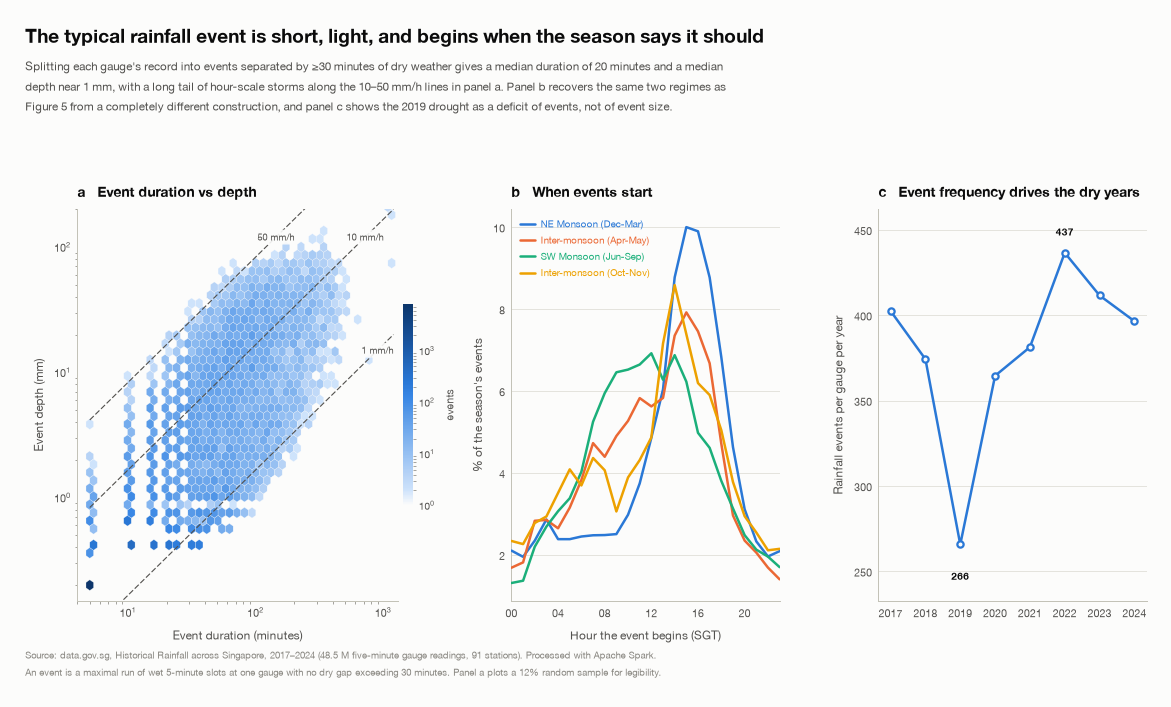

  [figure] outputs/figures/fig09_events.png


In [30]:
# --- 5.8 Rain events -------------------------------------------------------------------------------
section('5.8 Rain events', purpose='a lag window and a running sum assign event ids; events summarised per year, hour and season', writes='t19_event_summary_annual, t20_event_sample, t21_event_by_hour_season, fig09')
wv = Window.partitionBy("station_id").orderBy(F.col("ts").cast("long"))
ev = (df.filter(F.col("rain_mm") >= WET_5MIN_MM).select("station_id", "ts", "year", "season", "rain_mm")
      .withColumn("prev_ts", F.lag("ts").over(wv))
      .withColumn("gap_min", (F.unix_timestamp("ts") - F.unix_timestamp("prev_ts")) / 60)
      .withColumn("new_event", ((F.col("gap_min") > EVENT_GAP_MIN) | F.col("gap_min").isNull()).cast("int"))
      .withColumn("event_id", F.sum("new_event").over(wv.rowsBetween(Window.unboundedPreceding, Window.currentRow))))
events = (ev.groupBy("station_id", "event_id")
          .agg(F.min("ts").alias("start_ts"), F.max("ts").alias("end_ts"), F.sum("rain_mm").alias("depth_mm"),
               F.max("rain_mm").alias("peak_5min_mm"), F.count(F.lit(1)).alias("wet_slots"),
               F.first("year").alias("year"), F.first("season").alias("season"))
          .withColumn("duration_min", (F.unix_timestamp("end_ts") - F.unix_timestamp("start_ts")) / 60 + 5)
          .withColumn("mean_rate_mm_h", F.col("depth_mm") / (F.col("duration_min") / 60))
          .withColumn("start_hour", F.hour("start_ts")))
events.cache()
with timed("5.8 rain events"):
    ev_summary = (events.groupBy("year")
                  .agg(F.count(F.lit(1)).alias("n_events"), F.countDistinct("station_id").alias("stations"),
                       F.avg("depth_mm").alias("mean_depth_mm"),
                       F.expr("percentile_approx(depth_mm, 0.5)").alias("median_depth_mm"),
                       F.avg("duration_min").alias("mean_duration_min"),
                       F.expr("percentile_approx(duration_min, 0.5)").alias("median_duration_min"),
                       F.avg("mean_rate_mm_h").alias("mean_rate_mm_h"),
                       F.expr("percentile_approx(depth_mm, 0.99)").alias("p99_depth_mm"))
                  .toPandas().sort_values("year"))
    ev_summary["events_per_station"] = ev_summary["n_events"] / ev_summary["stations"]
    ev_sample = (events.select("duration_min", "depth_mm", "peak_5min_mm", "season", "start_hour", "year")
                 .sample(False, 0.12, seed=5208).toPandas())
    ev_hour = (events.groupBy("season", "start_hour")
               .agg(F.count(F.lit(1)).alias("n_events"), F.avg("depth_mm").alias("mean_depth_mm"),
                    F.avg("duration_min").alias("mean_duration_min"))
               .toPandas())
write_table(ev_summary, "t19_event_summary_annual")
write_table(ev_sample, "t20_event_sample")
write_table(ev_hour, "t21_event_by_hour_season")
display(ev_summary.round(1))
checkpoint("5.8 Rain events", [("events (all gauges, 2017-2024)", f"{int(ev_summary.n_events.sum()):,}"),
    ("median duration / depth (12 % sample)", f"{ev_sample.duration_min.median():.0f} min / {ev_sample.depth_mm.median():.1f} mm"),
    ("events per gauge: fewest / most", f"{int(ev_summary.loc[ev_summary.events_per_station.idxmin()].year)} {ev_summary.events_per_station.min():.0f} / {int(ev_summary.loc[ev_summary.events_per_station.idxmax()].year)} {ev_summary.events_per_station.max():.0f}"),
    ("start hour with most events, by season", ", ".join(f"{s}: {int(g.loc[g.n_events.idxmax()].start_hour):02d}:00" for s, g in ev_hour.groupby("season")))])

def fig09_events() -> None:
    ev = T("t20_event_sample")
    eh = T("t21_event_by_hour_season")
    ea = T("t19_event_summary_annual")

    fig = plt.figure(figsize=(13.2, 7.6))
    gs = fig.add_gridspec(1, 3, width_ratios=[1.25, 1, 1], wspace=0.34)

    ax = fig.add_subplot(gs[0, 0])
    hb = ax.hexbin(ev["duration_min"], ev["depth_mm"], gridsize=42, bins="log",
                   xscale="log", yscale="log", cmap=CMAP_RAIN, mincnt=1,
                   linewidths=0.2, edgecolors=SURFACE)
    xs = np.array([5, 1200])
    for rate in (1, 10, 50):
        ax.plot(xs, rate * xs / 60, color=INK_2, lw=0.9, ls=(0, (5, 2)), zorder=4)
        # anchor each label where its line is still inside the visible box
        x_lab = min(900.0, 120.0 * 60.0 / rate)
        ax.text(x_lab, rate * x_lab / 60, f"{rate} mm/h", fontsize=7.4,
                color=INK_2, va="center", ha="center", zorder=5, rotation=0,
                bbox=dict(boxstyle="round,pad=0.22", fc=SURFACE, ec="none", alpha=0.9))
    ax.set_xlim(4, 1300)
    ax.set_ylim(0.15, 200)
    ax.set_xlabel("Event duration (minutes)")
    ax.set_ylabel("Event depth (mm)")
    ax.set_title("a   Event duration vs depth")
    despine(ax)
    ax.grid(which="both", visible=False)
    cb = fig.colorbar(hb, ax=ax, pad=0.014, fraction=0.03)
    cb.outline.set_visible(False)
    cb.ax.tick_params(labelsize=8)
    cb.set_label("events", fontsize=8.2)

    ax = fig.add_subplot(gs[0, 1])
    for name in SEASON_ORDER:
        s = eh[eh["season"] == name].sort_values("start_hour")
        share = 100 * s["n_events"] / s["n_events"].sum()
        ax.plot(s["start_hour"], share, color=SEASON_COLOR[name], zorder=3,
                label=name.split(" (")[0] + name[name.find(" ("):])
    ax.set_xlim(0, 23)
    ax.set_xticks(range(0, 24, 4), [f"{h:02d}" for h in range(0, 24, 4)])
    ax.set_xlabel("Hour the event begins (SGT)")
    ax.set_ylabel("% of the season's events")
    ax.set_title("b   When events start")
    ax.legend(loc="upper left", fontsize=7.8, ncol=1, labelcolor="linecolor")
    despine(ax)
    ax.grid(axis="x", visible=False)

    ax = fig.add_subplot(gs[0, 2])
    ax.plot(ea["year"], ea["events_per_station"], color=BLUE, marker="o",
            markersize=5, markerfacecolor=SURFACE, markeredgewidth=1.8, zorder=3)
    for _, r in ea.iterrows():
        if r["year"] in (2019, 2022):
            high = r["year"] == 2022
            ax.annotate(f"{r['events_per_station']:.0f}",
                        (r["year"], r["events_per_station"]),
                        textcoords="offset points",
                        xytext=(0, 12 if high else -20), ha="center",
                        va="bottom" if high else "top",
                        fontsize=8.4, color=INK, fontweight="semibold")
    ax.set_ylabel("Rainfall events per gauge per year")
    ax.set_xticks(ea["year"])
    ax.set_title("c   Event frequency drives the dry years")
    despine(ax)
    ax.grid(axis="x", visible=False)
    pad_ylim(ax)

    med_d = ea["median_duration_min"].median()
    layout(fig, header=2.25, footer=1.00, left=1.0)
    titleblock(fig,
                 "The typical rainfall event is short, light, and begins when the season says it should",
                 f"Splitting each gauge's record into events separated by ≥30 minutes of dry weather gives a median duration of "
                 f"{med_d:.0f} minutes and a median\ndepth near 1 mm, with a long tail of hour-scale storms along the 10–50 mm/h lines in panel a. "
                 "Panel b recovers the same two regimes as\nFigure 5 from a completely different construction, and panel c shows the 2019 drought as a "
                 "deficit of events, not of event size.")
    sourcenote(fig, SRC + "\nAn event is a maximal run of wet 5-minute slots at one gauge with no dry gap exceeding 30 minutes. Panel a plots a 12% random sample for legibility.")
    save_figure(fig, FIGURES / "fig09_events.png")


fig09_events()

The median event lasts 20 minutes and delivers about 1 mm, though the distribution extends to storms lasting
hours. Event start times show the same two daily regimes as Figure 5, using a separate construction. There
are 266 events per gauge in the 2019 drought, compared with about 400 in other years, again pointing to fewer
events rather than smaller ones.

### 5.9 Extremes, heavy half-hours and the Task 2 base rate

Trailing 30- and 60-minute accumulations give the annual maxima and the frequency of 30-minute totals crossing
5, 10 and 20 mm. We calculate these for all gauges and for the fixed network.

The forward 30-minute window from Section 4.3 gives the Task 2 outcome. We use it to estimate the base rate
P(next 30 min > h) by hour and season.

In [31]:
# --- 5.9 Extremes, heavy half-hours and the Task 2 base rate ---------------------------------------
section('5.9 Extremes, heavy half-hours and the Task 2 base rate', purpose='trailing 30/60-min maxima and heavy-half-hour rates (all gauges and fixed network); the forward 30-min base rate', writes='t14_extremes_annual, t15_base_rates_30min')
w30 = Window.partitionBy("station_id").orderBy(F.col("ts").cast("long")).rangeBetween(-1500, 0)   # 6 slots
w60 = Window.partitionBy("station_id").orderBy(F.col("ts").cast("long")).rangeBetween(-3300, 0)   # 12 slots
roll = (df.select("station_id", "ts", "year", "rain_mm", "season")
        .withColumn("acc30", F.sum("rain_mm").over(w30))
        .withColumn("acc60", F.sum("rain_mm").over(w60)))
roll.cache()
with timed("5.9 extremes + base rates"):
    extremes = (roll.groupBy("year")
                .agg(F.max("acc30").alias("max_30min_mm"), F.max("acc60").alias("max_60min_mm"),
                     F.sum((F.col("acc30") >= 5).cast("long")).alias("n_acc30_ge5"),
                     F.sum((F.col("acc30") >= 10).cast("long")).alias("n_acc30_ge10"),
                     F.sum((F.col("acc30") >= 20).cast("long")).alias("n_acc30_ge20"),
                     F.count(F.lit(1)).alias("n_slots"),
                     F.expr("percentile_approx(acc30, 0.9999, 1000000)").alias("p9999_30min_mm"))
                .toPandas().sort_values("year"))
    extremes_fixed = (roll.filter(F.col("station_id").isin(cohort)).groupBy("year")
                      .agg(F.sum((F.col("acc30") >= 5).cast("long")).alias("n_acc30_ge5_fixed"),
                           F.sum((F.col("acc30") >= 10).cast("long")).alias("n_acc30_ge10_fixed"),
                           F.sum((F.col("acc30") >= 20).cast("long")).alias("n_acc30_ge20_fixed"),
                           F.count(F.lit(1)).alias("n_slots_fixed"))
                      .toPandas())
    extremes = extremes.merge(extremes_fixed, on="year", how="left")
    for c in ["n_acc30_ge5", "n_acc30_ge10", "n_acc30_ge20"]:
        extremes[c.replace("n_", "rate_")] = extremes[c] / extremes["n_slots"]
        extremes[c.replace("n_", "rate_") + "_fixed"] = extremes[c + "_fixed"] / extremes["n_slots_fixed"]
    write_table(extremes, "t14_extremes_annual")

    # forward window: P(rain in the NEXT 30 min > h) by hour of the prediction time and season (strict ">")
    fwd = add_time_features(add_future_target(df.select("station_id", "ts", "rain_mm")))
    fwd = fwd.filter(F.col("future_30min_mm").isNotNull())
    base_rates = (fwd.groupBy("season", "hour")
                  .agg(*[F.avg((F.col("future_30min_mm") > h).cast("double")).alias(name)
                         for name, h in [("p_gt_0p2", 0.2), ("p_gt_1", 1.0), ("p_gt_5", 5.0),
                                         ("p_gt_10", 10.0), ("p_gt_20", 20.0)]],
                       F.count(F.lit(1)).alias("n"))
                  .toPandas())
write_table(base_rates, "t15_base_rates_30min")
early, late = extremes[extremes.year <= 2019], extremes[extremes.year >= 2020]
rate = lambda d, c: d[c.replace("rate_", "n_")].sum() / d["n_slots" + ("_fixed" if c.endswith("_fixed") else "")].sum()
p5 = (base_rates.p_gt_5 * base_rates.n).sum() / base_rates.n.sum()
checkpoint("5.9 Extremes and the Task 2 base rate", [
    ("heavy half-hours (>= 5 mm): 2020-24 vs 2017-19, all gauges", f"{100 * (rate(late, 'rate_acc30_ge5') / rate(early, 'rate_acc30_ge5') - 1):+.0f} %"),
    ("same, fixed network", f"{100 * (rate(late, 'rate_acc30_ge5_fixed') / rate(early, 'rate_acc30_ge5_fixed') - 1):+.0f} %"),
    ("largest 30-min / 60-min total", f"{extremes.max_30min_mm.max():.1f} mm ({int(extremes.loc[extremes.max_30min_mm.idxmax()].year)}) / {extremes.max_60min_mm.max():.1f} mm"),
    ("P(next 30 min > 5 mm), all prediction times", f"{100 * p5:.2f} %"),
    ("same, by season x hour: min-max", f"{100 * base_rates.p_gt_5.min():.2f}-{100 * base_rates.p_gt_5.max():.2f} %")])
extremes[["year", "max_30min_mm", "max_60min_mm", "rate_acc30_ge5", "rate_acc30_ge5_fixed"]].round(5)

08:00:31  5.9 Extremes, heavy half-hours and the Task 2 base rate
Purpose : trailing 30/60-min maxima and heavy-half-hour rates (all gauges and fixed network); the forward 30-min base rate
Writes  : t14_extremes_annual, t15_base_rates_30min


  [table] outputs/tables/t14_extremes_annual.csv  (8 rows)


[08:00:53]  done: 5.9 extremes + base rates  (21.8 s)
  [table] outputs/tables/t15_base_rates_30min.csv  (96 rows)

-- 5.9 Extremes and the Task 2 base rate -------------------------------------------------------
   heavy half-hours (>= 5 mm): 2020-24 vs 2017-19, all gauges : +24 %
   same, fixed network                                        : +20 %
   largest 30-min / 60-min total                              : 71.8 mm (2018) / 107.0 mm
   P(next 30 min > 5 mm), all prediction times                : 0.83 %
   same, by season x hour: min-max                            : 0.13-3.07 %



,year,max_30min_mm,max_60min_mm,rate_acc30_ge5,rate_acc30_ge5_fixed
0,2017,71.60001,92.00000,0.00783,0.00791
1,2018,71.80000,102.39999,0.00829,0.00815
2,2019,63.80000,90.20000,0.00560,0.00558
3,2020,67.80000,107.00000,0.00872,0.00857
4,2021,67.60000,98.59999,0.00911,0.00895
5,2022,65.93400,101.79600,0.00927,0.00877
6,2023,70.23800,100.89100,0.00895,0.00865
7,2024,65.00000,103.01999,0.00853,0.00820


### 5.10 Trend tests

There are only eight annual values, so an apparent trend may reflect year-to-year variation. For each series,
we compute a Mann–Kendall test with an exact two-sided p-value from all 8! = 40,320 orderings. Sen's slope,
the median of the pairwise slopes, gives the estimated rate of change.

In [32]:
# --- 5.10 Trend tests ------------------------------------------------------------------------------
section('5.10 Trend tests', purpose="exact Mann-Kendall test and Sen's slope for each annual series", writes='t39_trend_tests')
ext, evs, yr = extremes.set_index("year"), ev_summary.set_index("year"), annual.set_index("year")
series = {
    "annual rainfall, gap-filled (mm)": yr["gapfilled_total_mm"],
    "wet days per year (>= 1 mm, scaled)": yr["wet_days_scaled"],
    "intensity (mm per wet day)": yr["gapfilled_total_mm"] / yr["wet_days_scaled"],
    "rain events per gauge": evs["events_per_station"],
    "30-min totals >= 5 mm, rate (all gauges)": ext["rate_acc30_ge5"],
    "30-min totals >= 5 mm, rate (fixed network)": ext["rate_acc30_ge5_fixed"],
    "annual max 30-min depth (mm, any gauge)": ext["max_30min_mm"],
    "annual max 60-min depth (mm, any gauge)": ext["max_60min_mm"],
}
trend_rows = []
for name, s in series.items():
    s = s.sort_index()
    r = mann_kendall(s.index, s.to_numpy())
    r["sen_slope_pct_of_mean_per_year"] = 100 * r["sen_slope_per_year"] / s.mean()
    trend_rows.append({"metric": name, "n_years": len(s), **r})
trends = write_table(pd.DataFrame(trend_rows), "t39_trend_tests")
sig = trends[trends.p_value_exact < 0.05]
closest = trends.loc[trends.p_value_exact.idxmin()]
checkpoint("5.10 Mann-Kendall trend tests (8 annual values each)", [("series tested", len(trends)),
    ("significant at p < 0.05", len(sig)),
    ("closest to significance", f"{closest.metric}: tau = {closest.kendall_tau:.2f}, p = {closest.p_value_exact:.2f}, "
                                f"Sen slope {closest.sen_slope_pct_of_mean_per_year:+.1f} % of the mean per year")])
trends.round(4)

08:00:53  5.10 Trend tests
Purpose : exact Mann-Kendall test and Sen's slope for each annual series
Writes  : t39_trend_tests
  [table] outputs/tables/t39_trend_tests.csv  (8 rows)

-- 5.10 Mann-Kendall trend tests (8 annual values each) ----------------------------------------
   series tested           : 8
   significant at p < 0.05 : 0
   closest to significance : intensity (mm per wet day): tau = 0.57, p = 0.06, Sen slope +2.7 % of the mean per year



,metric,n_years,kendall_tau,p_value_exact,sen_slope_per_year,sen_slope_pct_of_mean_per_year
0,"annual rainfall, gap-filled (mm)",8,0.3571,0.2751,59.0867,2.2609
1,"wet days per year (>= 1 mm, scaled)",8,-0.0714,0.9049,-0.6452,-0.2865
2,intensity (mm per wet day),8,0.5714,0.0610,0.3171,2.7344
3,rain events per gauge,8,0.2857,0.3988,5.9427,1.5672
4,"30-min totals >= 5 mm, rate (all gauges)",8,0.4286,0.1789,0.0002,2.4295
5,"30-min totals >= 5 mm, rate (fixed network)",8,0.3571,0.2751,0.0001,1.3942
6,"annual max 30-min depth (mm, any gauge)",8,-0.3571,0.2751,-0.7833,-1.1524
7,"annual max 60-min depth (mm, any gauge)",8,0.2857,0.3988,1.4776,1.4852


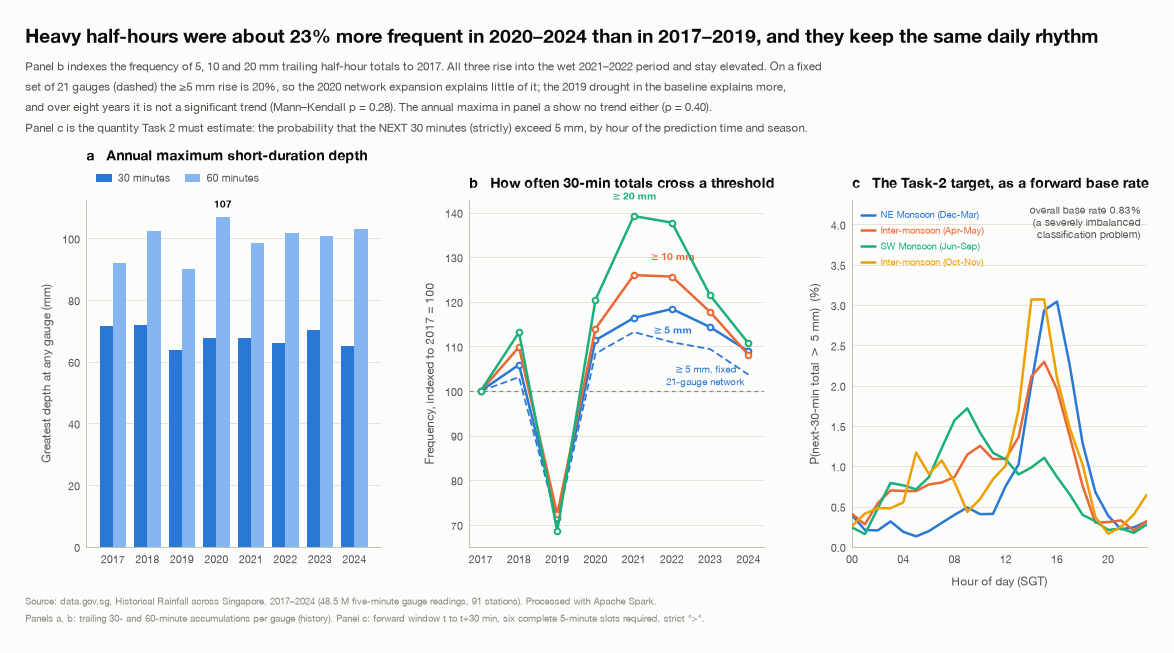

  [figure] outputs/figures/fig10_extremes.png


Task 1 figures collected in outputs/figures/task1_all_figures.pdf


In [33]:
# --- Figure 10: extremes, heavy half-hours and the Task 2 base rate; closes the Task 1 PDF ---------
def fig10_extremes() -> None:
    x = T("t14_extremes_annual").sort_values("year")
    b = T("t15_base_rates_30min")
    tr = T("t39_trend_tests").set_index("metric")
    n_fixed = int(T("t24_sensitivity_summary").set_index("metric")["value"]["fixed_network_stations"])

    def gain(col):
        r = x.set_index("year")[col]
        return 100 * (r.loc[2020:2024].mean() / r.loc[2017:2019].mean() - 1)

    heavy_gain, heavy_gain_fixed = gain("rate_acc30_ge5"), gain("rate_acc30_ge5_fixed")
    p_fixed = tr.loc["30-min totals >= 5 mm, rate (fixed network)", "p_value_exact"]
    p_max60 = tr.loc["annual max 60-min depth (mm, any gauge)", "p_value_exact"]

    fig, axes = plt.subplots(1, 3, figsize=(13.2, 7.0),
                             gridspec_kw=dict(wspace=0.3))

    ax = axes[0]
    w = 0.38
    idx = np.arange(len(x))
    ax.bar(idx - w / 2, x["max_30min_mm"], width=w, color=BLUE, zorder=3,
           label="30 minutes")
    ax.bar(idx + w / 2, x["max_60min_mm"], width=w, color=BLUE_RAMP[3], zorder=3,
           label="60 minutes")
    top60 = x["max_60min_mm"].idxmax()
    for i, r in enumerate(x.itertuples()):
        if r.Index == top60:
            ax.text(i + w / 2, r.max_60min_mm + 3, f"{r.max_60min_mm:.0f}",
                    ha="center", fontsize=8.4, color=INK, fontweight="semibold")
    ax.set_xticks(idx, x["year"])
    ax.set_ylabel("Greatest depth at any gauge (mm)")
    ax.set_title("a   Annual maximum short-duration depth", pad=32)
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1.02), ncol=2, fontsize=8.4)
    despine(ax)
    ax.grid(axis="x", visible=False)

    ax = axes[1]
    # each series is labelled at its own year and on its own side, so no label
    # ever lands on a neighbouring line
    label_at = {"rate_acc30_ge5": (5, -12, "top"),
                "rate_acc30_ge10": (5, 11, "bottom"),
                "rate_acc30_ge20": (4, 11, "bottom")}
    for col, lab, colr in [("rate_acc30_ge5", "$\\geq$5 mm", BLUE),
                           ("rate_acc30_ge10", "$\\geq$10 mm", ORANGE),
                           ("rate_acc30_ge20", "$\\geq$20 mm", AQUA)]:
        v = 100 * x[col] / x[col].iloc[0]
        ax.plot(x["year"], v, color=colr, marker="o", markersize=4.5,
                markerfacecolor=SURFACE, markeredgewidth=1.6, zorder=3)
        # label at 2021, where the three series are furthest apart, rather than
        # at the right edge where they converge
        idx, dy, va = label_at[col]
        ax.annotate(lab, (x["year"].iloc[idx], v.iloc[idx]), xytext=(0, dy),
                    textcoords="offset points", fontsize=8.4, color=colr,
                    fontweight="semibold", va=va, ha="center")
    # the same >= 5 mm series on the fixed network, to separate weather from
    # the 2020 network expansion
    vf = 100 * x["rate_acc30_ge5_fixed"] / x["rate_acc30_ge5_fixed"].iloc[0]
    ax.plot(x["year"], vf, color=BLUE, lw=1.4, ls=(0, (4, 2)), zorder=2)
    # labelled under the line at 2023, the only stretch with no series below it
    ax.annotate(f"$\\geq$5 mm, fixed\n{n_fixed}-gauge network", (x["year"].iloc[6], vf.iloc[6]),
                xytext=(-4, -12), textcoords="offset points", fontsize=7.8, color=BLUE,
                va="top", ha="center")
    ax.axhline(100, color=MUTED, lw=1, ls=(0, (3, 3)), zorder=1)
    ax.set_xticks(x["year"])
    ax.set_xlim(2016.7, 2024.4)
    ax.set_ylabel("Frequency, indexed to 2017 = 100")
    ax.set_title("b   How often 30-min totals cross a threshold")
    despine(ax)
    ax.grid(axis="x", visible=False)

    ax = axes[2]
    for name in SEASON_ORDER:
        s = b[b["season"] == name].sort_values("hour")
        ax.plot(s["hour"], 100 * s["p_gt_5"], color=SEASON_COLOR[name], zorder=3,
                label=name)
    ax.set_xlim(0, 23)
    ax.set_xticks(range(0, 24, 4), [f"{h:02d}" for h in range(0, 24, 4)])
    ax.set_xlabel("Hour of day (SGT)")
    ax.set_ylabel("P(next-30-min total $>$ 5 mm)  (%)")
    ax.set_title("c   The Task-2 target, as a forward base rate")
    ax.set_ylim(0, 4.3)
    ax.legend(loc="upper left", fontsize=7.6, labelcolor="linecolor")
    despine(ax)
    ax.grid(axis="x", visible=False)
    ax.annotate(f"overall base rate {100 * np.average(b['p_gt_5'], weights=b['n']):.2f}%\n(a severely imbalanced\nclassification problem)",
                xy=(0.98, 0.99), xycoords="axes fraction", ha="right", va="top",
                fontsize=8.2, color=INK_2)

    layout(fig, header=2.15, footer=1.00, left=1.1)
    titleblock(fig,
                 f"Heavy half-hours were about {heavy_gain:.0f}% more frequent in 2020\u20132024 than in 2017\u20132019, and they keep the same daily rhythm",
                 "Panel b indexes the frequency of 5, 10 and 20 mm trailing half-hour totals to 2017. All three rise into the wet 2021\u20132022 period and stay elevated. "
                 f"On a fixed\nset of {n_fixed} gauges (dashed) the \u22655 mm rise is {heavy_gain_fixed:.0f}%, so the 2020 network expansion explains little of it; the 2019 "
                 f"drought in the baseline explains more,\nand over eight years it is not a significant trend (Mann\u2013Kendall p = {p_fixed:.2f}). "
                 f"The annual maxima in panel a show no trend either (p = {p_max60:.2f}).\nPanel c is the quantity Task 2 must estimate: the probability that the NEXT 30 minutes (strictly) exceed 5 mm, by hour of the "
                 "prediction time and season.")
    sourcenote(fig, SRC + "\nPanels a, b: trailing 30- and 60-minute accumulations per gauge (history). Panel c: forward window t to t+30 min, six complete 5-minute slots required, strict \">\".")
    save_figure(fig, FIGURES / "fig10_extremes.png")


fig10_extremes()
close_pdf()
print("Task 1 figures collected in outputs/figures/task1_all_figures.pdf")

Heavy half-hours are about 23 % more frequent in 2020–24 than in 2017–19, with a 20 % increase on the fixed
network. The 2020 network expansion therefore explains little of the difference; the 2019 drought in the
baseline period contributes more.

None of the annual series has a statistically significant trend over 2017–2024. Rain per wet day comes closest
(τ = 0.57, p = 0.06, +0.32 mm per wet day per year). The heavy-half-hour rate (p = 0.28) and annual maxima
(p = 0.40) also show no significant trend. With eight observations, these tests have little power to distinguish
a trend from annual variability; the results do not establish that rainfall is unchanged.

The forward base rate P(next 30 min > 5 mm) is 0.83 % overall, but varies more than tenfold across hours and
seasons. Task 2 must account for both this low event rate and its variation.

### 5.11 Task 1 summary and what it means for Task 2

| Finding | Evidence | Consequence for Task 2 |
|---|---|---|
| Large year-to-year variability; 2019 dry through fewer events | Figs 2, 4, 9 | recent rainfall state, not only the calendar |
| Two diurnal regimes switched by the monsoon | Figs 5, 9 | hour of day **and** day of year as features |
| Heavy-tailed, concentrated intensity | Fig 6 | predict an **exceedance probability**, not an amount |
| 2.1× west–east gradient | Fig 7 | station location as a feature |
| Correlation falls to 1/e at ~8.5 km | Fig 8 | per-station model; neighbours within 10 km only |
| Base rate 0.83 % at 5 mm, tenfold structure | Fig 10c | imbalance-aware evaluation (PR-AUC, log loss, calibration) |

In [34]:
# --- End of Task 1 ---------------------------------------------------------------------------------
spark.catalog.clearCache()     # free executor memory before Task 2

---
# Part C. Task 2: probability of more than *h* mm of rain in the next 30 minutes

## 6. Problem definition

Given a station *s*, prediction time *t* and rainfall threshold *h* (mm), we estimate
P( rain at *s* during [*t*, *t* + 30 min) > *h* ).

Under the convention in Section 4.3, the latest measured interval ends at *t* and is stamped `ts = t − 5 min`.
The next 30 minutes contain the six slots stamped `ts`+5 … `ts`+30 min. We sum them as `future_30min_mm`,
requiring all six slots, and define the label as `future_30min_mm > h` (strictly more than).

The threshold is an input feature of one binary classifier. Each (station, time) example is paired with several
thresholds and their labels. The model can return probabilities for any *h* in its trained range: 0.2–30 mm in
Stage 1 and 0.2–60 mm in the final model.

Features use station coordinates, the clock and rain stamped at or before `ts = t − 5 min`, including readings
from up to four neighbouring gauges within 10 km. They exclude rain after *t*, and the model is fitted only on
the training years. Publication by *t* is a separate operational limitation, discussed in Section 4.3.

Stage 1 trains on 2017–2022, uses 2023 for model selection and is tested on 2024. Adjacent five-minute examples
share five of their six future slots, so a random split would leak information. We drop examples whose
30-minute targets cross a split boundary.

Stage 1 (Sections 7–11) selects an interpretable logistic model using the station's recent rain and its four
nearest gauges. Stage 2 (Sections 12–16) adds features and selects the final model from logistic regression,
random forests and gradient-boosted trees through year-blocked cross-validation. Section 17 compares the final
model with the Stage 1 baseline on identical 2024 rows.

Only 0.83 % of half-hours exceed 5 mm. Always predicting "no" would score 99 % accuracy, so we use the
following metrics to assess ranking and probability quality.

| Metric | Question it answers | Good |
|---|---|---|
| PR-AUC (average precision) | when the model flags rain, how often is it right, across all cut-offs? Compare with the event rate. | high |
| ROC-AUC | how well does it rank wet half-hours above dry ones? | high |
| Brier score | mean squared error of the probability | low |
| Log loss | penalty for confident wrong probabilities (a proper scoring rule) | low |
| Skill vs climatology | 1 − score(model) / score(baseline): the share of the baseline's error removed | high |
| Reliability | do events forecast at 20 % happen 20 % of the time? | on the diagonal |
| Monotonicity | P(> 10 mm) must never exceed P(> 5 mm) | 0 violations |

In [35]:
# definitions
# --- 6. Problem definition: split boundaries and neighbour limits ----------------------------------
TRAIN_END = "2023-01-01 00:00:00"


VAL_END = "2024-01-01 00:00:00"


NBR_K = 4


NBR_MAX_KM = 10.0


def split_col(pred_time_col="pred_time"):
    """train / validation / test, purged so no label window crosses a boundary."""
    t = F.col(pred_time_col)
    end = t + F.expr("INTERVAL 30 MINUTES")
    return (F.when(end <= F.to_timestamp(F.lit(TRAIN_END)), "train")
             .when((t >= F.to_timestamp(F.lit(TRAIN_END))) & (end <= F.to_timestamp(F.lit(VAL_END))), "validation")
             .when(t >= F.to_timestamp(F.lit(VAL_END)), "test"))

## 7. Feature engineering (pre-processing for the model)

Spark window functions create one row per (station, prediction time) from the 48 M readings.

| Group | Features | Why (Task 1 evidence) |
|---|---|---|
| Location | `lat`, `lon` | 2.1× west–east gradient (Fig 7) |
| Calendar | sin/cos of time of day, sin/cos of day of year, season | two diurnal regimes, monsoon seasons (Fig 5) |
| Recent rain at the station | latest 5-min rain; last 15/30/60/180-min totals; 60-min peak and wet-slot count; wet flag | events last ~20 min; persistence (Figs 4, 9) |
| Neighbouring gauges (≤ 4 within 10 km) | mean and max of their last 30 min, mean of their last 60 min, max of their latest 5 min, availability flag | correlation length ~8.5 km (Fig 8) |
| Threshold | log(1 + *h*), and *h* × recent-rain interactions (logistic model only) | the task's own input |

We build the neighbour map from coordinates alone, without rainfall data. This small static table is broadcast,
joined to the readings and aggregated by (target station, slot), avoiding a station-by-station join of the
48 M-row table. A missing neighbour is encoded as 0 alongside an explicit availability flag, so it can be
distinguished from a dry gauge.

We keep rows only when the full 3-hour history and all six future slots are present.

In [36]:
# definitions
# --- 7. Feature engineering: neighbour map from coordinates only; neighbour aggregation by broadcast join ---
def neighbour_map(stations_pdf, k: int = NBR_K, max_km: float = NBR_MAX_KM):
    """Static nearest-K neighbour map (station_id, nbr_id, dist_km).

    Uses only station coordinates, never rainfall, so it carries no target
    information. Equirectangular distance is accurate to <0.1% at this scale.
    """
    ids = stations_pdf["station_id"].tolist()
    lat = stations_pdf["lat"].to_numpy(float)
    lon = stations_pdf["lon"].to_numpy(float)
    rows = []
    for i, s in enumerate(ids):
        dy = (lat - lat[i]) * 110.574
        dx = (lon - lon[i]) * 111.320 * np.cos(np.radians(lat[i]))
        d = np.hypot(dx, dy)
        order = [j for j in np.argsort(d) if j != i and d[j] <= max_km][:k]
        rows += [(s, ids[j], float(d[j])) for j in order]
    return rows


def add_neighbour_features(spark, feats, lookup, nbr_rows):
    """Neighbour summaries at the same anchor slot.

    `lookup` = (station_id, ts, r5, acc30, acc60) for the neighbours' own
    trailing windows (already restricted to <= ts, so no future leakage).
    Strategy: join the lookup table to the small reversed edge map (broadcast,
    no shuffle), then group by (target station, ts). The 48 M-row table is
    never cross-joined station-by-station.
    """
    edges = spark.createDataFrame(nbr_rows, ["station_id", "nbr_id", "dist_km"])
    rev = edges.select(F.col("nbr_id").alias("station_id"),
                       F.col("station_id").alias("target_id"))
    agg = (lookup.join(F.broadcast(rev), "station_id")
           .groupBy("target_id", "ts")
           .agg(F.avg("acc30").alias("nbr_acc30_mean"),
                F.max("acc30").alias("nbr_acc30_max"),
                F.avg("acc60").alias("nbr_acc60_mean"),
                F.max("r5").alias("nbr_r5_max"),
                F.count("acc30").alias("n_nbr"))
           .withColumnRenamed("target_id", "station_id"))
    out = feats.join(agg, ["station_id", "ts"], "left")
    out = out.withColumn("n_nbr", F.coalesce(F.col("n_nbr"), F.lit(0)))
    # no neighbour reporting -> neighbour signal is *absent*, encoded as 0 with
    # an explicit n_nbr == 0 indicator, never as a fake "dry neighbours" fact
    for c in ["nbr_acc30_mean", "nbr_acc30_max", "nbr_acc60_mean", "nbr_r5_max"]:
        out = out.withColumn(c, F.coalesce(F.col(c), F.lit(0.0)))
    return out.withColumn("has_nbr", (F.col("n_nbr") > 0).cast("double"))

In [37]:
# --- 7a. Stage 1 feature table: trailing windows, neighbours, calendar, split ----------------------
section('7a. Stage 1 feature table: trailing windows, neighbours, calendar, split', purpose='one row per (station, prediction time) with a complete 3-hour history and all six future slots', writes='data_parquet/gold/task2_features/')
FEATURES_PATH = GOLD / "task2_features"
nbr = neighbour_map(stations)
print(f"neighbour map: {len(nbr)} edges for {len(stations)} stations (mean {len(nbr) / len(stations):.2f} per station)")

t2 = (spark.read.parquet(str(SILVER / "readings")).select("station_id", "ts", "rain_mm")
      .withColumn("ts_s", F.col("ts").cast("long")))
t2 = add_future_target(add_trailing_features(t2))
t2 = t2.join(F.broadcast(spark.createDataFrame(stations[["station_id", "lat", "lon"]])), "station_id")
t2.cache()
with timed("7a. feature table (windows, neighbours, calendar, split)"):
    n_all = t2.count()
    n_fut = t2.filter(F.col("future_30min_mm").isNotNull()).count()
    ok = t2.filter(F.col("future_30min_mm").isNotNull() & F.col("acc180").isNotNull())
    n_ok = ok.count()
    # neighbour lookup: every row whose own trailing windows are complete to 1 h (all values are <= ts)
    lookup = t2.filter(F.col("acc60").isNotNull()).select("station_id", "ts", "r5", "acc30", "acc60")
    feats = add_neighbour_features(spark, ok, lookup, nbr)
    feats = add_time_features(feats).withColumn("split", split_col())
    feats = feats.filter(F.col("split").isNotNull())
    cols = (["station_id", "ts", "pred_time", "split", "lat", "lon", "season", "hour", "minute_of_day",
             "tod_sin", "tod_cos", "month", "doy_sin", "doy_cos"] + TRAILING_COLS
            + ["nbr_acc30_mean", "nbr_acc30_max", "nbr_acc60_mean", "nbr_r5_max", "n_nbr", "has_nbr",
               "future_30min_mm"])
    feats.select(*cols).repartition("split").write.mode("overwrite").partitionBy("split").parquet(str(FEATURES_PATH))
t2.unpersist()
checkpoint("7a. Row funnel", [("silver readings", f"{n_all:,}"), ("with all six future slots", f"{n_fut:,}"),
    ("with a complete 3 h history as well", f"{n_ok:,} ({100 * n_ok / n_all:.1f} %)"),
    ("neighbour edges (<= 4 within 10 km)", f"{len(nbr)} for {len(stations)} stations")])

08:00:54  7a. Stage 1 feature table: trailing windows, neighbours, calendar, split
Purpose : one row per (station, prediction time) with a complete 3-hour history and all six future slots
Writes  : data_parquet/gold/task2_features/
neighbour map: 361 edges for 91 stations (mean 3.97 per station)


[08:02:27]  done: 7a. feature table (windows, neighbours, calendar, split)  (93.5 s)

-- 7a. Row funnel ------------------------------------------------------------------------------
   silver readings                     : 48,338,938
   with all six future slots           : 47,448,263
   with a complete 3 h history as well : 45,856,886 (94.9 %)
   neighbour edges (<= 4 within 10 km) : 361 for 91 stations



In [38]:
# --- 7b. Feature table audit -----------------------------------------------------------------------
section('7b. Feature table audit', purpose='rows, stations, event rates and example rows per split', writes='t25_task2_row_audit, t26_future30_quantiles')
feats = spark.read.parquet(str(FEATURES_PATH))
feats.cache()
with timed("7b. feature table audit"):
    row_audit = (feats.groupBy("split")
                 .agg(F.count(F.lit(1)).alias("rows"), F.countDistinct("station_id").alias("stations"),
                      F.min("pred_time").alias("first_pred_time"), F.max("pred_time").alias("last_pred_time"),
                      F.avg("has_nbr").alias("frac_with_neighbour"),
                      *[F.avg((F.col("future_30min_mm") > h).cast("double")).alias(f"pos_rate_gt_{h}")
                        for h in (0.2, 1.0, 5.0, 10.0, 20.0)],
                      *[F.sum((F.col("future_30min_mm") > h).cast("long")).alias(f"n_pos_gt_{h}")
                        for h in (0.2, 1.0, 5.0, 10.0, 20.0)])
                 .toPandas().sort_values("split"))
    row_audit["rows_all_raw"] = n_all
    row_audit["rows_incomplete_future"] = n_all - n_fut
    row_audit["rows_incomplete_history_or_future"] = n_all - n_ok
    q = feats.approxQuantile("future_30min_mm", [0.5, 0.9, 0.99, 0.999, 0.9999], 1e-5)
write_table(row_audit, "t25_task2_row_audit")
write_table(pd.DataFrame({"quantile": [0.5, 0.9, 0.99, 0.999, 0.9999], "future_30min_mm": q}), "t26_future30_quantiles")
display(row_audit.set_index("split").T)
checkpoint("7b. Feature table by split", [(f"{r['split']}: rows / stations / P(> 5 mm)", f"{int(r['rows']):,} / {int(r['stations'])} / {100 * r['pos_rate_gt_5.0']:.2f} %")
                                          for _, r in row_audit.iterrows()] + [("rows dropped (incomplete future or history)", f"{n_all - n_ok:,}")])
print("an example of rows during rain:")
feats.filter((F.col("split") == "train") & (F.col("acc30") > 2)).select(
    "station_id", "pred_time", "r5", "acc30", "acc180", "nbr_acc30_mean", "nbr_acc30_max", "n_nbr",
    "tod_sin", "tod_cos", "future_30min_mm").limit(5).toPandas()

08:02:27  7b. Feature table audit
Purpose : rows, stations, event rates and example rows per split
Writes  : t25_task2_row_audit, t26_future30_quantiles


[08:02:43]  done: 7b. feature table audit  (15.1 s)
  [table] outputs/tables/t25_task2_row_audit.csv  (3 rows)
  [table] outputs/tables/t26_future30_quantiles.csv  (5 rows)


split,test,train,validation
rows,6277148,32962257,6616826
stations,70,87,73
first_pred_time,2024-01-01 00:00:00,2017-01-01 11:05:00,2023-01-01 00:00:00
last_pred_time,2024-12-31 23:30:00,2022-12-31 23:30:00,2023-12-31 23:30:00
frac_with_neighbour,0.99634,0.964877,0.997497
pos_rate_gt_0.2,0.048633,0.044268,0.05075
pos_rate_gt_1.0,0.025695,0.023489,0.026321
pos_rate_gt_5.0,0.008365,0.008201,0.008753
pos_rate_gt_10.0,0.003823,0.003928,0.004132
pos_rate_gt_20.0,0.00103,0.001096,0.001113



-- 7b. Feature table by split ------------------------------------------------------------------
   test: rows / stations / P(> 5 mm)           : 6,277,148 / 70 / 0.84 %
   train: rows / stations / P(> 5 mm)          : 32,962,257 / 87 / 0.82 %
   validation: rows / stations / P(> 5 mm)     : 6,616,826 / 73 / 0.88 %
   rows dropped (incomplete future or history) : 2,482,052

an example of rows during rain:


,station_id,pred_time,r5,acc30,acc180,nbr_acc30_mean,nbr_acc30_max,n_nbr,tod_sin,tod_cos,future_30min_mm
0,S06,2017-01-02 16:30:00,1.0,10.8,10.8,1.800,3.600,2,-0.923880,-0.382683,2.8
1,S40,2022-05-07 08:30:00,0.2,4.4,4.4,4.034,6.868,2,0.793353,-0.608761,0.0
2,S40,2022-05-11 05:30:00,0.0,2.2,5.8,6.752,10.504,2,0.991445,0.130526,0.4
3,S06,2017-01-10 16:50:00,6.4,20.4,20.4,27.300,33.000,2,-0.953717,-0.300706,5.8
4,S40,2022-05-14 17:50:00,2.2,26.6,29.8,3.029,5.858,2,-0.999048,-0.043619,4.0


### 7.1 Leakage and label check

For 300 random rows, we independently recompute the future target and every trailing feature in pandas from the
cleaned readings. The feature calculations use readings truncated at the anchor slot. Agreement with Spark
checks the time boundary on those rows. Spark joins also check the full table for anchors with missing future
slots and confirm that the split boundaries are purged.

In [39]:
# --- 7.1 Leakage and label check -------------------------------------------------------------------
section('7.1 Leakage and label check', purpose='recompute 300 rows in plain pandas from data truncated at the anchor; prove no anchor with a missing future slot entered')
FIVE = pd.Timedelta(minutes=5)
readings = spark.read.parquet(str(SILVER / "readings")).select("station_id", "ts", "rain_mm")
with timed("7c. leakage / label check"):
    smdf = feats.withColumn("k", F.rand(5208)).orderBy("k").limit(300).drop("k").cache()
    sm = smdf.withColumn("ts_str", F.date_format("ts", "yyyy-MM-dd HH:mm:ss")).toPandas()
    sm["ts"] = pd.to_datetime(sm["ts_str"])
    win = (smdf.select("station_id", F.col("ts").alias("a_ts")).join(readings, "station_id")
           .filter((F.col("ts") >= F.col("a_ts") - F.expr("INTERVAL 185 MINUTES"))
                   & (F.col("ts") <= F.col("a_ts") + F.expr("INTERVAL 35 MINUTES")))
           .select("station_id", "ts", "rain_mm").distinct()
           .withColumn("ts_str", F.date_format("ts", "yyyy-MM-dd HH:mm:ss")))
    r = win.toPandas()
    r["ts"] = pd.to_datetime(r["ts_str"])
    by = {s_: g.set_index("ts")["rain_mm"].sort_index() for s_, g in r.groupby("station_id")}
    shown = 0
    for x in sm.itertuples():
        series = by[x.station_id]
        slots = lambda a, b: series.reindex(pd.date_range(a, b, freq="5min"))
        fut = slots(x.ts + FIVE, x.ts + 6 * FIVE)
        assert fut.notna().all(), "label built over a missing slot"
        assert np.isclose(fut.sum(), x.future_30min_mm, atol=1e-6), (x, fut.sum())
        hist = series[series.index <= x.ts]               # nothing after the anchor is visible
        assert np.isclose(hist.iloc[-1], x.r5)
        for name, n in [("acc15", 3), ("acc30", 6), ("acc60", 12), ("acc180", 36)]:
            w_ = hist.reindex(pd.date_range(x.ts - (n - 1) * FIVE, x.ts, freq="5min"))
            assert w_.notna().all() and np.isclose(w_.sum(), getattr(x, name), atol=1e-6), (name, x)
        w60 = hist.reindex(pd.date_range(x.ts - 11 * FIVE, x.ts, freq="5min"))
        assert np.isclose(w60.max(), x.max5_60) and x.wet_slots_60 == int((w60 >= 0.2).sum())
        if shown < 4 and (fut.sum() > 1 or shown < 1):
            h6 = hist.reindex(pd.date_range(x.ts - 5 * FIVE, x.ts, freq="5min")).round(2).tolist()
            print(f"example: {x.station_id}, last observed slot {x.ts} -> prediction time t = {x.ts + FIVE}")
            print(f"  last 6 observed slots : {h6}  (acc30 = {x.acc30:.2f})")
            print(f"  next 6 slots (t..t+30): {fut.round(2).tolist()}  (future_30min_mm = {x.future_30min_mm:.2f})")
            print(f"  labels  >0.2: {int(x.future_30min_mm > 0.2)}  >1: {int(x.future_30min_mm > 1)}  "
                  f">5: {int(x.future_30min_mm > 5)}  (strict '>')\n")
            shown += 1
    print("[ok] 300 random rows: target and trailing features match an independent pandas recomputation")

    nxt = readings.select("station_id", (F.col("ts").cast("long") - 900).alias("k"), F.lit(1).alias("has15"))
    a = (readings.select("station_id", F.col("ts").cast("long").alias("k"), "ts")
         .join(nxt, ["station_id", "k"], "left_anti"))          # anchors whose slot at ts+15 min is missing
    n_missing = a.count()
    kept = a.join(feats.select("station_id", "ts"), ["station_id", "ts"]).count()
    print(f"[{'ok' if kept == 0 else 'FAIL'}] {n_missing:,} anchors lack the ts+15 min slot; {kept} of them are in the feature table")
    assert kept == 0
checkpoint("7.1 Leakage and label checks", [("pandas recomputation of 300 random rows", "passed (target and every trailing feature match)"),
    ("anchors with a missing future slot in the table", f"{kept} of {n_missing:,} (passed)")])
smdf.unpersist()
row_audit[["split", "first_pred_time", "last_pred_time"]]

08:02:43  7.1 Leakage and label check
Purpose : recompute 300 rows in plain pandas from data truncated at the anchor; prove no anchor with a missing future slot entered


example: S46, last observed slot 2020-05-15 17:40:00 -> prediction time t = 2020-05-15 17:45:00
  last 6 observed slots : [0.0, 0.0, 0.0, 0.0, 0.0, 0.0]  (acc30 = 0.00)
  next 6 slots (t..t+30): [0.0, 0.0, 0.0, 0.0, 0.0, 0.0]  (future_30min_mm = 0.00)
  labels  >0.2: 0  >1: 0  >5: 0  (strict '>')

example: S61, last observed slot 2019-04-04 16:30:00 -> prediction time t = 2019-04-04 16:35:00
  last 6 observed slots : [0.0, 0.0, 0.0, 0.0, 0.0, 0.0]  (acc30 = 0.00)
  next 6 slots (t..t+30): [0.2, 1.0, 0.4, 0.0, 0.0, 0.0]  (future_30min_mm = 1.60)
  labels  >0.2: 1  >1: 1  >5: 0  (strict '>')

example: S216, last observed slot 2020-09-05 08:55:00 -> prediction time t = 2020-09-05 09:00:00
  last 6 observed slots : [0.0, 0.41, 0.2, 0.2, 0.2, 0.2]  (acc30 = 1.22)
  next 6 slots (t..t+30): [0.41, 0.41, 0.2, 0.2, 0.41, 0.2]  (future_30min_mm = 1.84)
  labels  >0.2: 1  >1: 1  >5: 0  (strict '>')

example: S208, last observed slot 2024-08-28 05:40:00 -> prediction time t = 2024-08-28 05:45:00
 

[ok] 309,735 anchors lack the ts+15 min slot; 0 of them are in the feature table
[08:03:09]  done: 7c. leakage / label check  (26.2 s)

-- 7.1 Leakage and label checks ----------------------------------------------------------------
   pandas recomputation of 300 random rows         : passed (target and every trailing feature match)
   anchors with a missing future slot in the table : 0 of 309,735 (passed)



,split,first_pred_time,last_pred_time
0,test,2024-01-01 00:00:00,2024-12-31 23:30:00
1,train,2017-01-01 11:05:00,2022-12-31 23:30:00
2,validation,2023-01-01 00:00:00,2023-12-31 23:30:00


## 8. Training and evaluation sets: the threshold as an input

For training in 2017–2022, each (station, time) row is a candidate for every threshold on the grid
0.2, 0.5, 1, 2, 3, 5, 7.5, 10, 15, 20, 30 mm. We keep a row for threshold *h* when
`hash(station, time, h) < rate[h]`, where `rate[h] = min(6 %, 8000 / positives[h])`. This gives about 8,000
positives per threshold up to 7.5 mm and a 6 % sample above.

Within a threshold, the inclusion rule does not inspect the row's label. It preserves class balance in
expectation, so no re-weighting is needed. The hash makes the sample deterministic and reproducible.

For evaluation on the 2023 validation year and 2024 test year, we select a fixed 20 % of prediction times by
hash and pair each with every threshold. All models and thresholds are therefore scored on the same examples,
without changing the class balance by label.

In [40]:
# --- 8. Training and evaluation sets ---------------------------------------------------------------
section('8. Training and evaluation sets', purpose='label-independent hash sampling per threshold for training; a fixed 20 % of prediction times x every threshold for evaluation', writes='data_parquet/gold/task2_sets/{train,validation,test}, t27_task2_training_design')


def hash_frac(*cols, seed: int = 5208):
    """Deterministic uniform [0,1) per key (xxhash64 is stable across runs)."""
    h = F.xxhash64(*cols, F.lit(seed))
    return (F.abs(h % F.lit(1_000_000)).cast("double")) / 1_000_000.0


THR_TRAIN = [0.2, 0.5, 1.0, 2.0, 3.0, 5.0, 7.5, 10.0, 15.0, 20.0, 30.0]


THR_EVAL = [0.2, 1.0, 2.0, 5.0, 10.0, 20.0]


def with_label(df):
    return df.withColumn("label", (F.col("future_30min_mm") > F.col("threshold_mm")).cast("double"))


TARGET_POS = 8000


R_CAP = 0.06


EVAL_FRAC = 0.20


RAW_COLS = ["station_id", "ts", "pred_time", "lat", "lon", "season", "hour", "minute_of_day",
            "tod_sin", "tod_cos", "month", "doy_sin", "doy_cos", "r5", "acc15", "acc30",
            "acc60", "acc180", "max5_60", "wet_slots_60", "is_wet", "nbr_acc30_mean",
            "nbr_acc30_max", "nbr_acc60_mean", "nbr_r5_max", "n_nbr", "has_nbr",
            "future_30min_mm"]


def thr_frame(spark, thresholds, extra=None):
    rows = [(float(h),) + ((extra[h],) if extra else ()) for h in thresholds]
    return spark.createDataFrame(rows, ["threshold_mm"] + (["rate"] if extra else []))


SETS = GOLD / "task2_sets"
spark.conf.set("spark.sql.shuffle.partitions", "64")
with timed("8. training + evaluation sets"):
    shutil.rmtree(SETS, ignore_errors=True)
    tr = feats.filter(F.col("split") == "train").select(*RAW_COLS)
    stats_ = tr.agg(*[F.sum((F.col("future_30min_mm") > h).cast("long")).alias(f"p{i}") for i, h in enumerate(THR_TRAIN)],
                    F.count(F.lit(1)).alias("n")).first()
    n_tr = stats_["n"]
    rates = {h: min(R_CAP, TARGET_POS / max(stats_[f"p{i}"], 1)) for i, h in enumerate(THR_TRAIN)}
    design = pd.DataFrame({"threshold_mm": THR_TRAIN,
                           "n_pos_population": [stats_[f"p{i}"] for i in range(len(THR_TRAIN))],
                           "population_pos_rate": [stats_[f"p{i}"] / n_tr for i in range(len(THR_TRAIN))],
                           "sample_rate": [rates[h] for h in THR_TRAIN]})
    s = (tr.crossJoin(F.broadcast(thr_frame(spark, THR_TRAIN, rates)))
         .filter(hash_frac("station_id", F.col("ts").cast("long"), "threshold_mm", seed=5208) < F.col("rate"))
         .drop("rate"))
    with_label(s).repartition(48).write.mode("overwrite").parquet(str(SETS / "train"))
    agg_ = (spark.read.parquet(str(SETS / "train")).groupBy("threshold_mm")
            .agg(F.count(F.lit(1)).alias("rows"), F.sum("label").alias("positives")).toPandas())
    design = design.merge(agg_, on="threshold_mm")
    design["sample_pos_rate"] = design["positives"] / design["rows"]
    allthr = thr_frame(spark, THR_TRAIN)
    for split in ("validation", "test"):
        ev_ = (feats.filter(F.col("split") == split).select(*RAW_COLS)
               .filter(hash_frac("station_id", F.col("ts").cast("long"), seed=2023) < EVAL_FRAC))
        with_label(ev_.crossJoin(F.broadcast(allthr))).repartition(24).write.mode("overwrite").parquet(str(SETS / split))
write_table(design, "t27_task2_training_design")
checkpoint("8. Training and evaluation sets", [
    ("training sample rows", f"{int(design.rows.sum()):,} over {len(THR_TRAIN)} thresholds"),
    ("positives per threshold", f"{int(design.positives.min()):,}-{int(design.positives.max()):,}"),
    ("sampling rate", f"{100 * design.sample_rate.min():.2f}-{100 * design.sample_rate.max():.2f} % (depends only on the threshold)"),
    ("max |sample - population| positive rate", f"{(design.sample_pos_rate - design.population_pos_rate).abs().max():.5f} (unbiased sample)")])
design.round(5)

08:03:09  8. Training and evaluation sets
Purpose : label-independent hash sampling per threshold for training; a fixed 20 % of prediction times x every threshold for evaluation
Writes  : data_parquet/gold/task2_sets/{train,validation,test}, t27_task2_training_design


[08:03:52]  done: 8. training + evaluation sets  (43.4 s)
  [table] outputs/tables/t27_task2_training_design.csv  (11 rows)

-- 8. Training and evaluation sets -------------------------------------------------------------
   training sample rows                    : 12,238,797 over 11 thresholds
   positives per threshold                 : 624-8,274
   sampling rate                           : 0.55-6.00 % (depends only on the threshold)
   max |sample - population| positive rate : 0.00046 (unbiased sample)



,threshold_mm,n_pos_population,population_pos_rate,sample_rate,rows,positives,sample_pos_rate
0,0.2,1459172,0.04427,0.00548,180217,7927.0,0.04399
1,0.5,1115443,0.03384,0.00717,236199,7972.0,0.03375
2,1.0,774234,0.02349,0.01033,339799,7826.0,0.02303
3,2.0,516534,0.01567,0.01549,509909,7923.0,0.01554
4,3.0,397740,0.01207,0.02011,663159,7931.0,0.01196
5,5.0,270313,0.00820,0.02960,974468,8106.0,0.00832
6,7.5,185085,0.00562,0.04322,1425776,8274.0,0.00580
7,10.0,129461,0.00393,0.06000,1975312,7735.0,0.00392
8,15.0,67816,0.00206,0.06000,1978686,4082.0,0.00206
9,20.0,36140,0.00110,0.06000,1977159,2179.0,0.00110


The `population_pos_rate` and `sample_pos_rate` columns show that the sampled positive rates are close to the
population rates at each threshold, as expected from sampling without reference to the row's label.

## 9. Baseline models

We estimate two baselines from the training years:

* Climatology estimates P(next 30 min > *h*) for each season × hour of day × threshold, smoothed towards the
  overall threshold rate with 20 pseudo-observations. It uses calendar information alone.
* The base-rate model gives one probability per threshold and cannot rank examples (ROC-AUC = 0.5).

For evaluation, Spark reduces each prediction frame to counts in 600 bins uniform in logit *p*. We derive PR
and ROC curves, average precision, reliability, the F1-optimal cut-off, Brier score and log loss from this small
table. One pass over the 14.5 M-row evaluation set thus supplies the metrics and subgroup analyses. Section 11
cross-checks average precision against MLlib's `BinaryClassificationEvaluator`.

In [41]:
# definitions
# --- 9. Evaluation toolkit (binned metrics) and the climatology baseline ---------------------------
NB = 600


ZMAX = 16.2


EPS = 1e-7


def prob_col(df, col="probability", out="p"):
    return df.withColumn(out, vector_to_array(F.col(col))[1])


def bin_aggregate(pred, keys):
    """pred needs p, label, plus the key columns. Returns a pandas frame."""
    p = F.least(F.greatest(F.col("p"), F.lit(EPS)), F.lit(1 - EPS))
    z = F.log(p / (1 - p))
    b = F.least(F.greatest(F.floor((z + ZMAX) / (2 * ZMAX) * NB), F.lit(0)), F.lit(NB - 1)).cast("int")
    y = F.col("label")
    out = (pred.withColumn("bin", b).withColumn("pc", p)
           .groupBy(*keys, "bin")
           .agg(F.count(F.lit(1)).alias("n"), F.sum(y).alias("pos"), F.sum("pc").alias("sum_p"),
                F.sum((F.col("pc") - y) ** 2).alias("sum_se"),
                F.sum(-(y * F.log("pc") + (1 - y) * F.log(1 - F.col("pc")))).alias("sum_ll"))
           .toPandas())
    return out


def bin_to_p(b):
    return 1.0 / (1.0 + np.exp(-(-ZMAX + (np.asarray(b) + 0.0) * 2 * ZMAX / NB)))


def _curve(g):
    """PR / ROC points, one per bin, scanning from the highest probability."""
    g = g.sort_values("bin", ascending=False)
    n, pos = g["n"].to_numpy(float), g["pos"].to_numpy(float)
    tp, fp = np.cumsum(pos), np.cumsum(n - pos)
    P, N = pos.sum(), (n - pos).sum()
    return g["bin"].to_numpy(), tp, fp, P, N


def metrics(g, cutoff_bin=None, fixed_f1_floor=1):
    """Metrics for one group (a frame of bin aggregates)."""
    n, pos = g["n"].sum(), g["pos"].sum()
    out = {"n": int(n), "n_pos": int(pos), "prevalence": pos / n,
           "mean_pred": g["sum_p"].sum() / n, "brier": g["sum_se"].sum() / n,
           "logloss": g["sum_ll"].sum() / n}
    brier_ref = (pos / n) * (1 - pos / n)
    out["brier_skill_vs_prevalence"] = 1 - out["brier"] / brier_ref if brier_ref > 0 else np.nan
    if pos == 0 or pos == n:
        return {**out, "pr_auc": np.nan, "roc_auc": np.nan}
    bins, tp, fp, P, N = _curve(g)
    rec, prec = tp / P, tp / (tp + fp)
    out["pr_auc"] = float(np.sum(np.diff(np.r_[0.0, rec]) * prec))          # average precision
    out["roc_auc"] = float(np.trapz(np.r_[0, tp / P], np.r_[0, fp / N]))
    f1 = 2 * prec * rec / np.maximum(prec + rec, 1e-12)
    if cutoff_bin is None:
        cutoff_bin = int(bins[np.argmax(np.where(tp >= fixed_f1_floor, f1, -1))])
    k = int(np.sum(bins >= cutoff_bin))           # bins predicted positive (p >= cutoff)
    tp_k, fp_k = (tp[k - 1], fp[k - 1]) if k > 0 else (0.0, 0.0)
    pr_k = tp_k / (tp_k + fp_k) if tp_k + fp_k > 0 else 0.0
    rc_k = tp_k / P
    out.update(cutoff_bin=int(cutoff_bin), cutoff_p=float(bin_to_p(cutoff_bin)),
               precision=float(pr_k), recall=float(rc_k),
               f1=float(2 * pr_k * rc_k / (pr_k + rc_k)) if pr_k + rc_k > 0 else 0.0,
               tp=int(tp_k), fp=int(fp_k), fn=int(P - tp_k), tn=int(N - fp_k))
    return out


def group_metrics(binned, keys, cutoffs=None):
    """cutoffs: dict {key tuple -> cutoff bin} carried over from validation."""
    rows = []
    for k, g in binned.groupby(keys):
        k = k if isinstance(k, tuple) else (k,)
        cb = None if cutoffs is None else cutoffs.get(k)
        r = dict(zip(keys, k))
        r.update(metrics(g, cutoff_bin=cb))
        rows.append(r)
    return pd.DataFrame(rows)


def pr_points(g, max_pts=120):
    bins, tp, fp, P, N = _curve(g)
    rec, prec = tp / P, tp / (tp + fp)
    idx = np.unique(np.linspace(0, len(bins) - 1, max_pts).astype(int))
    return pd.DataFrame({"recall": rec[idx], "precision": prec[idx], "cutoff_p": bin_to_p(bins[idx])})


def reliability(g, edges=None):
    """Reliability points: bins merged until each holds >= 1 % of the rows or 30
    positives, so tail points are not noise."""
    g = g.sort_values("bin")
    rows, cn, cp, cs = [], 0, 0, 0
    tot = g["n"].sum()
    for r in g.itertuples():
        cn += r.n
        cp += r.pos
        cs += r.sum_p
        if cp >= 30 and cn >= 0.005 * tot:
            rows.append((cs / cn, cp / cn, cn, cp))
            cn = cp = cs = 0
    if cn > 0:
        if rows:
            m, o, n0, p0 = rows[-1]
            rows[-1] = ((m * n0 + cs) / (n0 + cn), (p0 + cp) / (n0 + cn), n0 + cn, p0 + cp)
        else:
            rows.append((cs / cn, cp / cn, cn, cp))
    return pd.DataFrame(rows, columns=["mean_pred", "obs_freq", "n", "n_pos"])


BASELINE_PSEUDO = 20


def climatology(spark, feats):
    tr = feats.filter(F.col("split") == "train")
    parts = []
    for h in THR_TRAIN:
        y = (F.col("future_30min_mm") > h).cast("double")
        parts.append(tr.groupBy("season", "hour").agg(F.count(F.lit(1)).alias("n"), F.sum(y).alias("pos"))
                     .withColumn("threshold_mm", F.lit(float(h))))
    cell = parts[0]
    for q in parts[1:]:
        cell = cell.unionByName(q)
    cell = cell.toPandas()
    glob = cell.groupby("threshold_mm")[["n", "pos"]].sum()
    glob["p_h"] = glob["pos"] / glob["n"]
    cell = cell.merge(glob["p_h"].reset_index(), on="threshold_mm")
    cell["p_clim"] = (cell["pos"] + BASELINE_PSEUDO * cell["p_h"]) / (cell["n"] + BASELINE_PSEUDO)
    return (spark.createDataFrame(cell[["threshold_mm", "season", "hour", "p_clim"]]),
            spark.createDataFrame(glob.reset_index()[["threshold_mm", "p_h"]]))


def macro(df, base):
    m = df.merge(base[["threshold_mm", "logloss", "brier"]].rename(
        columns={"logloss": "ll0", "brier": "br0"}), on="threshold_mm")
    return {"macro_pr_auc": m["pr_auc"].mean(), "macro_roc_auc": m["roc_auc"].mean(),
            "macro_logloss": m["logloss"].mean(), "macro_brier": m["brier"].mean(),
            "macro_logloss_skill": (1 - m["logloss"] / m["ll0"]).mean(),
            "macro_brier_skill": (1 - m["brier"] / m["br0"]).mean()}

In [42]:
# --- 9. Baselines on the 2023 validation year ------------------------------------------------------
section('9. Baselines on the 2023 validation year', purpose='climatology (season x hour x threshold) and one base rate per threshold, both from the training years only')
train = spark.read.parquet(str(SETS / "train"))
val = spark.read.parquet(str(SETS / "validation")).cache()
test = spark.read.parquet(str(SETS / "test"))
split_rows = {s_: feats.filter(F.col("split") == s_).count() for s_ in ("train", "validation", "test")}
step(f"prediction times per split: {split_rows}")
step(f"training sample rows: {train.count():,}; validation evaluation rows: {val.count():,}")

clim_cell, clim_thr = climatology(spark, feats)
lon_cuts = np.quantile(stations["lon"], [1 / 3, 2 / 3])
region = (F.when(F.col("lon") < float(lon_cuts[0]), "West")
          .when(F.col("lon") < float(lon_cuts[1]), "Central").otherwise("East"))
band = F.concat(F.lpad((F.floor(F.col("hour") / 4) * 4).cast("string"), 2, "0"), F.lit("-"),
                F.lpad((F.floor(F.col("hour") / 4) * 4 + 3).cast("string"), 2, "0"))


def score(name, model, df):
    """Probability p for every row of an evaluation set, for a baseline or a fitted pipeline."""
    base_cols = ["station_id", "ts", "threshold_mm", "label", "season", "hour", "lon"]
    if name == "Climatology":
        out = df.join(F.broadcast(clim_cell), ["threshold_mm", "season", "hour"], "left").withColumnRenamed("p_clim", "p")
    elif name == "BaseRate_by_threshold":
        out = df.join(F.broadcast(clim_thr), "threshold_mm", "left").withColumnRenamed("p_h", "p")
    else:
        out = prob_col(model.transform(add_model_inputs(df)))
    return out.select(*base_cols, "p").withColumn("region", region).withColumn("hour_band", band)


results, mono_rows = {}, {}
with timed("9. baselines on 2023"):
    for nm in ("Climatology", "BaseRate_by_threshold"):
        b_ = bin_aggregate(score(nm, None, val).filter(F.col("threshold_mm").isin(THR_EVAL)), ["threshold_mm"])
        results[nm] = group_metrics(b_, ["threshold_mm"])
base = results["Climatology"]
for nm in results:
    ms = macro(results[nm], base)
    result_box(f"baseline: {nm}", [("macro PR-AUC (2023)", f"{ms['macro_pr_auc']:.4f}"), ("macro ROC-AUC", f"{ms['macro_roc_auc']:.4f}"),
                                   ("macro log loss", f"{ms['macro_logloss']:.4f}"), ("macro Brier", f"{ms['macro_brier']:.5f}")])
pd.concat([r.assign(model=m) for m, r in results.items()])[
    ["model", "threshold_mm", "n", "prevalence", "pr_auc", "roc_auc", "brier", "logloss"]].round(4)

08:03:52  9. Baselines on the 2023 validation year
Purpose : climatology (season x hour x threshold) and one base rate per threshold, both from the training years only


[08:03:53]  prediction times per split: {'train': 32962257, 'validation': 6616826, 'test': 6277148}


[08:03:56]  training sample rows: 12,238,797; validation evaluation rows: 14,543,232


[08:04:01]  done: 9. baselines on 2023  (1.4 s)
------------------------------------------------------------------------
  baseline: Climatology
------------------------------------------------------------------------
  macro PR-AUC (2023) : 0.0430
  macro ROC-AUC       : 0.7201
  macro log loss      : 0.0783
  macro Brier         : 0.01717
------------------------------------------------------------------------
------------------------------------------------------------------------
  baseline: BaseRate_by_threshold
------------------------------------------------------------------------
  macro PR-AUC (2023) : 0.0181
  macro ROC-AUC       : 0.5000
  macro log loss      : 0.0828
  macro Brier         : 0.01748
------------------------------------------------------------------------


,model,threshold_mm,n,prevalence,pr_auc,roc_auc,brier,logloss
0,Climatology,0.2,1322112,0.0507,0.1113,0.6835,0.0470,0.1904
1,Climatology,1.0,1322112,0.0264,0.0645,0.7034,0.0252,0.1150
2,Climatology,2.0,1322112,0.0174,0.0427,0.7038,0.0169,0.0833
3,Climatology,5.0,1322112,0.0088,0.0236,0.7254,0.0086,0.0474
4,Climatology,10.0,1322112,0.0041,0.0122,0.7338,0.0041,0.0253
5,Climatology,20.0,1322112,0.0011,0.0037,0.7709,0.0011,0.0081
0,BaseRate_by_threshold,0.2,1322112,0.0507,0.0507,0.5000,0.0482,0.2011
1,BaseRate_by_threshold,1.0,1322112,0.0264,0.0264,0.5000,0.0257,0.1220
2,BaseRate_by_threshold,2.0,1322112,0.0174,0.0174,0.5000,0.0171,0.0879
3,BaseRate_by_threshold,5.0,1322112,0.0088,0.0088,0.5000,0.0087,0.0503


Climatology has a ROC-AUC of about 0.7, but its PR-AUC remains close to the event rate. Hour and season provide
some ranking information without identifying which particular half-hours will be wet.

## 10. Stage 1: interpretable candidate models (Spark MLlib) and model selection

We fit the following Spark ML `Pipeline`s (`StringIndexer` → `OneHotEncoder` → `VectorAssembler` → classifier)
on the 2017–2022 training sample.

| Candidate | Classifier | Features |
|---|---|---|
| `LR_local` | `LogisticRegression` | location, calendar, the station's own recent rain, threshold, station and season one-hot |
| `LR_spatial` | `LogisticRegression` | + neighbouring gauges |
| `LR_spatial_ix` | `LogisticRegression` | + threshold × recent-rain interactions (lets the effect of *h* depend on the rain state) |
| `LR_spatial_ix_reg` | `LogisticRegression` | as above with 100× stronger L2 regularisation |
| `GBT_spatial_d5`, `_d7` | `GBTClassifier`, 80 trees, depth 5 / 7 | location, calendar, own and neighbour rain, threshold (trees learn interactions themselves; trained on a 35 % subset for time) |

Rain amounts enter as log(1 + mm). We select the model with the highest macro-average log-loss skill across
the six headline thresholds on 2023, using a rule fixed in advance. Log loss is a proper scoring rule that
penalises confident errors, making it suitable for comparing the predicted probabilities.

In [43]:
# definitions
# --- 10. Stage 1 candidate pipelines (StringIndexer -> OneHotEncoder -> VectorAssembler -> classifier) ---
LOG_COLS = {"l_r5": "r5", "l_acc15": "acc15", "l_acc30": "acc30", "l_acc60": "acc60",
            "l_acc180": "acc180", "l_max5_60": "max5_60",
            "l_nbr30_mean": "nbr_acc30_mean", "l_nbr30_max": "nbr_acc30_max",
            "l_nbr60_mean": "nbr_acc60_mean", "l_nbr_r5_max": "nbr_r5_max"}


LOCAL_NUM = ["lat", "lon", "tod_sin", "tod_cos", "doy_sin", "doy_cos",
             "l_r5", "l_acc15", "l_acc30", "l_acc60", "l_acc180", "l_max5_60",
             "wet_slots_60", "is_wet", "lh"]


NBR_NUM = ["l_nbr30_mean", "l_nbr30_max", "l_nbr60_mean", "l_nbr_r5_max", "has_nbr"]


INTERACT = ["l_r5", "l_acc15", "l_acc30", "l_acc60", "l_acc180", "l_nbr30_mean",
            "l_nbr30_max", "l_nbr_r5_max", "is_wet"]


def add_model_inputs(df):
    """log1p transforms, the threshold input and its interactions.

    Requires `threshold_mm` (a real numeric input of the model) in `df`.
    """
    for new, old in LOG_COLS.items():
        df = df.withColumn(new, F.log1p(F.col(old)))
    df = df.withColumn("lh", F.log1p(F.col("threshold_mm")))
    for c in INTERACT:
        df = df.withColumn(f"ix_{c}", F.col("lh") * F.col(c))
    return df


def feature_names(spatial: bool = True, interactions: bool = False):
    num = list(LOCAL_NUM) + (list(NBR_NUM) if spatial else [])
    if interactions:
        num += [f"ix_{c}" for c in INTERACT if spatial or "nbr" not in c]
    return num


def build_pipeline(kind: str, spatial: bool = True, interactions: bool = False, **hp):
    """kind = 'lr' | 'gbt'.

    LR: station and season one-hot encoded (handleInvalid='keep' so a gauge
    absent from training maps to an extra 'unknown' slot instead of failing).
    GBT: location enters through lat/lon, season as an indexed categorical.
    """
    from pyspark.ml import Pipeline
    from pyspark.ml.classification import GBTClassifier, LogisticRegression
    from pyspark.ml.feature import OneHotEncoder, StringIndexer, VectorAssembler

    num = feature_names(spatial, interactions)
    stages = [StringIndexer(inputCol="season", outputCol="season_idx", handleInvalid="keep")]
    if kind == "lr":
        stages += [
            StringIndexer(inputCol="station_id", outputCol="station_idx", handleInvalid="keep"),
            OneHotEncoder(inputCols=["station_idx", "season_idx"],
                          outputCols=["station_ohe", "season_ohe"], handleInvalid="keep"),
            VectorAssembler(inputCols=num + ["station_ohe", "season_ohe"], outputCol="features"),
            LogisticRegression(featuresCol="features", labelCol="label", maxIter=hp.get("maxIter", 60),
                               regParam=hp.get("regParam", 1e-5), elasticNetParam=0.0, tol=1e-6),
        ]
    else:
        stages += [
            VectorAssembler(inputCols=num + ["season_idx"], outputCol="features"),
            GBTClassifier(featuresCol="features", labelCol="label", maxIter=hp.get("maxIter", 60),
                          maxDepth=hp.get("maxDepth", 5), stepSize=hp.get("stepSize", 0.1),
                          maxBins=32, subsamplingRate=hp.get("subsamplingRate", 0.7), seed=5208),
        ]
    return Pipeline(stages=stages)


GBT_FRAC = 0.35


MONO_TOL = 0.01


CANDIDATES = {
    "LR_local":          dict(kind="lr", spatial=False, interactions=False, regParam=1e-5),
    "LR_spatial":        dict(kind="lr", spatial=True, interactions=False, regParam=1e-5),
    "LR_spatial_ix":     dict(kind="lr", spatial=True, interactions=True, regParam=1e-5),
    "LR_spatial_ix_reg": dict(kind="lr", spatial=True, interactions=True, regParam=1e-3),
    "GBT_spatial_d5":    dict(kind="gbt", spatial=True, maxDepth=5, maxIter=80),
    "GBT_spatial_d7":    dict(kind="gbt", spatial=True, maxDepth=7, maxIter=80),
}


def with_cummin(pred):
    w = (Window.partitionBy("station_id", "ts").orderBy("threshold_mm")
         .rowsBetween(Window.unboundedPreceding, Window.currentRow))
    return pred.withColumn("p", F.min("p").over(w))


def monotonic_stats(pred):
    w = Window.partitionBy("station_id", "ts").orderBy("threshold_mm")
    d = pred.withColumn("dp", F.col("p") - F.lag("p").over(w)).filter(F.col("dp").isNotNull())
    d = d.withColumn("viol", (F.col("dp") > 1e-9).cast("int")).withColumn("mag", F.when(F.col("dp") > 1e-9, F.col("dp")))
    a = d.agg(F.count(F.lit(1)).alias("pairs"), F.sum("viol").alias("viol_pairs"),
              F.avg("mag").alias("mean_violation"), F.max("mag").alias("max_violation"),
              F.expr("percentile_approx(mag, 0.95, 100000)").alias("p95_violation")).first()
    seq = d.groupBy("station_id", "ts").agg(F.max("viol").alias("any")).agg(
        F.count(F.lit(1)).alias("sequences"), F.sum("any").alias("seq_viol")).first()
    return {"sequences": seq["sequences"], "pct_sequences_with_violation": 100 * seq["seq_viol"] / seq["sequences"],
            "adjacent_pairs": a["pairs"], "pct_pairs_violating": 100 * a["viol_pairs"] / a["pairs"],
            "mean_violation_prob": a["mean_violation"], "p95_violation_prob": a["p95_violation"],
            "max_violation_prob": a["max_violation"]}

In [44]:
# --- 10. Fit the Stage 1 candidates on 2017-2022 and score them on 2023 ----------------------------
section('10. Fit the Stage 1 candidates on 2017-2022 and score them on 2023', purpose='four logistic regressions (adding neighbours, then threshold interactions, then stronger L2) and two GBTs')
models, fit_time = {}, {}
for nm, spec in CANDIDATES.items():
    spec = dict(spec)
    kind = spec.pop("kind")
    tdf = train
    if kind == "gbt":
        tdf = tdf.filter(hash_frac("station_id", F.col("ts").cast("long"), "threshold_mm", seed=77) < GBT_FRAC)
    tdf = add_model_inputs(tdf).cache()
    n_fit = tdf.count()
    t1 = time.time()
    with timed(f"10. fit {nm} ({n_fit:,} rows)"):
        models[nm] = build_pipeline(kind, **spec).fit(tdf)
    fit_time[nm] = time.time() - t1
    tdf.unpersist()
    pred = score(nm, models[nm], val)
    b_ = bin_aggregate(pred.filter(F.col("threshold_mm").isin(THR_EVAL)), ["threshold_mm"])
    results[nm] = group_metrics(b_, ["threshold_mm"])
    mono_rows[nm] = monotonic_stats(pred)
    ms = macro(results[nm], base)
    result_box(f"{nm}  (fit {fit_time[nm]:.0f} s on {n_fit:,} rows)", [
        ("macro PR-AUC (2023)", f"{ms['macro_pr_auc']:.4f}"), ("macro ROC-AUC", f"{ms['macro_roc_auc']:.4f}"),
        ("log-loss skill vs climatology", f"{ms['macro_logloss_skill']:.4f}"), ("Brier skill vs climatology", f"{ms['macro_brier_skill']:.4f}"),
        ("threshold-violating pairs", f"{mono_rows[nm]['pct_pairs_violating']:.2f} %")])

08:04:01  10. Fit the Stage 1 candidates on 2017-2022 and score them on 2023
Purpose : four logistic regressions (adding neighbours, then threshold interactions, then stronger L2) and two GBTs


[08:04:16]  done: 10. fit LR_local (12,238,797 rows)  (10.7 s)


------------------------------------------------------------------------
  LR_local  (fit 11 s on 12,238,797 rows)
------------------------------------------------------------------------
  macro PR-AUC (2023)           : 0.4029
  macro ROC-AUC                 : 0.8994
  log-loss skill vs climatology : 0.3248
  Brier skill vs climatology    : 0.2436
  threshold-violating pairs     : 0.00 %
------------------------------------------------------------------------


[08:04:41]  done: 10. fit LR_spatial (12,238,797 rows)  (10.2 s)


------------------------------------------------------------------------
  LR_spatial  (fit 10 s on 12,238,797 rows)
------------------------------------------------------------------------
  macro PR-AUC (2023)           : 0.4449
  macro ROC-AUC                 : 0.9287
  log-loss skill vs climatology : 0.3729
  Brier skill vs climatology    : 0.2560
  threshold-violating pairs     : 0.00 %
------------------------------------------------------------------------


...

------------------------------------------------------------------------
  LR_spatial_ix_reg  (fit 10 s on 12,238,797 rows)
------------------------------------------------------------------------
  macro PR-AUC (2023)           : 0.4630
  macro ROC-AUC                 : 0.9301
  log-loss skill vs climatology : 0.3833
  Brier skill vs climatology    : 0.2829
  threshold-violating pairs     : 0.00 %
------------------------------------------------------------------------


[08:06:39]  done: 10. fit GBT_spatial_d5 (4,282,780 rows)  (56.1 s)


------------------------------------------------------------------------
  GBT_spatial_d5  (fit 56 s on 4,282,780 rows)
------------------------------------------------------------------------
  macro PR-AUC (2023)           : 0.4516
  macro ROC-AUC                 : 0.9253
  log-loss skill vs climatology : 0.0292
  Brier skill vs climatology    : 0.2664
  threshold-violating pairs     : 0.03 %
------------------------------------------------------------------------


[08:08:23]  done: 10. fit GBT_spatial_d7 (4,282,780 rows)  (81.1 s)


------------------------------------------------------------------------
  GBT_spatial_d7  (fit 81 s on 4,282,780 rows)
------------------------------------------------------------------------
  macro PR-AUC (2023)           : 0.4490
  macro ROC-AUC                 : 0.9332
  log-loss skill vs climatology : 0.0309
  Brier skill vs climatology    : 0.2632
  threshold-violating pairs     : 0.22 %
------------------------------------------------------------------------


In [45]:
# --- 10. Stage 1 model selection -------------------------------------------------------------------
section('10. Stage 1 model selection', purpose='rule fixed in advance: highest macro log-loss skill over the six headline thresholds on 2023', writes='t28_task2_validation_metrics, t29_task2_model_comparison_validation')
long = pd.concat([r.assign(model=m) for m, r in results.items()])
write_table(long[["model", "threshold_mm"] + [c for c in long.columns if c not in ("model", "threshold_mm")]],
            "t28_task2_validation_metrics")
summ = []
for m, r in results.items():
    row = {"model": m, "split": "validation", **macro(r, base)}
    row.update({f"mono_{k}": v for k, v in mono_rows.get(m, {}).items()})
    row["fit_seconds"] = fit_time.get(m, np.nan)
    summ.append(row)
summ = pd.DataFrame(summ)
names = list(CANDIDATES)
cands = summ[summ["model"].isin(names)].sort_values("macro_logloss_skill", ascending=False)
final_name = cands.iloc[0]["model"]
best_lr = cands[cands["model"].str.startswith("LR")].iloc[0]["model"]
best_gbt = cands[cands["model"].str.startswith("GBT")].iloc[0]["model"]
use_mono = bool(mono_rows[final_name]["pct_pairs_violating"] / 100 > MONO_TOL)
summ["selected"] = summ["model"] == final_name
write_table(summ, "t29_task2_model_comparison_validation")
checkpoint("10. Stage 1 model selection", [("selected", final_name),
    ("its log-loss skill / macro PR-AUC", f"{cands.iloc[0].macro_logloss_skill:.4f} / {cands.iloc[0].macro_pr_auc:.4f}"),
    ("runner-up", f"{cands.iloc[1].model} (log-loss skill {cands.iloc[1].macro_logloss_skill:.4f})"),
    ("best logistic / best GBT", f"{best_lr} / {best_gbt}"),
    ("monotone post-processing needed", use_mono)])
summ[["model", "macro_pr_auc", "macro_roc_auc", "macro_brier_skill", "macro_logloss_skill",
      "mono_pct_pairs_violating", "mono_max_violation_prob", "fit_seconds", "selected"]].round(4)

08:08:53  10. Stage 1 model selection
Purpose : rule fixed in advance: highest macro log-loss skill over the six headline thresholds on 2023
Writes  : t28_task2_validation_metrics, t29_task2_model_comparison_validation
  [table] outputs/tables/t28_task2_validation_metrics.csv  (48 rows)
  [table] outputs/tables/t29_task2_model_comparison_validation.csv  (8 rows)

-- 10. Stage 1 model selection -----------------------------------------------------------------
   selected                          : LR_spatial_ix
   its log-loss skill / macro PR-AUC : 0.3926 / 0.4583
   runner-up                         : LR_spatial_ix_reg (log-loss skill 0.3833)
   best logistic / best GBT          : LR_spatial_ix / GBT_spatial_d7
   monotone post-processing needed   : False



,model,macro_pr_auc,macro_roc_auc,macro_brier_skill,macro_logloss_skill,mono_pct_pairs_violating,mono_max_violation_prob,fit_seconds,selected
0,Climatology,0.0430,0.7201,0.0000,0.0000,NaN,NaN,NaN,False
1,BaseRate_by_threshold,0.0181,0.5000,-0.0110,-0.0589,NaN,NaN,NaN,False
2,LR_local,0.4029,0.8994,0.2436,0.3248,0.0000,NaN,10.6811,False
3,LR_spatial,0.4449,0.9287,0.2560,0.3729,0.0000,NaN,10.2406,False
4,LR_spatial_ix,0.4583,0.9287,0.2838,0.3926,0.0000,NaN,11.1111,True
5,LR_spatial_ix_reg,0.4630,0.9301,0.2829,0.3833,0.0000,NaN,10.0593,False
6,GBT_spatial_d5,0.4516,0.9253,0.2664,0.0292,0.0251,0.1299,56.0829,False
7,GBT_spatial_d7,0.4490,0.9332,0.2632,0.0309,0.2181,0.6156,81.0952,False


Adding neighbouring gauges raises the logistic model's macro PR-AUC on 2023 from 0.40 to 0.44. Threshold
interactions then raise log-loss skill to 0.393, the highest among the candidates, so we select `LR_spatial_ix`.
Stronger regularisation gives a slightly higher PR-AUC of 0.463 but slightly worse probability scores.

The GBTs rank similarly (PR-AUC 0.45, ROC-AUC up to 0.93), but have much lower log-loss skill at 0.03 and show
threshold-monotonicity violations. With 80 trees, the uncalibrated fits still give probabilities too high for the
0.1 % event rate at the 20 mm threshold. Stage 2 tests whether calibration helps.

## 11. Stage 1 evaluation: selected logistic model vs baselines on the 2024 test year

The models, selection decisions and F1-optimal operating cut-offs are fixed on 2023. We score 2024 once and include
the best GBT for comparison.

In [46]:
# --- 11a-b. Cut-offs on 2023, then score the 2024 test year once -----------------------------------
section('11a-b. Cut-offs on 2023, then score the 2024 test year once', purpose='F1-optimal cut-offs per (model, threshold) are fixed on 2023 and applied unchanged to 2024', writes='t30_task2_final_metrics, t31_task2_reliability, t32_task2_pr_curves, t33_task2_subgroups, t34_task2_macro_summary')
finals = {"Climatology": None, "BaseRate_by_threshold": None}
for nm in dict.fromkeys([best_lr, best_gbt, final_name]):
    finals[nm] = models[nm]
report_names = list(finals) + ([f"{final_name}+cummin"] if use_mono else [])


def final_pred(name, df):
    if name.endswith("+cummin"):
        return with_cummin(score(final_name, models[final_name], df))
    return score(name, finals[name], df)


# operating cut-offs: F1-optimal per (model, threshold) on the 2023 validation set
cut, tabs = {}, {"rel": [], "pr": [], "metrics": [], "sub": []}
with timed("11a. cut-offs on 2023"):
    for nm in report_names:
        vb = bin_aggregate(final_pred(nm, val).filter(F.col("threshold_mm").isin(THR_EVAL)), ["threshold_mm"])
        gm = group_metrics(vb, ["threshold_mm"])
        for r in gm.itertuples():
            cut[(nm, r.threshold_mm)] = r.cutoff_bin
        tabs["metrics"].append(gm.assign(model=nm, split="validation", operating_point="F1-optimal on 2023 (in-sample for 2023)"))
        for h, g in vb.groupby("threshold_mm"):
            tabs["rel"].append(reliability(g).assign(model=nm, split="validation", threshold_mm=h))

# the untouched 2024 test year, scored once
with timed("11b. score 2024 test"):
    for nm in report_names:
        tb = bin_aggregate(final_pred(nm, test).filter(F.col("threshold_mm").isin(THR_EVAL)), ["threshold_mm"])
        gm = group_metrics(tb, ["threshold_mm"], cutoffs={(h,): cut[(nm, h)] for h in THR_EVAL})
        tabs["metrics"].append(gm.assign(model=nm, split="test", operating_point="F1-optimal cutoff chosen on 2023, applied unchanged"))
        for h, g in tb.groupby("threshold_mm"):
            tabs["rel"].append(reliability(g).assign(model=nm, split="test", threshold_mm=h))
            tabs["pr"].append(pr_points(g).assign(model=nm, split="test", threshold_mm=h))
        if nm in (final_name, f"{final_name}+cummin") and (nm.endswith("+cummin") or not use_mono):
            for dim in ("season", "hour_band", "region"):
                for split_name, d_ in (("validation", val), ("test", test)):
                    sb = bin_aggregate(final_pred(nm, d_).filter(F.col("threshold_mm").isin(THR_EVAL)), ["threshold_mm", dim])
                    sg = group_metrics(sb, ["threshold_mm", dim]).rename(columns={dim: "group"})
                    tabs["sub"].append(sg.assign(dimension=dim, model=nm, split=split_name))

mt = pd.concat(tabs["metrics"])
write_table(mt[["model", "split", "threshold_mm"] + [c for c in mt.columns if c not in ("model", "split", "threshold_mm")]],
            "t30_task2_final_metrics")
write_table(pd.concat(tabs["rel"]), "t31_task2_reliability")
write_table(pd.concat(tabs["pr"]), "t32_task2_pr_curves")
sub = pd.concat(tabs["sub"])
sub["small_sample"] = sub["n_pos"] < 100
write_table(sub, "t33_task2_subgroups")
tb_base = mt[(mt["model"] == "Climatology") & (mt["split"] == "test")]
macro_rows = [{"model": m, "split": sp, **macro(g, tb_base if sp == "test" else base)}
              for (m, sp), g in mt.groupby(["model", "split"])]
macro_tab = write_table(pd.DataFrame(macro_rows), "t34_task2_macro_summary")
mt_t = macro_tab[macro_tab.split == "test"].set_index("model")
checkpoint("11. Stage 1 on the 2024 test year (macro over 6 thresholds)", [
    (m, f"PR-AUC {mt_t.loc[m, 'macro_pr_auc']:.3f}   ROC-AUC {mt_t.loc[m, 'macro_roc_auc']:.3f}   log-loss skill {mt_t.loc[m, 'macro_logloss_skill']:.3f}")
    for m in mt_t.index] + [("selected model, validation -> test macro PR-AUC",
                             f"{macro_tab[(macro_tab.model == final_name) & (macro_tab.split == 'validation')].macro_pr_auc.iloc[0]:.3f} -> {mt_t.loc[final_name, 'macro_pr_auc']:.3f}")])

08:08:53  11a-b. Cut-offs on 2023, then score the 2024 test year once
Purpose : F1-optimal cut-offs per (model, threshold) are fixed on 2023 and applied unchanged to 2024
Writes  : t30_task2_final_metrics, t31_task2_reliability, t32_task2_pr_curves, t33_task2_subgroups, t34_task2_macro_summary


[08:09:03]  done: 11a. cut-offs on 2023  (10.0 s)


[08:09:30]  done: 11b. score 2024 test  (27.0 s)
  [table] outputs/tables/t30_task2_final_metrics.csv  (48 rows)
  [table] outputs/tables/t31_task2_reliability.csv  (1093 rows)
  [table] outputs/tables/t32_task2_pr_curves.csv  (1672 rows)
  [table] outputs/tables/t33_task2_subgroups.csv  (156 rows)
  [table] outputs/tables/t34_task2_macro_summary.csv  (8 rows)

-- 11. Stage 1 on the 2024 test year (macro over 6 thresholds) ---------------------------------
   BaseRate_by_threshold                           : PR-AUC 0.017   ROC-AUC 0.500   log-loss skill -0.043
   Climatology                                     : PR-AUC 0.034   ROC-AUC 0.690   log-loss skill 0.000
   GBT_spatial_d7                                  : PR-AUC 0.449   ROC-AUC 0.923   log-loss skill 0.020
   LR_spatial_ix                                   : PR-AUC 0.446   ROC-AUC 0.919   log-loss skill 0.392
   selected model, validation -> test macro PR-AUC : 0.458 -> 0.446



In [47]:
# --- 11c. Consistency checks: monotonicity in the threshold and MLlib cross-check ------------------
section('11c. Consistency checks: monotonicity in the threshold and MLlib cross-check', purpose='the binned metrics must agree with BinaryClassificationEvaluator; P(> h) must not rise with h', writes='t35_task2_monotonicity, t36_task2_metric_crosscheck')
mrows = []
with timed("11c. monotonicity + MLlib cross-check"):
    for nm in report_names:
        if nm in (final_name, f"{final_name}+cummin", best_lr, best_gbt):
            for sp, d_ in (("validation", val), ("test", test)):
                mrows.append({"model": nm, "split": sp, **monotonic_stats(final_pred(nm, d_))})
    write_table(pd.DataFrame(mrows), "t35_task2_monotonicity")

    # the binned metrics must agree with MLlib's own evaluator
    from pyspark.ml.evaluation import BinaryClassificationEvaluator
    ev = BinaryClassificationEvaluator(rawPredictionCol="p", labelCol="label")
    pp = final_pred(final_name, val).filter(F.col("threshold_mm") == 5.0)
    ml_pr, ml_roc = ev.setMetricName("areaUnderPR").evaluate(pp), ev.setMetricName("areaUnderROC").evaluate(pp)
    mine = results[final_name].set_index("threshold_mm").loc[5.0]
    write_table(pd.DataFrame([{"model": final_name, "threshold_mm": 5.0, "mllib_areaUnderPR": ml_pr,
                               "binned_average_precision": mine["pr_auc"], "mllib_areaUnderROC": ml_roc,
                               "binned_roc_auc": mine["roc_auc"]}]), "t36_task2_metric_crosscheck")
checkpoint("11c. Consistency checks", [("MLlib vs binned PR-AUC at 5 mm (2023)", f"{ml_pr:.4f} vs {mine['pr_auc']:.4f}"),
    ("MLlib vs binned ROC-AUC", f"{ml_roc:.4f} vs {mine['roc_auc']:.4f}")] +
    [(f"{r['model']} {r['split']}: threshold-violating pairs", f"{r['pct_pairs_violating']:.3f} % of {int(r['adjacent_pairs']):,}") for r in mrows])
pd.DataFrame(mrows)[["model", "split", "adjacent_pairs", "pct_pairs_violating", "max_violation_prob"]]

08:09:30  11c. Consistency checks: monotonicity in the threshold and MLlib cross-check
Purpose : the binned metrics must agree with BinaryClassificationEvaluator; P(> h) must not rise with h
Writes  : t35_task2_monotonicity, t36_task2_metric_crosscheck


  [table] outputs/tables/t35_task2_monotonicity.csv  (4 rows)


  [table] outputs/tables/t36_task2_metric_crosscheck.csv  (1 rows)
[08:10:43]  done: 11c. monotonicity + MLlib cross-check  (73.1 s)

-- 11c. Consistency checks ---------------------------------------------------------------------
   MLlib vs binned PR-AUC at 5 mm (2023)                : 0.4417 vs 0.4448
   MLlib vs binned ROC-AUC                              : 0.9269 vs 0.9268
   LR_spatial_ix validation: threshold-violating pairs  : 0.000 % of 13,221,120
   LR_spatial_ix test: threshold-violating pairs        : 0.000 % of 12,550,140
   GBT_spatial_d7 validation: threshold-violating pairs : 0.218 % of 13,221,120
   GBT_spatial_d7 test: threshold-violating pairs       : 0.212 % of 12,550,140



,model,split,adjacent_pairs,pct_pairs_violating,max_violation_prob
0,LR_spatial_ix,validation,13221120,0.000000,NaN
1,LR_spatial_ix,test,12550140,0.000000,NaN
2,GBT_spatial_d7,validation,13221120,0.218090,0.615603
3,GBT_spatial_d7,test,12550140,0.211607,0.665424


### 11.1 Headline comparison on 2024

In [48]:
# --- 11.1 Headline tables on 2024 ------------------------------------------------------------------
test_tab = mt[mt["split"] == "test"]
cols_show = ["threshold_mm", "prevalence", "mean_pred", "pr_auc", "roc_auc", "brier", "logloss", "precision", "recall", "f1"]
print(f"Selected model ({final_name}) on the 2024 test year, cut-offs fixed on 2023:")
display(test_tab[test_tab["model"] == final_name][cols_show].round(4))
print("Macro averages over the six thresholds (skill = share of climatology's error removed):")
macro_tab[macro_tab["split"] == "test"].set_index("model")[
    ["macro_pr_auc", "macro_roc_auc", "macro_brier", "macro_logloss", "macro_brier_skill", "macro_logloss_skill"]].round(3)

Selected model (LR_spatial_ix) on the 2024 test year, cut-offs fixed on 2023:


,threshold_mm,prevalence,mean_pred,pr_auc,roc_auc,brier,logloss,precision,recall,f1
0,0.2,0.0489,0.0424,0.6377,0.9096,0.0276,0.1124,0.6722,0.5622,0.6123
1,1.0,0.0259,0.0266,0.5849,0.9177,0.0152,0.0661,0.6479,0.5389,0.5884
2,2.0,0.0170,0.0178,0.5243,0.9147,0.0109,0.0489,0.5765,0.5112,0.5419
3,5.0,0.0083,0.0082,0.4176,0.9124,0.0061,0.0287,0.4971,0.4411,0.4674
4,10.0,0.0038,0.0036,0.3270,0.9169,0.0030,0.0150,0.3628,0.4347,0.3955
5,20.0,0.0011,0.0013,0.1858,0.9412,0.0009,0.0050,0.2427,0.3205,0.2762


Macro averages over the six thresholds (skill = share of climatology's error removed):


,macro_pr_auc,macro_roc_auc,macro_brier,macro_logloss,macro_brier_skill,macro_logloss_skill
model,,,,,,
BaseRate_by_threshold,0.017,0.500,0.017,0.081,-0.007,-0.043
Climatology,0.034,0.690,0.017,0.077,0.000,0.000
GBT_spatial_d7,0.449,0.923,0.010,0.050,0.262,0.020
LR_spatial_ix,0.446,0.919,0.011,0.046,0.283,0.392


### 11.2 What drives the forecast, and the probability across thresholds

The logistic coefficients are scaled by each feature's standard deviation (log-odds per 1 SD). A sweep of 36+
thresholds then shows the probabilities at one station for four recent-rain states from 2024 afternoon prediction
times.

In [49]:
# --- 11d. What drives the forecast, and the probability across thresholds --------------------------
section('11d. What drives the forecast, and the probability across thresholds', purpose='standardised logistic effects; a threshold sweep for one station at four recent-rain states', writes='t37_task2_feature_effects, t38_task2_threshold_sweep')
with timed("11d. feature effects + threshold sweep"):
    fm = models[final_name]
    imp = []
    last = fm.stages[-1]
    if hasattr(last, "featureImportances"):
        attrs = fm.transform(add_model_inputs(train.limit(200000))).schema["features"].metadata["ml_attr"]["attrs"]
        names_f = {a_["idx"]: a_["name"] for grp in attrs.values() for a_ in grp}
        for i, v in enumerate(last.featureImportances.toArray()):
            imp.append({"model": final_name, "feature": names_f.get(i, str(i)), "importance": v})
    from pyspark.ml.stat import Summarizer
    lm = models[best_lr]
    ldf = lm.transform(add_model_inputs(train.limit(300000)))
    sd = ldf.select(Summarizer.metrics("std").summary(F.col("features")).alias("s")).first()["s"]["std"].toArray()
    lattrs = ldf.schema["features"].metadata["ml_attr"]["attrs"]
    lnames = {a_["idx"]: a_["name"] for grp in lattrs.values() for a_ in grp}
    for i, c in enumerate(lm.stages[-1].coefficients.toArray()):
        imp.append({"model": best_lr, "feature": lnames.get(i, str(i)), "coefficient": c, "std_effect": c * sd[i]})
    effects = write_table(pd.DataFrame(imp), "t37_task2_feature_effects")

    # threshold sweep on the wettest station available in 2024
    dense = [round(float(x_), 3) for x_ in np.unique(np.r_[THR_TRAIN, np.geomspace(0.2, 30, 36)])]
    avail = {r_[0] for r_ in feats.filter(F.col("split") == "test").select("station_id").distinct().collect()}
    st = next(s_ for s_ in T("t16_station_climatology").sort_values("mean_annual_mm", ascending=False)["station_id"] if s_ in avail)
    cand = feats.filter((F.col("split") == "test") & (F.col("station_id") == st) & F.col("hour").between(14, 16))
    cases = {"dry (no rain in last hour)": (F.col("acc60") == 0) & (F.col("nbr_acc30_max") == 0),
             "light (0.4-1.2 mm in last 30 min)": F.col("acc30").between(0.4, 1.2),
             "moderate (3-8 mm in last 30 min)": F.col("acc30").between(3, 8),
             "heavy (>= 15 mm in last 30 min)": F.col("acc30") >= 15}
    pk = None
    for lab, cond in cases.items():
        r_ = (cand.filter(cond).withColumn("hk", hash_frac("ts", seed=11)).orderBy("hk").select(*RAW_COLS).limit(1)
              .withColumn("case", F.lit(lab)))
        pk = r_ if pk is None else pk.unionByName(r_)
    pk = pk.crossJoin(F.broadcast(thr_frame(spark, dense)))
    dp = prob_col(fm.transform(add_model_inputs(with_label(pk)))).select(
        "case", "station_id", "pred_time", "acc30", "acc60", "nbr_acc30_max", "threshold_mm", "p").toPandas()
    sweep = []
    for (cs,), g in dp.groupby(["case"]):
        g = g.sort_values("threshold_mm").copy()
        g["p_raw"] = g["p"]
        g["p_final"] = g["p"].cummin() if use_mono else g["p"]
        sweep.append(g.drop(columns="p"))
    write_table(pd.concat(sweep), "t38_task2_threshold_sweep")
top_fx = effects[effects["coefficient"].notna()].assign(a=lambda d: d["std_effect"].abs()).sort_values("a", ascending=False).head(6)
checkpoint("11d. Largest standardised effects (log-odds per 1 SD)", [(r.feature, f"{r.std_effect:+.3f}") for r in top_fx.itertuples()])
effects[effects["coefficient"].notna()].assign(abs_effect=lambda d: d["std_effect"].abs()).sort_values(
    "abs_effect", ascending=False).head(12)[["feature", "coefficient", "std_effect"]].round(3)

08:10:43  11d. What drives the forecast, and the probability across thresholds
Purpose : standardised logistic effects; a threshold sweep for one station at four recent-rain states
Writes  : t37_task2_feature_effects, t38_task2_threshold_sweep


  [table] outputs/tables/t37_task2_feature_effects.csv  (122 rows)


  [table] outputs/tables/t38_task2_threshold_sweep.csv  (180 rows)
[08:10:48]  done: 11d. feature effects + threshold sweep  (4.1 s)

-- 11d. Largest standardised effects (log-odds per 1 SD) ---------------------------------------
   lh           : -0.997
   ix_l_acc180  : -0.482
   l_nbr30_max  : +0.438
   l_nbr30_mean : -0.386
   l_nbr_r5_max : +0.370
   l_acc180     : +0.339



,feature,coefficient,std_effect
14,lh,-1.231,-0.997
24,ix_l_acc180,-0.304,-0.482
16,l_nbr30_max,1.282,0.438
15,l_nbr30_mean,-1.389,-0.386
18,l_nbr_r5_max,2.422,0.370
10,l_acc180,0.551,0.339
6,l_r5,2.770,0.319
3,tod_cos,-0.431,-0.305
13,is_wet,1.642,0.274
9,l_acc60,-0.559,-0.212


### 11.3 Save the Stage 1 model (the interpretable baseline)

We save the fitted Spark `PipelineModel` (indexers, encoders, assembler and logistic regression, about 128 KB) with
`metadata.json`, which records the feature list, threshold grid, 2023 cut-offs and conventions.

In [50]:
# --- 11.3 Save the Stage 1 model (the interpretable baseline) --------------------------------------
section('11.3 Save the Stage 1 model (the interpretable baseline)', writes='models/task2_baseline_lr/{pipeline_model, metadata.json}')
shutil.rmtree(MODEL_DIR, ignore_errors=True)
MODEL_DIR.mkdir(parents=True)
fm.write().overwrite().save(str(MODEL_DIR / "pipeline_model"))
fcut = mt[(mt["model"] == (f"{final_name}+cummin" if use_mono else final_name)) & (mt["split"] == "validation")]
model_meta = {
    "selected_model": final_name, "spec": CANDIDATES[final_name], "monotone_postprocess_cummin": use_mono,
    "threshold_grid": THR_TRAIN, "headline_thresholds": THR_EVAL,
    "features": feature_names(CANDIDATES[final_name]["spatial"], CANDIDATES[final_name].get("interactions", False)),
    "split": {"train": "prediction time + 30 min <= 2023-01-01", "validation": "2023", "test": "2024"},
    "split_rows_prediction_times": split_rows,
    "operating_cutoff_p_F1_on_2023": {str(r.threshold_mm): r.cutoff_p for r in fcut.itertuples()},
    "timestamp_convention": "row stamp = START of 5-min interval; prediction time t = last observed stamp + 5 min",
    "neighbours": {"k": NBR_K, "max_km": NBR_MAX_KM}, "trained": datetime.now().isoformat(timespec="seconds"),
}
(MODEL_DIR / "metadata.json").write_text(json.dumps(model_meta, indent=2))
checkpoint("11.3 Saved Stage 1 model", [("model", final_name), ("folder", str(MODEL_DIR.relative_to(ROOT))),
    ("size", f"{du(MODEL_DIR) * 1000:.0f} KB"), ("features", len(model_meta["features"])),
    ("files", len([p for p in MODEL_DIR.rglob("*") if p.is_file()]))])

08:10:48  11.3 Save the Stage 1 model (the interpretable baseline)
Writes  : models/task2_baseline_lr/{pipeline_model, metadata.json}



-- 11.3 Saved Stage 1 model --------------------------------------------------------------------
   model    : LR_spatial_ix
   folder   : models/task2_baseline_lr
   size     : 13 KB
   features : 29
   files    : 41



### 11.4 Task 2 figures

The Stage 1 figures are collected in `outputs/figures/task2_all_figures.pdf`.

08:10:49  11.4 Stage 1 figures
Writes  : fig11-fig15, task2_all_figures.pdf


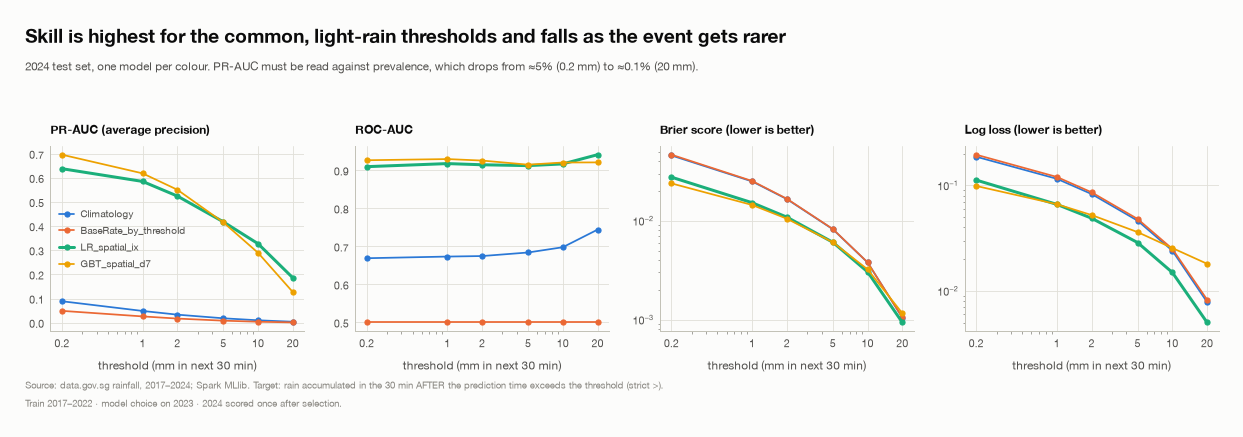

  [figure] outputs/figures/fig11_task2_metrics_by_threshold.png


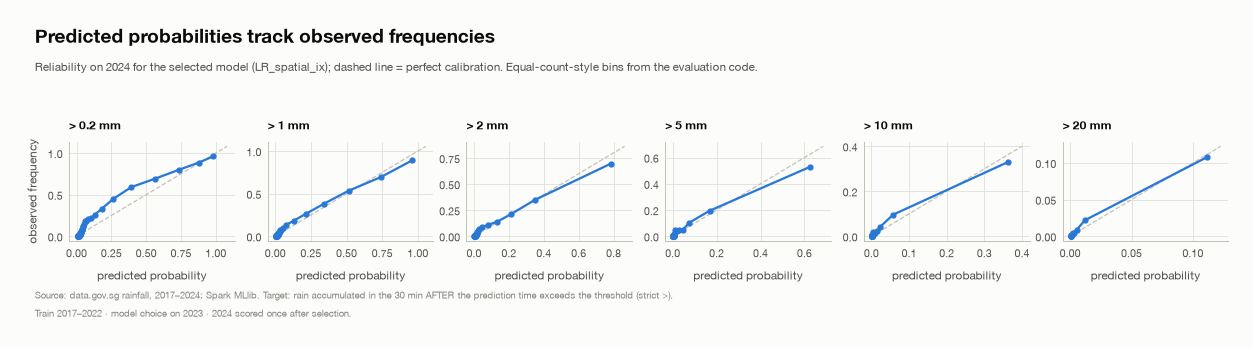

  [figure] outputs/figures/fig12_task2_calibration.png


In [51]:
# --- 11.4 Stage 1 figures --------------------------------------------------------------------------
section('11.4 Stage 1 figures', writes='fig11-fig15, task2_all_figures.pdf')
META = json.loads((MODEL_DIR / "metadata.json").read_text())
SEL = META["selected_model"] + ("+cummin" if META["monotone_postprocess_cummin"] else "")
HEAD = META["headline_thresholds"]
SRC_T2 = ("Source: data.gov.sg rainfall, 2017–2024; Spark MLlib. Target: rain accumulated in the 30 min AFTER the "
          "prediction time exceeds the threshold (strict >).\nTrain 2017–2022 · model choice on 2023 · "
          "2024 scored once after selection.")

def colour_for(models):
    return {m: CAT[i % len(CAT)] for i, m in enumerate(models)}


def fig11_metrics_by_threshold():
    m = T("t30_task2_final_metrics")
    m = m[m["split"] == "test"]
    models = list(dict.fromkeys(m["model"]))
    col = colour_for(models)
    panels = [("pr_auc", "PR-AUC (average precision)", False), ("roc_auc", "ROC-AUC", False),
              ("brier", "Brier score (lower is better)", True), ("logloss", "Log loss (lower is better)", True)]
    fig, axs = plt.subplots(1, 4, figsize=(14, 4.6))
    for ax, (c, lab, logy) in zip(axs, panels):
        for mod in models:
            g = m[m["model"] == mod].sort_values("threshold_mm")
            ax.plot(g["threshold_mm"], g[c], marker="o", ms=4, lw=2.4 if mod == SEL.replace("+cummin", "") else 1.4,
                    color=col[mod], label=mod)
        ax.set_xscale("log")
        if logy:
            ax.set_yscale("log")
        ax.set_xticks(HEAD)
        ax.set_xticklabels([f"{h:g}" for h in HEAD])
        ax.set_xlabel("threshold (mm in next 30 min)")
        ax.set_title(lab, fontsize=9.5, loc="left")
        despine(ax)
    axs[0].legend(frameon=False, fontsize=8)
    layout(fig, header=1.55, footer=1.0, left=0.7)
    titleblock(fig, "Skill is highest for the common, light-rain thresholds and falls as the event gets rarer",
                 "2024 test set, one model per colour. PR-AUC must be read against prevalence, which drops from ≈5% (0.2 mm) to ≈0.1% (20 mm).")
    sourcenote(fig, SRC_T2)
    save_figure(fig, FIGURES / "fig11_task2_metrics_by_threshold.png")


def fig12_calibration():
    r = T("t31_task2_reliability")
    r = r[(r["split"] == "test") & (r["model"] == SEL)]
    fig, axs = plt.subplots(1, len(HEAD), figsize=(14, 3.6), sharex=False, sharey=False)
    for ax, h in zip(np.atleast_1d(axs), HEAD):
        g = r[(r["threshold_mm"] == h) & (r["n_pos"] > 0)]
        hi = max(g["mean_pred"].max(), g["obs_freq"].max()) * 1.1 if len(g) else 1
        ax.plot([0, hi], [0, hi], color=AXIS, lw=1, ls="--")
        ax.plot(g["mean_pred"], g["obs_freq"], marker="o", ms=4, color=CAT[0], lw=1.8)
        ax.set_title(f"> {h:g} mm", fontsize=9.5, loc="left")
        ax.set_xlabel("predicted probability")
        despine(ax)
    np.atleast_1d(axs)[0].set_ylabel("observed frequency")
    layout(fig, header=1.5, footer=1.0, left=0.8)
    titleblock(fig, "Predicted probabilities track observed frequencies",
                 f"Reliability on 2024 for the selected model ({SEL}); dashed line = perfect calibration. Equal-count-style bins from the evaluation code.")
    sourcenote(fig, SRC_T2)
    save_figure(fig, FIGURES / "fig12_task2_calibration.png")


def fig13_pr_curves():
    p = T("t32_task2_pr_curves")
    p = p[(p["split"] == "test") & (p["model"] == SEL)]
    fig, ax = plt.subplots(figsize=(8.2, 5.4))
    for i, h in enumerate(HEAD):
        g = p[p["threshold_mm"] == h].sort_values("recall")
        ax.plot(g["recall"], g["precision"], lw=2, color=CAT[i % len(CAT)], label=f"> {h:g} mm")
    ax.set_xlabel("recall")
    ax.set_ylabel("precision")
    ax.set_ylim(0, 1.02)
    ax.set_xlim(0, 1)
    ax.legend(frameon=False, title="threshold")
    despine(ax)
    layout(fig, header=1.45, footer=1.0, left=0.95)
    titleblock(fig, "Precision falls quickly as recall is pushed up, most steeply for heavy rain",
                 f"Precision–recall curves on 2024, selected model ({SEL}).")
    sourcenote(fig, SRC_T2)
    save_figure(fig, FIGURES / "fig13_task2_pr_curves.png")


def fig14_models_and_effects():
    s = T("t34_task2_macro_summary")
    s = s[s["split"] == "test"].set_index("model")
    fe = T("t37_task2_feature_effects")
    fe = fe[fe["coefficient"].notna()].copy()
    fe["a"] = fe["std_effect"].abs()
    fe = fe.sort_values("a").tail(12)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1, 1.25]})
    metric = "macro_pr_auc"
    a1.barh(s.index, s[metric], color=[CAT[0] if i == SEL.replace("+cummin", "") else MUTED for i in s.index])
    a1.set_xlabel("macro-average PR-AUC over thresholds (2024)")
    despine(a1)
    a2.barh(fe["feature"], fe["std_effect"], color=[CAT[0] if v > 0 else RED for v in fe["std_effect"]])
    a2.set_xlabel("logistic effect per 1 SD of the feature (log-odds)")
    despine(a2)
    layout(fig, header=1.55, footer=1.0, left=2.0)
    titleblock(fig, "Recent rain nearby and the threshold itself dominate; model comparison on the left",
                 "Left: macro PR-AUC on the untouched 2024 test set. Right: largest standardized effects of the best logistic model (fit on training years).")
    sourcenote(fig, SRC_T2)
    save_figure(fig, FIGURES / "fig14_task2_models_and_effects.png")


def fig15_threshold_sweep():
    d = T("t38_task2_threshold_sweep")
    fig, ax = plt.subplots(figsize=(8.6, 5.4))
    for i, (cs, g) in enumerate(d.groupby("case", sort=False)):
        g = g.sort_values("threshold_mm")
        ax.plot(g["threshold_mm"], g["p_final"], lw=2.2, color=CAT[i % len(CAT)], label=cs)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("rainfall threshold (mm in next 30 min)")
    ax.set_ylabel("P(rain > threshold)")
    ax.legend(frameon=False, fontsize=8, title="recent-rain state at prediction time")
    despine(ax)
    st = d["station_id"].iloc[0]
    layout(fig, header=1.45, footer=1.0, left=0.95)
    titleblock(fig, "The model answers for any threshold, and the probability falls as the threshold rises",
                 f"Station {st}, 2024 afternoon prediction times chosen by recent-rain state. Same station, four conditions, 36+ thresholds.")
    sourcenote(fig, SRC_T2)
    save_figure(fig, FIGURES / "fig15_task2_threshold_sweep.png")


open_pdf(FIGURES / "task2_all_figures.pdf", title="Task 2 figures")
fig11_metrics_by_threshold()
fig12_calibration()

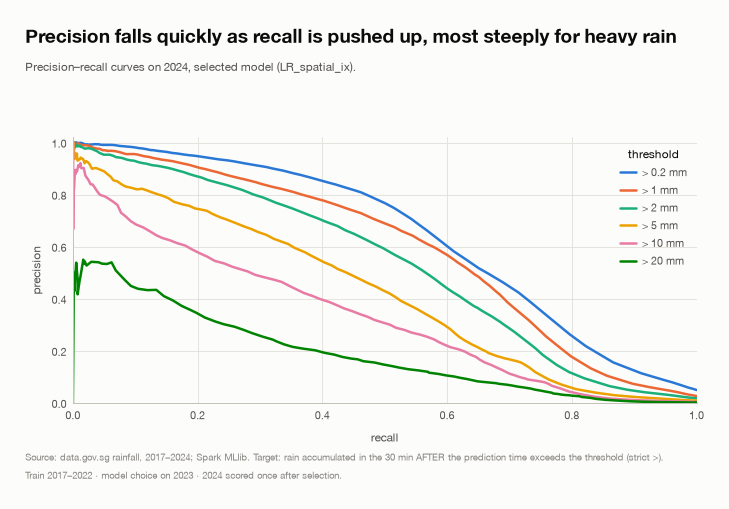

  [figure] outputs/figures/fig13_task2_pr_curves.png


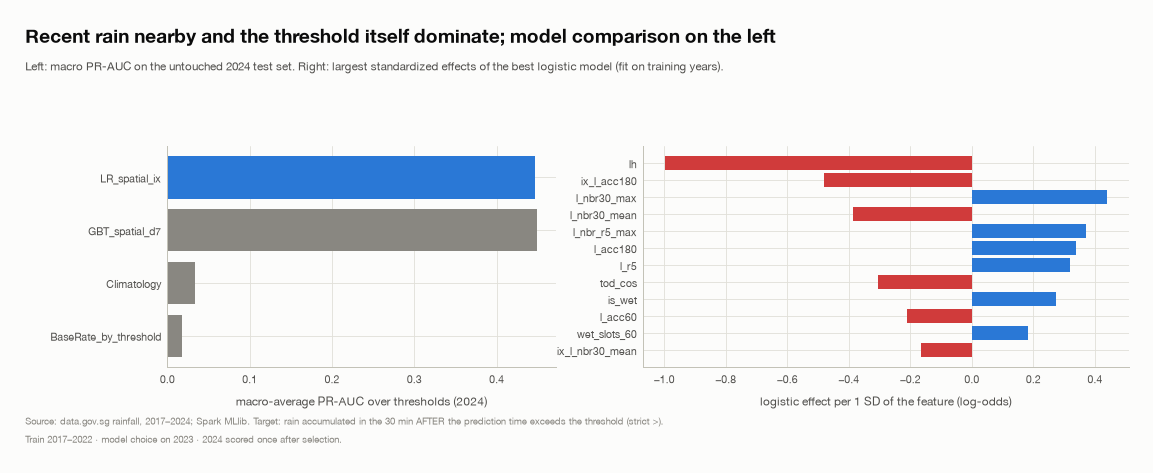

  [figure] outputs/figures/fig14_task2_models_and_effects.png


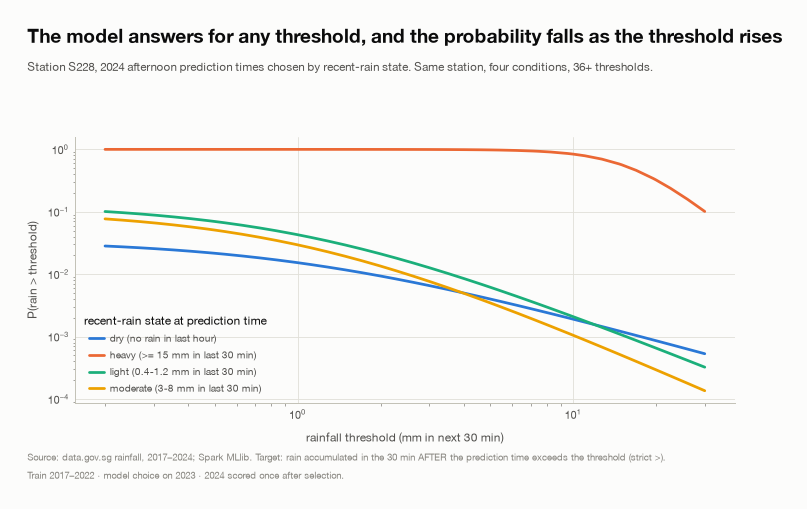

  [figure] outputs/figures/fig15_task2_threshold_sweep.png
Task 2 figures collected in outputs/figures/task2_all_figures.pdf


In [52]:
# --- 11.4 Stage 1 figures (continued) --------------------------------------------------------------
fig13_pr_curves()
fig14_models_and_effects()
fig15_threshold_sweep()
close_pdf()
print("Task 2 figures collected in outputs/figures/task2_all_figures.pdf")

Stage 1 results on the 2024 test year.

* The selected logistic model beats both baselines at every threshold. Across the six thresholds, its mean PR-AUC
  is 0.446 and ROC-AUC is 0.919, compared with climatology's 0.034 and 0.690. It removes 39 % of climatology's log loss
  and 28 % of its Brier score. Test PR-AUC is close to the 2023 validation value of 0.458, with no large drop after
  the selection year.
* At 5 mm (0.83 % of half-hours), PR-AUC is 0.418, about 50× the event rate, and ROC-AUC is 0.912. The cut-off chosen
  on 2023 catches 44 % of events with 50 % precision (F1 0.47). PR-AUC falls from 0.64 at 0.2 mm to 0.19 at 20 mm as
  events become rarer, while ROC-AUC stays above 0.9 throughout.
* Pooled over all rows, the mean forecast is within 0.1 percentage points of the event rate at every threshold from
  1 mm up (0.82 % vs 0.83 % at 5 mm). The many dry rows dominate this average. Bin by bin, the reliability curves
  stay close to the diagonal but are slightly over-confident in the top bin (0.62 predicted vs 0.53 observed at
  5 mm). At 0.2 mm, the model under-forecasts the middle of the range.
* The probability falls as the threshold rises: 0 violations in 25.8 M adjacent threshold pairs. This holds for every
  physically valid input. The threshold's own coefficient (−1.23 on log(1 + *h*)) outweighs the two positive
  interaction terms because a 30-minute total cannot exceed the 180-minute total and a neighbour maximum cannot
  exceed 4× the neighbour mean.
* After the threshold itself (−1.0 log-odds per standard deviation), the strongest effects are rain at neighbouring
  gauges (their 30-minute maximum and latest 5-minute maximum), the station's own rain in the last 5 minutes and
  last 3 hours, and time of day (higher daytime probabilities, as in Fig 5). Fig 14 and `t37` show these effects.
  The negative threshold × 3-hour-rain interaction means recent rain raises the chance of light rain more than
  heavy rain. Correlated features, such as neighbour mean and maximum, share their effect, so we read their
  coefficients together.
* The GBT ranks about as well (macro PR-AUC 0.446 vs 0.446, ROC-AUC 0.923 vs 0.919), but its log-loss skill is only
  0.02. At 20 mm, its mean forecast is 1.5 % against a 0.1 % event rate. We therefore prefer the calibrated logistic
  model within Stage 1. Stage 2 tests a calibrator and keeps it only if it helps on held-out data. The GBT's scores
  shift slightly between runs (macro PR-AUC 0.446–0.451 over four runs) because Spark's row subsampling for boosting
  depends on data partitioning. The logistic model is deterministic.

---
## 12. Stage 2, the final model: richer features

Stage 1 (Sections 7–11) gives an interpretable logistic model using recent rain at the station and its four nearest
gauges. Its probabilities are well calibrated on average, with the binwise differences noted above. For Stage 2, we
add features describing the current weather and use cross-validation to choose the final model. Section 17 compares
both stages on identical 2024 rows.

| Group | Features | Task 1 evidence |
|---|---|---|
| **Inputs** | threshold `thr`, `log_thr`, station (indexed) | the task's own inputs |
| Time | `hod_sin`, `hod_cos`, `doy_sin`, `doy_cos`, `season_idx` | two diurnal regimes; monsoon seasons (Fig 5) |
| Location | `lat`, `lon` | 2.1× west–east gradient (Fig 7) |
| Recent rain | rain in the last 5 / 15 / 30 / 60 / 180 min; storm trend (`trend15` = last 15 min − the 15 min before); wet slots and peak in the last hour; **minutes since the last rain** (cap 24 h); readings present in the last 1 h / 3 h | events last ~20 min; persistence (Figs 4, 9) |
| Neighbours | gauges ≤ 5 km (inner) and ≤ 10 km (outer), and 5–20 km to the **west** (bearing within ±45°): mean, max and share wet in their last 30 min, availability flags | correlation length ~8.5 km (Fig 8); squall lines arrive from the west |
| Island | share of all gauges wet in their last 30 min, their mean 30-min rain, **rain so far today** at the station | wet days vs dry days |

All windows end at the anchor slot and use time ranges over each station's series. The target `fut30` sums the six
slots after the anchor and is kept only when all six exist, as in Stage 1. Stage 2 also keeps rows with gaps in their
history: the number of readings present is a feature, so missing data is never read as dry. We take prediction rows
every 15 minutes in 2017–2023, since neighbouring 5-minute rows are near-duplicates, and every 5 minutes in 2024.

Neighbour denominators count the ring gauges that have reported on that day up to the prediction time *t*. This
respects the measurement-time boundary; the publication and retrospective-cleaning caveats in Section 4.3 still
apply. `predict()` in Section 18 calls the same functions.

In [53]:
# definitions
# --- 12. Stage 2 definitions: constants, neighbour rings, station / neighbour / island / time features, calibrator inputs ---
from matplotlib import transforms
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.classification import GBTClassifier, LogisticRegression, RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator
from pyspark.ml.feature import (Bucketizer, OneHotEncoder, StandardScaler, StringIndexer, UnivariateFeatureSelector,
                                VarianceThresholdSelector, VectorAssembler)
from pyspark.ml.stat import Correlation
from pyspark.sql import DataFrame
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder
from IPython.display import Markdown

GOLD2 = GOLD / "task2_final"
SEED = 5208
TEST_YEAR = 2024
TRAIN_YEARS = [y for y in YEARS if y < TEST_YEAR]          # 2017-2023 (cross-validation, then the final refit)
TRAIN_STEP_S = 900                                         # training prediction times every 15 min
QUIET_FRAC = 0.03                                          # share of quiet training rows kept (weight 1 / QUIET_FRAC)
THRESH_MIN, THRESH_MAX, THRESH_PER_ROW = 0.2, 60.0, 3      # training thresholds: 3 per row, log-uniform in [0.2, 60] mm
EVAL_THRESHOLDS = [0.5, 1.0, 2.0, 5.0, 10.0, 20.0]
MIN_SINCE_CAP = 1440                                       # "minutes since rain" capped at 24 h
NB_INNER_KM, NB_OUTER_KM, WEST_MAX_KM = 5.0, 10.0, 20.0
RINGS = ["inner", "outer", "west"]
MANDATORY = ["thr", "log_thr"]                             # model inputs that bypass feature selection
KM_PER_DEG_LAT, KM_PER_DEG_LON = 110.574, 111.32 * np.cos(np.radians(1.35))
CV_FRACTION = float(os.environ.get("CV_FRACTION", "0.2"))          # share of the training sample used for CV
CV_PARALLELISM = int(os.environ.get("CV_PARALLELISM", "2"))       # models fitted in parallel by CrossValidator
RERUN_CV = os.environ.get("RERUN_CV", "1") == "1"                 # 0 = reuse outputs/tables/t2_cv_results.csv
FOLD_OF_YEAR = {2017: 0, 2018: 0, 2019: 1, 2020: 1, 2021: 2, 2022: 2, 2023: 3}
FOLD_EXPR = F.create_map(*[F.lit(x) for kv in FOLD_OF_YEAR.items() for x in kv])[F.col("year")]
N_FOLDS, VAL_FOLD = 4, 3                                   # fold 3 (2023) also serves calibration and cut-offs
SEASON_NAMES = [s for s, _ in SEASONS]
MONTH_TO_SEASON = {m: s for s, ms in SEASONS for m in ms}
PALETTE = CAT + ["#6250d6", "#e34948"]
SRC_T2F = ("Source: data.gov.sg rainfall 2017–2024; Spark MLlib. Final model: selected by 4-fold year-blocked "
           "cross-validation on 2017–2023, tested once on 2024.")


def headline(fig, title, subtitle=None, note=None):
    """Finding-first title block above the panels, plus a source footer."""
    n_sub = 0 if not subtitle else subtitle.count("\n") + 1
    if subtitle:
        fig.text(0.01, 1.0, subtitle, transform=transforms.offset_copy(fig.transFigure, fig=fig, y=8, units="points"),
                 ha="left", va="bottom", fontsize=9.5, color=INK_2, linespacing=1.5)
    fig.text(0.01, 1.0, title, transform=transforms.offset_copy(fig.transFigure, fig=fig, y=14 + 15 * n_sub, units="points"),
             ha="left", va="bottom", fontsize=14, fontweight="bold", color=INK)
    fig.text(0.01, 0.0, SRC_T2F + (f"\n{note}" if note else ""),
             transform=transforms.offset_copy(fig.transFigure, fig=fig, y=-28, units="points"),
             ha="left", va="top", fontsize=7.5, color=MUTED, linespacing=1.5)


def station_distances(st):
    """Pairwise distances (km) and east/north offsets between stations; st has station_id, lat, lon."""
    a = st[["station_id", "lat", "lon"]].reset_index(drop=True)
    p = a.merge(a, how="cross", suffixes=("", "_nb"))
    p = p[p.station_id != p.station_id_nb].copy()
    p["dx_km"] = (p.lon_nb - p.lon) * KM_PER_DEG_LON        # + = neighbour is east
    p["dy_km"] = (p.lat_nb - p.lat) * KM_PER_DEG_LAT        # + = neighbour is north
    p["km"] = np.hypot(p.dx_km, p.dy_km)
    return p.rename(columns={"station_id_nb": "nb_id"})[["station_id", "nb_id", "km", "dx_km", "dy_km"]]


def ring_pairs(st):
    """Station -> neighbour pairs with ring membership (inner <= 5 km, outer <= 10 km, west 5-20 km)."""
    p = station_distances(st)
    p = p[p.km <= WEST_MAX_KM].copy()
    p["inner"] = (p.km <= NB_INNER_KM).astype(int)
    p["outer"] = (p.km <= NB_OUTER_KM).astype(int)
    p["west"] = ((p.km > NB_INNER_KM) & (p.dx_km < 0) & (p.dy_km.abs() <= -p.dx_km)).astype(int)
    return p


def station_features(sv):
    """Station-level features (windows ending at the slot) and the target fut30 (the six slots after it)."""
    w = Window.partitionBy("station_id").orderBy("slot_epoch")
    rng = lambda a, b: w.rangeBetween(a, b)
    wet = (F.col("rain_mm") > 0).cast("int")
    w_day = Window.partitionBy("station_id", "date").orderBy("slot_epoch").rowsBetween(Window.unboundedPreceding, 0)
    last_wet = F.last(F.when(F.col("rain_mm") > 0, F.col("slot_epoch")), ignorenulls=True) \
                .over(w.rowsBetween(Window.unboundedPreceding, 0))
    return (sv
        .withColumn("r5", F.col("rain_mm"))
        .withColumn("r15", F.sum("rain_mm").over(rng(-600, 0)))
        .withColumn("r30", F.sum("rain_mm").over(rng(-1500, 0)))
        .withColumn("r60", F.sum("rain_mm").over(rng(-3300, 0)))
        .withColumn("r180", F.sum("rain_mm").over(rng(-10500, 0)))
        .withColumn("prev15", F.coalesce(F.sum("rain_mm").over(rng(-1500, -900)), F.lit(0.0)))
        .withColumn("trend15", F.col("r15") - F.col("prev15"))
        .withColumn("wet_slots_60", F.sum(wet).over(rng(-3300, 0)))
        .withColumn("peak5_60", F.max("rain_mm").over(rng(-3300, 0)))
        .withColumn("n_obs_60", F.count("*").over(rng(-3300, 0)))
        .withColumn("n_obs_180", F.count("*").over(rng(-10500, 0)))
        .withColumn("min_since_rain", F.least(F.coalesce((F.col("slot_epoch") - last_wet) / 60.0,
                                                         F.lit(float(MIN_SINCE_CAP))), F.lit(float(MIN_SINCE_CAP))))
        .withColumn("rain_today", F.sum("rain_mm").over(w_day))
        .withColumn("fut30", F.sum("rain_mm").over(rng(300, 1800)))
        .withColumn("n_fut", F.count("*").over(rng(300, 1800))))


def neighbour_island_features(sfx, history, pairs_sp):
    """Neighbour-ring and island features at the slots of `sfx` (station-feature rows).

    Sums, maxima and wet counts come from neighbours' own trailing 30-min rain at the same slot. The denominator of
    each ring is the number of its gauges that have reported on that day up to the slot (first reading <= slot), so
    nothing after the prediction time is used. `history` = the readings the first-reading times come from.
    """
    wet30 = sfx.filter(F.col("r30") > 0).select(F.col("station_id").alias("nb_id"), "slot_epoch", F.col("r30").alias("nb_r30"))
    agg = []
    for ring in RINGS:
        on = F.col(ring) == 1
        agg += [F.sum(F.when(on, F.col("nb_r30"))).alias(f"{ring}_sum"),
                F.max(F.when(on, F.col("nb_r30"))).alias(f"{ring}_max"),
                F.sum(on.cast("int")).alias(f"{ring}_wet")]
    nb_wet = wet30.join(pairs_sp, "nb_id").groupBy("station_id", "slot_epoch").agg(*agg)
    first_seen = (history.groupBy(F.col("station_id").alias("nb_id"), "date").agg(F.min("slot_epoch").alias("first_epoch"))
                  .join(pairs_sp, "nb_id").groupBy("station_id", "date")
                  .agg(*[F.collect_list(F.when(F.col(r) == 1, F.col("first_epoch"))).alias(f"{r}_first") for r in RINGS]))
    island = (sfx.groupBy("slot_epoch").agg(F.avg((F.col("r30") > 0).cast("double")).alias("island_wetfrac"),
                                            F.avg("r30").alias("island_mean_r30")))
    nb = (sfx.select("station_id", "slot_epoch", "date", "year")
          .join(nb_wet, ["station_id", "slot_epoch"], "left")
          .join(first_seen, ["station_id", "date"], "left")
          .join(island, "slot_epoch", "left"))
    for ring in RINGS:
        first = F.col(f"{ring}_first")
        n = F.when(first.isNull(), F.lit(0)).otherwise(F.size(F.filter(first, lambda x: x <= F.col("slot_epoch"))))
        nb = (nb.withColumn(f"{ring}_n", n)
                .withColumn(f"has_{ring}", (F.col(f"{ring}_n") > 0).cast("int"))
                .withColumn(f"{ring}_mean", F.when(F.col(f"{ring}_n") > 0, F.coalesce(F.col(f"{ring}_sum"), F.lit(0.0)) / F.col(f"{ring}_n")).otherwise(-1.0))
                .withColumn(f"{ring}_max", F.when(F.col(f"{ring}_n") > 0, F.coalesce(F.col(f"{ring}_max"), F.lit(0.0))).otherwise(-1.0))
                .withColumn(f"{ring}_wetfrac", F.when(F.col(f"{ring}_n") > 0, F.coalesce(F.col(f"{ring}_wet"), F.lit(0)) / F.col(f"{ring}_n")).otherwise(-1.0))
                .drop(f"{ring}_sum", f"{ring}_wet", f"{ring}_n", f"{ring}_first"))
    return nb.drop("date")


def add_final_time_features(df):
    """Calendar features of the anchor slot (hour/day of year as sine-cosine pairs, season index)."""
    hod = F.col("hour") + F.minute("slot_ts") / 60.0
    doy = F.dayofyear("slot_ts")
    season = season_col(F.col("month"))
    season_idx = (F.when(season == SEASON_NAMES[0], 0).when(season == SEASON_NAMES[1], 1)
                  .when(season == SEASON_NAMES[2], 2).otherwise(3).cast("double"))
    return (df.withColumn("hod_sin", F.sin(2 * math.pi * hod / 24)).withColumn("hod_cos", F.cos(2 * math.pi * hod / 24))
              .withColumn("doy_sin", F.sin(2 * math.pi * doy / 365.25)).withColumn("doy_cos", F.cos(2 * math.pi * doy / 365.25))
              .withColumn("season", season).withColumn("season_idx", season_idx))


def add_logit(df, pcol="p_raw"):
    """Inputs of the calibrator: logit of the raw probability and its product with log(threshold)."""
    pc = F.least(F.greatest(F.col(pcol), F.lit(1e-6)), F.lit(1 - 1e-6))
    return df.withColumn("z", F.log(pc / (1 - pc))).withColumn("z_lt", F.col("z") * F.col("log_thr"))

In [54]:
# --- 12a. Stage 2 station features and target (window functions over each gauge's series) ----------
section("12a. Stage 2 station features and target (window functions over each gauge's series)", purpose='a richer recent-rain state: five windows, storm trend, minutes since rain, readings present, rain so far today', writes='data_parquet/gold/task2_final/station_features/')
spark.catalog.clearCache()                                  # Stage 1 caches are no longer needed
spark.conf.set("spark.sql.shuffle.partitions", "64")
silver2 = (spark.read.parquet(str(SILVER / "readings"))
           .withColumn("slot_epoch", F.col("ts").cast("long")).withColumn("slot_ts", F.col("ts")))
stations = spark.read.parquet(str(SILVER / "stations")).toPandas()

with timed("12a. final-model station features + target (window functions)"):
    station_features(silver2).write.mode("overwrite").partitionBy("year").parquet(str(GOLD2 / "station_features"))
sf = spark.read.parquet(str(GOLD2 / "station_features"))
step(f"station-feature rows: {sf.count():,} (one per silver reading)")
sf.filter("rain_mm > 0").select("station_id", "slot_ts", "r5", "r15", "r30", "trend15", "min_since_rain",
                                "rain_today", "fut30", "n_fut").limit(5).toPandas()

08:10:50  12a. Stage 2 station features and target (window functions over each gauge's series)
Purpose : a richer recent-rain state: five windows, storm trend, minutes since rain, readings present, rain so far today
Writes  : data_parquet/gold/task2_final/station_features/


[08:11:19]  done: 12a. final-model station features + target (window functions)  (28.8 s)
[08:11:19]  station-feature rows: 48,338,938 (one per silver reading)


,station_id,slot_ts,r5,r15,r30,trend15,min_since_rain,rain_today,fut30,n_fut
0,S79,2021-11-01 14:15:00,2.4,2.4,2.4,2.4,0.0,2.6,24.6,6
1,S79,2021-11-01 14:20:00,4.0,6.4,6.4,6.4,0.0,6.6,20.6,6
2,S79,2021-11-01 14:25:00,10.4,16.8,16.8,16.8,0.0,17.0,10.2,6
3,S79,2021-11-01 14:30:00,8.2,22.6,25.0,20.2,0.0,25.2,2.0,6
4,S79,2021-11-01 14:35:00,1.2,19.8,26.2,13.4,0.0,26.4,0.8,6


In [55]:
# --- 12b. Neighbour rings and island-wide features (sparse join) -----------------------------------
section('12b. Neighbour rings and island-wide features (sparse join)', purpose='inner <= 5 km, outer <= 10 km, west 5-20 km; denominators count only gauges that have reported by the prediction time', writes='data_parquet/gold/task2_final/neighbour_features/')
pairs = ring_pairs(stations)
step(f"ring edges: {len(pairs):,} pairs within {WEST_MAX_KM:g} km (inner {int(pairs.inner.sum())}, outer {int(pairs.outer.sum())}, west {int(pairs.west.sum())})")
print("neighbours per station (mean / min / max):")
display(pairs.groupby("station_id")[RINGS].sum().describe().loc[["mean", "min", "max"]].round(1))
pairs_sp = F.broadcast(spark.createDataFrame(pairs[["station_id", "nb_id"] + RINGS]))

# prediction slots: every 15 min in the training years, every 5 min in the test year
is_pred_slot = (F.col("year") == TEST_YEAR) | ((F.col("slot_epoch") % TRAIN_STEP_S) == 0)
with timed("12b. neighbour + island features (sparse join)"):
    (neighbour_island_features(sf.filter(is_pred_slot), silver2, pairs_sp)
     .write.mode("overwrite").partitionBy("year").parquet(str(GOLD2 / "neighbour_features")))
nbf_ = spark.read.parquet(str(GOLD2 / "neighbour_features"))

08:11:19  12b. Neighbour rings and island-wide features (sparse join)
Purpose : inner <= 5 km, outer <= 10 km, west 5-20 km; denominators count only gauges that have reported by the prediction time
Writes  : data_parquet/gold/task2_final/neighbour_features/
[08:11:19]  ring edges: 6,466 pairs within 20 km (inner 780, outer 2670, west 1804)
neighbours per station (mean / min / max):


,inner,outer,west
mean,8.6,29.3,19.8
min,0.0,1.0,0.0
max,17.0,50.0,45.0


[08:11:43]  done: 12b. neighbour + island features (sparse join)  (23.7 s)


### 12.1 Prediction rows, split and the Stage 2 climatology baseline

Each prediction row is a (station, slot) pair with a complete future window. We split 2017–2023 into four year-blocked
folds (2017–18, 2019–20, 2021–22, 2023) for cross-validation and reserve 2024 for the final test. As in Stage 1, we drop
training rows whose 30-minute target window reaches into 2024 (the last six slots of 31 December 2023), so test-year
rain cannot enter a training label.

The three boundaries between folds are not purged. About 370 rows, at 23:30 and 23:45 on 31 December 2018, 2020 and
2022, have target windows reaching up to 20 minutes into the next fold. They account for a negligible share of the
13.7 M rows, but do weaken the isolation between folds.

The climatology baseline estimates P(fut30 > threshold) per station × month × hour from the training years, shrunk
towards the island-wide month × hour rate with pseudo-count 50.

In [56]:
# --- 12c-d. Prediction rows, year-blocked folds and the Stage 2 climatology baseline ---------------
section('12c-d. Prediction rows, year-blocked folds and the Stage 2 climatology baseline', purpose='one row per (station, slot) with a complete future window; folds = blocks of whole years', writes='data_parquet/gold/task2_final/rows/, t2_rows_per_year')
st_sp = F.broadcast(spark.createDataFrame(stations[["station_id", "lat", "lon"]]))
with timed("12c. prediction rows"):
    rows = (add_final_time_features(sf.filter(is_pred_slot & (F.col("n_fut") == 6))
                                    .join(nbf_.drop("year"), ["station_id", "slot_epoch"], "left")
                                    .join(st_sp, "station_id"))
            .withColumn("fold", FOLD_EXPR.cast("int"))
            .drop("rain_mm", "prev15"))
    rows.write.mode("overwrite").partitionBy("year").parquet(str(GOLD2 / "rows"))
rows = spark.read.parquet(str(GOLD2 / "rows"))
TEST_START_EPOCH = int(pd.Timestamp(f"{TEST_YEAR}-01-01").tz_localize("Asia/Singapore").timestamp())
# purge the train/test boundary: a training row's 30-minute target window (the six slots after the anchor) must end
# before the first second of the test year, otherwise its label would be built from test-year rain
train_rows = rows.filter(F.col("year").isin(TRAIN_YEARS) & (F.col("slot_epoch") + 1800 < TEST_START_EPOCH))
n_purged = rows.filter(F.col("year").isin(TRAIN_YEARS) & (F.col("slot_epoch") + 1800 >= TEST_START_EPOCH)).count()
step(f"boundary purge: {n_purged} training rows whose target window reaches into {TEST_YEAR} dropped")
test_rows = rows.filter(F.col("year") == TEST_YEAR)

with timed("12d. row counts + climatology"):
    counts = rows.groupBy("year").agg(F.count("*").alias("rows"),
                                       F.avg((F.col("fut30") > 0).cast("double")).alias("share_wet_next30")).orderBy("year").toPandas()
    k = [F.sum((F.col("fut30") > t).cast("long")).alias(f"k_{i}") for i, t in enumerate(EVAL_THRESHOLDS)]
    clim_smh = train_rows.groupBy("station_id", "month", "hour").agg(F.count("*").alias("n"), *k).toPandas()
clim_mh = clim_smh.groupby(["month", "hour"])[["n"] + [f"k_{i}" for i in range(len(EVAL_THRESHOLDS))]].sum()
clim_rows = []
for i, t in enumerate(EVAL_THRESHOLDS):
    p_mh = (clim_mh[f"k_{i}"] / clim_mh["n"]).rename("p_mh")
    c = clim_smh[["station_id", "month", "hour", "n", f"k_{i}"]].merge(p_mh, left_on=["month", "hour"], right_index=True)
    c["p_clim"] = (c[f"k_{i}"] + 50 * c.p_mh) / (c.n + 50)
    clim_rows.append(c[["station_id", "month", "hour", "p_clim"]].assign(thr=t))
clim = pd.concat(clim_rows)
clim_mh_tab = pd.concat([(clim_mh[f"k_{i}"] / clim_mh["n"]).rename("p_mh").reset_index().assign(thr=t)
                         for i, t in enumerate(EVAL_THRESHOLDS)])
write_table(counts, "t2_rows_per_year")
checkpoint("12c. Prediction rows", [("rows 2017-2023 (every 15 min)", f"{int(counts[counts.year < TEST_YEAR].rows.sum()):,}"),
    (f"rows {TEST_YEAR} (every 5 min, the test year)", f"{int(counts[counts.year == TEST_YEAR].rows.sum()):,}"),
    ("share of rows with rain in the next 30 min", f"{100 * (counts.rows * counts.share_wet_next30).sum() / counts.rows.sum():.2f} %"),
    ("folds", f"{N_FOLDS} year blocks: {FOLD_OF_YEAR}"),
    ("climatology cells (station x month x hour)", f"{len(clim_smh):,}")])
counts

08:11:43  12c-d. Prediction rows, year-blocked folds and the Stage 2 climatology baseline
Purpose : one row per (station, slot) with a complete future window; folds = blocks of whole years
Writes  : data_parquet/gold/task2_final/rows/, t2_rows_per_year


[08:11:55]  done: 12c. prediction rows  (11.7 s)


[08:11:55]  boundary purge: 126 training rows whose target window reaches into 2024 dropped


[08:11:55]  done: 12d. row counts + climatology  (0.6 s)
  [table] outputs/tables/t2_rows_per_year.csv  (8 rows)

-- 12c. Prediction rows ------------------------------------------------------------------------
   rows 2017-2023 (every 15 min)              : 13,695,907
   rows 2024 (every 5 min, the test year)     : 6,371,188
   share of rows with rain in the next 30 min : 6.21 %
   folds                                      : 4 year blocks: {2017: 0, 2018: 0, 2019: 1, 2020: 1, 2021: 2, 2022: 2, 2023: 3}
   climatology cells (station x month x hour) : 24,456



,year,rows,share_wet_next30
0,2017,1668957,0.061592
1,2018,1358288,0.065706
2,2019,1646426,0.040343
3,2020,2091475,0.065333
4,2021,2329643,0.061203
5,2022,2365333,0.064938
6,2023,2235785,0.066923
7,2024,6371188,0.063634


### 12.2 Leakage check for the Stage 2 features

We check the window calculations with an independent pandas recomputation, as in Section 7.1. For 300 random
prediction rows, we recompute every station feature from the cleaned readings after removing data beyond the anchor,
and check the target against the six future slots. For 30 of these rows, we also recompute the neighbour-ring and
island features from every gauge's readings up to the anchor. Agreement checks the time boundary for these sampled
rows; it does not establish that the readings had been published by the prediction time.

In [57]:
# --- 12.2 Leakage check for the Stage 2 features ---------------------------------------------------
section('12.2 Leakage check for the Stage 2 features', purpose='recompute station, neighbour-ring and island features of random rows from data truncated at the anchor')
STATION_COLS = ["r5", "r15", "r30", "r60", "r180", "trend15", "wet_slots_60", "peak5_60", "n_obs_60", "n_obs_180",
                "min_since_rain", "rain_today"]
RING_COLS = [f"{r}_{s}" for r in RINGS for s in ["mean", "max", "wetfrac"]] + ["island_wetfrac", "island_mean_r30"]
with timed("12e. leakage check (Stage 2 features)"):
    smp = rows.withColumn("k", F.rand(7)).orderBy("k").limit(300).drop("k").cache()
    sm = smp.select("station_id", "slot_epoch", F.date_format("slot_ts", "yyyy-MM-dd").alias("d_a"),
                    *STATION_COLS, *RING_COLS, "fut30", "n_fut").toPandas()
    rd = silver2.select("station_id", "slot_epoch", "rain_mm", F.date_format("ts", "yyyy-MM-dd").alias("d"))
    win = (smp.select("station_id", F.col("slot_epoch").alias("a")).join(rd, "station_id")
           .filter((F.col("slot_epoch") > F.col("a") - 86400 - 300) & (F.col("slot_epoch") <= F.col("a") + 1800))
           .toPandas())
    for x in sm.itertuples():
        a = x.slot_epoch
        g = win[(win.station_id == x.station_id) & (win.a == a)]
        past = g[g.slot_epoch <= a]                                     # nothing after the anchor is visible
        span = lambda lo_s, hi_s: past[(past.slot_epoch >= a + lo_s) & (past.slot_epoch <= a + hi_s)].rain_mm
        w60 = span(-3300, 0)
        wets = past[past.rain_mm > 0].slot_epoch
        exp = {"r5": past[past.slot_epoch == a].rain_mm.iloc[0], "r15": span(-600, 0).sum(), "r30": span(-1500, 0).sum(),
               "r60": w60.sum(), "r180": span(-10500, 0).sum(),
               "trend15": span(-600, 0).sum() - span(-1500, -900).sum(),
               "wet_slots_60": int((w60 > 0).sum()), "peak5_60": w60.max(), "n_obs_60": len(w60),
               "n_obs_180": len(span(-10500, 0)),
               "min_since_rain": MIN_SINCE_CAP if wets.empty else min((a - wets.max()) / 60.0, MIN_SINCE_CAP),
               "rain_today": past[past.d == x.d_a].rain_mm.sum()}
        for c_ in STATION_COLS:
            assert np.isclose(exp[c_], getattr(x, c_), atol=1e-6), (c_, x.station_id, a, exp[c_], getattr(x, c_))
        fut = g[(g.slot_epoch >= a + 300) & (g.slot_epoch <= a + 1800)]
        assert len(fut) == 6 and x.n_fut == 6 and np.isclose(fut.rain_mm.sum(), x.fut30, atol=1e-6)
    print("[ok] 300 random rows: station features and target match a recomputation from data truncated at the anchor")

    sub = sm.head(30).copy()
    sub["day0"] = [int(pd.Timestamp(d).tz_localize("Asia/Singapore").timestamp()) for d in sub.d_a]
    sub["lo_e"] = np.minimum(sub.day0, sub.slot_epoch - 1500)
    anc = spark.createDataFrame(sub[["slot_epoch", "lo_e"]].drop_duplicates().rename(columns={"slot_epoch": "a"}))
    allr = (rd.join(F.broadcast(anc), (F.col("slot_epoch") >= F.col("lo_e")) & (F.col("slot_epoch") <= F.col("a")))
            .toPandas())
    for x in sub.itertuples():
        a = x.slot_epoch
        A = allr[allr.a == a]
        r30 = A[A.slot_epoch >= a - 1500].groupby("station_id").rain_mm.sum()
        at_slot = set(A[A.slot_epoch == a].station_id)                  # gauges with a reading at the anchor
        first = A[A.d == x.d_a].groupby("station_id").slot_epoch.min()  # first reading of the day, all <= anchor
        exp = {"island_wetfrac": np.mean([r30[s] > 0 for s in at_slot]),
               "island_mean_r30": np.mean([r30[s] for s in at_slot])}
        for ring in RINGS:
            nbs = pairs[(pairs.station_id == x.station_id) & (pairs[ring] == 1)].nb_id
            n = sum(nb in first.index for nb in nbs)
            wet = [r30[nb] for nb in nbs if nb in at_slot and r30[nb] > 0]
            exp[f"{ring}_mean"] = sum(wet) / n if n else -1.0
            exp[f"{ring}_max"] = max(wet) if wet else (0.0 if n else -1.0)
            exp[f"{ring}_wetfrac"] = len(wet) / n if n else -1.0
        for c_ in RING_COLS:
            assert np.isclose(exp[c_], getattr(x, c_), atol=1e-6), (c_, x.station_id, a, exp[c_], getattr(x, c_))
    print("[ok] 30 random rows: neighbour-ring and island features match a recomputation from all gauges up to the anchor")
checkpoint("12.2 Leakage checks", [("station features + target, 300 random rows", "passed"),
                                   ("neighbour rings + island features, 30 random rows", "passed")])
smp.unpersist()

08:11:56  12.2 Leakage check for the Stage 2 features
Purpose : recompute station, neighbour-ring and island features of random rows from data truncated at the anchor


[ok] 300 random rows: station features and target match a recomputation from data truncated at the anchor


[ok] 30 random rows: neighbour-ring and island features match a recomputation from all gauges up to the anchor
[08:12:01]  done: 12e. leakage check (Stage 2 features)  (5.5 s)

-- 12.2 Leakage checks -------------------------------------------------------------------------
   station features + target, 300 random rows        : passed
   neighbour rings + island features, 30 random rows : passed



DataFrame[station_id: string, slot_epoch: bigint, ts: timestamp, month: int, doy: int, date: date, hour: int, minute_of_day: int, slot_ts: timestamp, r5: double, r15: double, r30: double, r60: double, r180: double, trend15: double, wet_slots_60: bigint, peak5_60: double, n_obs_60: bigint, n_obs_180: bigint, min_since_rain: double, rain_today: double, fut30: double, n_fut: bigint, inner_max: double, outer_max: double, west_max: double, island_wetfrac: double, island_mean_r30: double, has_inner: int, inner_mean: double, inner_wetfrac: double, has_outer: int, outer_mean: double, outer_wetfrac: double, has_west: int, west_mean: double, west_wetfrac: double, lat: double, lon: double, hod_sin: double, hod_cos: double, doy_sin: double, doy_cos: double, season: string, season_idx: double, fold: int, year: int]

### 12.3 Training sample: weighted down-sampling and the threshold as a feature

We keep all active rows, defined as rain in the last 3 h or in the next 30 min. This includes cases where rain starts
after a dry spell. Quiet rows, dry for 3 h before and 30 min after, are kept with probability 3 % and given weight
1 / 0.03 ≈ 33.3. MLlib models and evaluators apply these weights through `weightCol`.

Unlike Stage 1, selection depends on the outcome: a row is always kept when rain falls in the next 30 minutes. The
unweighted sample therefore over-represents rain. Inverse inclusion weights, 1 for active rows and 1 / 0.03 for kept
quiet rows, make each weighted sum an unbiased estimate of the population sum (Horvitz–Thompson). The cell below
reports weighted and unweighted positive rates and compares the weighted row count with the population count.
Calibration is assessed separately.

We pair each kept row with 3 thresholds drawn log-uniformly from 0.2–60 mm, independently of the outcome, and assign
`label = fut30 > threshold`. The test year is neither sampled nor weighted: every row is scored at 0.5, 1, 2, 5, 10
and 20 mm.

In [58]:
# --- 12.3 Training sample: weighted down-sampling and the threshold as a feature -------------------
section('12.3 Training sample: weighted down-sampling and the threshold as a feature', purpose='all active rows + 3 % of quiet rows with weight 33; three log-uniform thresholds per row', writes='data_parquet/gold/task2_final/train/')
lo_t, hi_t = math.log(THRESH_MIN), math.log(THRESH_MAX)
with timed("12f. training sample (down-sampling + threshold expansion)"):
    active = (F.col("r180") > 0) | (F.col("fut30") > 0)
    (train_rows.withColumn("u", F.rand(SEED))
     .filter(active | (F.col("u") < QUIET_FRAC))
     .withColumn("w", F.when(active, 1.0).otherwise(1.0 / QUIET_FRAC))
     .withColumn("thr", F.explode(F.array(*[F.exp(F.lit(lo_t) + F.rand(SEED + 1 + j) * F.lit(hi_t - lo_t))
                                            for j in range(THRESH_PER_ROW)])))
     .withColumn("log_thr", F.log("thr"))
     .withColumn("label", (F.col("fut30") > F.col("thr")).cast("double"))
     .drop("u")
     .write.mode("overwrite").parquet(str(GOLD2 / "train")))
train2 = spark.read.parquet(str(GOLD2 / "train"))
n_train_rows = train_rows.count()
sample_summary = (train2.groupBy("fold").agg(F.count("*").alias("rows"), F.sum("w").alias("weighted_rows"),
                                             F.avg("label").alias("pos_rate_unweighted"),
                                             (F.sum(F.col("w") * F.col("label")) / F.sum("w")).alias("pos_rate_weighted"))
                  .orderBy("fold").toPandas())
checkpoint("12.3 Training sample", [("prediction rows 2017-2023", f"{n_train_rows:,}"),
    (f"kept rows x {THRESH_PER_ROW} thresholds", f"{int(sample_summary.rows.sum()):,}"),
    ("weighted rows / thresholds", f"{sample_summary.weighted_rows.sum() / THRESH_PER_ROW:,.0f} (should be close to the row count above)"),
    ("positive rate: unweighted / weighted", f"{100 * (sample_summary.rows * sample_summary.pos_rate_unweighted).sum() / sample_summary.rows.sum():.2f} % / "
                                            f"{100 * (sample_summary.weighted_rows * sample_summary.pos_rate_weighted).sum() / sample_summary.weighted_rows.sum():.2f} % (weights restore the true mix)")])
sample_summary

08:12:01  12.3 Training sample: weighted down-sampling and the threshold as a feature
Purpose : all active rows + 3 % of quiet rows with weight 33; three log-uniform thresholds per row
Writes  : data_parquet/gold/task2_final/train/


[08:12:03]  done: 12f. training sample (down-sampling + threshold expansion)  (2.4 s)



-- 12.3 Training sample ------------------------------------------------------------------------
   prediction rows 2017-2023            : 13,695,781
   kept rows x 3 thresholds             : 7,782,555
   weighted rows / thresholds           : 13,680,477 (should be close to the row count above)
   positive rate: unweighted / weighted : 8.21 % / 1.56 % (weights restore the true mix)



,fold,rows,weighted_rows,pos_rate_unweighted,pos_rate_weighted
0,0,1795275,9.058441e+06,0.077772,0.015413
1,1,1957458,1.122086e+07,0.078605,0.013712
2,2,2714052,1.405655e+07,0.085445,0.016498
3,3,1315770,6.705575e+06,0.086378,0.016949


### 12.4 How Spark executes these steps: narrow and wide transformations, join strategies, AQE

Narrow operations such as `filter`, `select` and `withColumn` work within partitions without moving rows between
them. Wide operations such as `groupBy`, window functions, joins and `distinct` bring rows with the same key
together, which can require a shuffle. These shuffles account for much of this pipeline's cost.

For these joins, Spark prefers a broadcast hash join when one side is small enough to copy to every executor:
below `spark.sql.autoBroadcastJoinThreshold` (10 MB by default), or when hinted with `F.broadcast`. Otherwise, it
prefers a sort-merge join for sortable keys, or a shuffle hash join. Adaptive Query Execution (AQE), enabled by
default since Spark 3.2, uses runtime partition sizes to revise the plan. It can coalesce small post-shuffle
partitions, switch a sort-merge join to a broadcast join, and split skewed partitions. The next cell prints the
physical plans for two joins in this section and the final plan of a grouped query after AQE has run.

In [59]:
# --- 12.4 Join strategies and adaptive query execution: the physical plans Spark chose ------------------
section("12.4 How Spark executes the joins: join strategy and adaptive query execution (AQE)",
        purpose="show the physical plan of a small x large and a large x large join, and AQE re-planning a grouped query at run time",
        writes="t46_spark_plans.txt")
import re as re_
KEY_OPS = r"(AdaptiveSparkPlan|BroadcastHashJoin|SortMergeJoin|ShuffledHashJoin|BroadcastExchange|Exchange|AQEShuffleRead|HashAggregate)"


def physical_plan(df):
    """The physical plan Spark will run (under AQE: the initial plan until the query has executed)."""
    return df._jdf.queryExecution().executedPlan().toString()


def key_lines(plan, n=10):
    plan = plan.split("== Initial Plan ==")[0]                                   # AQE: keep the final plan only
    out = [re_.sub(r"\[[^\[\]]{40,}\]", "[...]", ln.rstrip()) for ln in plan.splitlines() if re_.search(KEY_OPS, ln)]
    return [ln[:140] for ln in out[:n]]


wet_nb = sf.filter(F.col("r30") > 0).select(F.col("station_id").alias("nb_id"), "slot_epoch", "r30")
pairs_plain = spark.createDataFrame(pairs[["station_id", "nb_id"] + RINGS])            # the same table without a hint
demos = {
    "small x large, F.broadcast hint (neighbour rings)": wet_nb.join(pairs_sp, "nb_id"),
    "small x large, no hint (Spark decides)": wet_nb.join(pairs_plain, "nb_id"),
    "large x large (station features x neighbour features)": sf.join(nbf_.drop("year"), ["station_id", "slot_epoch"], "left"),
}
plans = {k: physical_plan(v) for k, v in demos.items()}
aqe_q = silver2.groupBy("year").agg(F.sum("rain_mm").alias("mm"))                       # 64 shuffle partitions, 8 groups
aqe_q.collect()                                                                          # run it, so AQE finalises the plan
plans["grouped aggregation after it ran (AQE final plan)"] = physical_plan(aqe_q)
with open(TABLES / "t46_spark_plans.txt", "w") as fh:
    for k, p in plans.items():
        fh.write(f"===== {k}\n{p}\n\n")
for k, p in plans.items():
    print(f"--- {k}")
    print("\n".join("   " + ln for ln in key_lines(p)))
strategy = lambda p: next((j for j in ("BroadcastHashJoin", "SortMergeJoin", "ShuffledHashJoin") if j in p), "no join")
final = plans["grouped aggregation after it ran (AQE final plan)"]
checkpoint("12.4 Join strategies and AQE", [(k, strategy(p)) for k, p in list(plans.items())[:3]] + [
    ("AQE enabled / broadcast threshold", f"{spark.conf.get('spark.sql.adaptive.enabled')} / {spark.conf.get('spark.sql.autoBroadcastJoinThreshold')}"),
    ("grouped query: final plan", "isFinalPlan=true" if "isFinalPlan=true" in final else "not final"),
    ("post-shuffle partitions coalesced by AQE", "yes (AQEShuffleRead coalesced)" if re_.search(r"AQEShuffleRead\s+coalesced", final) else "no")])
print(f"  [text] {(TABLES / 't46_spark_plans.txt').relative_to(ROOT)} (full plans)")

08:12:04  12.4 How Spark executes the joins: join strategy and adaptive query execution (AQE)
Purpose : show the physical plan of a small x large and a large x large join, and AQE re-planning a grouped query at run time
Writes  : t46_spark_plans.txt
--- small x large, F.broadcast hint (neighbour rings)
   AdaptiveSparkPlan isFinalPlan=false
      +- BroadcastHashJoin [nb_id#169689], [nb_id#164707], Inner, BuildRight, false
         +- BroadcastExchange HashedRelationBroadcastMode(List(input[1, string, true]),false), [plan_id=21402]
--- small x large, no hint (Spark decides)
   AdaptiveSparkPlan isFinalPlan=false
      +- BroadcastHashJoin [nb_id#169689], [nb_id#169694], Inner, BuildRight, false
         +- BroadcastExchange HashedRelationBroadcastMode(List(input[1, string, true]),false), [plan_id=21425]
--- large x large (station features x neighbour features)
   AdaptiveSparkPlan isFinalPlan=false
      +- SortMergeJoin [station_id#164612, slot_epoch#164620L], [station_id#165708, slot

## 13. Feature selection

We screen redundant feature pairs with `pyspark.ml.stat.Correlation` and rank individual features with MLlib's
`ANOVATest`, called through the JVM. The ranking uses the F-statistic comparing each feature between labels 0 and 1.

Within the Pipeline, `VarianceThresholdSelector` precedes `UnivariateFeatureSelector(numTopFeatures = k)`.
`CrossValidator` tunes *k* in Section 14. The threshold and station bypass selection so that both remain available
to the model. Section 15 then tests feature groups by retraining the tuned GBT with each group removed in turn.

In [60]:
# --- 13. Feature screening: correlation and MLlib ANOVA ranking ------------------------------------
section('13. Feature screening: correlation and MLlib ANOVA ranking', purpose='flag redundant pairs; rank candidates by the F-statistic between label 0 and 1', writes='t2_feature_anova')
G_TIME = ["hod_sin", "hod_cos", "doy_sin", "doy_cos", "season_idx"]
G_LOC = ["lat", "lon"]
G_RECENT = ["r5", "r15", "r30", "r60", "r180", "trend15", "wet_slots_60", "peak5_60", "min_since_rain", "n_obs_60", "n_obs_180"]
G_NEIGH = [f"{r}_{s}" for r in RINGS for s in ["mean", "max", "wetfrac"]] + [f"has_{r}" for r in RINGS]
G_ISLAND = ["island_wetfrac", "island_mean_r30", "rain_today"]
GROUPS = {"time": G_TIME, "location": G_LOC, "recent rain": G_RECENT, "neighbours": G_NEIGH, "island": G_ISLAND}
CAND_FEATS = G_TIME + G_LOC + G_RECENT + G_NEIGH + G_ISLAND
step(f"{len(CAND_FEATS)} candidate features in {len(GROUPS)} groups + mandatory {MANDATORY} + station")

cv_data = ((train2.sample(fraction=CV_FRACTION, seed=SEED) if CV_FRACTION < 1 else train2)
           .select("station_id", "fold", "w", "label", *MANDATORY, *CAND_FEATS).persist(StorageLevel.MEMORY_AND_DISK))
step(f"cross-validation data: {cv_data.count():,} rows ({100 * CV_FRACTION:.0f} % of the training sample)")

with timed("13a. correlation + ANOVA ranking"):
    vec = VectorAssembler(inputCols=CAND_FEATS, outputCol="v").transform(
        cv_data.sample(fraction=min(1.0, 2e6 / max(1, cv_data.count())), seed=SEED))
    corr = pd.DataFrame(Correlation.corr(vec, "v").head()[0].toArray(), index=CAND_FEATS, columns=CAND_FEATS)
    # MLlib ANOVATest (Spark 3.1+) has no Python wrapper in PySpark 3.5, so it is called through the JVM
    an = DataFrame(spark._jvm.org.apache.spark.ml.stat.ANOVATest.test(
        VectorAssembler(inputCols=CAND_FEATS, outputCol="v").transform(cv_data)._jdf, "v", "label"), spark).head()
anova = pd.DataFrame({"feature": CAND_FEATS, "F": an.fValues.toArray(), "p": an.pValues.toArray()})
anova["group"] = anova.feature.map({f: g for g, fs in GROUPS.items() for f in fs})
anova = anova.sort_values("F", ascending=False).reset_index(drop=True)
write_table(anova, "t2_feature_anova")
redundant = [(a, b, round(corr.loc[a, b], 3)) for i, a in enumerate(CAND_FEATS) for b in CAND_FEATS[i + 1:] if abs(corr.loc[a, b]) > 0.9]
checkpoint("13. Feature screening", [("candidate features", f"{len(CAND_FEATS)} in {len(GROUPS)} groups (+ {MANDATORY} and the station, which bypass selection)"),
    ("top 5 by ANOVA F", ", ".join(anova.feature.head(5))),
    ("pairs with |r| > 0.9", f"{len(redundant)}: " + ", ".join(f"{a}~{b} ({r})" for a, b, r in redundant[:4]) + (" ..." if len(redundant) > 4 else ""))])
anova.head(15)

08:12:04  13. Feature screening: correlation and MLlib ANOVA ranking
Purpose : flag redundant pairs; rank candidates by the F-statistic between label 0 and 1
Writes  : t2_feature_anova
[08:12:04]  33 candidate features in 5 groups + mandatory ['thr', 'log_thr'] + station


[08:12:05]  cross-validation data: 1,555,270 rows (20 % of the training sample)


[08:12:07]  done: 13a. correlation + ANOVA ranking  (1.8 s)
  [table] outputs/tables/t2_feature_anova.csv  (33 rows)

-- 13. Feature screening -----------------------------------------------------------------------
   candidate features   : 33 in 5 groups (+ ['thr', 'log_thr'] and the station, which bypass selection)
   top 5 by ANOVA F     : outer_max, outer_mean, island_mean_r30, r5, inner_max
   pairs with |r| > 0.9 : 3: r60~peak5_60 (0.908), inner_mean~inner_max (0.907), outer_wetfrac~island_wetfrac (0.911)



,feature,F,p,group
0,outer_max,240769.966695,0.0,neighbours
1,outer_mean,225457.295604,0.0,neighbours
2,island_mean_r30,214818.282997,0.0,island
3,r5,207018.521765,0.0,recent rain
4,inner_max,195630.176161,0.0,neighbours
5,r15,185681.577403,0.0,recent rain
6,inner_mean,180614.335915,0.0,neighbours
7,r30,152887.265046,0.0,recent rain
8,outer_wetfrac,134580.801189,0.0,neighbours
9,west_max,132038.171392,0.0,neighbours


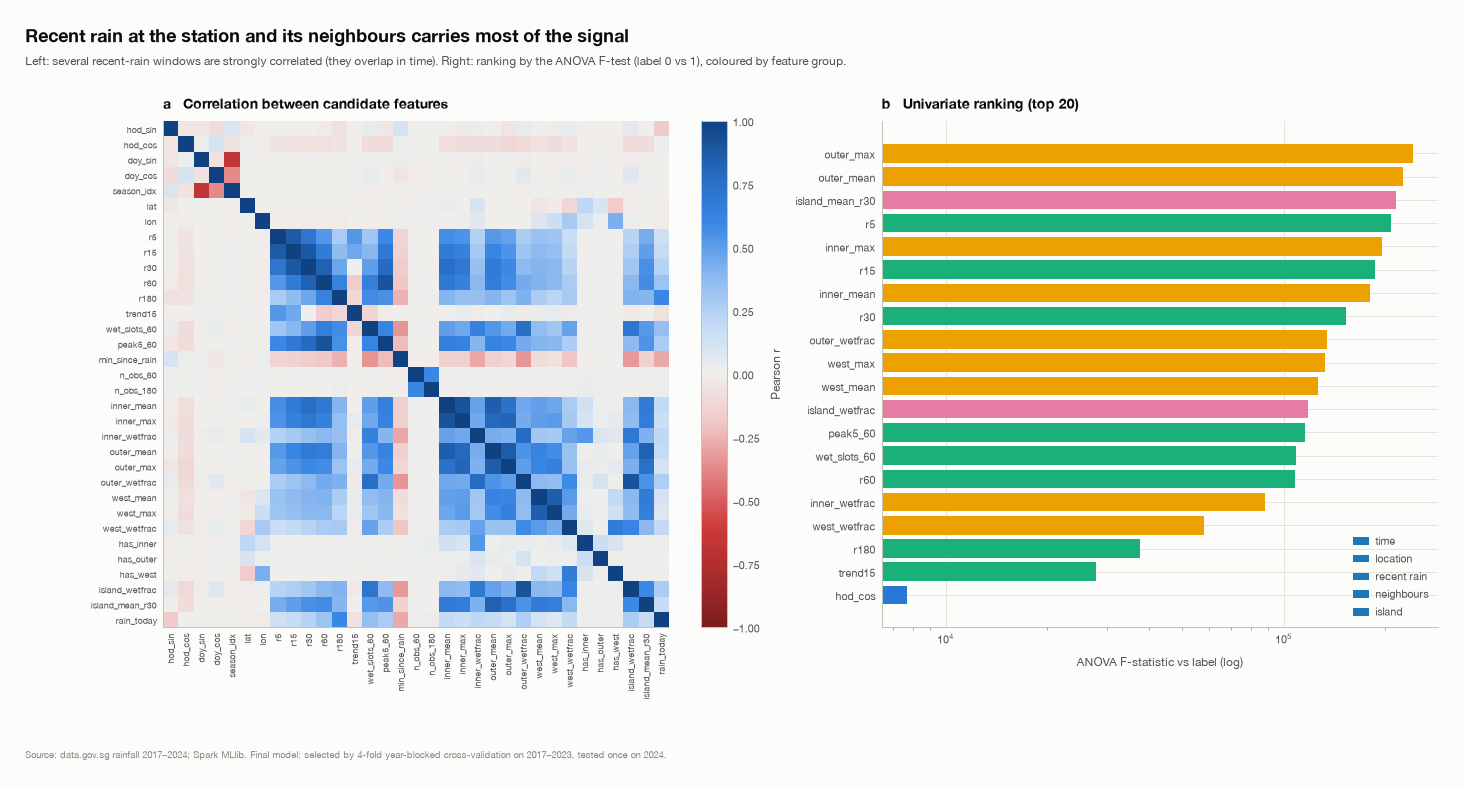

  [figure] outputs/figures/fig16_task2_feature_screening.png


In [61]:
# --- Figure 16: feature screening; opens the final-model figure PDF --------------------------------
open_pdf(FIGURES / "task2_final_model_figures.pdf", title="Task 2 final model figures")
fig, axes = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]
im = ax.imshow(corr.values, cmap=CMAP_ANOM, vmin=-1, vmax=1)
ax.set_xticks(range(len(CAND_FEATS))); ax.set_xticklabels(CAND_FEATS, rotation=90, fontsize=7)
ax.set_yticks(range(len(CAND_FEATS))); ax.set_yticklabels(CAND_FEATS, fontsize=7)
ax.grid(False)
ax.set_title("a   Correlation between candidate features")
fig.colorbar(im, ax=ax, fraction=0.04).set_label("Pearson r")
ax = axes[1]
top = anova.head(20).iloc[::-1]
gcol = {g: PALETTE[i] for i, g in enumerate(GROUPS)}
ax.barh(top.feature, top.F, color=[gcol[g] for g in top.group])
ax.set_xscale("log")
ax.set_xlabel("ANOVA F-statistic vs label (log)")
ax.set_title("b   Univariate ranking (top 20)")
for g, c in gcol.items():
    ax.barh([], [], color=c, label=g)
ax.legend(loc="lower right")
fig.tight_layout()
headline(fig, "Recent rain at the station and its neighbours carries most of the signal",
         "Left: several recent-rain windows are strongly correlated (they overlap in time). Right: ranking by the "
         "ANOVA F-test (label 0 vs 1), coloured by feature group.")
save_figure(fig, FIGURES / "fig16_task2_feature_screening.png")

## 14. Year-blocked cross-validation and hyper-parameter tuning (Spark MLlib)

Consecutive 5-minute windows are almost identical. A random *k*-fold split would place near-copies of the same storm
in training and validation, so we give `CrossValidator` a `foldCol` with whole-year blocks (2017–18, 2019–20, 2021–22,
2023). Each model is validated on years excluded from its training set.

We select models by weighted log loss, using
`MulticlassClassificationEvaluator(metricName="logLoss", weightCol="w")`. It is a proper scoring rule that rewards
calibrated probabilities. To limit the number of fits, we tune the selector size *k* with logistic regression first,
then hold *k* fixed while tuning each model's grid:

| Model | Grid |
|---|---|
| Logistic regression | `regParam` {0.001, 0.01, 0.1} × `elasticNetParam` {0, 0.5} |
| Random forest | `numTrees` {50, 100} × `maxDepth` {8, 12} |
| Gradient-boosted trees | `maxDepth` {4, 6, 8} × `maxIter` {50, 100} × `stepSize` {0.05, 0.1} |

The model with the lowest cross-validated log loss becomes the final model. This is the notebook's longest stage:
about 37 minutes with `CV_PARALLELISM=4` on the 16-core machine in Section 19, or about 2.5 hours on a 16 GB laptop.
Set `RERUN_CV=0` to reuse a previous run's `t2_cv_results.csv`.

In [62]:
# definitions
# --- 14. Cross-validation definitions: evaluators, pipeline factory, run_cv with per-grid caching, grids ---
LOGLOSS = MulticlassClassificationEvaluator(metricName="logLoss", labelCol="label", probabilityCol="probability",
                                            predictionCol="prediction", weightCol="w")
PRAUC = BinaryClassificationEvaluator(metricName="areaUnderPR", labelCol="label",
                                      rawPredictionCol="rawPrediction", weightCol="w")
TREE_KW = dict(maxBins=128, seed=SEED)


def make_pipeline(model, candidates, k=None, onehot=False, scale=False, selector=True):
    """Station index (+ optional one-hot), candidate features (+ optional selectors), threshold inputs, model."""
    stages = [StringIndexer(inputCol="station_id", outputCol="station_idx", handleInvalid="keep"),
              VectorAssembler(inputCols=candidates, outputCol="cand", handleInvalid="keep")]
    sel = None
    cand_out = "cand"
    if selector:
        sel = UnivariateFeatureSelector(featuresCol="cand_var", outputCol="cand_sel", labelCol="label",
                                        selectionMode="numTopFeatures").setFeatureType("continuous") \
                                        .setLabelType("categorical").setSelectionThreshold(k or len(candidates))
        stages += [VarianceThresholdSelector(featuresCol="cand", outputCol="cand_var", varianceThreshold=0.0), sel]
        cand_out = "cand_sel"
    station_col = "station_idx"
    if onehot:
        stages.append(OneHotEncoder(inputCols=["station_idx"], outputCols=["station_oh"], handleInvalid="keep"))
        station_col = "station_oh"
    stages.append(VectorAssembler(inputCols=MANDATORY + [cand_out, station_col], outputCol="features_raw"))
    if scale:
        stages.append(StandardScaler(inputCol="features_raw", outputCol="features", withMean=False, withStd=True))
    else:
        stages[-1].setOutputCol("features")
    model.setFeaturesCol("features").setLabelCol("label").setWeightCol("w")
    return Pipeline(stages=stages + [model]), sel


CV_PARTIAL = TABLES / "_cv_partial"     # one file per finished grid, so an interrupted run resumes; removed when CV completes


def run_cv(name, pipeline, grid, data, extra=None):
    """Cross-validate one grid; `extra(best_model)` returns any extra info to keep (cached with the results)."""
    key = json.dumps([name, CAND_FEATS, CV_FRACTION, SEED, N_FOLDS,
                      [{p.name: v for p, v in pm.items()} for pm in grid]], default=str)
    part = CV_PARTIAL / f"{name.replace(' ', '_')}.json"
    if part.exists() and json.loads(part.read_text())["key"] == key:
        cached = json.loads(part.read_text())
        print(f"[14. CV {name}] re-using finished grid from an interrupted run ({part.name})")
        return cached["extra"], pd.DataFrame(cached["res"])
    cv = CrossValidator(estimator=pipeline, estimatorParamMaps=grid, evaluator=LOGLOSS,
                        numFolds=N_FOLDS, foldCol="fold", parallelism=CV_PARALLELISM, seed=SEED)
    step(f"cross-validating {name}: {len(grid)} settings x {N_FOLDS} folds = {len(grid) * N_FOLDS} fits + 1 refit "
         f"({CV_PARALLELISM} in parallel)")
    with timed(f"14. CV {name} ({len(grid)} settings x {N_FOLDS} folds)"):
        m = cv.fit(data)
    res = [{"model": name, **{p.name: v for p, v in pm.items()}, "cv_logloss": avg, "cv_logloss_sd": sd}
           for pm, avg, sd in zip(grid, m.avgMetrics, m.stdMetrics)]
    res = pd.DataFrame(res).sort_values("cv_logloss").reset_index(drop=True)
    best_ = res.iloc[0]
    result_box(f"CV {name}: best of {len(grid)} settings",
               [(k_, f"{best_[k_]:g}") for k_ in res.columns if k_ not in ("model", "cv_logloss", "cv_logloss_sd")] +
               [("CV log loss (mean +/- sd over folds)", f"{best_.cv_logloss:.4f} +/- {best_.cv_logloss_sd:.4f}"),
                ("worst setting", f"{res.cv_logloss.iloc[-1]:.4f}")])
    info = extra(m.bestModel) if extra else None
    CV_PARTIAL.mkdir(parents=True, exist_ok=True)
    part.write_text(json.dumps({"key": key, "res": res.to_dict("records"), "extra": info}, default=float))
    return info, res


def grid_for(est, vals):
    g = ParamGridBuilder()
    for k_, v in vals.items():
        g = g.addGrid(est.getParam(k_), v)
    return g.build()


lr_grid_vals = dict(regParam=[0.001, 0.01, 0.1], elasticNetParam=[0.0, 0.5])
rf_grid_vals = dict(numTrees=[50, 100], maxDepth=[8, 12])
gbt_grid_vals = dict(maxDepth=[4, 6, 8], maxIter=[50, 100], stepSize=[0.05, 0.1])

In [63]:
# --- 14. Year-blocked cross-validation: selector size, then the LR / RF / GBT grids ----------------
section('14. Year-blocked cross-validation: selector size, then the LR / RF / GBT grids', purpose='CrossValidator with foldCol = blocks of whole years and weighted log loss; the longest stage of the notebook', writes='t2_cv_results, t2_selected_features.json')
CV_CACHE, SEL_CACHE = TABLES / "t2_cv_results.csv", TABLES / "t2_selected_features.json"
if not RERUN_CV and CV_CACHE.exists() and SEL_CACHE.exists():
    print(f"re-using cross-validation results from {CV_CACHE.name} (set RERUN_CV=1 to recompute)")
    cv_results = pd.read_csv(CV_CACHE)
    sel_info = json.loads(SEL_CACHE.read_text())
    K_BEST, SELECTED = int(sel_info["k"]), sel_info["selected"]
    pick = lambda name, keys: (cv_results[cv_results.model == name][["model", *keys, "cv_logloss", "cv_logloss_sd"]]
                               .sort_values("cv_logloss").reset_index(drop=True))
    res_k = pick("LR selector size", ["selectionThreshold"])
    res_lr, res_rf, res_gbt = pick("LR", list(lr_grid_vals)), pick("RF", list(rf_grid_vals)), pick("GBT", list(gbt_grid_vals))
    # keep the cross-validation timings of the run that produced the cache, so the timing table stays complete
    T40 = TABLES / "t40_stage_timings.csv"
    prev = pd.read_csv(T40) if T40.exists() else pd.DataFrame(columns=["stage", "seconds"])
    for r in prev[prev.stage.str.startswith("14. CV")].itertuples():
        TIMINGS.append({"stage": r.stage.split(" [")[0] + " [timing from the run that produced the cache]", "seconds": r.seconds})
    for name_, r_ in [("LR selector size", res_k), ("LR", res_lr), ("RF", res_rf), ("GBT", res_gbt)]:
        step(f"cached CV {name_}: best log loss {r_.cv_logloss.iloc[0]:.4f} +/- {r_.cv_logloss_sd.iloc[0]:.4f} over {len(r_)} settings")
else:
    # 14a. how many candidate features? (selector size tuned with logistic regression)
    k_grid = sorted({min(8, len(CAND_FEATS)), min(16, len(CAND_FEATS)), len(CAND_FEATS)})
    pipe, sel = make_pipeline(LogisticRegression(maxIter=50, regParam=0.01, elasticNetParam=0.0), CAND_FEATS, onehot=True, scale=True)
    def selected_names(best_model):
        after_var = [CAND_FEATS[i] for i in best_model.stages[2].selectedFeatures]       # variance filter
        return [after_var[i] for i in best_model.stages[3].selectedFeatures]             # univariate top-k
    SELECTED, res_k = run_cv("LR selector size", pipe, ParamGridBuilder().addGrid(sel.selectionThreshold, k_grid).build(),
                             cv_data, extra=selected_names)
    K_BEST = int(res_k.selectionThreshold.iloc[0])
    # 14b. model grids with the selector size fixed at K_BEST
    lr = LogisticRegression(maxIter=100)
    _, res_lr = run_cv("LR", make_pipeline(lr, CAND_FEATS, k=K_BEST, onehot=True, scale=True)[0],
                           grid_for(lr, lr_grid_vals), cv_data)
    rf = RandomForestClassifier(subsamplingRate=0.8, featureSubsetStrategy="sqrt", **TREE_KW)
    _, res_rf = run_cv("RF", make_pipeline(rf, CAND_FEATS, k=K_BEST)[0], grid_for(rf, rf_grid_vals), cv_data)
    gbt = GBTClassifier(subsamplingRate=0.8, **TREE_KW)
    _, res_gbt = run_cv("GBT", make_pipeline(gbt, CAND_FEATS, k=K_BEST)[0], grid_for(gbt, gbt_grid_vals), cv_data)
    cv_results = pd.concat([res_k.assign(model="LR selector size"), res_lr, res_rf, res_gbt], ignore_index=True)
    cv_results.to_csv(CV_CACHE, index=False)
    SEL_CACHE.write_text(json.dumps({"k": K_BEST, "selected": SELECTED,
                                     "dropped": [c for c in CAND_FEATS if c not in SELECTED]}, indent=1))
    shutil.rmtree(CV_PARTIAL, ignore_errors=True)
dropped = [c for c in CAND_FEATS if c not in SELECTED]
checkpoint("14a. Selector size chosen by cross-validation", [("k tried", sorted(res_k.selectionThreshold.astype(int).tolist())),
    ("k chosen", f"{K_BEST} -> kept {len(SELECTED)} of {len(CAND_FEATS)} candidates"), ("dropped", dropped or "none")])
res_k

08:12:08  14. Year-blocked cross-validation: selector size, then the LR / RF / GBT grids
Purpose : CrossValidator with foldCol = blocks of whole years and weighted log loss; the longest stage of the notebook
Writes  : t2_cv_results, t2_selected_features.json
[08:12:08]  cross-validating LR selector size: 3 settings x 4 folds = 12 fits + 1 refit (4 in parallel)


[08:12:45]  done: 14. CV LR selector size (3 settings x 4 folds)  (37.0 s)
------------------------------------------------------------------------
  CV LR selector size: best of 3 settings
------------------------------------------------------------------------
  selectionThreshold                   : 33
  CV log loss (mean +/- sd over folds) : 0.0425 +/- 0.0024
  worst setting                        : 0.0585
------------------------------------------------------------------------
[08:12:45]  cross-validating LR: 6 settings x 4 folds = 24 fits + 1 refit (4 in parallel)


[08:14:09]  done: 14. CV LR (6 settings x 4 folds)  (84.4 s)
------------------------------------------------------------------------
  CV LR: best of 6 settings
------------------------------------------------------------------------
  regParam                             : 0.001
  elasticNetParam                      : 0
  CV log loss (mean +/- sd over folds) : 0.0391 +/- 0.0022
  worst setting                        : 0.0807
------------------------------------------------------------------------
[08:14:09]  cross-validating RF: 4 settings x 4 folds = 16 fits + 1 refit (4 in parallel)


[08:23:51]  done: 14. CV RF (4 settings x 4 folds)  (582.2 s)
------------------------------------------------------------------------
  CV RF: best of 4 settings
------------------------------------------------------------------------
  numTrees                             : 100
  maxDepth                             : 12
  CV log loss (mean +/- sd over folds) : 0.0319 +/- 0.0018
  worst setting                        : 0.0347
------------------------------------------------------------------------
[08:23:51]  cross-validating GBT: 12 settings x 4 folds = 48 fits + 1 refit (4 in parallel)


26/10/17 08:44:59 ERROR BlockManagerStorageEndpoint: Error in removing RDD 105187
org.apache.spark.SparkException: Block rdd_105187_6 does not exist
	at org.apache.spark.errors.SparkCoreErrors$.blockDoesNotExistError(SparkCoreErrors.scala:318)
	at org.apache.spark.storage.BlockInfoManager.blockInfo(BlockInfoManager.scala:269)
	at org.apache.spark.storage.BlockInfoManager.removeBlock(BlockInfoManager.scala:547)
	at org.apache.spark.storage.BlockManager.removeBlockInternal(BlockManager.scala:2093)
	at org.apache.spark.storage.BlockManager.removeBlock(BlockManager.scala:2057)
	at org.apache.spark.storage.BlockManager.$anonfun$removeRdd$4(BlockManager.scala:1993)
	at org.apache.spark.storage.BlockManager.$anonfun$removeRdd$4$adapted(BlockManager.scala:1993)
	at scala.collection.Iterator.foreach(Iterator.scala:943)
	at scala.collection.Iterator.foreach$(Iterator.scala:943)
	at scala.collection.AbstractIterator.foreach(Iterator.scala:1431)
	at org.apache.spark.storage.BlockManager.removeRdd(

[08:49:33]  done: 14. CV GBT (12 settings x 4 folds)  (1541.6 s)
------------------------------------------------------------------------
  CV GBT: best of 12 settings
------------------------------------------------------------------------
  maxDepth                             : 4
  maxIter                              : 100
  stepSize                             : 0.1
  CV log loss (mean +/- sd over folds) : 0.0403 +/- 0.0018
  worst setting                        : 0.0641
------------------------------------------------------------------------

-- 14a. Selector size chosen by cross-validation -----------------------------------------------
   k tried  : [8, 16, 33]
   k chosen : 33 -> kept 33 of 33 candidates
   dropped  : none



,model,selectionThreshold,cv_logloss,cv_logloss_sd
0,LR selector size,33.0,0.042490,0.002434
1,LR selector size,16.0,0.045391,0.002830
2,LR selector size,8.0,0.058459,0.003718


In [64]:
# --- 14b. The final model: lowest cross-validated log loss across the three families ---------------
section('14b. The final model: lowest cross-validated log loss across the three families')
best = {name: r.iloc[0].to_dict() for name, r in [("LR", res_lr), ("RF", res_rf), ("GBT", res_gbt)]}
lr_best = {k_: float(best["LR"][k_]) for k_ in lr_grid_vals}
rf_best = {k_: int(best["RF"][k_]) for k_ in rf_grid_vals}
gbt_best = {k_: (int(best["GBT"][k_]) if k_ in ("maxDepth", "maxIter") else float(best["GBT"][k_])) for k_ in gbt_grid_vals}
FINAL_NAME = min(["LR", "RF", "GBT"], key=lambda n: best[n]["cv_logloss"])
FINAL_KEY = {"LR": "LR", "RF": "RF", "GBT": "GBT (Model B)"}[FINAL_NAME]
FINAL_LABEL = {"LR": "logistic regression", "RF": "random forest", "GBT": "gradient-boosted trees"}[FINAL_NAME]


def at_grid_edge(params, vals):
    return [k_ for k_, v in params.items() if len(vals[k_]) > 1 and v in (min(vals[k_]), max(vals[k_]))]


edges = {"RF": at_grid_edge(rf_best, rf_grid_vals), "GBT": at_grid_edge(gbt_best, gbt_grid_vals)}
checkpoint("14b. Model families (best setting each)", [(n, f"CV log loss {best[n]['cv_logloss']:.4f} +/- {best[n]['cv_logloss_sd']:.4f}") for n in ["LR", "RF", "GBT"]] +
    [("FINAL MODEL (lowest CV log loss)", FINAL_LABEL), ("its settings", {"LR": lr_best, "RF": rf_best, "GBT": gbt_best}[FINAL_NAME]),
     ("best settings on the edge of their grid", {m: v for m, v in edges.items() if v} or "none")])
pd.DataFrame(best).T[list(dict.fromkeys(["cv_logloss", "cv_logloss_sd", *lr_grid_vals, *rf_grid_vals, *gbt_grid_vals]))]

08:49:33  14b. The final model: lowest cross-validated log loss across the three families

-- 14b. Model families (best setting each) -----------------------------------------------------
   LR                                      : CV log loss 0.0391 +/- 0.0022
   RF                                      : CV log loss 0.0319 +/- 0.0018
   GBT                                     : CV log loss 0.0403 +/- 0.0018
   FINAL MODEL (lowest CV log loss)        : random forest
   its settings                            : {'numTrees': 100, 'maxDepth': 12}
   best settings on the edge of their grid : {'RF': ['numTrees', 'maxDepth'], 'GBT': ['maxDepth', 'maxIter', 'stepSize']}



,cv_logloss,cv_logloss_sd,regParam,elasticNetParam,numTrees,maxDepth,maxIter,stepSize
LR,0.03914,0.00222,0.001,0.0,NaN,NaN,NaN,NaN
RF,0.031854,0.001839,NaN,NaN,100,12,NaN,NaN
GBT,0.040314,0.001776,NaN,NaN,NaN,4,100,0.1


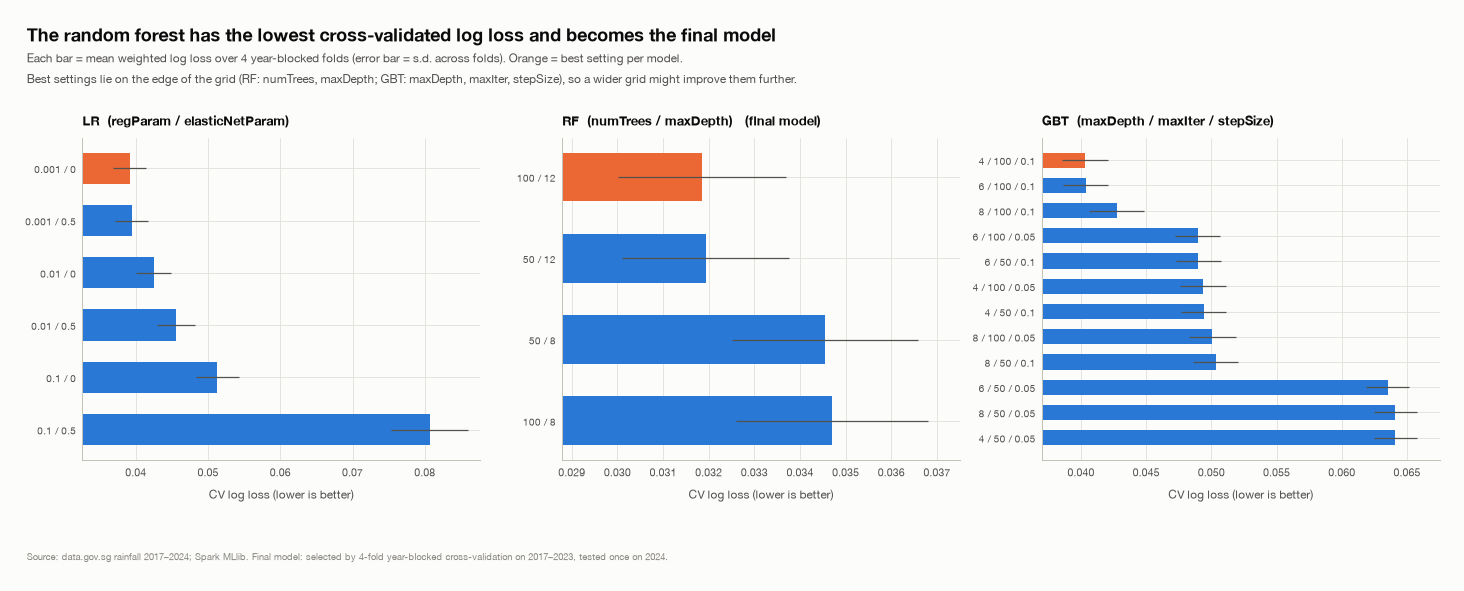

  [figure] outputs/figures/fig17_task2_cv_tuning.png


In [65]:
# --- Figure 17: cross-validated log loss of every setting ------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), sharey=False)
for ax, (name, r, keys) in zip(axes, [("LR", res_lr, list(lr_grid_vals)), ("RF", res_rf, list(rf_grid_vals)),
                                      ("GBT", res_gbt, list(gbt_grid_vals))]):
    r = r.copy()
    r["setting"] = r[keys].apply(lambda row: " / ".join(f"{v:g}" for v in row), axis=1)
    r = r.sort_values("cv_logloss", ascending=False)
    cols = [PALETTE[1] if i == len(r) - 1 else PALETTE[0] for i in range(len(r))]
    ax.barh(r.setting, r.cv_logloss, xerr=r.cv_logloss_sd, color=cols, height=0.6, error_kw=dict(ecolor=INK_2, lw=1))
    ax.set_xlim(r.cv_logloss.min() * 0.97 - r.cv_logloss_sd.max(), r.cv_logloss.max() * 1.02 + r.cv_logloss_sd.max())
    ax.set_title(f"{name}  ({' / '.join(keys)})" + ("   (final model)" if name == FINAL_NAME else ""), fontsize=10)
    ax.set_xlabel("CV log loss (lower is better)")
    ax.tick_params(axis="y", labelsize=8)
fig.tight_layout()
edge_txt = "; ".join(f"{m}: {', '.join(v)}" for m, v in edges.items() if v)
headline(fig, f"The {FINAL_LABEL} has the lowest cross-validated log loss and becomes the final model",
         f"Each bar = mean weighted log loss over {N_FOLDS} year-blocked folds (error bar = s.d. across folds). "
         "Orange = best setting per model."
         + (f"\nBest settings lie on the edge of the grid ({edge_txt}), so a wider grid might improve them further." if edge_txt else ""))
save_figure(fig, FIGURES / "fig17_task2_cv_tuning.png")

## 15. Feature-group ablation and probability calibration

The tuned GBT is the fastest tree model to train. We fit it on folds 0–2 and validate it on 2023, first with all
selected features and then with each feature group removed. Model A uses only the threshold, time and location:
the inputs available without rain observations.

Neither boosted-tree nor random-forest probabilities are guaranteed to be calibrated. We therefore test a
Platt-style calibrator, an MLlib logistic regression on logit(*p*), log(threshold) and their product. Using
predictions from models trained on 2017–2022, we fit it on the first half of 2023 and evaluate it on the second half. If it lowers log loss there, we keep it and refit it on all of 2023. The test year is never used
in this decision.

In [66]:
# --- 15a. Feature-group ablation (GBT trained on folds 0-2, validated on 2023) ---------------------
section('15a. Feature-group ablation (GBT trained on folds 0-2, validated on 2023)', purpose='retrain without each feature group in turn; Model A = threshold + time + station only', writes='t2_ablation')
fit_part, val_part = cv_data.filter(F.col("fold") < VAL_FOLD), cv_data.filter(F.col("fold") == VAL_FOLD)


def fit_eval(feats_, label):
    p, _ = make_pipeline(GBTClassifier(subsamplingRate=0.8, **TREE_KW, **gbt_best), feats_, selector=False)
    with timed(f"15a. ablation fit: {label}"):
        m = p.fit(fit_part)
        pr = m.transform(val_part)
        r_ = {"variant": label, "n_features": len(feats_) + len(MANDATORY) + 1,
              "val_logloss": LOGLOSS.evaluate(pr), "val_prauc": PRAUC.evaluate(pr)}
    step(f"    {label}: validation log loss {r_['val_logloss']:.4f}, PR-AUC {r_['val_prauc']:.4f}")
    return m, r_


abl = []
m_full_val, r = fit_eval(SELECTED, "all selected features (Model B)"); abl.append(r)
for g, fs in GROUPS.items():
    keep_ = [f for f in SELECTED if f not in fs]
    if len(keep_) < len(SELECTED):
        abl.append(fit_eval(keep_, f"without {g}")[1])
m_A_val, r = fit_eval(G_TIME + G_LOC, "Model A: threshold + time + station only"); abl.append(r)
ablation = pd.DataFrame(abl)
ablation["delta_logloss_%"] = 100 * (ablation.val_logloss / ablation.val_logloss.iloc[0] - 1)
write_table(ablation, "t2_ablation")
abl_sorted = ablation.iloc[1:-1].sort_values("delta_logloss_%", ascending=False)
checkpoint("15a. Ablation: change in 2023 log loss when a group is removed (positive = worse)",
           [("all selected features (Model B)", f"log loss {ablation.val_logloss.iloc[0]:.4f}, PR-AUC {ablation.val_prauc.iloc[0]:.4f}")] +
           [(r["variant"], f"{r['delta_logloss_%']:+.1f} %") for _, r in abl_sorted.iterrows()] +
           [("Model A (no rain observations)", f"{ablation['delta_logloss_%'].iloc[-1]:+.1f} %")])
ablation.round(4)

08:49:33  15a. Feature-group ablation (GBT trained on folds 0-2, validated on 2023)
Purpose : retrain without each feature group in turn; Model A = threshold + time + station only
Writes  : t2_ablation


[08:50:06]  done: 15a. ablation fit: all selected features (Model B)  (32.4 s)
[08:50:06]      all selected features (Model B): validation log loss 0.0417, PR-AUC 0.6823


[08:50:38]  done: 15a. ablation fit: without time  (31.8 s)
[08:50:38]      without time: validation log loss 0.0418, PR-AUC 0.6813


[08:51:10]  done: 15a. ablation fit: without location  (31.9 s)
[08:51:10]      without location: validation log loss 0.0417, PR-AUC 0.6823


[08:51:41]  done: 15a. ablation fit: without recent rain  (31.2 s)
[08:51:41]      without recent rain: validation log loss 0.0450, PR-AUC 0.5998


[08:52:12]  done: 15a. ablation fit: without neighbours  (30.8 s)
[08:52:12]      without neighbours: validation log loss 0.0430, PR-AUC 0.6666


[08:52:43]  done: 15a. ablation fit: without island  (31.7 s)
[08:52:43]      without island: validation log loss 0.0420, PR-AUC 0.6785


[08:53:13]  done: 15a. ablation fit: Model A: threshold + time + station only  (29.6 s)
[08:53:13]      Model A: threshold + time + station only: validation log loss 0.0782, PR-AUC 0.0784
  [table] outputs/tables/t2_ablation.csv  (7 rows)

-- 15a. Ablation: change in 2023 log loss when a group is removed (positive = worse) -----------
   all selected features (Model B) : log loss 0.0417, PR-AUC 0.6823
   without recent rain             : +7.8 %
   without neighbours              : +2.9 %
   without island                  : +0.7 %
   without time                    : +0.2 %
   without location                : +0.0 %
   Model A (no rain observations)  : +87.3 %



,variant,n_features,val_logloss,val_prauc,delta_logloss_%
0,all selected features (Model B),36,0.0417,0.6823,0.0000
1,without time,31,0.0418,0.6813,0.2366
2,without location,34,0.0417,0.6823,0.0000
3,without recent rain,25,0.0450,0.5998,7.7909
4,without neighbours,24,0.0430,0.6666,2.9001
5,without island,33,0.0420,0.6785,0.6672
6,Model A: threshold + time + station only,10,0.0782,0.0784,87.3428


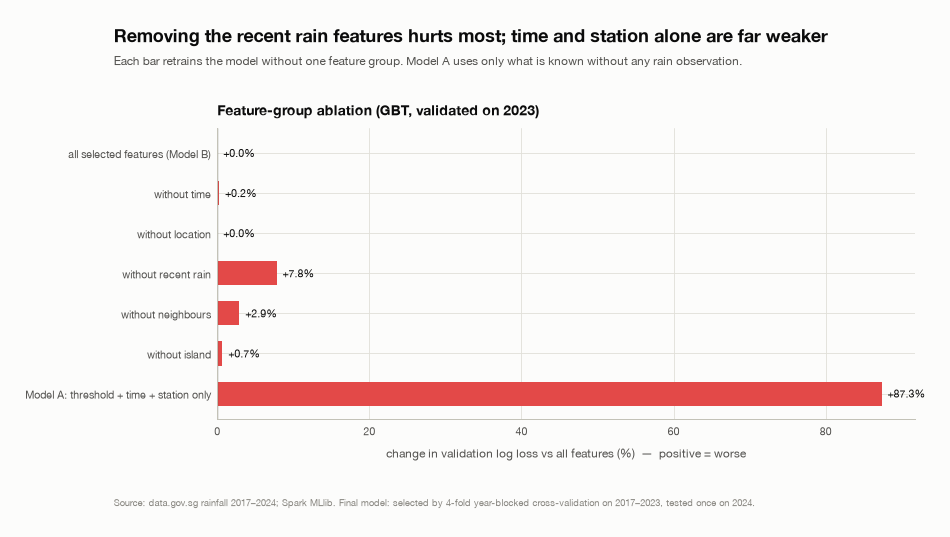

  [figure] outputs/figures/fig18_task2_ablation.png


In [67]:
# --- Figure 18: ablation ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 4.2))
a_ = ablation.iloc[::-1]
cols = [PALETTE[0] if i == len(a_) - 1 else (PALETTE[7] if v > 0 else PALETTE[2]) for i, v in enumerate(a_["delta_logloss_%"])]
ax.barh(a_.variant, a_["delta_logloss_%"], color=cols, height=0.6)
ax.axvline(0, color=INK_2, lw=1)
for y, v in enumerate(a_["delta_logloss_%"]):
    ax.text(v, y, f"  {v:+.1f}%", va="center", ha="left" if v >= 0 else "right", fontsize=8.5, color=INK)
ax.set_xlabel("change in validation log loss vs all features (%)  —  positive = worse")
ax.set_title("Feature-group ablation (GBT, validated on 2023)")
worst = ablation.iloc[1:-1].sort_values("delta_logloss_%", ascending=False).iloc[0]
headline(fig, f"Removing the {worst.variant.replace('without ', '')} features hurts most; time and station alone are far weaker",
         "Each bar retrains the model without one feature group. Model A uses only what is known without any rain observation.")
save_figure(fig, FIGURES / "fig18_task2_ablation.png")

In [68]:
# --- 15b-c. Probability calibration check on held-out 2023 data ------------------------------------
section('15b-c. Probability calibration check on held-out 2023 data', purpose='Platt-style calibrator fitted on the first half of 2023, judged on the second half; kept only if it lowers log loss', writes='t2_calibration_fit')
CAL_THRESHOLDS = sorted(set(EVAL_THRESHOLDS + [0.2, 30.0, 60.0]))
val_rows = train_rows.filter(F.col("fold") == VAL_FOLD)
val_rows = val_rows.sample(fraction=min(1.0, 2 * CV_FRACTION), seed=SEED) if CV_FRACTION < 1 else val_rows
val_cal = (val_rows.crossJoin(F.broadcast(spark.createDataFrame(pd.DataFrame({"thr": CAL_THRESHOLDS}))))
           .withColumn("log_thr", F.log("thr")).withColumn("label", (F.col("fut30") > F.col("thr")).cast("double"))
           .withColumn("w", F.lit(1.0)))
split_epoch = val_rows.approxQuantile("slot_epoch", [0.5], 0.001)[0]
step("2023 validation block split at " + pd.Timestamp(split_epoch, unit="s", tz="Asia/Singapore").strftime("%Y-%m-%d") + " (fit before, judge after)")


def estimator_for(name):
    if name == "LR":
        return LogisticRegression(maxIter=100, **lr_best), dict(onehot=True, scale=True)
    if name == "RF":
        return RandomForestClassifier(subsamplingRate=0.8, featureSubsetStrategy="sqrt", **TREE_KW, **rf_best), {}
    return GBTClassifier(subsamplingRate=0.8, **TREE_KW, **gbt_best), {}


def calibrator_pipeline():
    return Pipeline(stages=[VectorAssembler(inputCols=["z", "log_thr", "z_lt"], outputCol="cal_features"),
                            LogisticRegression(featuresCol="cal_features", labelCol="label", regParam=0.0, maxIter=100,
                                               probabilityCol="probability_cal", rawPredictionCol="raw_cal",
                                               predictionCol="pred_cal")])


def ll_brier(df, c):
    eps = 1e-7
    return df.agg((-F.avg(F.col("label") * F.log(F.greatest(F.col(c), F.lit(eps)))
                          + (1 - F.col("label")) * F.log(F.greatest(1 - F.col(c), F.lit(eps))))).alias("ll"),
                  F.avg((F.col(c) - F.col("label")) ** 2).alias("brier")).head()


def fit_calibrator(model, label):
    pv = add_logit(model.transform(val_cal).select("slot_epoch", "label", "thr", "log_thr",
                                                   vector_to_array("probability")[1].alias("p_raw"))).persist()
    first, second = pv.filter(F.col("slot_epoch") < split_epoch), pv.filter(F.col("slot_epoch") >= split_epoch)
    held = calibrator_pipeline().fit(first).transform(second).withColumn("p_cal", vector_to_array("probability_cal")[1])
    raw_, cal_ = ll_brier(held, "p_raw"), ll_brier(held, "p_cal")
    use = cal_.ll < raw_.ll
    cal = calibrator_pipeline().fit(pv) if use else None
    pv.unpersist()
    return cal, {"model": label, "holdout_logloss_raw": raw_.ll, "holdout_logloss_cal": cal_.ll,
                 "holdout_brier_raw": raw_.brier, "holdout_brier_cal": cal_.brier, "calibrator_kept": use}


val_models = {"GBT (Model B)": m_full_val, "GBT (Model A)": m_A_val}
if FINAL_KEY not in val_models:
    est, kw = estimator_for(FINAL_NAME)
    with timed(f"15b. fit {FINAL_KEY} on 2017-2022 (for calibration / cut-offs)"):
        val_models[FINAL_KEY] = make_pipeline(est, SELECTED, selector=False, **kw)[0].fit(fit_part)
cal_rows, CALIBRATORS = [], {}
with timed("15c. calibration check (fit on 1st half, judge on 2nd half of 2023)"):
    for name, m in val_models.items():
        cal, row = fit_calibrator(m, name)
        cal_rows.append(row)
        if cal is not None:
            CALIBRATORS[name] = cal
cal_summary = write_table(pd.DataFrame(cal_rows), "t2_calibration_fit")
for r in cal_summary.itertuples():
    result_box(f"calibration check: {r.model}", [("held-out log loss, raw -> calibrated", f"{r.holdout_logloss_raw:.4f} -> {r.holdout_logloss_cal:.4f}"),
        ("held-out Brier, raw -> calibrated", f"{r.holdout_brier_raw:.5f} -> {r.holdout_brier_cal:.5f}"), ("calibrator kept", r.calibrator_kept)])
cal_summary.round(5)

08:53:13  15b-c. Probability calibration check on held-out 2023 data
Purpose : Platt-style calibrator fitted on the first half of 2023, judged on the second half; kept only if it lowers log loss
Writes  : t2_calibration_fit


[08:53:13]  2023 validation block split at 2023-07-02 (fit before, judge after)


[08:54:22]  done: 15b. fit RF on 2017-2022 (for calibration / cut-offs)  (69.0 s)


[08:57:43]  done: 15c. calibration check (fit on 1st half, judge on 2nd half of 2023)  (200.9 s)
  [table] outputs/tables/t2_calibration_fit.csv  (3 rows)
------------------------------------------------------------------------
  calibration check: GBT (Model B)
------------------------------------------------------------------------
  held-out log loss, raw -> calibrated : 0.0381 -> 0.0311
  held-out Brier, raw -> calibrated    : 0.00777 -> 0.00783
  calibrator kept                      : True
------------------------------------------------------------------------
------------------------------------------------------------------------
  calibration check: GBT (Model A)
------------------------------------------------------------------------
  held-out log loss, raw -> calibrated : 0.0679 -> 0.0638
  held-out Brier, raw -> calibrated    : 0.01373 -> 0.01371
  calibrator kept                      : True
------------------------------------------------------------------------
---------

,model,holdout_logloss_raw,holdout_logloss_cal,holdout_brier_raw,holdout_brier_cal,calibrator_kept
0,GBT (Model B),0.03814,0.03113,0.00777,0.00783,True
1,GBT (Model A),0.06789,0.06375,0.01373,0.01371,True
2,RF,0.02945,0.02881,0.00759,0.00762,True


## 16. Refit on 2017–2023 and evaluate once on 2024

We refit the tuned settings on the full 2017–2023 training sample, then score every station and 5-minute time in 2024
at 0.5, 1, 2, 5, 10 and 20 mm, without sampling or weights. Models whose calibrator passed the check are evaluated
both with and without it.

Tree models do not guarantee P(> 10 mm) ≤ P(> 5 mm). We therefore apply a running minimum across thresholds for each
station-time, making the probabilities non-increasing. We report the share of predictions changed by this step as
`monotone_fix_rate`.

In [69]:
# --- 16a-b. Refit on 2017-2023 and score every 2024 row --------------------------------------------
section('16a-b. Refit on 2017-2023 and score every 2024 row', purpose='final settings refitted on the full training sample; 2024 scored at six thresholds without sampling or weights', writes='data_parquet/gold/task2_final/pred/')
def refit(name, est, feats_, **kw):
    p, _ = make_pipeline(est, feats_, selector=False, **kw)
    with timed(f"16a. refit {name} on 2017-2023"):
        return p.fit(train2.select("station_id", "w", "label", *MANDATORY, *feats_))


final_models = {}
for nm in ["LR", "RF"]:
    est, kw = estimator_for(nm)
    final_models[nm] = refit(nm, est, SELECTED, **kw)
final_models["GBT (Model B)"] = refit("GBT-B", estimator_for("GBT")[0], SELECTED)
final_models["GBT (Model A)"] = refit("GBT-A", estimator_for("GBT")[0], G_TIME + G_LOC)

thr_df = F.broadcast(spark.createDataFrame(pd.DataFrame({"thr": EVAL_THRESHOLDS})))
test_x = (test_rows.crossJoin(thr_df).withColumn("log_thr", F.log("thr"))
          .withColumn("label", (F.col("fut30") > F.col("thr")).cast("double")).withColumn("w", F.lit(1.0)))
w_mono = Window.partitionBy("station_id", "slot_epoch").orderBy("thr").rowsBetween(Window.unboundedPreceding, 0)
KEYS = ["station_id", "slot_epoch", "month", "hour", "season", "thr", "label"]


def score_final(name, model, calibrator=None):
    out = model.transform(test_x).select(*KEYS, "log_thr", vector_to_array("probability")[1].alias("p_raw"))
    if calibrator is not None:
        out = (calibrator.transform(add_logit(out)).withColumn("p_raw", vector_to_array("probability_cal")[1])
               .select(*KEYS, "p_raw"))
    path = GOLD2 / "pred" / name.replace(" ", "_").replace("(", "").replace(")", "")
    out.select(*KEYS, "p_raw").withColumn("p", F.min("p_raw").over(w_mono)).write.mode("overwrite").parquet(str(path))
    return spark.read.parquet(str(path))


preds = {}
for name, m in final_models.items():
    with timed(f"16b. score 2024: {name}"):
        preds[name] = score_final(name, m, CALIBRATORS.get(name))
    if name in CALIBRATORS:
        with timed(f"16b. score 2024: {name} uncalibrated"):
            preds[f"{name} uncalibrated"] = score_final(f"{name} uncalibrated", m)
with timed("16b. score 2024: climatology"):
    clim_base = preds[FINAL_KEY].select(*KEYS)
    (clim_base.join(F.broadcast(spark.createDataFrame(clim)), ["station_id", "month", "hour", "thr"], "left")
     .join(F.broadcast(spark.createDataFrame(clim_mh_tab)), ["month", "hour", "thr"], "left")
     .withColumn("p", F.coalesce("p_clim", "p_mh")).withColumn("p_raw", F.col("p")).drop("p_clim", "p_mh")
     .write.mode("overwrite").parquet(str(GOLD2 / "pred" / "climatology")))
    preds["Climatology"] = spark.read.parquet(str(GOLD2 / "pred" / "climatology"))
step("scored 2024 for: " + ", ".join(preds))

08:57:43  16a-b. Refit on 2017-2023 and score every 2024 row
Purpose : final settings refitted on the full training sample; 2024 scored at six thresholds without sampling or weights
Writes  : data_parquet/gold/task2_final/pred/


[08:57:54]  done: 16a. refit LR on 2017-2023  (10.9 s)


[09:02:21]  done: 16a. refit RF on 2017-2023  (267.1 s)


[09:04:03]  done: 16a. refit GBT-B on 2017-2023  (101.5 s)


[09:05:27]  done: 16a. refit GBT-A on 2017-2023  (84.4 s)


...

[09:09:24]  done: 16b. score 2024: GBT (Model B)  (34.2 s)


[09:09:55]  done: 16b. score 2024: GBT (Model B) uncalibrated  (31.0 s)


[09:10:23]  done: 16b. score 2024: GBT (Model A)  (27.8 s)


[09:10:47]  done: 16b. score 2024: GBT (Model A) uncalibrated  (23.6 s)


[09:10:52]  done: 16b. score 2024: climatology  (5.5 s)
[09:10:52]  scored 2024 for: LR, RF, RF uncalibrated, GBT (Model B), GBT (Model B) uncalibrated, GBT (Model A), GBT (Model A) uncalibrated, Climatology


In [70]:
# --- 16c. Test metrics on 2024 ---------------------------------------------------------------------
section('16c. Test metrics on 2024', purpose="PR-AUC and ROC-AUC via MLlib's BinaryClassificationEvaluator; Brier, log loss and skill from Spark aggregates", writes='t2_test_metrics')
def t2_metrics(name, pr):
    pc = F.least(F.greatest(F.col("p"), F.lit(EPS)), F.lit(1 - EPS))
    agg = (pr.groupBy("thr").agg(F.count("*").alias("n"), F.avg("label").alias("base_rate"),
                                 F.avg((F.col("p") - F.col("label")) ** 2).alias("brier"),
                                 (-F.avg(F.col("label") * F.log(pc) + (1 - F.col("label")) * F.log(1 - pc))).alias("logloss"),
                                 F.avg((F.col("p_raw") > F.col("p") + 1e-9).cast("double")).alias("monotone_fix_rate"))
           .toPandas())
    rows_ = []
    for t in EVAL_THRESHOLDS:
        sub_ = pr.filter(F.col("thr") == t)
        ev = lambda m_: BinaryClassificationEvaluator(metricName=m_, labelCol="label", rawPredictionCol="p").evaluate(sub_)
        rows_.append({"thr": t, "pr_auc": ev("areaUnderPR"), "roc_auc": ev("areaUnderROC")})
    return agg.merge(pd.DataFrame(rows_), on="thr").assign(model=name)


with timed("16c. test metrics"):
    test_metrics = pd.concat([t2_metrics(n, p) for n, p in preds.items()], ignore_index=True)
cb = test_metrics[test_metrics.model == "Climatology"][["thr", "brier"]].rename(columns={"brier": "brier_clim"})
test_metrics = test_metrics.merge(cb, on="thr")
test_metrics["brier_skill"] = 1 - test_metrics.brier / test_metrics.brier_clim
test_metrics["pr_auc_lift"] = test_metrics.pr_auc / test_metrics.base_rate
test_metrics["final_model"] = test_metrics.model == FINAL_KEY
test_metrics = test_metrics.sort_values(["thr", "model"])
write_table(test_metrics, "t2_test_metrics")
for m in sorted(preds, key=lambda n: (n != FINAL_KEY, n)):
    d = test_metrics[test_metrics.model == m].set_index("thr")
    result_box(f"2024 test: {m}" + ("   <-- FINAL MODEL" if m == FINAL_KEY else ""), [
        ("PR-AUC at 1 / 5 / 20 mm", f"{d.loc[1.0, 'pr_auc']:.3f} / {d.loc[5.0, 'pr_auc']:.3f} / {d.loc[20.0, 'pr_auc']:.3f}"),
        ("ROC-AUC at 5 mm", f"{d.loc[5.0, 'roc_auc']:.3f}"), ("log loss at 5 mm", f"{d.loc[5.0, 'logloss']:.4f}"),
        ("Brier skill vs climatology, mean over thresholds", f"{d.brier_skill.mean():.3f}"),
        ("running minimum changed", f"{100 * d.monotone_fix_rate.max():.3f} % of predictions at most")])
test_metrics.pivot(index="model", columns="thr", values=["pr_auc", "brier_skill"]).round(3)

09:10:52  16c. Test metrics on 2024
Purpose : PR-AUC and ROC-AUC via MLlib's BinaryClassificationEvaluator; Brier, log loss and skill from Spark aggregates
Writes  : t2_test_metrics


[09:13:03]  done: 16c. test metrics  (131.0 s)
  [table] outputs/tables/t2_test_metrics.csv  (48 rows)
------------------------------------------------------------------------
  2024 test: RF   <-- FINAL MODEL
------------------------------------------------------------------------
  PR-AUC at 1 / 5 / 20 mm                          : 0.667 / 0.465 / 0.185
  ROC-AUC at 5 mm                                  : 0.969
  log loss at 5 mm                                 : 0.0240
  Brier skill vs climatology, mean over thresholds : 0.322
  running minimum changed                          : 0.055 % of predictions at most
------------------------------------------------------------------------
------------------------------------------------------------------------
  2024 test: Climatology
------------------------------------------------------------------------
  PR-AUC at 1 / 5 / 20 mm                          : 0.054 / 0.021 / 0.003
  ROC-AUC at 5 mm                                  : 0.679
  

pr_auc                                    brier_skill                                   
thr                          0.5    1.0    2.0    5.0    10.0   20.0        0.5    1.0    2.0    5.0    10.0   20.0
model                                                                                                              
Climatology                 0.075  0.054  0.038  0.021  0.010  0.003       0.000  0.000  0.000  0.000  0.000  0.000
GBT (Model A)               0.075  0.055  0.036  0.017  0.008  0.002      -0.012 -0.008 -0.001 -0.002 -0.001  0.001
GBT (Model A) uncalibrated  0.075  0.055  0.036  0.017  0.008  0.002      -0.002 -0.002 -0.004 -0.009 -0.026 -0.120
GBT (Model B)               0.718  0.662  0.583  0.460  0.338  0.174       0.481  0.392  0.363  0.256  0.161  0.091
GBT (Model B) uncalibrated  0.718  0.662  0.584  0.460  0.338  0.174       0.489  0.425  0.376  0.273  0.147 -0.027
LR                          0.635  0.571  0.491  0.381  0.273  0.125       0.397  0.354  0.300  0.220  0.095 -0.395
RF                          0.721  0.667  0.587  0.465  0.351  0.185       0.492  0.448  0.386  0.293  0.211  0.101
RF uncalibrated             0.721  0.667  0.587  0.465  0.351  0.185       0.494  0.450  0.387  0.295  0.212  0.072

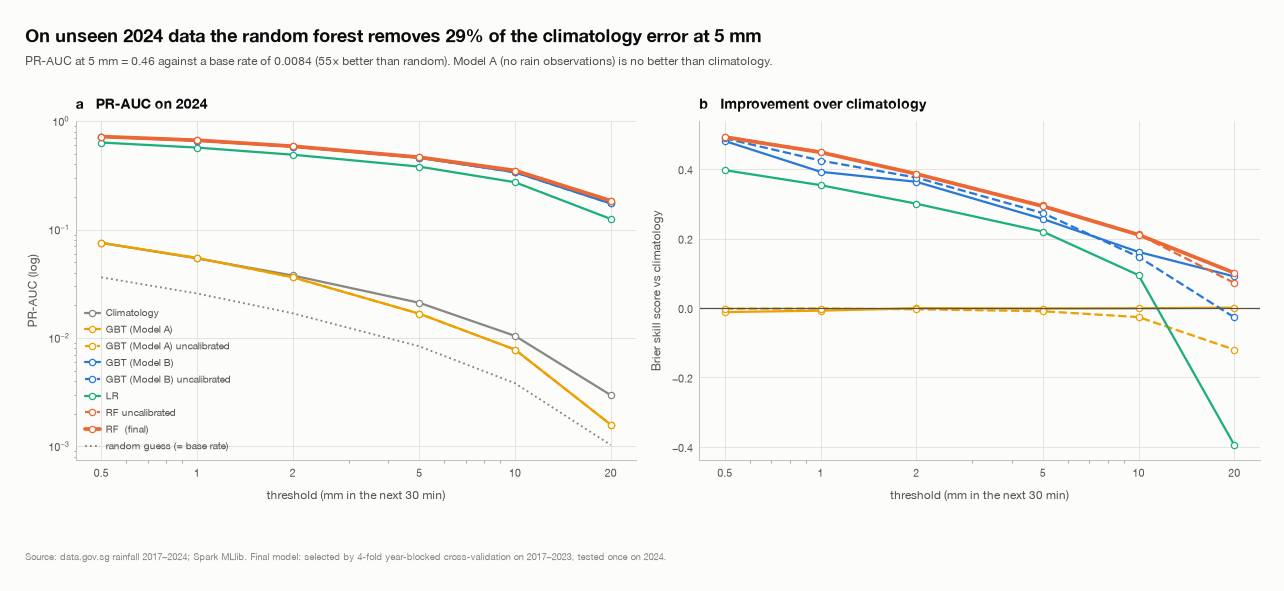

  [figure] outputs/figures/fig19_task2_final_test_performance.png


In [71]:
# --- Figure 19: PR-AUC and Brier skill on 2024 by threshold ----------------------------------------
BASE_COL = {"Climatology": MUTED, "GBT (Model A)": PALETTE[3], "LR": PALETTE[2], "RF": PALETTE[1], "GBT (Model B)": PALETTE[0]}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for m in sorted(preds, key=lambda n: (n == FINAL_KEY, n)):
    d = test_metrics[test_metrics.model == m].sort_values("thr")
    style = dict(marker="o", ms=5, mfc="white", color=BASE_COL[m.replace(" uncalibrated", "")],
                 ls="--" if m.endswith("uncalibrated") else "-",
                 lw=3 if m == FINAL_KEY else 1.8, label=m + ("  (final)" if m == FINAL_KEY else ""))
    axes[0].plot(d.thr, d.pr_auc, **style)
    if m != "Climatology":
        axes[1].plot(d.thr, d.brier_skill, **style)
d = test_metrics[test_metrics.model == "Climatology"].sort_values("thr")
axes[0].plot(d.thr, d.base_rate, color=MUTED, ls=":", lw=1.5, label="random guess (= base rate)")
for ax in axes:
    ax.set_xscale("log"); ax.set_xticks(EVAL_THRESHOLDS); ax.set_xticklabels([f"{t:g}" for t in EVAL_THRESHOLDS])
    ax.set_xlabel("threshold (mm in the next 30 min)")
axes[0].set_yscale("log"); axes[0].set_ylabel("PR-AUC (log)"); axes[0].set_title("a   PR-AUC on 2024")
axes[1].axhline(0, color=INK_2, lw=1); axes[1].set_ylabel("Brier skill score vs climatology")
axes[1].set_title("b   Improvement over climatology")
axes[0].legend(fontsize=8)
fig.tight_layout()
g5 = test_metrics[(test_metrics.model == FINAL_KEY) & (test_metrics.thr == 5)].iloc[0]
headline(fig, f"On unseen 2024 data the {FINAL_LABEL} removes {100 * g5.brier_skill:.0f}% of the climatology error at 5 mm",
         f"PR-AUC at 5 mm = {g5.pr_auc:.2f} against a base rate of {g5.base_rate:.4f} ({g5.pr_auc_lift:.0f}× better than random). "
         "Model A (no rain observations) is no better than climatology.")
save_figure(fig, FIGURES / "fig19_task2_final_test_performance.png")

09:13:04  16d. Reliability of the final model's probabilities on 2024
Writes  : t2_calibration, fig20


[09:13:04]  done: 16d. calibration on 2024  (0.4 s)
  [table] outputs/tables/t2_calibration.csv  (83 rows)

-- 16d. Calibration of the final model on 2024 -------------------------------------------------
   observed minus forecast, bins below 10 % (where most forecasts lie) : +0.0005
   observed minus forecast above 20 %, at 1 mm / 10 mm                 : -0.037 / +0.083
   expected calibration error at 5 mm                                  : 0.0016



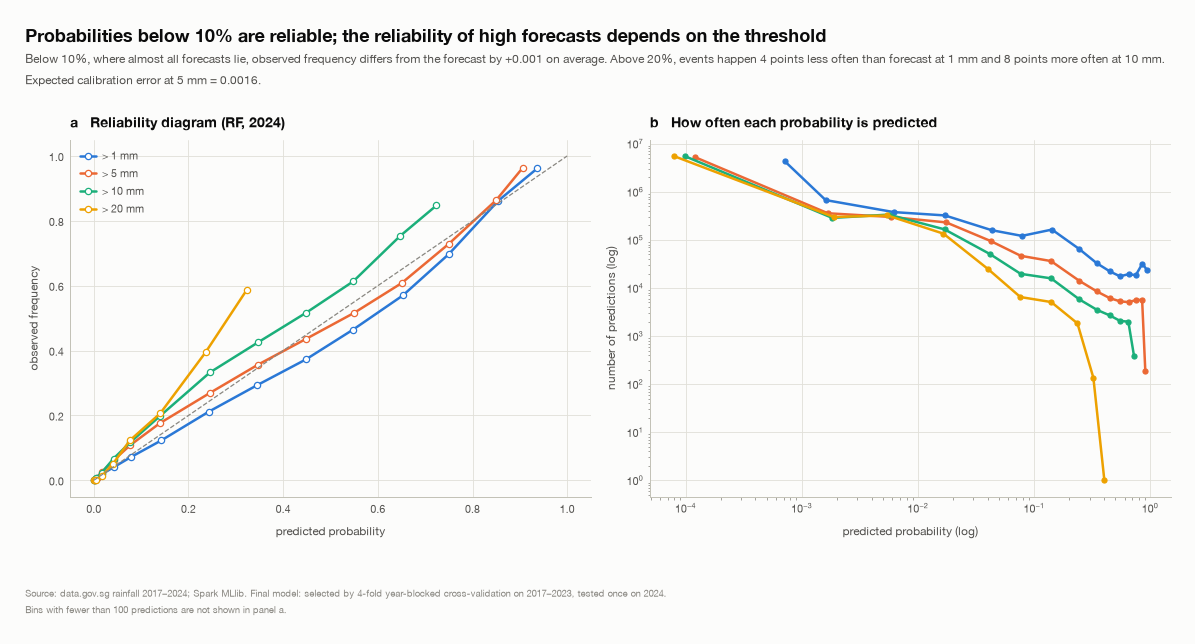

  [figure] outputs/figures/fig20_task2_final_calibration.png


In [72]:
# --- 16d. Reliability of the final model's probabilities on 2024 -----------------------------------
section("16d. Reliability of the final model's probabilities on 2024", writes='t2_calibration, fig20')
splits = [0.0, 0.001, 0.003, 0.01, 0.03, 0.06, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0000001]
with timed("16d. calibration on 2024"):
    rel = (Bucketizer(splits=splits, inputCol="p", outputCol="bin").transform(preds[FINAL_KEY]).groupBy("thr", "bin")
           .agg(F.count("*").alias("n"), F.avg("p").alias("mean_p"), F.avg("label").alias("obs_freq")).toPandas())
write_table(rel, "t2_calibration")
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ax = axes[0]
for i, t in enumerate([1.0, 5.0, 10.0, 20.0]):
    d = rel[(rel.thr == t) & (rel.n >= 100)].sort_values("mean_p")
    ax.plot(d.mean_p, d.obs_freq, marker="o", ms=5, mfc="white", color=PALETTE[i], label=f"> {t:g} mm")
ax.plot([0, 1], [0, 1], color=MUTED, ls="--", lw=1)
ax.set_xlabel("predicted probability"); ax.set_ylabel("observed frequency")
ax.set_title(f"a   Reliability diagram ({FINAL_KEY}, 2024)")
ax.legend()
ax = axes[1]
for i, t in enumerate([1.0, 5.0, 10.0, 20.0]):
    d = rel[rel.thr == t].sort_values("mean_p")
    ax.plot(d.mean_p, d.n, marker="o", ms=4, color=PALETTE[i])
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("predicted probability (log)"); ax.set_ylabel("number of predictions (log)")
ax.set_title("b   How often each probability is predicted")
fig.tight_layout()


def gap_above(t, cut=0.2):
    d = rel[(rel.thr == t) & (rel.n >= 100) & (rel.mean_p >= cut)]
    return float((d.n * (d.obs_freq - d.mean_p)).sum() / d.n.sum()) if len(d) else float("nan")


lo_ = rel[(rel.mean_p < 0.1) & (rel.n >= 100)]
gap_lo = float((lo_.n * (lo_.obs_freq - lo_.mean_p)).sum() / lo_.n.sum())
g_small, g_big = gap_above(1.0), gap_above(10.0)
r5 = rel[(rel.thr == 5.0) & (rel.n >= 100)]
ece5 = (r5.n * (r5.mean_p - r5.obs_freq).abs()).sum() / r5.n.sum()
checkpoint("16d. Calibration of the final model on 2024", [("observed minus forecast, bins below 10 % (where most forecasts lie)", f"{gap_lo:+.4f}"),
    ("observed minus forecast above 20 %, at 1 mm / 10 mm", f"{g_small:+.3f} / {g_big:+.3f}"), ("expected calibration error at 5 mm", f"{ece5:.4f}")])
headline(fig, "Probabilities below 10% are reliable; the reliability of high forecasts depends on the threshold",
         f"Below 10%, where almost all forecasts lie, observed frequency differs from the forecast by {gap_lo:+.3f} on average. "
         f"Above 20%, events happen {abs(g_small) * 100:.0f} points {'less' if g_small < 0 else 'more'} often than forecast at 1 mm "
         f"and {abs(g_big) * 100:.0f} points {'more' if g_big > 0 else 'less'} often at 10 mm.\n"
         f"Expected calibration error at 5 mm = {ece5:.4f}.",
         note="Bins with fewer than 100 predictions are not shown in panel a.")
save_figure(fig, FIGURES / "fig20_task2_final_calibration.png")

In [73]:
# --- 16e. Operating points: cut-offs chosen on 2023, confusion matrix on 2024 ----------------------
section('16e. Operating points: cut-offs chosen on 2023, confusion matrix on 2024', purpose='precision, recall and F1 at the F1-optimal cut-off per threshold; accuracy vs always-no', writes='t2_test_confusion')
# precision / recall at a cut-off chosen on the 2023 validation block (never on the test year)
cut_grid = np.round(np.arange(0.05, 0.96, 0.05), 2)
with timed("16e. cut-offs on 2023 + test confusion"):
    v = (val_models[FINAL_KEY].transform(val_cal.filter(F.col("thr").isin(EVAL_THRESHOLDS)))
         .select("thr", "log_thr", "label", vector_to_array("probability")[1].alias("p_raw")))
    if FINAL_KEY in CALIBRATORS:
        v = CALIBRATORS[FINAL_KEY].transform(add_logit(v)).withColumn("p", vector_to_array("probability_cal")[1])
    else:
        v = v.withColumn("p", F.col("p_raw"))
    vagg = v.groupBy("thr").agg(*[F.sum(((F.col("p") >= c) & (F.col("label") == 1)).cast("long")).alias(f"tp_{i}") for i, c in enumerate(cut_grid)],
                                *[F.sum((F.col("p") >= c).cast("long")).alias(f"pp_{i}") for i, c in enumerate(cut_grid)],
                                F.sum("label").alias("pos")).toPandas()
    cutoffs = {}
    for _, r in vagg.iterrows():
        f1 = [2 * r[f"tp_{i}"] / (r[f"pp_{i}"] + r.pos) if (r[f"pp_{i}"] + r.pos) > 0 else 0 for i in range(len(cut_grid))]
        cutoffs[r.thr] = float(cut_grid[int(np.argmax(f1))])
    cut_sp = F.broadcast(spark.createDataFrame(pd.DataFrame({"thr": list(cutoffs), "cut": list(cutoffs.values())})))
    conf = (preds[FINAL_KEY].join(cut_sp, "thr").withColumn("yhat", (F.col("p") >= F.col("cut")).cast("double"))
            .groupBy("thr", "cut").agg(F.sum(F.col("yhat") * F.col("label")).alias("tp"),
                                       F.sum(F.col("yhat") * (1 - F.col("label"))).alias("fp"),
                                       F.sum((1 - F.col("yhat")) * F.col("label")).alias("fn"),
                                       F.count("*").alias("n")).toPandas())
conf["precision"] = conf.tp / (conf.tp + conf.fp)
conf["recall"] = conf.tp / (conf.tp + conf.fn)
conf["f1"] = 2 * conf.precision * conf.recall / (conf.precision + conf.recall)
conf["accuracy"] = 1 - (conf.fp + conf.fn) / conf.n
conf["accuracy_always_no"] = 1 - (conf.tp + conf.fn) / conf.n
conf = write_table(conf.sort_values("thr"), "t2_test_confusion")
c5 = conf[conf.thr == 5.0].iloc[0]
checkpoint("16e. Operating points", [("cut-off per threshold (chosen on 2023)", {float(k): v for k, v in cutoffs.items()}),
    ("at 5 mm: precision / recall / F1", f"{c5.precision:.3f} / {c5.recall:.3f} / {c5.f1:.3f}"),
    ("at 5 mm: accuracy vs always-no", f"{100 * c5.accuracy:.2f} % vs {100 * c5.accuracy_always_no:.2f} % (why accuracy is not the metric here)")])
conf.round(4)

09:13:05  16e. Operating points: cut-offs chosen on 2023, confusion matrix on 2024
Purpose : precision, recall and F1 at the F1-optimal cut-off per threshold; accuracy vs always-no
Writes  : t2_test_confusion


[09:13:53]  done: 16e. cut-offs on 2023 + test confusion  (48.5 s)
  [table] outputs/tables/t2_test_confusion.csv  (6 rows)

-- 16e. Operating points -----------------------------------------------------------------------
   cut-off per threshold (chosen on 2023) : {20.0: 0.1, 1.0: 0.35, 0.5: 0.4, 2.0: 0.25, 10.0: 0.15, 5.0: 0.2}
   at 5 mm: precision / recall / F1       : 0.484 / 0.459 / 0.471
   at 5 mm: accuracy vs always-no         : 99.14 % vs 99.16 % (why accuracy is not the metric here)



,thr,cut,tp,fp,fn,n,precision,recall,f1,accuracy,accuracy_always_no
4,0.5,0.40,136177.0,54399.0,94894.0,6371188,0.7146,0.5893,0.6459,0.9766,0.9637
5,1.0,0.35,95282.0,52377.0,68508.0,6371188,0.6453,0.5817,0.6119,0.9810,0.9743
3,2.0,0.25,58426.0,44706.0,49153.0,6371188,0.5665,0.5431,0.5546,0.9853,0.9831
0,5.0,0.20,24505.0,26109.0,28893.0,6371188,0.4842,0.4589,0.4712,0.9914,0.9916
1,10.0,0.15,9263.0,12803.0,15098.0,6371188,0.4198,0.3802,0.3990,0.9956,0.9962
2,20.0,0.10,1860.0,5220.0,4699.0,6371188,0.2627,0.2836,0.2727,0.9984,0.9990


09:13:53  16f. Drivers of the final model and its skill by season and hour
Writes  : t2_skill_by_season, t2_skill_by_hour, t2_feature_importance, fig21


[09:13:54]  done: 16f. skill by season / hour  (0.8 s)
  [table] outputs/tables/t2_skill_by_season.csv  (4 rows)
  [table] outputs/tables/t2_skill_by_hour.csv  (24 rows)
  [table] outputs/tables/t2_feature_importance.csv  (36 rows)

-- 16f. Drivers and skill of the final model ---------------------------------------------------
   top 5 features (mean decrease in impurity)  : thr 0.19, log_thr 0.17, r5 0.14, min_since_rain 0.07, r15 0.07
   Brier skill at 5 mm by season: best / worst : Inter-monsoon (Oct-Nov) 0.330 / NE Monsoon (Dec-Mar) 0.272
   weakest hour of day                         : 12:00 (Brier skill 0.110)



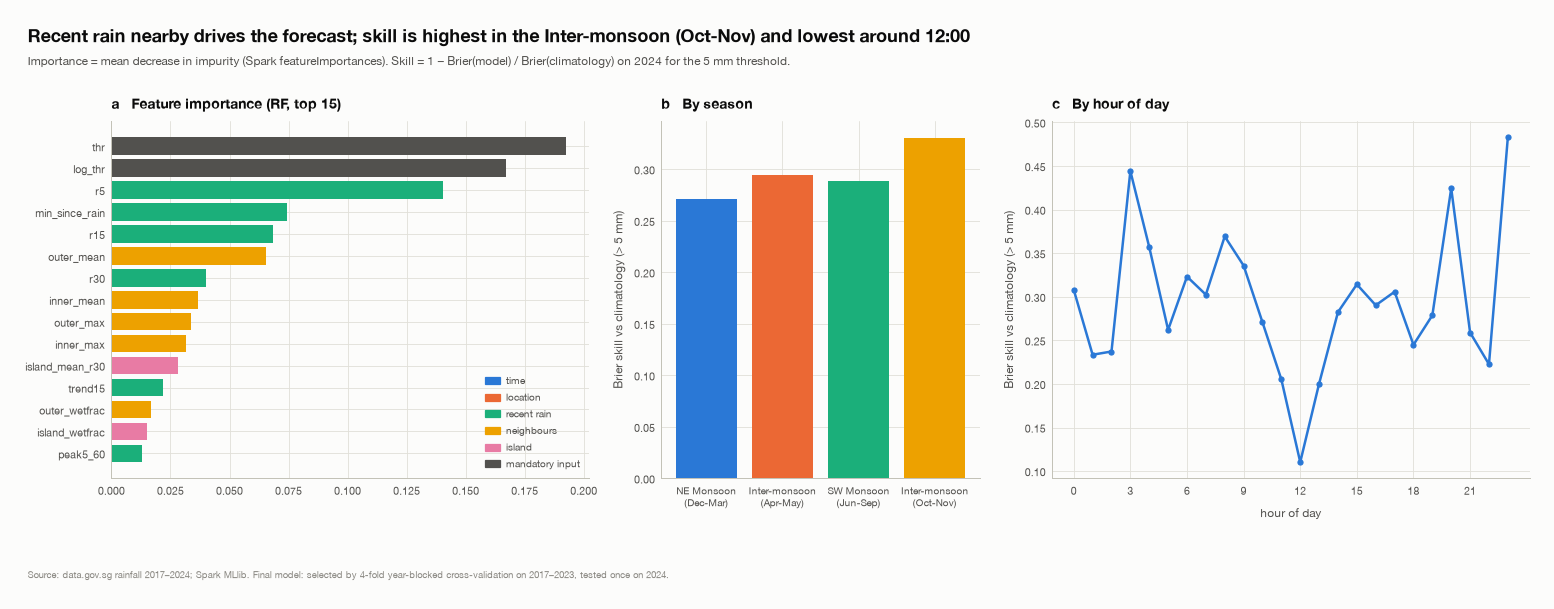

  [figure] outputs/figures/fig21_task2_final_importance_skill.png


In [74]:
# --- 16f. Drivers of the final model and its skill by season and hour ------------------------------
section('16f. Drivers of the final model and its skill by season and hour', writes='t2_skill_by_season, t2_skill_by_hour, t2_feature_importance, fig21')
from matplotlib.patches import Patch


def skill_by(col, t=5.0):
    g = (preds[FINAL_KEY].filter(F.col("thr") == t).groupBy(col)
         .agg(F.avg((F.col("p") - F.col("label")) ** 2).alias("b_model"), F.avg("label").alias("rate")))
    c = (preds["Climatology"].filter(F.col("thr") == t).groupBy(col)
         .agg(F.avg((F.col("p") - F.col("label")) ** 2).alias("b_clim")))
    d = g.join(c, col).toPandas()
    d["brier_skill"] = 1 - d.b_model / d.b_clim
    return d.sort_values(col)


with timed("16f. skill by season / hour"):
    by_season, by_hour = skill_by("season"), skill_by("hour")
write_table(by_season, "t2_skill_by_season")
write_table(by_hour, "t2_skill_by_hour")

grp = {f: g for g, fs in GROUPS.items() for f in fs}
imp = pd.DataFrame({"feature": MANDATORY + SELECTED + ["station"]})
for nm in ["RF", "GBT (Model B)"]:
    imp[nm] = final_models[nm].stages[-1].featureImportances.toArray()
imp["group"] = imp.feature.map(grp).fillna("mandatory input")
IMP_KEY = FINAL_KEY if FINAL_KEY in ("RF", "GBT (Model B)") else "GBT (Model B)"
imp = write_table(imp.sort_values(IMP_KEY, ascending=False), "t2_feature_importance")

fig, axes = plt.subplots(1, 3, figsize=(17, 5), gridspec_kw={"width_ratios": [1.2, 0.8, 1.2]})
ax = axes[0]
top = imp.head(15).iloc[::-1]
gc_ = {**{g: PALETTE[i] for i, g in enumerate(GROUPS)}, "mandatory input": INK_2}
ax.barh(top.feature, top[IMP_KEY], color=[gc_[g] for g in top.group])
ax.legend(handles=[Patch(color=c, label=g) for g, c in gc_.items()], loc="lower right", fontsize=8)
ax.set_title(f"a   Feature importance ({IMP_KEY}, top 15)")
ax = axes[1]
s_ = by_season.set_index("season").reindex(SEASON_NAMES)
ax.bar(range(4), s_.brier_skill, color=[SEASON_COLOR[s] for s in SEASON_NAMES])
ax.set_xticks(range(4)); ax.set_xticklabels([s.replace(" (", "\n(") for s in SEASON_NAMES], fontsize=8)
ax.set_ylabel("Brier skill vs climatology (> 5 mm)")
ax.set_title("b   By season")
ax = axes[2]
ax.plot(by_hour.hour, by_hour.brier_skill, marker="o", ms=4, color=PALETTE[0])
ax.set_xticks(range(0, 24, 3)); ax.set_xlabel("hour of day")
ax.set_ylabel("Brier skill vs climatology (> 5 mm)")
ax.set_title("c   By hour of day")
fig.tight_layout()
weak_h = int(by_hour.loc[by_hour.brier_skill.idxmin(), "hour"])
best_s = by_season.loc[by_season.brier_skill.idxmax(), "season"]
checkpoint("16f. Drivers and skill of the final model", [("top 5 features (mean decrease in impurity)", ", ".join(f"{r['feature']} {r[IMP_KEY]:.2f}" for _, r in imp.head(5).iterrows())),
    ("Brier skill at 5 mm by season: best / worst", f"{best_s} {by_season.brier_skill.max():.3f} / {by_season.loc[by_season.brier_skill.idxmin(), 'season']} {by_season.brier_skill.min():.3f}"),
    ("weakest hour of day", f"{weak_h:02d}:00 (Brier skill {by_hour.brier_skill.min():.3f})")])
headline(fig, f"Recent rain nearby drives the forecast; skill is highest in the {best_s} and lowest around {weak_h:02d}:00",
         "Importance = mean decrease in impurity (Spark featureImportances). Skill = 1 − Brier(model) / Brier(climatology) "
         "on 2024 for the 5 mm threshold.")
save_figure(fig, FIGURES / "fig21_task2_final_importance_skill.png")

## 17. Head-to-head: final model vs the Stage 1 logistic model on identical 2024 rows

Stage 1 keeps rows with a complete 3-hour history and evaluates a 20 % sample of prediction times. Stage 2 keeps
every row with a complete future window and evaluates all of 2024. We compare both models and the Stage 1
climatology on the Stage 1 2024 evaluation rows, matching station, anchor slot and threshold at their shared
thresholds: 1, 2, 5, 10 and 20 mm.

We check that the matched labels agree exactly. Metrics use the same binned toolkit as Section 11, cross-checked
against MLlib.

In [75]:
# --- 17. Head-to-head on identical 2024 rows -------------------------------------------------------
section('17. Head-to-head on identical 2024 rows', purpose='both models scored on the Stage 1 evaluation rows, matched on station, slot and threshold; labels must agree', writes='t41_task2_head_to_head')
COMMON_THR = [1.0, 2.0, 5.0, 10.0, 20.0]
h2h_keys = ["station_id", "slot_epoch", "thr"]
stage1 = lambda name, model, col: (score(name, model, test).filter(F.col("threshold_mm").isin(COMMON_THR))
                                    .select("station_id", F.col("ts").cast("long").alias("slot_epoch"),
                                            F.col("threshold_mm").alias("thr"), "label", F.col("p").alias(col)))
with timed("17. head-to-head on identical 2024 rows"):
    lr_p = stage1(final_name, models[final_name], "p_lr")
    cl_p = stage1("Climatology", None, "p_clim").drop("label")
    rf_p = (preds[FINAL_KEY].filter(F.col("thr").isin(COMMON_THR))
            .select(*h2h_keys, F.col("label").alias("label_final"), F.col("p").alias("p_final")))
    h2h = lr_p.join(cl_p, h2h_keys).join(rf_p, h2h_keys, "inner").cache()
    n_stage1, n_matched = lr_p.count(), h2h.count()
    n_label_mismatch = h2h.filter(F.col("label") != F.col("label_final")).count()
    assert n_label_mismatch == 0, f"{n_label_mismatch} matched rows disagree on the label"
    h2h_rows = []
    for nm, col in [("Climatology (stage 1)", "p_clim"), (f"Logistic regression (stage 1, {final_name})", "p_lr"),
                    (f"{FINAL_LABEL.capitalize()} (final model)", "p_final")]:
        b_ = bin_aggregate(h2h.withColumn("p", F.col(col)), ["thr"])
        h2h_rows.append(group_metrics(b_, ["thr"]).assign(model=nm))
h2h_tab = pd.concat(h2h_rows)[["model", "thr", "n", "n_pos", "prevalence", "pr_auc", "roc_auc", "brier", "logloss"]]
write_table(h2h_tab, "t41_task2_head_to_head")
h2h.unpersist()
fin_, lr__ = h2h_tab[h2h_tab.model.str.contains("final")].set_index("thr"), h2h_tab[h2h_tab.model.str.contains("Logistic")].set_index("thr")
checkpoint("17. Head-to-head on identical 2024 rows", [("Stage 1 evaluation rows (5 thresholds)", f"{n_stage1:,}"),
    ("matched to Stage 2 rows", f"{n_matched:,} ({100 * n_matched / n_stage1:.2f} %)"), ("label mismatches", f"{n_label_mismatch} (must be 0)")] +
    [(f"{t:g} mm: final vs Stage 1", f"PR-AUC {fin_.loc[t, 'pr_auc']:.3f} vs {lr__.loc[t, 'pr_auc']:.3f}   ROC-AUC {fin_.loc[t, 'roc_auc']:.3f} vs {lr__.loc[t, 'roc_auc']:.3f}   "
                                     f"log loss {fin_.loc[t, 'logloss']:.4f} vs {lr__.loc[t, 'logloss']:.4f}") for t in COMMON_THR])
h2h_tab.pivot(index="thr", columns="model", values=["pr_auc", "roc_auc", "logloss"]).round(4)

09:13:55  17. Head-to-head on identical 2024 rows
Purpose : both models scored on the Stage 1 evaluation rows, matched on station, slot and threshold; labels must agree
Writes  : t41_task2_head_to_head


[09:14:03]  done: 17. head-to-head on identical 2024 rows  (8.6 s)
  [table] outputs/tables/t41_task2_head_to_head.csv  (15 rows)

-- 17. Head-to-head on identical 2024 rows -----------------------------------------------------
   Stage 1 evaluation rows (5 thresholds) : 6,275,070
   matched to Stage 2 rows                : 6,275,015 (100.00 %)
   label mismatches                       : 0 (must be 0)
   1 mm: final vs Stage 1                 : PR-AUC 0.663 vs 0.585   ROC-AUC 0.967 vs 0.918   log loss 0.0521 vs 0.0661
   2 mm: final vs Stage 1                 : PR-AUC 0.587 vs 0.524   ROC-AUC 0.968 vs 0.915   log loss 0.0395 vs 0.0489
   5 mm: final vs Stage 1                 : PR-AUC 0.459 vs 0.418   ROC-AUC 0.970 vs 0.912   log loss 0.0238 vs 0.0287
   10 mm: final vs Stage 1                : PR-AUC 0.352 vs 0.327   ROC-AUC 0.975 vs 0.917   log loss 0.0129 vs 0.0150
   20 mm: final vs Stage 1                : PR-AUC 0.191 vs 0.186   ROC-AUC 0.982 vs 0.941   log loss 0.0046 vs 0.0050


pr_auc                                                                                        roc_auc                                                                           \
model Climatology (stage 1) Logistic regression (stage 1, LR_spatial_ix) Random forest (final model) Climatology (stage 1) Logistic regression (stage 1, LR_spatial_ix) Random forest (final model)   
thr                                                                                                                                                                                                   
1.0                  0.0485                                       0.5849                      0.6626                0.6732                                       0.9177                      0.9674   
2.0                  0.0332                                       0.5243                      0.5873                0.6746                                       0.9147                      0.9684   
5.0                  0.0182                                       0.4176                      0.4591                0.6839                                       0.9124                      0.9701   
10.0                 0.0099                                       0.3270                      0.3523                0.6978                                       0.9169                      0.9751   
20.0                 0.0039                                       0.1858                      0.1908                0.7440                                       0.9412                      0.9822   

                    logloss                                                                           
model Climatology (stage 1) Logistic regression (stage 1, LR_spatial_ix) Random forest (final model)  
thr                                                                                                   
1.0                  0.1156                                       0.0661                      0.0521  
2.0                  0.0828                                       0.0489                      0.0395  
5.0                  0.0464                                       0.0287                      0.0238  
10.0                 0.0241                                       0.0150                      0.0129  
20.0                 0.0078                                       0.0050                      0.0046

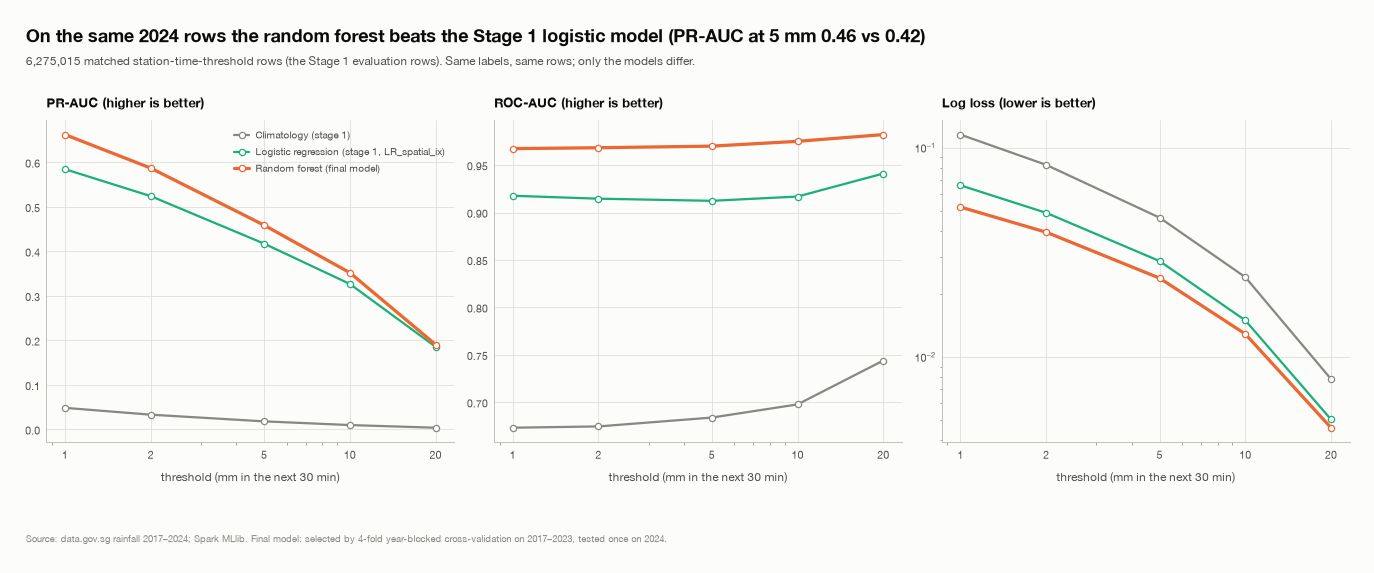

  [figure] outputs/figures/fig22_task2_head_to_head.png
Task 2 final-model figures collected in outputs/figures/task2_final_model_figures.pdf


In [76]:
# --- Figure 22: head-to-head; closes the final-model figure PDF ------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
h2h_col = dict(zip(h2h_tab.model.unique(), [MUTED, PALETTE[2], PALETTE[1]]))
for ax, (col, lab, logy) in zip(axes, [("pr_auc", "PR-AUC (higher is better)", False),
                                       ("roc_auc", "ROC-AUC (higher is better)", False),
                                       ("logloss", "Log loss (lower is better)", True)]):
    for nm, d in h2h_tab.groupby("model", sort=False):
        d = d.sort_values("thr")
        ax.plot(d.thr, d[col], marker="o", ms=5, mfc="white", lw=2.6 if "final" in nm else 1.8, color=h2h_col[nm], label=nm)
    ax.set_xscale("log"); ax.set_xticks(COMMON_THR); ax.set_xticklabels([f"{t:g}" for t in COMMON_THR])
    if logy:
        ax.set_yscale("log")
    ax.set_xlabel("threshold (mm in the next 30 min)")
    ax.set_title(lab, fontsize=10)
axes[0].legend(fontsize=8)
fig.tight_layout()
d5 = h2h_tab[h2h_tab.thr == 5.0].set_index("model")
fin5, lr5 = d5[d5.index.str.contains("final")].iloc[0], d5[d5.index.str.contains("Logistic")].iloc[0]
headline(fig, f"On the same 2024 rows the {FINAL_LABEL} beats the Stage 1 logistic model "
              f"(PR-AUC at 5 mm {fin5.pr_auc:.2f} vs {lr5.pr_auc:.2f})",
         f"{n_matched:,} matched station-time-threshold rows (the Stage 1 evaluation rows). "
         "Same labels, same rows; only the models differ.")
save_figure(fig, FIGURES / "fig22_task2_head_to_head.png")
close_pdf()
print("Task 2 final-model figures collected in outputs/figures/task2_final_model_figures.pdf")

In [77]:
# --- Results of this run, rendered as markdown from the computed values ----------------------------
fin, lr_ = h2h_tab[h2h_tab.model.str.contains("final")].set_index("thr"), h2h_tab[h2h_tab.model.str.contains("Logistic")].set_index("thr")
better = {c: int((fin[c] > lr_[c]).sum()) for c in ["pr_auc", "roc_auc"]}
better["logloss"] = int((fin["logloss"] < lr_["logloss"]).sum())
cs = cal_summary.set_index("model")
display(Markdown(f"""
**Results (computed from this run).**

* **Model selection:** the {FINAL_LABEL} has the lowest cross-validated log loss
  ({best[FINAL_NAME]['cv_logloss']:.4f}, against LR {best['LR']['cv_logloss']:.4f}, RF {best['RF']['cv_logloss']:.4f},
  GBT {best['GBT']['cv_logloss']:.4f}); the selector kept {len(SELECTED)} of {len(CAND_FEATS)} candidate features.
* **Calibration:** the calibrator {'was kept' if FINAL_KEY in CALIBRATORS else 'was not kept'} for the final model
  (held-out log loss {cs.loc[FINAL_KEY, 'holdout_logloss_raw']:.4f} raw vs {cs.loc[FINAL_KEY, 'holdout_logloss_cal']:.4f} calibrated).
* **2024 test (all rows), 5 mm:** PR-AUC {g5.pr_auc:.3f} (base rate {g5.base_rate:.4f}), ROC-AUC {g5.roc_auc:.3f},
  Brier skill vs climatology {g5.brier_skill:.3f}; the running minimum changed {100 * test_metrics[test_metrics.model == FINAL_KEY].monotone_fix_rate.max():.3f} % of predictions at most.
* **Head-to-head on identical rows:** the final model beats the Stage 1 logistic model on PR-AUC at {better['pr_auc']} of 5
  thresholds, on ROC-AUC at {better['roc_auc']} of 5 and on log loss at {better['logloss']} of 5; at 5 mm PR-AUC
  {fin.loc[5.0, 'pr_auc']:.3f} vs {lr_.loc[5.0, 'pr_auc']:.3f}, ROC-AUC {fin.loc[5.0, 'roc_auc']:.3f} vs {lr_.loc[5.0, 'roc_auc']:.3f}.
* **Ablation:** removing the {worst.variant.replace('without ', '')} features hurts most
  ({worst['delta_logloss_%']:+.1f} % validation log loss); time and location alone (Model A) are far weaker.
"""))


**Results (computed from this run).**

* **Model selection:** the random forest has the lowest cross-validated log loss
  (0.0319, against LR 0.0391, RF 0.0319,
  GBT 0.0403); the selector kept 33 of 33 candidate features.
* **Calibration:** the calibrator was kept for the final model
  (held-out log loss 0.0294 raw vs 0.0288 calibrated).
* **2024 test (all rows), 5 mm:** PR-AUC 0.465 (base rate 0.0084), ROC-AUC 0.969,
  Brier skill vs climatology 0.293; the running minimum changed 0.055 % of predictions at most.
* **Head-to-head on identical rows:** the final model beats the Stage 1 logistic model on PR-AUC at 5 of 5
  thresholds, on ROC-AUC at 5 of 5 and on log loss at 5 of 5; at 5 mm PR-AUC
  0.459 vs 0.418, ROC-AUC 0.970 vs 0.912.
* **Ablation:** removing the recent rain features hurts most
  (+7.8 % validation log loss); time and location alone (Model A) are far weaker.


## 18. The final model: save it and use it with `predict(station, time, threshold)`

We save the final pipeline (station indexer, feature assembler, classifier) with `PipelineModel.save` at
`models/task2_final_rf/rain30_model`. The folder name is fixed; `feature_spec.json` records which model won. If kept, the
calibrator is saved as `rain30_calibrator`; the folder also contains `feature_spec.json` and `stations.csv`. We also keep
the Stage 1 logistic baseline in `models/task2_baseline_lr/`.

`predict()` rebuilds features with the training functions (`station_features`, `neighbour_island_features`,
`add_final_time_features`), using readings at or before the anchor slot only (`t` − 5 min, as defined in Section 4.3).
It scores the six thresholds evaluated in Section 16 (0.5, 1, 2, 5, 10, 20 mm) and applies the same running minimum.
At these thresholds, it therefore returns the probabilities described by the reported metrics.

For other thresholds, it interpolates in log *h* between the six points. The curve extends to 0.2 mm and to 30 and
60 mm using the model's values at those points, clipped to keep it non-increasing. The grid is fixed across
requests, so separate calls cannot return a higher probability for a higher threshold.

To use the saved model without retraining, run Section 0, every cell whose first line is `# definitions`, and then
this section. It requires the silver layer from Section 3 (`data_parquet/silver/`).

In [78]:
# --- 18. Save the final model ----------------------------------------------------------------------
section('18. Save the final model', writes='models/task2_final_rf/{rain30_model, rain30_calibrator, feature_spec.json, stations.csv}')
final = final_models[FINAL_KEY]
shutil.rmtree(FINAL_MODEL_DIR, ignore_errors=True)
FINAL_MODEL_DIR.mkdir(parents=True)
final.write().overwrite().save(str(FINAL_MODEL_DIR / "rain30_model"))
if FINAL_KEY in CALIBRATORS:
    CALIBRATORS[FINAL_KEY].write().overwrite().save(str(FINAL_MODEL_DIR / "rain30_calibrator"))
spec = {"final_model": FINAL_LABEL, "params": {"LR": lr_best, "RF": rf_best, "GBT": gbt_best}[FINAL_NAME],
        "calibrated": FINAL_KEY in CALIBRATORS, "cv_logloss": {n: float(best[n]["cv_logloss"]) for n in best},
        "features_in_order": MANDATORY + SELECTED + ["station"], "selected_candidates": SELECTED,
        "threshold_range_mm": [THRESH_MIN, THRESH_MAX], "horizon_min": 30, "train_years": TRAIN_YEARS,
        "test_year": TEST_YEAR, "quiet_frac": QUIET_FRAC, "neighbour_rings_km": [NB_INNER_KM, NB_OUTER_KM, WEST_MAX_KM],
        "min_since_rain_cap": MIN_SINCE_CAP,
        "timestamp_convention": "row stamp = START of 5-min interval; prediction time t uses the slot stamped t - 5 min",
        "trained": datetime.now().isoformat(timespec="seconds")}
(FINAL_MODEL_DIR / "feature_spec.json").write_text(json.dumps(spec, indent=1))
stations.to_csv(FINAL_MODEL_DIR / "stations.csv", index=False)
files_ = sorted(str(p.relative_to(FINAL_MODEL_DIR)) for p in FINAL_MODEL_DIR.iterdir())
checkpoint("18. Saved final model", [("model / calibrated", f"{FINAL_LABEL} / {FINAL_KEY in CALIBRATORS}"),
    ("folder", str(FINAL_MODEL_DIR.relative_to(ROOT))), ("contents", ", ".join(files_)), ("size", f"{du(FINAL_MODEL_DIR):.1f} MB"),
    ("features", f"{len(spec['features_in_order'])} ({len(SELECTED)} selected + threshold, log threshold, station)")])

09:14:04  18. Save the final model
Writes  : models/task2_final_rf/{rain30_model, rain30_calibrator, feature_spec.json, stations.csv}



-- 18. Saved final model -----------------------------------------------------------------------
   model / calibrated : random forest / True
   folder             : models/task2_final_rf
   contents           : feature_spec.json, rain30_calibrator, rain30_model, stations.csv
   size               : 11.5 MB
   features           : 36 (33 selected + threshold, log threshold, station)



In [79]:
# --- 18. predict(station, time, threshold): reload the saved model and rebuild the features at request time ---
section('18. predict(station, time, threshold): reload the saved model and rebuild the features at request time', purpose='the same feature functions as training, from readings at or before the anchor slot only; refuses invalid requests')
spec = json.loads((FINAL_MODEL_DIR / "feature_spec.json").read_text())
saved_final = PipelineModel.load(str(FINAL_MODEL_DIR / "rain30_model"))
saved_cal = PipelineModel.load(str(FINAL_MODEL_DIR / "rain30_calibrator")) if spec["calibrated"] else None
stations = pd.read_csv(FINAL_MODEL_DIR / "stations.csv")
pairs_sp = F.broadcast(spark.createDataFrame(ring_pairs(stations)[["station_id", "nb_id"] + RINGS]))
st_sp = F.broadcast(spark.createDataFrame(stations[["station_id", "lat", "lon"]]))
silver2 = (spark.read.parquet(str(SILVER / "readings"))
           .withColumn("slot_epoch", F.col("ts").cast("long")).withColumn("slot_ts", F.col("ts")))
FIVE = pd.Timedelta(minutes=5)
FIRST_SLOT, LAST_SLOT = pd.Timestamp("2017-01-01 00:00:00"), pd.Timestamp("2024-12-31 23:55:00")
# predict() scores the six thresholds that Section 16 evaluated and applies the same running minimum over them, so at those
# thresholds it returns exactly the evaluated probabilities; the curve is extended to the edges of the trained range
PRED_GRID = sorted(set(EVAL_THRESHOLDS) | {spec["threshold_range_mm"][0], 30.0, spec["threshold_range_mm"][1]})
EVAL_SET = sorted(EVAL_THRESHOLDS)


class PredictionError(ValueError):
    """A request that cannot be answered, with a user-facing reason."""


def predict(station, time_str, threshold, curve=False):
    """P(rain over the next 30 minutes > threshold mm) at `station` for a prediction time in SGT."""
    if station not in set(stations.station_id):
        raise PredictionError(f"Unknown station '{station}'; {len(stations)} stations are known (see stations.csv).")
    threshold = float(threshold)
    lo_thr, hi_thr = spec["threshold_range_mm"]
    if not (math.isfinite(threshold) and lo_thr <= threshold <= hi_thr):
        raise PredictionError(f"Threshold {threshold} mm is outside the trained range {lo_thr}-{hi_thr} mm.")
    try:
        t = pd.Timestamp(time_str)
    except Exception:
        raise PredictionError(f"Cannot parse time '{time_str}'. Use e.g. '2024-10-01 15:00:00' (SGT).")
    if t.tzinfo is not None:
        t = t.tz_convert("Asia/Singapore").tz_localize(None)
    t_snap = t.floor("5min")
    anchor = t_snap - FIVE                                   # the last fully observed 5-minute slot
    if not (FIRST_SLOT <= anchor <= LAST_SLOT):
        raise PredictionError(f"Prediction time {t} is outside the available data ({FIRST_SLOT + FIVE} to {LAST_SLOT + FIVE}).")
    a = int(anchor.tz_localize("Asia/Singapore").timestamp())
    years = sorted({(anchor - pd.Timedelta(days=1)).year, anchor.year})
    hist = silver2.filter(F.col("year").isin(years) & (F.col("slot_epoch") > a - 86400) & (F.col("slot_epoch") <= a))
    sfx = station_features(hist).filter(F.col("slot_epoch") == a).cache()     # every gauge at the anchor slot
    if sfx.filter(F.col("station_id") == station).count() == 0:
        raise PredictionError(f"No reading for {station} in the 5-minute interval ending at {anchor + FIVE}: "
                              "the gauge was not reporting.")
    nb = neighbour_island_features(sfx, hist, pairs_sp)
    row = add_final_time_features(sfx.filter(F.col("station_id") == station)
                                  .join(nb.drop("year"), ["station_id", "slot_epoch"], "left").join(st_sp, "station_id"))
    x = row.crossJoin(spark.createDataFrame([(float(g),) for g in PRED_GRID], ["thr"])).withColumn("log_thr", F.log("thr"))
    raw = saved_final.transform(x).select("thr", "log_thr", vector_to_array("probability")[1].alias("p_raw"))
    if saved_cal is not None:
        out = saved_cal.transform(add_logit(raw)).select("thr", vector_to_array("probability_cal")[1].alias("p"))
    else:
        out = raw.select("thr", F.col("p_raw").alias("p"))
    out = out.toPandas().sort_values("thr").reset_index(drop=True)
    ev = out.thr.isin(EVAL_SET).to_numpy()
    p = out.p.to_numpy().copy()
    p[ev] = np.minimum.accumulate(p[ev])                      # the evaluation's running minimum over the six thresholds (Section 16)
    lo, hi = np.where(ev)[0][0], np.where(ev)[0][-1]
    p[:lo] = np.maximum(p[:lo], p[lo])                        # below 0.5 mm: never lower than P(> 0.5 mm)
    for k_ in range(hi + 1, len(p)):                          # above 20 mm: never higher than the previous point
        p[k_] = min(p[k_], p[k_ - 1])
    out["p"] = p                                              # non-increasing in h, equal to the evaluated values at the six thresholds
    prob = float(np.interp(math.log(threshold), np.log(out.thr.to_numpy()), p))   # log-h interpolation between grid points
    info = row.select("r5", "r30", "r180", "min_since_rain", "island_wetfrac").first().asDict()
    sfx.unpersist()
    return {"station": station, "time": t, "time_used": t_snap, "threshold": threshold, "probability": prob,
            "curve": out if curve else None, "inputs": info}


r = predict("S77", "2024-10-01 15:00:00", 5, curve=True)
i = r["inputs"]
print(f"Station {r['station']}, prediction time {r['time']:%Y-%m-%d %H:%M} SGT, threshold {r['threshold']:g} mm")
print(f"P(> {r['threshold']:g} mm in the next 30 minutes) = {r['probability']:.3f}")
print(f"(last 5 min {i['r5']:.1f} mm, last 30 min {i['r30']:.1f} mm, last 3 h {i['r180']:.1f} mm, "
      f"{i['min_since_rain']:.0f} min since rain, {100 * i['island_wetfrac']:.0f} % of gauges wet)")
r["curve"].round(4)

09:14:06  18. predict(station, time, threshold): reload the saved model and rebuild the features at request time
Purpose : the same feature functions as training, from readings at or before the anchor slot only; refuses invalid requests


Station S77, prediction time 2024-10-01 15:00 SGT, threshold 5 mm
P(> 5 mm in the next 30 minutes) = 0.001
(last 5 min 0.0 mm, last 30 min 0.2 mm, last 3 h 0.8 mm, 15 min since rain, 15 % of gauges wet)


,thr,p
0,0.2,0.0280
1,0.5,0.0177
2,1.0,0.0077
3,2.0,0.0030
4,5.0,0.0010
5,10.0,0.0006
6,20.0,0.0004
7,30.0,0.0003
8,60.0,0.0002


In [80]:
# --- 18. predict() on a storm, and on requests that must be refused --------------------------------
# a storm in the 2024 test year, and requests the model must refuse
storm = (test_rows.filter(F.col("r30") >= 10).orderBy("slot_epoch")
         .withColumn("when", F.date_format(F.col("slot_ts") + F.expr("INTERVAL 5 MINUTES"), "yyyy-MM-dd HH:mm:ss")).first())
for h in (1, 5, 10, 20):
    r = predict(storm["station_id"], storm["when"], h)
    print(f"{storm['station_id']} at {storm['when']}: P(> {h:>2} mm) = {r['probability']:.3f}   "
          f"(last 30 min {r['inputs']['r30']:.1f} mm; actual next 30 min {storm['fut30']:.1f} mm)")
# consistency across separate calls: a higher threshold can never get a higher probability, whatever the requests
checks = [predict("S115", "2024-01-19 16:50", h)["probability"] for h in (4.03318, 4.11059, 4.5, 7.25)]
assert all(a >= b - 1e-12 for a, b in zip(checks, checks[1:])), checks
print("separate calls at 4.03318 / 4.11059 / 4.5 / 7.25 mm:", " >= ".join(f"{p:.4f}" for p in checks), "(non-increasing)")
# the delivered predictor returns the probabilities the evaluation used: compare with the stored 2024 predictions (Section 16)
a_chk = int(pd.Timestamp("2024-01-19 16:45").tz_localize("Asia/Singapore").timestamp())
stored = (preds[FINAL_KEY].filter((F.col("station_id") == "S115") & (F.col("slot_epoch") == a_chk))
          .select("thr", "p").toPandas().set_index("thr")["p"])
live = {h: predict("S115", "2024-01-19 16:50", h)["probability"] for h in EVAL_THRESHOLDS}
assert all(abs(live[h] - stored[h]) < 1e-9 for h in EVAL_THRESHOLDS), (live, stored.to_dict())
print("predict() equals the stored evaluation probabilities at the six thresholds:",
      ", ".join(f"{h:g} mm {live[h]:.6f}" for h in EVAL_THRESHOLDS))
for bad in [("S999", "2024-10-01 15:00:00", 5), ("S77", "2024-10-01 15:00:00", 75), ("S77", "2016-05-01 12:00", 5)]:
    try:
        predict(*bad)
    except PredictionError as e:
        print(f"refused {bad}: {e}")

S201 at 2024-01-01 13:55:00: P(>  1 mm) = 0.892   (last 30 min 12.2 mm; actual next 30 min 1.4 mm)


S201 at 2024-01-01 13:55:00: P(>  5 mm) = 0.724   (last 30 min 12.2 mm; actual next 30 min 1.4 mm)


S201 at 2024-01-01 13:55:00: P(> 10 mm) = 0.397   (last 30 min 12.2 mm; actual next 30 min 1.4 mm)


S201 at 2024-01-01 13:55:00: P(> 20 mm) = 0.128   (last 30 min 12.2 mm; actual next 30 min 1.4 mm)


separate calls at 4.03318 / 4.11059 / 4.5 / 7.25 mm: 0.0437 >= 0.0430 >= 0.0392 >= 0.0192 (non-increasing)


predict() equals the stored evaluation probabilities at the six thresholds: 0.5 mm 0.284093, 1 mm 0.158903, 2 mm 0.073018, 5 mm 0.034781, 10 mm 0.005712, 20 mm 0.002907
refused ('S999', '2024-10-01 15:00:00', 5): Unknown station 'S999'; 91 stations are known (see stations.csv).
refused ('S77', '2024-10-01 15:00:00', 75): Threshold 75.0 mm is outside the trained range 0.2-60.0 mm.
refused ('S77', '2016-05-01 12:00', 5): Prediction time 2016-05-01 12:00:00 is outside the available data (2017-01-01 00:05:00 to 2025-01-01 00:00:00).


A storm can stop or start without warning, so an individual forecast can miss. We judge the probabilities across
many forecasts using the reliability diagrams in Sections 11 and 16.

## 19. Summary

We processed 7.5 GB of CSV (48.5 M readings, 91 gauges) into bronze Parquet, then cleaned silver data, keeping
99.6 % of the readings. Cleaning aligned timestamps and removed 86 duplicates, one impossible value, 67 dead-gauge
station-months and 4 spike days. Spark DataFrames, window functions and broadcast joins produced the analysis and
feature tables.

Annual rainfall ranges from 1,787 mm (2019) to 2,900 mm (2021). Dry years have fewer rain events, not lighter rain.
We found two wet seasons (Nov–Jan, Apr–May) and two diurnal regimes: a 10:00 peak in the south-west monsoon and
15:00–16:00 otherwise. Rain is concentrated, with 10 % of wet slots delivering 49 % of the total. The west is 2.1×
wetter than the east, and rainfall decorrelates within ~8.5 km. Heavy half-hours were ~23 % more frequent in 2020–24
than in 2017–19, but no series shows a statistically significant trend over the eight years. The results also hold
on a fixed network of 21 gauges, so the changing network does not explain them.

In [81]:
# --- 19. Run summary -------------------------------------------------------------------------------
section('19. Run summary', writes='t40_stage_timings')
s1 = macro_tab[macro_tab["split"] == "test"].set_index("model")
display(Markdown(f"""
**Task 2.** Two stages answer P(rain in the next 30 min > *h*) for any station, time and threshold.

* **Stage 1 (baseline):** a Spark MLlib logistic regression on the station's own recent rain and its 4 nearest
  gauges, selected on 2023: macro PR-AUC {s1.loc[final_name, 'macro_pr_auc']:.3f} and ROC-AUC
  {s1.loc[final_name, 'macro_roc_auc']:.3f} on 2024 (climatology {s1.loc['Climatology', 'macro_pr_auc']:.3f} and
  {s1.loc['Climatology', 'macro_roc_auc']:.3f}); calibrated and monotone in the threshold by construction.
* **Final model:** a {FINAL_LABEL} on richer features (time since rain, storm trend, three neighbour rings,
  island-wide rain), chosen by 4-fold year-blocked cross-validation over logistic regression, random forest and GBT,
  {'with' if FINAL_KEY in CALIBRATORS else 'without'} a held-out-checked calibrator. On all of 2024 at 5 mm: PR-AUC
  {g5.pr_auc:.3f}, ROC-AUC {g5.roc_auc:.3f}. On identical rows it beats Stage 1 at 5 mm (PR-AUC
  {fin.loc[5.0, 'pr_auc']:.3f} vs {lr_.loc[5.0, 'pr_auc']:.3f}).
* **Limitations:** a single test year; thin data above 20 mm; no radar or satellite inputs; local-mode Spark only.
"""))
timings = write_table(pd.DataFrame(TIMINGS), "t40_stage_timings")
top5 = timings.sort_values("seconds", ascending=False).head(5)
checkpoint("19. Where the time went", [("stages timed", len(timings)), ("total", f"{timings.seconds.sum() / 60:.1f} min")] +
           [(r.stage, f"{r.seconds / 60:.1f} min ({100 * r.seconds / timings.seconds.sum():.0f} %)") for r in top5.itertuples()])
timings

09:14:54  19. Run summary
Writes  : t40_stage_timings



**Task 2.** Two stages answer P(rain in the next 30 min > *h*) for any station, time and threshold.

* **Stage 1 (baseline):** a Spark MLlib logistic regression on the station's own recent rain and its 4 nearest
  gauges, selected on 2023: macro PR-AUC 0.446 and ROC-AUC
  0.919 on 2024 (climatology 0.034 and
  0.690); calibrated and monotone in the threshold by construction.
* **Final model:** a random forest on richer features (time since rain, storm trend, three neighbour rings,
  island-wide rain), chosen by 4-fold year-blocked cross-validation over logistic regression, random forest and GBT,
  with a held-out-checked calibrator. On all of 2024 at 5 mm: PR-AUC
  0.465, ROC-AUC 0.969. On identical rows it beats Stage 1 at 5 mm (PR-AUC
  0.459 vs 0.418).
* **Limitations:** a single test year; thin data above 20 mm; no radar or satellite inputs; local-mode Spark only.


  [table] outputs/tables/t40_stage_timings.csv  (67 rows)

-- 19. Where the time went ---------------------------------------------------------------------
   stages timed                                                        : 67
   total                                                               : 72.6 min
   14. CV GBT (12 settings x 4 folds)                                  : 25.7 min (35 %)
   14. CV RF (4 settings x 4 folds)                                    : 9.7 min (13 %)
   16a. refit RF on 2017-2023                                          : 4.5 min (6 %)
   15c. calibration check (fit on 1st half, judge on 2nd half of 2023) : 3.3 min (5 %)
   16c. test metrics                                                   : 2.2 min (3 %)



,stage,seconds
0,1. ingest: CSV -> bronze Parquet,17.0
1,2. data-quality audit,6.2
2,3a. clean: snap + de-duplicate + station table,11.3
3,3b. clean: dead-gauge station-months,2.6
4,3c. clean: spike station-days,8.2
...,...,...
62,16c. test metrics,131.0
63,16d. calibration on 2024,0.4
64,16e. cut-offs on 2023 + test confusion,48.5
65,16f. skill by season / hour,0.8


## 20. Scalability: strong and weak scaling of the same Spark job

The analysis above ran in local mode on one machine. We benchmark the core of the cleaning stage to measure how it
scales across cores: read the bronze rows, snap timestamps, de-duplicate (shuffle 1), aggregate to station-days
(shuffle 2), then sum the usable station-day totals. Each configuration gets a fresh Spark session. After one
warm-up run for the file cache, we report the median of three runs.

* Strong scaling keeps all 8 years fixed and uses `local[2]`, `[4]`, `[8]` and `[16]`. Speed-up is
  S(n) = T(2) / T(n), with ideal n / 2. We fit Amdahl's law, Speedup = 1 / (S + P/n), with serial part S and parallel
  part P = 1 − S, to the measured times as T(n) = a + b/n. Under this model, S = a / (a + b) is the estimated serial
  share of the one-core time and 1 / S is the limiting speed-up.
* Weak scaling grows the problem with the cores: 1 year on 2 cores, 2 years on 4, 4 on 8 and 8 on 16. Ideally,
  runtime stays constant as work and cores grow together; Gustafson's law describes scaled speed-up growing
  linearly with n. The years differ in size, so we measure efficiency as throughput per core relative to 2 cores.

We also timed the same job on a Google Cloud Dataproc cluster with 2 and 4 `n2-standard-2` workers, using
`cloud/dataproc_benchmark.py` submitted through `gcloud dataproc jobs submit pyspark`. The results are in
`outputs/tables/cloud/t43_cloud_scaling.csv`; the second cell below compares them with the laptop. More cores on one
machine share a memory bus and disk. More workers add memory and disk as well as CPU resources.

09:14:54  20. Scalability: strong and weak scaling of the cleaning job
Purpose : strong scaling (8 years, 2-16 cores) with an Amdahl fit, and weak scaling (data grows with the cores)
Writes  : t42_scaling, t45_weak_scaling, t47_amdahl_fit, fig23


[09:15:02]  warm-up on 16 cores: 6.5 s (discarded)


[09:16:25]  strong  local[ 2], all 8 years: median 27.8 s  (runs 27.9 / 27.3 / 27.8)


[09:17:06]  strong  local[ 4], all 8 years: median 13.6 s  (runs 13.6 / 13.7 / 13.3)


[09:17:31]  strong  local[ 8], all 8 years: median 8.0 s  (runs 8.1 / 8.0 / 7.9)


[09:17:49]  strong  local[16], all 8 years: median 5.7 s  (runs 6.2 / 5.7 / 5.7)
  [table] outputs/tables/t42_scaling.csv  (4 rows)
  [table] outputs/tables/t47_amdahl_fit.csv  (1 rows)


[09:18:00]  weak    local[ 2], 1 year(s), 5.3 M rows: median 3.3 s


[09:18:11]  weak    local[ 4], 2 year(s), 9.9 M rows: median 3.5 s


[09:18:23]  weak    local[ 8], 4 year(s), 21.2 M rows: median 3.9 s


[09:18:41]  weak    local[16], 8 year(s), 48.5 M rows: median 5.8 s
  [table] outputs/tables/t45_weak_scaling.csv  (4 rows)


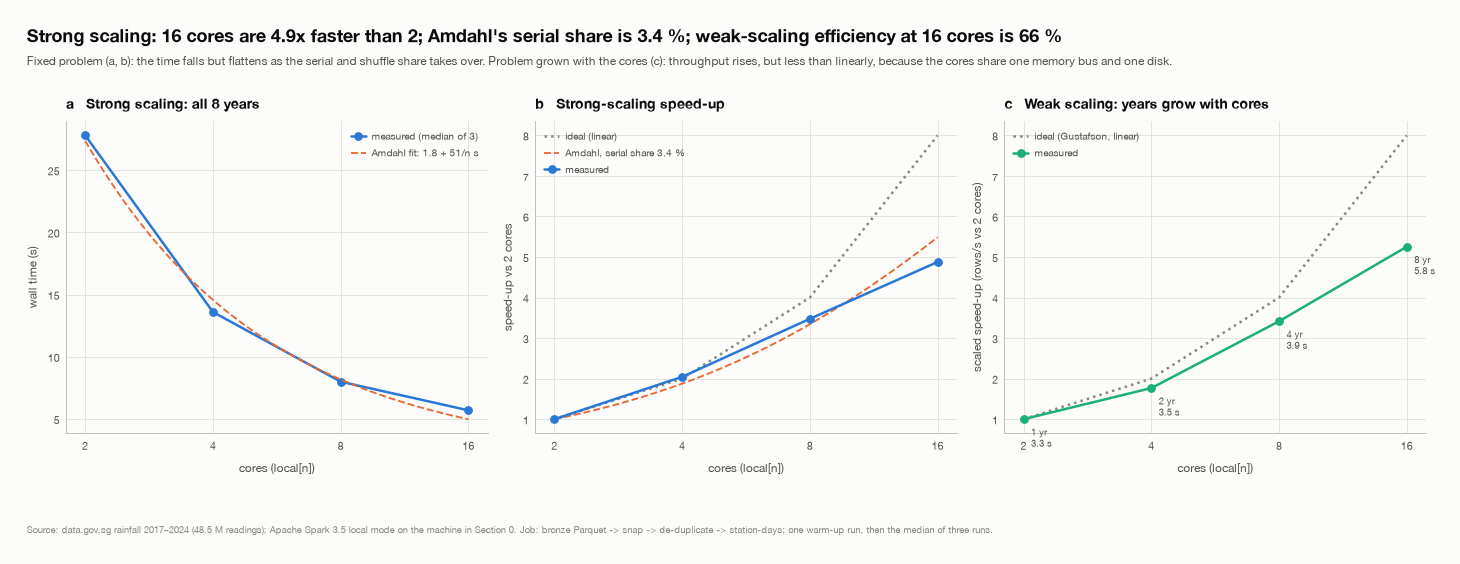

  [figure] outputs/figures/fig23_scaling.png

-- 20. Strong scaling (all years) --------------------------------------------------------------
   local[2]   : 27.8 s   speed-up 1.00x   efficiency 100 %
   local[4]   : 13.6 s   speed-up 2.04x   efficiency 102 %
   local[8]   : 8.0 s   speed-up 3.48x   efficiency 87 %
   local[16]  : 5.7 s   speed-up 4.88x   efficiency 61 %
   Amdahl fit : T(n) = 1.79 + 51.1/n s; serial share S = 3.4 %; max speed-up 30x vs 1 core, 15.3x vs 2 cores


-- 20. Weak scaling (years grow with cores) ----------------------------------------------------
   local[2], 1 yr (5.3 M rows)   : 3.3 s   scaled speed-up 1.00x (ideal 1x)   efficiency 100 %
   local[4], 2 yr (9.9 M rows)   : 3.5 s   scaled speed-up 1.77x (ideal 2x)   efficiency 88 %
   local[8], 4 yr (21.2 M rows)  : 3.9 s   scaled speed-up 3.41x (ideal 4x)   efficiency 85 %
   local[16], 8 yr (48.5 M rows) : 5.8 s   scaled speed-up 5.25x (ideal 8x)   efficiency 66 %



In [82]:
# --- 20. Scalability benchmark: strong scaling, Amdahl's law and weak scaling -------------------------------
section("20. Scalability: strong and weak scaling of the cleaning job",
        purpose="strong scaling (8 years, 2-16 cores) with an Amdahl fit, and weak scaling (data grows with the cores)",
        writes="t42_scaling, t45_weak_scaling, t47_amdahl_fit, fig23")
cv_data.unpersist()
spark.stop()
SPARK_BASE = {"spark.driver.memory": os.environ.get("SPARK_DRIVER_MEMORY", "12g"), "spark.driver.bindAddress": "127.0.0.1",
              "spark.driver.host": "127.0.0.1", "spark.sql.session.timeZone": "Asia/Singapore",
              "spark.sql.shuffle.partitions": "96", "spark.ui.showConsoleProgress": "false",
              "spark.local.dir": os.environ.get("SPARK_LOCAL_DIR", "/tmp/spark-tmp"),
              "spark.driver.extraJavaOptions": f"-Dlog4j2.configurationFile={LOG4J.as_uri()}"}
REPEATS = int(os.environ.get("BENCH_REPEATS", "3"))


def bench_session(n_cores):
    b = SparkSession.builder.appName(f"dsa5208-bench-{n_cores}").master(f"local[{n_cores}]")
    for k_, v_ in SPARK_BASE.items():
        b = b.config(k_, v_)
    s_ = b.getOrCreate()
    s_.sparkContext.setLogLevel("ERROR")
    return s_


def bench_job(sess, years=None):
    """Bronze -> snapped timestamps -> de-duplicated (shuffle 1) -> station-days (shuffle 2) -> one number."""
    b = sess.read.parquet(str(BRONZE)).filter(F.col("reading_type") == READING_TYPE)
    if years is not None:
        b = b.filter(F.col("year").isin(list(years)))                 # partition pruning: only these year folders are read
    snapped = b.select("station_id", F.timestamp_seconds((F.round(F.unix_timestamp("ts_raw") / F.lit(300)) * F.lit(300))
                                                         .cast("long")).alias("ts"), "rain_mm", "upd")
    d = (snapped.groupBy("station_id", "ts").agg(F.max(F.struct(F.col("upd"), F.col("rain_mm"))).alias("pick"))
         .select("station_id", "ts", F.col("pick.rain_mm").alias("rain_mm")))
    sd = d.groupBy("station_id", F.to_date("ts").alias("date")).agg(F.sum("rain_mm").alias("day_mm"), F.count(F.lit(1)).alias("slots"))
    return sd.filter(F.col("slots") >= MIN_SLOTS).agg(F.sum("day_mm")).first()[0]


def timed_runs(n_cores, years=None):
    """Median wall time of REPEATS runs in one fresh session (the session start-up is not timed)."""
    sess = bench_session(n_cores)
    times, val = [], None
    for _ in range(REPEATS):
        t0_ = time.time()
        val = bench_job(sess, years)
        times.append(time.time() - t0_)
    n_rows = sess.read.parquet(str(BRONZE)).filter(F.col("year").isin(list(years or YEARS))).count()
    sess.stop()
    return float(np.median(times)), times, val, n_rows


CORE_GRID = [c for c in (2, 4, 8, 16) if c <= (os.cpu_count() or 16)]
warm = bench_session(CORE_GRID[-1]); t0_ = time.time(); bench_job(warm); warm.stop()
step(f"warm-up on {CORE_GRID[-1]} cores: {time.time() - t0_:.1f} s (discarded)")

# ---- strong scaling: all years, more cores ----------------------------------------------------------------
bench = []
for n_ in CORE_GRID:
    med, times, total_mm, n_rows = timed_runs(n_)
    bench.append({"cores": n_, "seconds": round(med, 1), "runs_s": " / ".join(f"{t:.1f}" for t in times),
                  "rows": n_rows, "usable_station_day_mm": total_mm})
    step(f"strong  local[{n_:>2}], all {len(YEARS)} years: median {med:.1f} s  (runs {bench[-1]['runs_s']})")
scaling = pd.DataFrame(bench)
scaling["speedup_vs_2_cores"] = scaling.seconds.iloc[0] / scaling.seconds
scaling["ideal_speedup"] = scaling.cores / scaling.cores.iloc[0]
scaling["parallel_efficiency"] = scaling.speedup_vs_2_cores / scaling.ideal_speedup
# the same answer on every core count (floating-point sums differ in the last digits with the partition order)
assert np.allclose(scaling.usable_station_day_mm, scaling.usable_station_day_mm.iloc[0], rtol=1e-9), "the job must return the same answer on every core count"

# ---- Amdahl's law: T(n) = a + b/n, serial share of the one-core time S = a / (a + b) -------------------------
(a_, b_), *_ = np.linalg.lstsq(np.c_[np.ones(len(scaling)), 1 / scaling.cores.to_numpy(float)], scaling.seconds.to_numpy(float), rcond=None)
S_ser = a_ / (a_ + b_)
scaling["amdahl_seconds"] = a_ + b_ / scaling.cores
scaling["amdahl_speedup_vs_2_cores"] = (a_ + b_ / 2) / scaling.amdahl_seconds
write_table(scaling, "t42_scaling")
amdahl = pd.DataFrame([{"fit": "T(n) = a + b/n (least squares)", "a_serial_s": a_, "b_parallel_core_s": b_,
                        "serial_fraction_S": S_ser, "parallel_fraction_P": 1 - S_ser, "max_speedup_vs_1_core": 1 / S_ser,
                        "max_speedup_vs_2_cores": (a_ + b_ / 2) / a_,
                        "rmse_s": float(np.sqrt(np.mean((scaling.seconds - scaling.amdahl_seconds) ** 2)))}])
write_table(amdahl, "t47_amdahl_fit")

# ---- weak scaling: the data grows with the cores ------------------------------------------------------------
WEAK = [(2, YEARS[:1]), (4, YEARS[:2]), (8, YEARS[:4]), (16, YEARS[:8])]
weak = []
for n_, yrs in [w for w in WEAK if w[0] in CORE_GRID]:
    med, times, _, n_rows = timed_runs(n_, yrs)
    weak.append({"cores": n_, "years": f"{yrs[0]}-{yrs[-1]}" if len(yrs) > 1 else str(yrs[0]), "n_years": len(yrs),
                 "rows": n_rows, "seconds": round(med, 1), "runs_s": " / ".join(f"{t:.1f}" for t in times)})
    step(f"weak    local[{n_:>2}], {len(yrs)} year(s), {n_rows / 1e6:.1f} M rows: median {med:.1f} s")
weak = pd.DataFrame(weak)
weak["rows_per_s"] = weak.rows / weak.seconds
weak["scaled_speedup"] = weak.rows_per_s / weak.rows_per_s.iloc[0]                    # Gustafson: ideal = cores / 2
weak["ideal_scaled_speedup"] = weak.cores / weak.cores.iloc[0]
weak["weak_efficiency"] = weak.scaled_speedup / weak.ideal_scaled_speedup
write_table(weak, "t45_weak_scaling")

# ---- figure 23 ------------------------------------------------------------------------------------------------
_PDF = None
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
nn = np.geomspace(scaling.cores.min(), scaling.cores.max(), 50)
axes[0].plot(scaling.cores, scaling.seconds, marker="o", ms=6, color=PALETTE[0], lw=2, label="measured (median of 3)")
axes[0].plot(nn, a_ + b_ / nn, ls="--", color=PALETTE[1], lw=1.5, label=f"Amdahl fit: {a_:.1f} + {b_:.0f}/n s")
axes[0].set_ylabel("wall time (s)"); axes[0].set_title("a   Strong scaling: all 8 years"); axes[0].legend(fontsize=8)
axes[1].plot(scaling.cores, scaling.ideal_speedup, ls=":", color=MUTED, label="ideal (linear)")
axes[1].plot(nn, (a_ + b_ / 2) / (a_ + b_ / nn), ls="--", color=PALETTE[1], lw=1.5, label=f"Amdahl, serial share {100 * S_ser:.1f} %")
axes[1].plot(scaling.cores, scaling.speedup_vs_2_cores, marker="o", ms=6, color=PALETTE[0], lw=2, label="measured")
axes[1].set_ylabel("speed-up vs 2 cores"); axes[1].set_title("b   Strong-scaling speed-up"); axes[1].legend(fontsize=8)
axes[2].plot(weak.cores, weak.ideal_scaled_speedup, ls=":", color=MUTED, label="ideal (Gustafson, linear)")
axes[2].plot(weak.cores, weak.scaled_speedup, marker="o", ms=6, color=PALETTE[2], lw=2, label="measured")
for r in weak.itertuples():
    axes[2].annotate(f"{r.n_years} yr\n{r.seconds:.1f} s", (r.cores, r.scaled_speedup), textcoords="offset points",
                     xytext=(6, -22), fontsize=7.5, color=INK_2)
axes[2].set_ylabel("scaled speed-up (rows/s vs 2 cores)"); axes[2].set_title("c   Weak scaling: years grow with cores"); axes[2].legend(fontsize=8)
for ax in axes:
    ax.set_xscale("log", base=2); ax.set_xticks(CORE_GRID); ax.set_xticklabels(CORE_GRID); ax.set_xlabel("cores (local[n])")
fig.tight_layout()
SRC_BENCH = ("Source: data.gov.sg rainfall 2017–2024 (48.5 M readings); Apache Spark 3.5 local mode on the machine in Section 0. "
             "Job: bronze Parquet -> snap -> de-duplicate -> station-days; one warm-up run, then the median of three runs.")
_src_saved, SRC_T2F = SRC_T2F, SRC_BENCH
headline(fig, f"Strong scaling: {CORE_GRID[-1]} cores are {scaling.speedup_vs_2_cores.iloc[-1]:.1f}x faster than 2; Amdahl's serial share is "
              f"{100 * S_ser:.1f} %; weak-scaling efficiency at {weak.cores.iloc[-1]} cores is {100 * weak.weak_efficiency.iloc[-1]:.0f} %",
         "Fixed problem (a, b): the time falls but flattens as the serial and shuffle share takes over. Problem grown with the cores (c): "
         "throughput rises, but less than linearly, because the cores share one memory bus and one disk.")
save_figure(fig, FIGURES / "fig23_scaling.png")
SRC_T2F = _src_saved
checkpoint("20. Strong scaling (all years)", [(f"local[{r.cores}]", f"{r.seconds:.1f} s   speed-up {r.speedup_vs_2_cores:.2f}x   efficiency {100 * r.parallel_efficiency:.0f} %")
                                              for r in scaling.itertuples()] +
           [("Amdahl fit", f"T(n) = {a_:.2f} + {b_:.1f}/n s; serial share S = {100 * S_ser:.1f} %; max speed-up {1 / S_ser:.0f}x vs 1 core, "
                           f"{(a_ + b_ / 2) / a_:.1f}x vs 2 cores")])
checkpoint("20. Weak scaling (years grow with cores)", [(f"local[{r.cores}], {r.n_years} yr ({r.rows / 1e6:.1f} M rows)",
                                                        f"{r.seconds:.1f} s   scaled speed-up {r.scaled_speedup:.2f}x (ideal {r.ideal_scaled_speedup:.0f}x)   efficiency {100 * r.weak_efficiency:.0f} %")
                                                       for r in weak.itertuples()])

09:18:42  20b. Laptop (vertical scaling) vs Dataproc cluster (horizontal scaling)
Purpose : compare the Section 20 timings with the same job on a Google Cloud Dataproc cluster
Writes  : t44_local_vs_cloud, fig24
  [table] outputs/tables/t44_local_vs_cloud.csv  (6 rows)


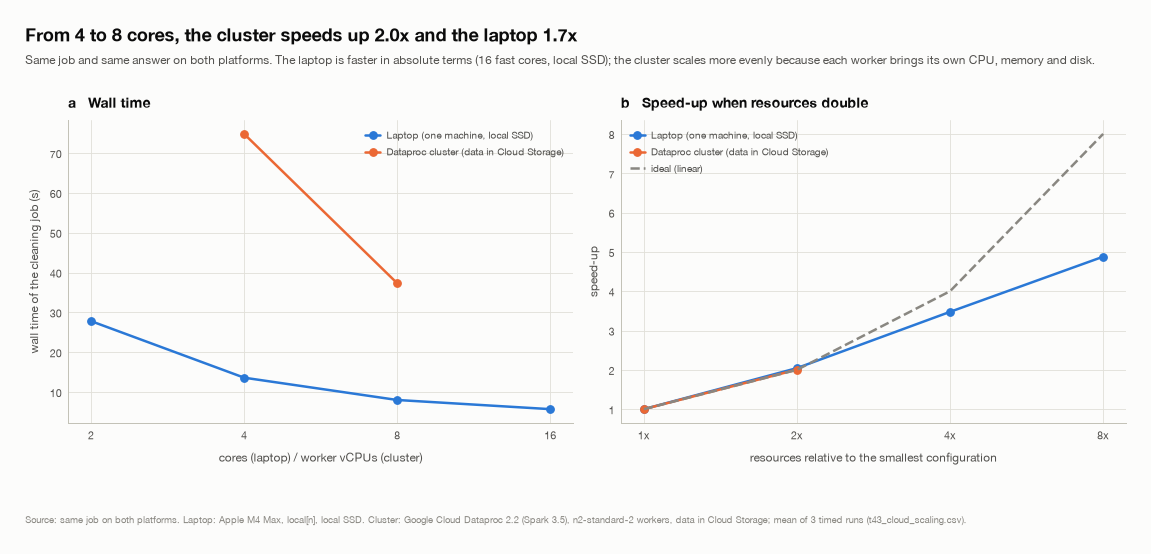

  [figure] outputs/figures/fig24_local_vs_cloud.png

-- 20b. Laptop vs Dataproc cluster -------------------------------------------------------------
   Laptop (one machine, local SSD): local[2]                           : 27.8 s   speed-up 1.00x   efficiency 100 %
   Laptop (one machine, local SSD): local[4]                           : 13.6 s   speed-up 2.04x   efficiency 102 %
   Laptop (one machine, local SSD): local[8]                           : 8.0 s   speed-up 3.48x   efficiency 87 %
   Laptop (one machine, local SSD): local[16]                          : 5.7 s   speed-up 4.88x   efficiency 61 %
   Dataproc cluster (data in Cloud Storage): 2 workers x n2-standard-2 : 74.8 s   speed-up 1.00x   efficiency 100 %
   Dataproc cluster (data in Cloud Storage): 4 workers x n2-standard-2 : 37.3 s   speed-up 2.01x   efficiency 100 %



In [83]:
# --- 20b. Laptop vs Dataproc cluster: the same job, vertical vs horizontal scaling ---------------
section("20b. Laptop (vertical scaling) vs Dataproc cluster (horizontal scaling)",
        purpose="compare the Section 20 timings with the same job on a Google Cloud Dataproc cluster",
        writes="t44_local_vs_cloud, fig24")
CLOUD_T = TABLES / "cloud" / "t43_cloud_scaling.csv"
if not CLOUD_T.exists():
    print(f"{CLOUD_T.relative_to(ROOT)} not found: run cloud/run_dataproc.sh first; skipping the comparison")
else:
    cloud = pd.read_csv(CLOUD_T)
    assert np.allclose(cloud[cloud.job.str.startswith("clean")].result, scaling.usable_station_day_mm.iloc[0], rtol=1e-9), \
        "the cluster must compute the same answer as the laptop"
    cl = (cloud[cloud.job.str.startswith("clean")].groupby(["workers", "worker_vcpus"]).seconds
          .agg(["mean", "min", "max"]).reset_index())
    local_rows = [{"platform": "Laptop (one machine, local SSD)", "config": f"local[{r.cores}]", "cores": int(r.cores),
                   "seconds": r.seconds, "range": "", "scale": r.cores / scaling.cores.iloc[0],
                   "speedup": r.speedup_vs_2_cores} for r in scaling.itertuples()]
    cloud_rows = [{"platform": "Dataproc cluster (data in Cloud Storage)", "config": f"{int(r.workers)} workers x n2-standard-2",
                   "cores": int(r.worker_vcpus), "seconds": round(r["mean"], 1), "range": f"{r['min']:.1f}-{r['max']:.1f}",
                   "scale": r.worker_vcpus / cl.worker_vcpus.iloc[0], "speedup": cl["mean"].iloc[0] / r["mean"]}
                  for _, r in cl.iterrows()]
    lvc = pd.DataFrame(local_rows + cloud_rows)
    lvc["efficiency"] = lvc.speedup / lvc.scale
    write_table(lvc, "t44_local_vs_cloud")

    _PDF = None
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
    for (plat, d), col in zip(lvc.groupby("platform", sort=False), [PALETTE[0], PALETTE[1]]):
        axes[0].plot(d.cores, d.seconds, marker="o", ms=6, lw=2, color=col, label=plat)
        axes[1].plot(d.scale, d.speedup, marker="o", ms=6, lw=2, color=col, label=plat)
    axes[0].set_xscale("log", base=2); axes[0].set_xticks(sorted(lvc.cores.unique())); axes[0].set_xticklabels(sorted(lvc.cores.unique()))
    axes[0].set_xlabel("cores (laptop) / worker vCPUs (cluster)"); axes[0].set_ylabel("wall time of the cleaning job (s)")
    axes[0].set_title("a   Wall time"); axes[0].legend(fontsize=8)
    sc_ = np.array(sorted(lvc.scale.unique()))
    axes[1].plot(sc_, sc_, ls="--", color=MUTED, label="ideal (linear)")
    axes[1].set_xscale("log", base=2); axes[1].set_xticks(sc_); axes[1].set_xticklabels([f"{x:g}x" for x in sc_])
    axes[1].set_xlabel("resources relative to the smallest configuration"); axes[1].set_ylabel("speed-up")
    axes[1].set_title("b   Speed-up when resources double"); axes[1].legend(fontsize=8)
    fig.tight_layout()
    lap = lvc[lvc.platform.str.startswith("Laptop")].set_index("cores")
    clu = lvc[lvc.platform.str.startswith("Dataproc")].set_index("cores")
    lap48, clu48 = lap.loc[4, "seconds"] / lap.loc[8, "seconds"], clu.loc[4, "seconds"] / clu.loc[8, "seconds"]
    _src_saved, SRC_T2F = SRC_T2F, ("Source: same job on both platforms. Laptop: Apple M4 Max, local[n], local SSD. Cluster: Google Cloud Dataproc "
                                    "2.2 (Spark 3.5), n2-standard-2 workers, data in Cloud Storage; mean of 3 timed runs (t43_cloud_scaling.csv).")
    headline(fig, f"From 4 to 8 cores, the cluster speeds up {clu48:.1f}x and the laptop {lap48:.1f}x",
             "Same job and same answer on both platforms. The laptop is faster in absolute terms (16 fast cores, local SSD); "
             "the cluster scales more evenly because each worker brings its own CPU, memory and disk.")
    save_figure(fig, FIGURES / "fig24_local_vs_cloud.png")
    SRC_T2F = _src_saved
    checkpoint("20b. Laptop vs Dataproc cluster", [(f"{r.platform}: {r.config}", f"{r.seconds:.1f} s   speed-up {r.speedup:.2f}x   efficiency {100 * r.efficiency:.0f} %")
                                                   for r in lvc.itertuples()])

In [84]:
# --- End of the notebook ------------------------------------------------------------------------ -----------------------------------------
cv_data.unpersist()
spark.stop()